In [ ]:
# ============================================================
# REPRODUCIBILITY SETUP — RUN FIRST
# ============================================================

import os

# Set before CUDA/PyTorch initialization
os.environ["PYTHONHASHSEED"] = "42"
os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"

import random
import numpy as np
import torch

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

# Request deterministic algorithms where supported.
# warn_only avoids stopping the notebook for unsupported operations.
torch.use_deterministic_algorithms(
    True,
    warn_only=True
)

print("Reproducibility settings applied.")
print("Seed:", SEED)
print("Device:", "CUDA" if torch.cuda.is_available() else "CPU")

Reproducibility settings applied.
Seed: 42
Device: CPU


In [ ]:
!pip list

Package                               Version
------------------------------------- -------------------
absl-py                               1.4.0
accelerate                            1.15.0
access                                1.1.10.post3
affine                                3.0.1
aiofiles                              25.1.0
aiohappyeyeballs                      2.7.1
aiohttp                               3.14.3
aiosignal                             1.4.0
aiosqlite                             0.22.1
alabaster                             1.0.0
albucore                              0.0.24
albumentations                        2.0.8
ale-py                                0.12.1
altair                                5.5.0
annotated-doc                         0.0.5
annotated-types                       0.8.0
antlr4-python3-runtime                4.9.3
anyio                                 4.15.1
anywidget                             0.9.21
apsw                                  3.53.4.

In [ ]:
# # ============================================================
# # CELL 1A — INSTALL COMPATIBLE VERSIONS
# # ============================================================

# !pip -q install --upgrade --force-reinstall \
#     "numpy==1.26.4" \
#     "scipy==1.15.3" \
#     "scikit-learn==1.7.2" \
#     "scikit-image==0.25.2" \
#     "xgboost" \
#     "gplearn" \
#     "joblib" \
#     "opencv-python"

In [ ]:
# Upgrading NumPy to a 2.x version to resolve binary incompatibilities with PyTorch/Pandas
!pip install --upgrade "numpy>=2.0.2" "pandas" "scipy" "scikit-learn"

In [ ]:
%pip install gplearn

In [ ]:
# ============================================================
# CELL 1 — IMPORTS & REPRODUCIBILITY
# ============================================================

import os
import cv2
import json
import random
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from scipy import ndimage as ndi

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import (
    VarianceThreshold,
    SelectKBest,
    mutual_info_classif
)
from sklearn.impute import SimpleImputer

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

from skimage.feature import (
    hog,
    local_binary_pattern,
    graycomatrix,
    graycoprops,
    canny
)

from skimage.measure import (
    regionprops,
    label as sk_label
)

from xgboost import XGBClassifier
from gplearn.genetic import SymbolicClassifier

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import (
    Dataset,
    DataLoader,
    WeightedRandomSampler
)

from torchvision import models, transforms

from PIL import Image

warnings.filterwarnings("ignore")

# ============================================================
# REPRODUCIBILITY
# ============================================================

SEED = 42

random.seed(SEED)
np.random.seed(SEED)

torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

# ============================================================
# VERSION CHECK
# ============================================================

print("=" * 60)
print("ENVIRONMENT CHECK")
print("=" * 60)

print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Scikit-learn:", __import__("sklearn").__version__)
print("Scikit-image:", __import__("skimage").__version__)
print("SciPy:", __import__("scipy").__version__)
print("PyTorch:", torch.__version__)

print("\nCUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print(
        "GPU:",
        torch.cuda.get_device_name(0)
    )

ENVIRONMENT CHECK
NumPy: 2.5.4
Pandas: 3.0.6
Scikit-learn: 1.9.1
Scikit-image: 0.25.2
SciPy: 1.18.1
PyTorch: 2.11.0+cpu

CUDA available: False


In [ ]:
# ============================================================
# CELL 2 — MOUNT GOOGLE DRIVE
# ============================================================

from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# ============================================================
# CELL 3 — PSG-IQ LUNG CT DATASET PATHS
# ============================================================

import os
import zipfile
import pandas as pd
import numpy as np

# ------------------------------------------------------------
# ZIP FILE STORED IN GOOGLE DRIVE
# ------------------------------------------------------------

ZIP_PATH = "/content/drive/MyDrive/PG Project work 1/PSG-IQ Lung CT Dataset.zip"

# Temporary extraction location in Colab
BASE_DIR = "/content/PSG-IQ Lung CT Dataset"


# ------------------------------------------------------------
# EXTRACT ZIP FILE
# ------------------------------------------------------------

if not os.path.exists(BASE_DIR):

    with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:
        zip_ref.extractall(BASE_DIR)

    print("Dataset extracted successfully.")

else:
    print("Dataset already extracted.")


# ------------------------------------------------------------
# AUTOMATICALLY FIND REQUIRED FOLDERS
# ------------------------------------------------------------

IQ_DIR = None
PSG_DIR = None
PSG_EXTERNAL_DIR = None

for root, dirs, files in os.walk(BASE_DIR):

    # IQ-OTH/NCCD folder
    if os.path.basename(root) == "The IQ-OTHNCCD lung cancer dataset":
        IQ_DIR = root

    # PSG IMSR dataset folder
    if os.path.basename(root) == "PSG IMSR Dataset Testing":
        PSG_DIR = root

    # External Test folder
    if os.path.basename(root) == "Test":
        # Make sure this Test folder belongs to PSG IMSR
        if PSG_DIR is not None and root.startswith(PSG_DIR):
            PSG_EXTERNAL_DIR = root


# ------------------------------------------------------------
# PATH VERIFICATION
# ------------------------------------------------------------

print("=" * 70)
print("PSG-IQ LUNG CT DATASET PATHS")
print("=" * 70)

print("ZIP File       :", ZIP_PATH)
print("Base Directory :", BASE_DIR)
print("IQ Dataset     :", IQ_DIR)
print("PSG Dataset    :", PSG_DIR)
print("External Test  :", PSG_EXTERNAL_DIR)

print("\nPath Verification")
print("-" * 70)

print("ZIP File exists       :", os.path.exists(ZIP_PATH))
print("Base Directory exists :", os.path.exists(BASE_DIR))
print("IQ Dataset exists     :", IQ_DIR is not None)
print("PSG Dataset exists    :", PSG_DIR is not None)
print("External Test exists  :", PSG_EXTERNAL_DIR is not None)

Dataset extracted successfully.
PSG-IQ LUNG CT DATASET PATHS
ZIP File       : /content/drive/MyDrive/PG Project work 1/PSG-IQ Lung CT Dataset.zip
Base Directory : /content/PSG-IQ Lung CT Dataset
IQ Dataset     : /content/PSG-IQ Lung CT Dataset/PSG-IQ Lung CT Dataset/The IQ-OTHNCCD lung cancer dataset
PSG Dataset    : /content/PSG-IQ Lung CT Dataset/PSG-IQ Lung CT Dataset/PSG IMSR Dataset Testing
External Test  : /content/PSG-IQ Lung CT Dataset/PSG-IQ Lung CT Dataset/PSG IMSR Dataset Testing/Test

Path Verification
----------------------------------------------------------------------
ZIP File exists       : True
Base Directory exists : True
IQ Dataset exists     : True
PSG Dataset exists    : True
External Test exists  : True


Normal    : 416 images
Benign    : 120 images
Malignant : 561 images

IQ-OTH/NCCD DATASET
Total IQ images: 1097


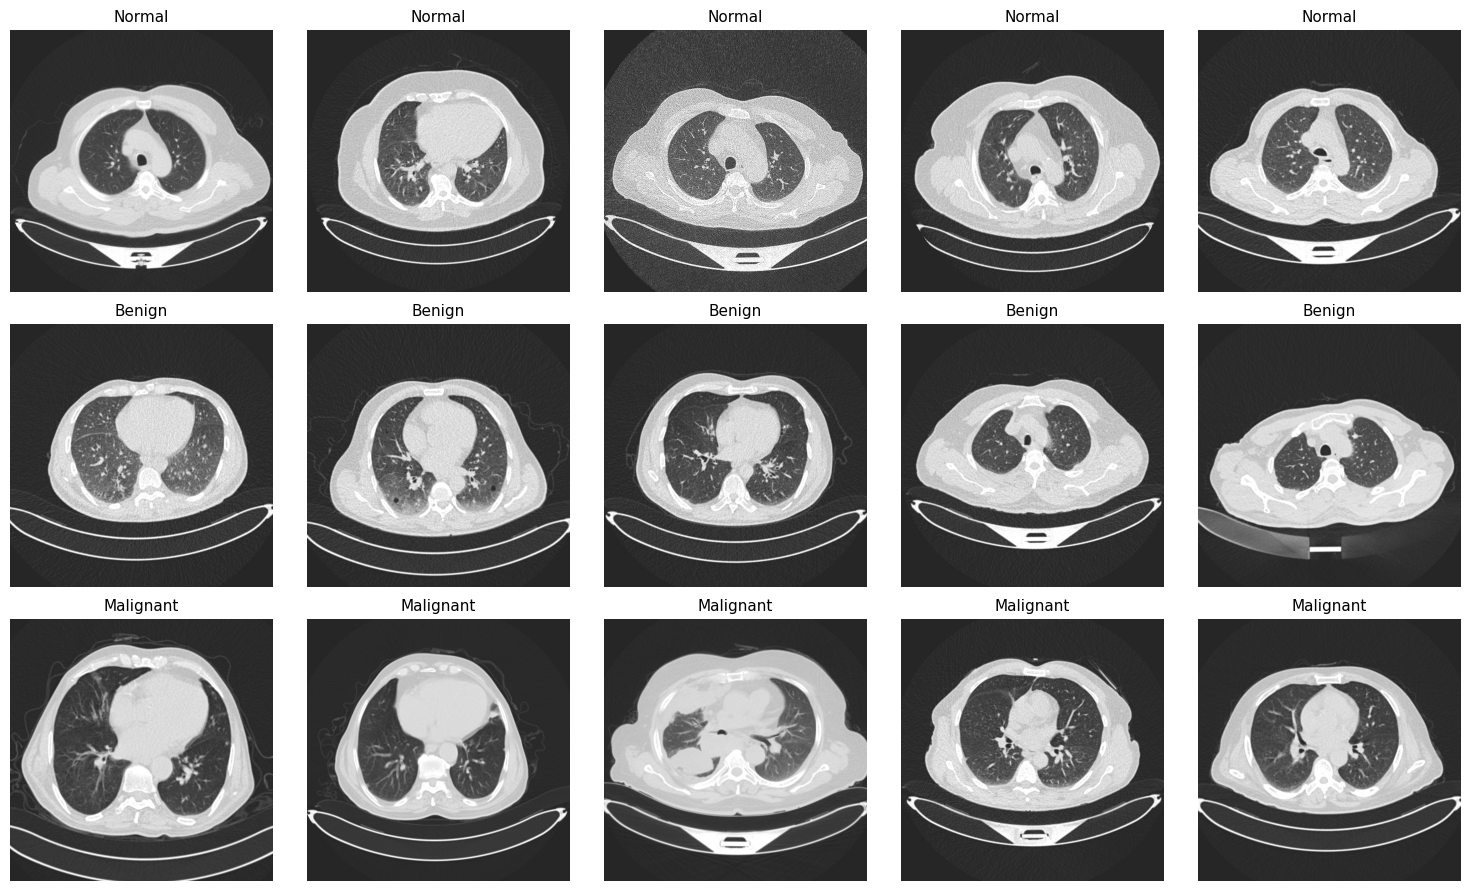

In [ ]:
# ============================================================
# CELL 4A — VIEW IQ-OTH/NCCD DATASET
# ============================================================

from pathlib import Path
import matplotlib.pyplot as plt
import random

# Define IMAGE_EXTENSIONS to prevent NameError if Cell 4 has not been run yet
IMAGE_EXTENSIONS = (
    ".png", ".jpg", ".jpeg"
    ,
    ".bmp", ".tif", ".tiff"
)

# IQ dataset folders
IQ_CLASSES = {
    "Normal": Path(IQ_DIR) / "Normal cases",
    "Benign": Path(IQ_DIR) / "Benign cases",
    "Malignant": Path(IQ_DIR) / "Malignant cases"
}

# ------------------------------------------------------------
# Collect IQ images
# ------------------------------------------------------------

iq_images = {}

for class_name, class_dir in IQ_CLASSES.items():

    images = [
        p for p in class_dir.rglob("*")
        if p.is_file()
        and p.suffix.lower() in IMAGE_EXTENSIONS
    ]

    iq_images[class_name] = images

    print(f"{class_name:10s}: {len(images)} images")


# ------------------------------------------------------------
# Display total
# ------------------------------------------------------------

total_iq = sum(len(images) for images in iq_images.values())

print("\n" + "=" * 60)
print("IQ-OTH/NCCD DATASET")
print("=" * 60)
print("Total IQ images:", total_iq)


# ------------------------------------------------------------
# Display sample images from each class
# ------------------------------------------------------------

fig, axes = plt.subplots(
    3, 5,
    figsize=(15, 9)
)

for row, class_name in enumerate(
    ["Normal", "Benign", "Malignant"]
):

    images = iq_images[class_name]

    # Select up to 5 random images
    sample_images = random.sample(
        images,
        min(5, len(images))
    )

    for col in range(5):

        ax = axes[row, col]
        ax.axis("off")

        if col < len(sample_images):

            image_path = sample_images[col]

            image = plt.imread(image_path)

            ax.imshow(
                image,
                cmap="gray"
            )

            ax.set_title(
                class_name,
                fontsize=11
            )

plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# CELL 4 — PSG-IQ LUNG CT DATASET LOADING
# ============================================================

from pathlib import Path
import pandas as pd

IMAGE_EXTENSIONS = (
    ".png", ".jpg", ".jpeg",
    ".bmp", ".tif", ".tiff"
)

CLASS_TO_LABEL = {
    "Normal": 0,
    "Benign": 1,
    "Malignant": 2
}

CLASS_NAMES = ["Normal", "Benign", "Malignant"]


# ============================================================
# HELPER FUNCTION — FIND CLASS FOLDER
# ============================================================

def find_class_folder(base_dir, possible_names):

    base_dir = Path(base_dir)

    for path in base_dir.rglob("*"):

        if path.is_dir():

            folder_name = path.name.strip().lower()

            if folder_name in [
                name.lower() for name in possible_names
            ]:
                return path

    return None


# ============================================================
# HELPER FUNCTION — COLLECT IMAGES
# ============================================================

def collect_images(folder_path, class_name, source_name):

    records = []

    if folder_path is None:
        return records

    for image_path in Path(folder_path).rglob("*"):

        if (
            image_path.is_file()
            and image_path.suffix.lower() in IMAGE_EXTENSIONS
        ):

            records.append({
                "filepath": str(image_path),
                "class": class_name,
                "label": CLASS_TO_LABEL[class_name],
                "source": source_name
            })

    return records


# ============================================================
# 1. LOAD IQ-OTH/NCCD DATASET
# ============================================================

print("=" * 70)
print("LOADING IQ-OTH/NCCD DATASET")
print("=" * 70)

iq_class_names = {
    "Normal": ["Normal cases", "Normal"],
    "Benign": ["Benign cases", "Benign"],
    "Malignant": ["Malignant cases", "Malignant cases"]
}

iq_records = []

for class_name, possible_names in iq_class_names.items():

    class_dir = find_class_folder(
        IQ_DIR,
        possible_names
    )

    print(f"\n{class_name}")

    if class_dir is None:

        print("Folder NOT found")

    else:

        print("Folder:", class_dir)

        class_records = collect_images(
            class_dir,
            class_name,
            "IQ-OTH/NCCD"
        )

        iq_records.extend(class_records)

        print(
            "Images:",
            len(class_records)
        )


iq_df = pd.DataFrame(iq_records)


# ============================================================
# 2. LOAD PSG IMSR DEVELOPMENT DATASET
# ============================================================

print("\n" + "=" * 70)
print("LOADING PSG IMSR DEVELOPMENT DATASET")
print("=" * 70)

psg_class_names = {
    "Normal": ["normal", "Normal"],
    "Benign": ["benign", "Benign"],
    "Malignant": ["maligancy", "malignant", "Malignant"]
}

psg_records = []

for class_name, possible_names in psg_class_names.items():

    class_dir = find_class_folder(
        PSG_DIR,
        possible_names
    )

    print(f"\n{class_name}")

    if class_dir is None:

        print("Folder NOT found")

    else:

        print("Folder:", class_dir)

        class_records = collect_images(
            class_dir,
            class_name,
            "PSG IMSR"
        )

        psg_records.extend(class_records)

        print(
            "Images:",
            len(class_records)
        )


psg_df = pd.DataFrame(psg_records)


# ============================================================
# 3. LOAD PSG IMSR EXTERNAL TEST DATASET
# ============================================================

print("\n" + "=" * 70)
print("LOADING PSG IMSR EXTERNAL TEST DATASET")
print("=" * 70)

external_class_names = {
    "Normal": ["Normal", "normal"],
    "Benign": ["Benign", "benign"],
    "Malignant": ["Malignant", "malignant"]
}

external_records = []

for class_name, possible_names in external_class_names.items():

    class_dir = find_class_folder(
        PSG_EXTERNAL_DIR,
        possible_names
    )

    print(f"\n{class_name}")

    if class_dir is None:

        print("Folder NOT found")

    else:

        print("Folder:", class_dir)

        class_records = collect_images(
            class_dir,
            class_name,
            "PSG IMSR External"
        )

        external_records.extend(class_records)

        print(
            "Images:",
            len(class_records)
        )


external_df = pd.DataFrame(external_records)


# ============================================================
# 4. COMBINE IQ + PSG IMSR DEVELOPMENT DATA
# ============================================================

development_df = pd.concat(
    [iq_df, psg_df],
    ignore_index=True
)

development_df = development_df.sample(
    frac=1,
    random_state=42
).reset_index(drop=True)


# ============================================================
# 5. DATASET SUMMARY
# ============================================================

print("\n" + "=" * 70)
print("PSG-IQ LUNG CT DATASET")
print("=" * 70)

print("\nIQ-OTH/NCCD images :", len(iq_df))
print("PSG IMSR images    :", len(psg_df))
print("Development total  :", len(development_df))
print("External test      :", len(external_df))


# ============================================================
# 6. IQ CLASS DISTRIBUTION
# ============================================================

print("\nIQ-OTH/NCCD Class Distribution")
print("-" * 70)

print(
    iq_df["class"]
    .value_counts()
    .reindex(CLASS_NAMES, fill_value=0)
)


# ============================================================
# 7. PSG IMSR CLASS DISTRIBUTION
# ============================================================

print("\nPSG IMSR Development Class Distribution")
print("-" * 70)

print(
    psg_df["class"]
    .value_counts()
    .reindex(CLASS_NAMES, fill_value=0)
)


# ============================================================
# 8. COMBINED DEVELOPMENT CLASS DISTRIBUTION
# ============================================================

print("\nCombined Development Class Distribution")
print("-" * 70)

print(
    development_df["class"]
    .value_counts()
    .reindex(CLASS_NAMES, fill_value=0)
)


# ============================================================
# 9. EXTERNAL TEST CLASS DISTRIBUTION
# ============================================================

print("\nExternal Test Class Distribution")
print("-" * 70)

print(
    external_df["class"]
    .value_counts()
    .reindex(CLASS_NAMES, fill_value=0)
)


# ============================================================
# 10. SOURCE DISTRIBUTION
# ============================================================

print("\nDevelopment Source Distribution")
print("-" * 70)

print(
    development_df["source"]
    .value_counts()
)


# ============================================================
# 11. FINAL VERIFICATION
# ============================================================

print("\n" + "=" * 70)
print("FINAL DATASET VERIFICATION")
print("=" * 70)

print("Expected IQ images       : 1097")
print("Expected PSG development : 53")
print("Expected development     : 1150")
print("Expected external test   : 17")

print("\nActual:")
print("IQ images                :", len(iq_df))
print("PSG development images   :", len(psg_df))
print("Development total        :", len(development_df))
print("External test            :", len(external_df))


# ============================================================
# SAFETY CHECKS
# ============================================================

assert len(iq_df) == 1097, \
    f"IQ dataset count mismatch: {len(iq_df)}"

assert len(psg_df) == 53, \
    f"PSG dataset count mismatch: {len(psg_df)}"

assert len(development_df) == 1150, \
    f"Development dataset count mismatch: {len(development_df)}"

assert len(external_df) == 17, \
    f"External test count mismatch: {len(external_df)}"

print("\n✓ IQ-OTH/NCCD: 1097 images")
print("✓ PSG IMSR development: 53 images")
print("✓ Combined development: 1150 images")
print("✓ External test: 17 images")
print("✓ External test remains separate.")

LOADING IQ-OTH/NCCD DATASET

Normal
Folder: /content/PSG-IQ Lung CT Dataset/PSG-IQ Lung CT Dataset/The IQ-OTHNCCD lung cancer dataset/Normal cases
Images: 416

Benign
Folder: /content/PSG-IQ Lung CT Dataset/PSG-IQ Lung CT Dataset/The IQ-OTHNCCD lung cancer dataset/Benign cases
Images: 120

Malignant
Folder: /content/PSG-IQ Lung CT Dataset/PSG-IQ Lung CT Dataset/The IQ-OTHNCCD lung cancer dataset/Malignant cases
Images: 561

LOADING PSG IMSR DEVELOPMENT DATASET

Normal
Folder: /content/PSG-IQ Lung CT Dataset/PSG-IQ Lung CT Dataset/PSG IMSR Dataset Testing/normal
Images: 15

Benign
Folder: /content/PSG-IQ Lung CT Dataset/PSG-IQ Lung CT Dataset/PSG IMSR Dataset Testing/benign
Images: 20

Malignant
Folder: /content/PSG-IQ Lung CT Dataset/PSG-IQ Lung CT Dataset/PSG IMSR Dataset Testing/maligancy
Images: 18

LOADING PSG IMSR EXTERNAL TEST DATASET

Normal
Folder: /content/PSG-IQ Lung CT Dataset/PSG-IQ Lung CT Dataset/PSG IMSR Dataset Testing/Test/Normal
Images: 5

Benign
Folder: /content/PSG-

In [ ]:
# ============================================================
# CELL 1 — GLOBAL REPRODUCIBILITY SETTINGS
# ============================================================

import os
import random
import numpy as np
import tensorflow as tf

# Fixed seed for the entire experiment
SEED = 42

# Python randomness
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)

# NumPy randomness
np.random.seed(SEED)

print("=" * 60)
print("GLOBAL REPRODUCIBILITY SETTINGS")
print("=" * 60)
print("SEED =", SEED)



tf.keras.utils.set_random_seed(SEED)

print("TensorFlow seed configured")

GLOBAL REPRODUCIBILITY SETTINGS
SEED = 42
TensorFlow seed configured


In [ ]:
# # ============================================================
# # CELL 5 — IQ-OTH/NCCD 70/20/10 SPLIT + PSG IMSR TEST SETS
# # ============================================================

# from sklearn.model_selection import train_test_split

# SEED = 42

# # ============================================================
# # 1. SPLIT IQ-OTH/NCCD ONLY
# # ============================================================

# iq_train_df, iq_temp_df = train_test_split(
#     iq_df,
#     test_size=0.30,
#     random_state=SEED,
#     stratify=iq_df["label"]
# )

# # 20% validation + 10% IQ internal test
# iq_val_df, iq_internal_test_df = train_test_split(
#     iq_temp_df,
#     test_size=1/3,
#     random_state=SEED,
#     stratify=iq_temp_df["label"]
# )

# # Reset indexes
# iq_train_df = iq_train_df.reset_index(drop=True)
# iq_val_df = iq_val_df.reset_index(drop=True)
# iq_internal_test_df = iq_internal_test_df.reset_index(drop=True)

# # ============================================================
# # 2. PSG IMSR 53 IMAGES — CLINICAL TEST ONLY
# # ============================================================

# psg_test_df = psg_df.copy().reset_index(drop=True)

# # ============================================================
# # 3. PSG IMSR 17 IMAGES — EXTERNAL TEST ONLY
# # ============================================================

# psg_external_test_df = external_df.copy().reset_index(drop=True)

# # ============================================================
# # 4. CREATE COMBINED INTERNAL/CLINICAL TEST SET
# # ============================================================

# clinical_test_df = pd.concat(
#     [
#         iq_internal_test_df,
#         psg_test_df
#     ],
#     ignore_index=True
# ).sample(
#     frac=1,
#     random_state=SEED
# ).reset_index(drop=True)

# # ============================================================
# # 5. DISPLAY DATASET SIZES
# # ============================================================

# print("=" * 75)
# print("PSG-IQ LUNG CT DATASET — FINAL SPLIT")
# print("=" * 75)

# print("\nIQ-OTH/NCCD")
# print("-" * 75)
# print("Training       :", len(iq_train_df))
# print("Validation     :", len(iq_val_df))
# print("Internal Test  :", len(iq_internal_test_df))

# print("\nPSG IMSR")
# print("-" * 75)
# print("Clinical Test  :", len(psg_test_df))
# print("External Test  :", len(psg_external_test_df))

# print("\nCombined Clinical/Internal Test")
# print("-" * 75)
# print("IQ Internal + PSG IMSR :", len(clinical_test_df))

# # ============================================================
# # 6. CLASS DISTRIBUTION
# # ============================================================

# print("\nIQ TRAINING CLASS DISTRIBUTION")
# print(iq_train_df["class"].value_counts().reindex(
#     CLASS_NAMES, fill_value=0
# ))

# print("\nIQ VALIDATION CLASS DISTRIBUTION")
# print(iq_val_df["class"].value_counts().reindex(
#     CLASS_NAMES, fill_value=0
# ))

# print("\nIQ INTERNAL TEST CLASS DISTRIBUTION")
# print(iq_internal_test_df["class"].value_counts().reindex(
#     CLASS_NAMES, fill_value=0
# ))

# print("\nPSG IMSR CLINICAL TEST CLASS DISTRIBUTION")
# print(psg_test_df["class"].value_counts().reindex(
#     CLASS_NAMES, fill_value=0
# ))

# print("\nPSG IMSR EXTERNAL TEST CLASS DISTRIBUTION")
# print(psg_external_test_df["class"].value_counts().reindex(
#     CLASS_NAMES, fill_value=0
# ))

# print("\nCOMBINED CLINICAL/INTERNAL TEST DISTRIBUTION")
# print(clinical_test_df["class"].value_counts().reindex(
#     CLASS_NAMES, fill_value=0
# ))

In [ ]:

# ============================================================
# CELL 5 — FIXED DATASET SPLIT + PSG IMSR TEST SETS
# ============================================================

import os
import pandas as pd
from sklearn.model_selection import train_test_split

SEED = 42
SPLIT_DIR = "/content/lung_ct_split_manifests"
os.makedirs(SPLIT_DIR, exist_ok=True)

train_file = os.path.join(SPLIT_DIR, "iq_train.csv")
val_file = os.path.join(SPLIT_DIR, "iq_val.csv")
test_file = os.path.join(SPLIT_DIR, "iq_internal_test.csv")

# ============================================================
# 1. LOAD EXISTING FIXED SPLIT OR CREATE IT ONCE
# ============================================================

if all(os.path.exists(p) for p in [train_file, val_file, test_file]):

    print("Loading previously saved fixed split manifests...")

    iq_train_df = pd.read_csv(train_file)
    iq_val_df = pd.read_csv(val_file)
    iq_internal_test_df = pd.read_csv(test_file)

    # Ensure the saved paths still exist in the current dataset.
    current_paths = set(iq_df["filepath"].astype(str))

    for name, df in [
        ("Training", iq_train_df),
        ("Validation", iq_val_df),
        ("Internal test", iq_internal_test_df)
    ]:
        missing = set(df["filepath"].astype(str)) - current_paths
        if missing:
            raise ValueError(
                f"{name} manifest contains {len(missing)} "
                "filepaths missing from iq_df. Check dataset paths."
            )

else:
    print("Creating the split for the first time...")

    # Stratified 70% training and 30% temporary set
    iq_train_df, iq_temp_df = train_test_split(
        iq_df,
        test_size=0.30,
        random_state=SEED,
        stratify=iq_df["label"]
    )

    # Split temporary set into 20% validation and 10% internal test
    iq_val_df, iq_internal_test_df = train_test_split(
        iq_temp_df,
        test_size=1/3,
        random_state=SEED,
        stratify=iq_temp_df["label"]
    )

    iq_train_df = iq_train_df.reset_index(drop=True)
    iq_val_df = iq_val_df.reset_index(drop=True)
    iq_internal_test_df = iq_internal_test_df.reset_index(drop=True)

    # Save exact file lists and associated metadata.
    iq_train_df.to_csv(train_file, index=False)
    iq_val_df.to_csv(val_file, index=False)
    iq_internal_test_df.to_csv(test_file, index=False)

    print("Fixed split manifests saved.")

# ============================================================
# 2. RESET INDEXES
# ============================================================

iq_train_df = iq_train_df.reset_index(drop=True)
iq_val_df = iq_val_df.reset_index(drop=True)
iq_internal_test_df = iq_internal_test_df.reset_index(drop=True)

# ============================================================
# 3. PSG IMSR TEST SETS — KEEP SEPARATE
# ============================================================

psg_test_df = psg_df.copy().reset_index(drop=True)
psg_external_test_df = external_df.copy().reset_index(drop=True)

# ============================================================
# 4. COMBINED INTERNAL + CLINICAL TEST SET
# ============================================================

clinical_test_df = pd.concat(
    [iq_internal_test_df, psg_test_df],
    ignore_index=True
).sample(frac=1, random_state=SEED).reset_index(drop=True)

# ============================================================
# 5. CHECK FOR FILEPATH OVERLAP
# ============================================================

train_paths = set(iq_train_df["filepath"].astype(str))
val_paths = set(iq_val_df["filepath"].astype(str))
test_paths = set(iq_internal_test_df["filepath"].astype(str))

assert train_paths.isdisjoint(val_paths), \
    "Overlap found between training and validation!"

assert train_paths.isdisjoint(test_paths), \
    "Overlap found between training and internal test!"

assert val_paths.isdisjoint(test_paths), \
    "Overlap found between validation and internal test!"

print("\nNo exact filepath overlap among IQ train, validation, and internal test.")

# ============================================================
# 6. DISPLAY DATASET SIZES
# ============================================================

print("\n" + "=" * 65)
print("PSG-IQ LUNG CT DATASET — FIXED SPLIT")
print("=" * 65)

print("\nIQ-OTH/NCCD")
print("Training      :", len(iq_train_df))
print("Validation    :", len(iq_val_df))
print("Internal Test :", len(iq_internal_test_df))

print("\nPSG IMSR")
print("Clinical Test :", len(psg_test_df))
print("External Test :", len(psg_external_test_df))

print("\nCombined IQ Internal + PSG Clinical Test:",
      len(clinical_test_df))

# ============================================================
# 7. CLASS DISTRIBUTIONS
# ============================================================

for name, df in [
    ("IQ TRAINING", iq_train_df),
    ("IQ VALIDATION", iq_val_df),
    ("IQ INTERNAL TEST", iq_internal_test_df),
    ("PSG IMSR CLINICAL TEST", psg_test_df),
    ("PSG IMSR EXTERNAL TEST", psg_external_test_df),
    ("COMBINED CLINICAL/INTERNAL TEST", clinical_test_df)
]:
    print(f"\n{name} CLASS DISTRIBUTION")
    print(df["class"].value_counts().reindex(
        CLASS_NAMES, fill_value=0
    ))

print("\nCELL 5 COMPLETED — FIXED SPLIT LOADED/CREATED.")


Creating the split for the first time...
Fixed split manifests saved.

No exact filepath overlap among IQ train, validation, and internal test.

PSG-IQ LUNG CT DATASET — FIXED SPLIT

IQ-OTH/NCCD
Training      : 767
Validation    : 220
Internal Test : 110

PSG IMSR
Clinical Test : 53
External Test : 17

Combined IQ Internal + PSG Clinical Test: 163

IQ TRAINING CLASS DISTRIBUTION
class
Normal       291
Benign        84
Malignant    392
Name: count, dtype: int64

IQ VALIDATION CLASS DISTRIBUTION
class
Normal        83
Benign        24
Malignant    113
Name: count, dtype: int64

IQ INTERNAL TEST CLASS DISTRIBUTION
class
Normal       42
Benign       12
Malignant    56
Name: count, dtype: int64

PSG IMSR CLINICAL TEST CLASS DISTRIBUTION
class
Normal       15
Benign       20
Malignant    18
Name: count, dtype: int64

PSG IMSR EXTERNAL TEST CLASS DISTRIBUTION
class
Normal       5
Benign       7
Malignant    5
Name: count, dtype: int64

COMBINED CLINICAL/INTERNAL TEST CLASS DISTRIBUTION
class


In [ ]:
# ============================================================
# CELL 6 — VERIFY AND PREPARE FINAL DATASET SPLITS
# ============================================================

CLASS_NAMES = ["Normal", "Benign", "Malignant"]

# ============================================================
# 1. DATASET SIZE VERIFICATION
# ============================================================

print("=" * 75)
print("PSG-IQ LUNG CT DATASET — FINAL SPLIT VERIFICATION")
print("=" * 75)

print("\nIQ-OTH/NCCD")
print("-" * 75)

print("Training Images       :", len(iq_train_df))
print("Validation Images     :", len(iq_val_df))
print("IQ Internal Test      :", len(iq_internal_test_df))

print("\nPSG IMSR")
print("-" * 75)

print("Clinical Test Images  :", len(psg_test_df))
print("External Test Images  :", len(psg_external_test_df))

print("\nCombined Clinical/Internal Test")
print("-" * 75)

print("IQ Internal + PSG IMSR :", len(clinical_test_df))


# ============================================================
# 2. CLASS DISTRIBUTION
# ============================================================

print("\n" + "=" * 75)
print("CLASS DISTRIBUTION")
print("=" * 75)

print("\nIQ TRAINING")
print(
    iq_train_df["class"]
    .value_counts()
    .reindex(CLASS_NAMES, fill_value=0)
)

print("\nIQ VALIDATION")
print(
    iq_val_df["class"]
    .value_counts()
    .reindex(CLASS_NAMES, fill_value=0)
)

print("\nIQ INTERNAL TEST")
print(
    iq_internal_test_df["class"]
    .value_counts()
    .reindex(CLASS_NAMES, fill_value=0)
)

print("\nPSG IMSR CLINICAL TEST")
print(
    psg_test_df["class"]
    .value_counts()
    .reindex(CLASS_NAMES, fill_value=0)
)

print("\nCOMBINED CLINICAL/INTERNAL TEST")
print(
    clinical_test_df["class"]
    .value_counts()
    .reindex(CLASS_NAMES, fill_value=0)
)

print("\nPSG IMSR EXTERNAL TEST")
print(
    psg_external_test_df["class"]
    .value_counts()
    .reindex(CLASS_NAMES, fill_value=0)
)


# ============================================================
# 3. VERIFY IQ DEVELOPMENT SPLIT
# ============================================================

iq_total = (
    len(iq_train_df)
    + len(iq_val_df)
    + len(iq_internal_test_df)
)

print("\n" + "=" * 75)
print("IQ DATASET SPLIT VERIFICATION")
print("=" * 75)

print("IQ Total              :", len(iq_df))
print("Training + Validation + Internal Test :", iq_total)

assert iq_total == len(iq_df)

print("✓ All IQ images are accounted for.")


# ============================================================
# 4. VERIFY PSG IMSR DATA
# ============================================================

psg_total = (
    len(psg_test_df)
    + len(psg_external_test_df)
)

print("\n" + "=" * 75)
print("PSG IMSR TEST VERIFICATION")
print("=" * 75)

print("PSG IMSR Total        :", len(psg_df) + len(external_df))
print("PSG Clinical Test     :", len(psg_test_df))
print("PSG External Test     :", len(psg_external_test_df))
print("Total PSG Test Images :", psg_total)

assert psg_total == len(psg_df) + len(external_df)

print("✓ All PSG IMSR images are reserved for testing.")


# ============================================================
# 5. VERIFY NO PSG IMSR IMAGE ENTERS TRAINING/VALIDATION
# ============================================================

train_paths = set(iq_train_df["filepath"])
val_paths = set(iq_val_df["filepath"])

psg_clinical_paths = set(psg_test_df["filepath"])
psg_external_paths = set(psg_external_test_df["filepath"])

assert train_paths.isdisjoint(psg_clinical_paths)
assert train_paths.isdisjoint(psg_external_paths)

assert val_paths.isdisjoint(psg_clinical_paths)
assert val_paths.isdisjoint(psg_external_paths)


# ============================================================
# 6. FINAL VERIFICATION
# ============================================================

print("\n" + "=" * 75)
print("FINAL DATASET VERIFICATION")
print("=" * 75)

print("✓ IQ-OTH/NCCD used for Training and Validation.")
print("✓ IQ Internal Test kept separate from Training and Validation.")
print("✓ 53 PSG IMSR clinical images reserved for testing.")
print("✓ 17 PSG IMSR external images reserved for final external testing.")
print("✓ No PSG IMSR image is used for Training or Validation.")

PSG-IQ LUNG CT DATASET — FINAL SPLIT VERIFICATION

IQ-OTH/NCCD
---------------------------------------------------------------------------
Training Images       : 767
Validation Images     : 220
IQ Internal Test      : 110

PSG IMSR
---------------------------------------------------------------------------
Clinical Test Images  : 53
External Test Images  : 17

Combined Clinical/Internal Test
---------------------------------------------------------------------------
IQ Internal + PSG IMSR : 163

CLASS DISTRIBUTION

IQ TRAINING
class
Normal       291
Benign        84
Malignant    392
Name: count, dtype: int64

IQ VALIDATION
class
Normal        83
Benign        24
Malignant    113
Name: count, dtype: int64

IQ INTERNAL TEST
class
Normal       42
Benign       12
Malignant    56
Name: count, dtype: int64

PSG IMSR CLINICAL TEST
class
Normal       15
Benign       20
Malignant    18
Name: count, dtype: int64

COMBINED CLINICAL/INTERNAL TEST
class
Normal       57
Benign       32
Malignant   

# **Preprocessing**

In [ ]:
# ============================================================
# CELL 7 — IMAGE QUALITY CHECK
# ============================================================

def check_image_quality(image_path):

    img = cv2.imread(str(image_path), cv2.IMREAD_GRAYSCALE)

    if img is None:
        return {
            "valid": False,
            "height": 0,
            "width": 0,
            "mean": np.nan,
            "std": np.nan,
            "min": np.nan,
            "max": np.nan
        }

    return {
        "valid": True,
        "height": img.shape[0],
        "width": img.shape[1],
        "mean": float(np.mean(img)),
        "std": float(np.std(img)),
        "min": int(np.min(img)),
        "max": int(np.max(img))
    }


# ============================================================
# COMBINE DATASETS FOR QUALITY CHECK ONLY
# ============================================================

quality_input_df = pd.concat(
    [
        iq_df.assign(dataset="IQ-OTH/NCCD"),
        psg_df.assign(dataset="PSG IMSR - Clinical Test"),
        external_df.assign(dataset="PSG IMSR - External Test")
    ],
    ignore_index=True
)


# ============================================================
# CHECK IMAGE QUALITY
# ============================================================

quality_records = []

for _, row in quality_input_df.iterrows():

    result = check_image_quality(row["filepath"])

    quality_records.append({
        "filepath": row["filepath"],
        "class": row["class"],
        "dataset": row["dataset"],
        **result
    })

quality_df = pd.DataFrame(quality_records)


# ============================================================
# QUALITY SUMMARY
# ============================================================

print("=" * 60)
print("IMAGE QUALITY CHECK")
print("=" * 60)

print("Total images checked :", len(quality_df))
print("Unreadable images    :", (~quality_df["valid"]).sum())

print("\nDataset-wise image count:")
print(quality_df["dataset"].value_counts())


print("\nImage dimensions:")

valid_quality_df = quality_df[quality_df["valid"]]

print(
    "Height:",
    valid_quality_df["height"].min(),
    "to",
    valid_quality_df["height"].max()
)

print(
    "Width :",
    valid_quality_df["width"].min(),
    "to",
    valid_quality_df["width"].max()
)


print("\nIntensity statistics:")

print(
    "Mean intensity:",
    f"{valid_quality_df['mean'].mean():.2f}"
)

print(
    "Average standard deviation:",
    f"{valid_quality_df['std'].mean():.2f}"
)


# ============================================================
# FLAG POTENTIALLY PROBLEMATIC IMAGES
# ============================================================

low_contrast = valid_quality_df[
    valid_quality_df["std"] < 10
]

very_small = valid_quality_df[
    (valid_quality_df["height"] < 100) |
    (valid_quality_df["width"] < 100)
]


# ============================================================
# QUALITY FLAGS
# ============================================================

print("\n" + "=" * 60)
print("QUALITY FLAGS")
print("=" * 60)

print(
    "Low-contrast images (std < 10):",
    len(low_contrast)
)

print(
    "Very small images (<100 px):",
    len(very_small)
)


# ============================================================
# DISPLAY FLAGS
# ============================================================

if len(low_contrast) > 0:

    print("\nLow-contrast images:")

    display(
        low_contrast[
            [
                "filepath",
                "class",
                "dataset",
                "height",
                "width",
                "mean",
                "std"
            ]
        ]
    )


if len(very_small) > 0:

    print("\nVery small images:")

    display(
        very_small[
            [
                "filepath",
                "class",
                "dataset",
                "height",
                "width"
            ]
        ]
    )


print("\n✓ Image quality checking completed.")

IMAGE QUALITY CHECK
Total images checked : 1167
Unreadable images    : 0

Dataset-wise image count:
dataset
IQ-OTH/NCCD                 1097
PSG IMSR - Clinical Test      53
PSG IMSR - External Test      17
Name: count, dtype: int64

Image dimensions:
Height: 331 to 512
Width : 436 to 801

Intensity statistics:
Mean intensity: 104.98
Average standard deviation: 76.52

QUALITY FLAGS
Low-contrast images (std < 10): 0
Very small images (<100 px): 0

✓ Image quality checking completed.


## **Lung Segmentation**

In [ ]:
# ============================================================
# CELL 8 — IMPROVED LUNG-FIELD SEGMENTATION
# ============================================================

import cv2
import numpy as np
from pathlib import Path
from scipy import ndimage as ndi


def segment_lung(image_input):

    # --------------------------------------------------------
    # 1. READ IMAGE
    # --------------------------------------------------------
    if isinstance(image_input, (str, Path)):

        original = cv2.imread(
            str(image_input),
            cv2.IMREAD_GRAYSCALE
        )

    else:

        original = np.asarray(image_input).copy()

        if original.ndim == 3:

            if original.shape[-1] == 4:
                original = cv2.cvtColor(
                    original,
                    cv2.COLOR_RGBA2GRAY
                )
            else:
                original = cv2.cvtColor(
                    original,
                    cv2.COLOR_BGR2GRAY
                )

    if original is None:
        raise ValueError(
            f"Unable to read image: {image_input}"
        )

    if original.ndim != 2:
        raise ValueError(
            "Expected a grayscale CT image."
        )

    h, w = original.shape

    if h < 32 or w < 32:
        raise ValueError(
            "Image is too small for lung segmentation."
        )

    # --------------------------------------------------------
    # 2. SMOOTH IMAGE
    # --------------------------------------------------------
    blurred = cv2.GaussianBlur(
        original,
        (5, 5),
        0
    )

    # --------------------------------------------------------
    # 3. DEFINE THORACIC SEARCH REGION
    # --------------------------------------------------------
    x1 = int(0.06 * w)
    x2 = int(0.94 * w)

    y1 = int(0.05 * h)
    y2 = int(0.82 * h)

    thorax_region = np.zeros(
        (h, w),
        dtype=np.uint8
    )

    thorax_region[y1:y2, x1:x2] = 255

    # --------------------------------------------------------
    # 4. ESTIMATE THE BODY REGION
    #    Bright body tissue is separated from the black
    #    external background.
    # --------------------------------------------------------
    _, body_binary = cv2.threshold(
        blurred,
        0,
        255,
        cv2.THRESH_BINARY + cv2.THRESH_OTSU
    )

    body_binary = cv2.bitwise_and(
        body_binary,
        thorax_region
    )

    body_kernel = cv2.getStructuringElement(
        cv2.MORPH_ELLIPSE,
        (11, 11)
    )

    body_binary = cv2.morphologyEx(
        body_binary,
        cv2.MORPH_CLOSE,
        body_kernel,
        iterations=2
    )

    # Keep the largest connected body component.
    n_body, body_labels, body_stats, _ = (
        cv2.connectedComponentsWithStats(
            body_binary,
            connectivity=8
        )
    )

    body_mask = np.zeros(
        (h, w),
        dtype=np.uint8
    )

    if n_body > 1:

        body_areas = body_stats[
            1:, cv2.CC_STAT_AREA
        ]

        largest_body_label = (
            1 + int(np.argmax(body_areas))
        )

        body_mask[
            body_labels == largest_body_label
        ] = 255

        # Fill holes in the body outline to include
        # the internal thoracic region.
        body_mask = (
            ndi.binary_fill_holes(
                body_mask > 0
            ).astype(np.uint8) * 255
        )

    # Fallback if body estimation is unsuccessful.
    if np.count_nonzero(body_mask) < 0.02 * h * w:
        body_mask = thorax_region.copy()

    # --------------------------------------------------------
    # 5. OTSU THRESHOLD WITHIN THE BODY REGION
    # --------------------------------------------------------
    body_pixels = blurred[body_mask > 0]

    if body_pixels.size == 0:
        raise ValueError(
            "Could not estimate the thoracic region."
        )

    otsu_value, _ = cv2.threshold(
        body_pixels.reshape(-1, 1),
        0,
        255,
        cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
    )

    # Show the threshold result for debugging.
    threshold = np.zeros(
        (h, w),
        dtype=np.uint8
    )

    threshold[
        (blurred <= otsu_value) &
        (body_mask > 0)
    ] = 255

    # --------------------------------------------------------
    # 6. REMOVE THE CENTRAL MEDIASTINAL REGION
    # --------------------------------------------------------
    center_x = w // 2
    center_gap = int(0.035 * w)

    lung_candidates = threshold.copy()

    lung_candidates[
        :,
        max(0, center_x - center_gap):
        min(w, center_x + center_gap)
    ] = 0

    # --------------------------------------------------------
    # 7. JOIN NEARBY LUNG REGIONS
    # --------------------------------------------------------
    lung_kernel = cv2.getStructuringElement(
        cv2.MORPH_ELLIPSE,
        (9, 9)
    )

    lung_candidates = cv2.morphologyEx(
        lung_candidates,
        cv2.MORPH_CLOSE,
        lung_kernel,
        iterations=2
    )

    lung_candidates = cv2.morphologyEx(
        lung_candidates,
        cv2.MORPH_OPEN,
        cv2.getStructuringElement(
            cv2.MORPH_ELLIPSE,
            (3, 3)
        ),
        iterations=1
    )

    # --------------------------------------------------------
    # 8. SELECT THE LARGEST CANDIDATE ON EACH SIDE
    # --------------------------------------------------------
    lung_mask = np.zeros(
        (h, w),
        dtype=np.uint8
    )

    for side_start, side_end in [
        (x1, center_x - center_gap),
        (center_x + center_gap, x2)
    ]:

        side = np.zeros_like(
            lung_candidates
        )

        side[:, side_start:side_end] = (
            lung_candidates[:, side_start:side_end]
        )

        n_labels, labels, stats, centroids = (
            cv2.connectedComponentsWithStats(
                side,
                connectivity=8
            )
        )

        candidates = []

        for label_id in range(1, n_labels):

            area = stats[
                label_id,
                cv2.CC_STAT_AREA
            ]

            if area < 0.003 * h * w:
                continue

            cx, cy = centroids[label_id]

            # Reject components near the image edges.
            if cx < 0.07 * w or cx > 0.93 * w:
                continue

            if cy < 0.08 * h or cy > 0.80 * h:
                continue

            candidates.append(
                (area, label_id)
            )

        # Select the largest valid component on this side.
        if candidates:

            _, best_label = max(
                candidates,
                key=lambda item: item[0]
            )

            lung_mask[
                labels == best_label
            ] = 255

    # --------------------------------------------------------
    # 9. REFINE MASK AND FILL INTERNAL HOLES
    # --------------------------------------------------------
    if np.count_nonzero(lung_mask) > 0:

        lung_mask = cv2.morphologyEx(
            lung_mask,
            cv2.MORPH_CLOSE,
            lung_kernel,
            iterations=1
        )

        lung_mask = (
            ndi.binary_fill_holes(
                lung_mask > 0
            ).astype(np.uint8) * 255
        )

        # Keep the mask within the thoracic search area.
        lung_mask = cv2.bitwise_and(
            lung_mask,
            thorax_region
        )

    # --------------------------------------------------------
    # 10. CREATE SEGMENTED LUNG ROI
    # --------------------------------------------------------
    segmented_roi = cv2.bitwise_and(
        original,
        original,
        mask=lung_mask
    )

    # --------------------------------------------------------
    # 11. RETURN SAME FOUR OUTPUTS AS BEFORE
    # --------------------------------------------------------
    return (
        original,
        threshold,
        lung_mask,
        segmented_roi
    )

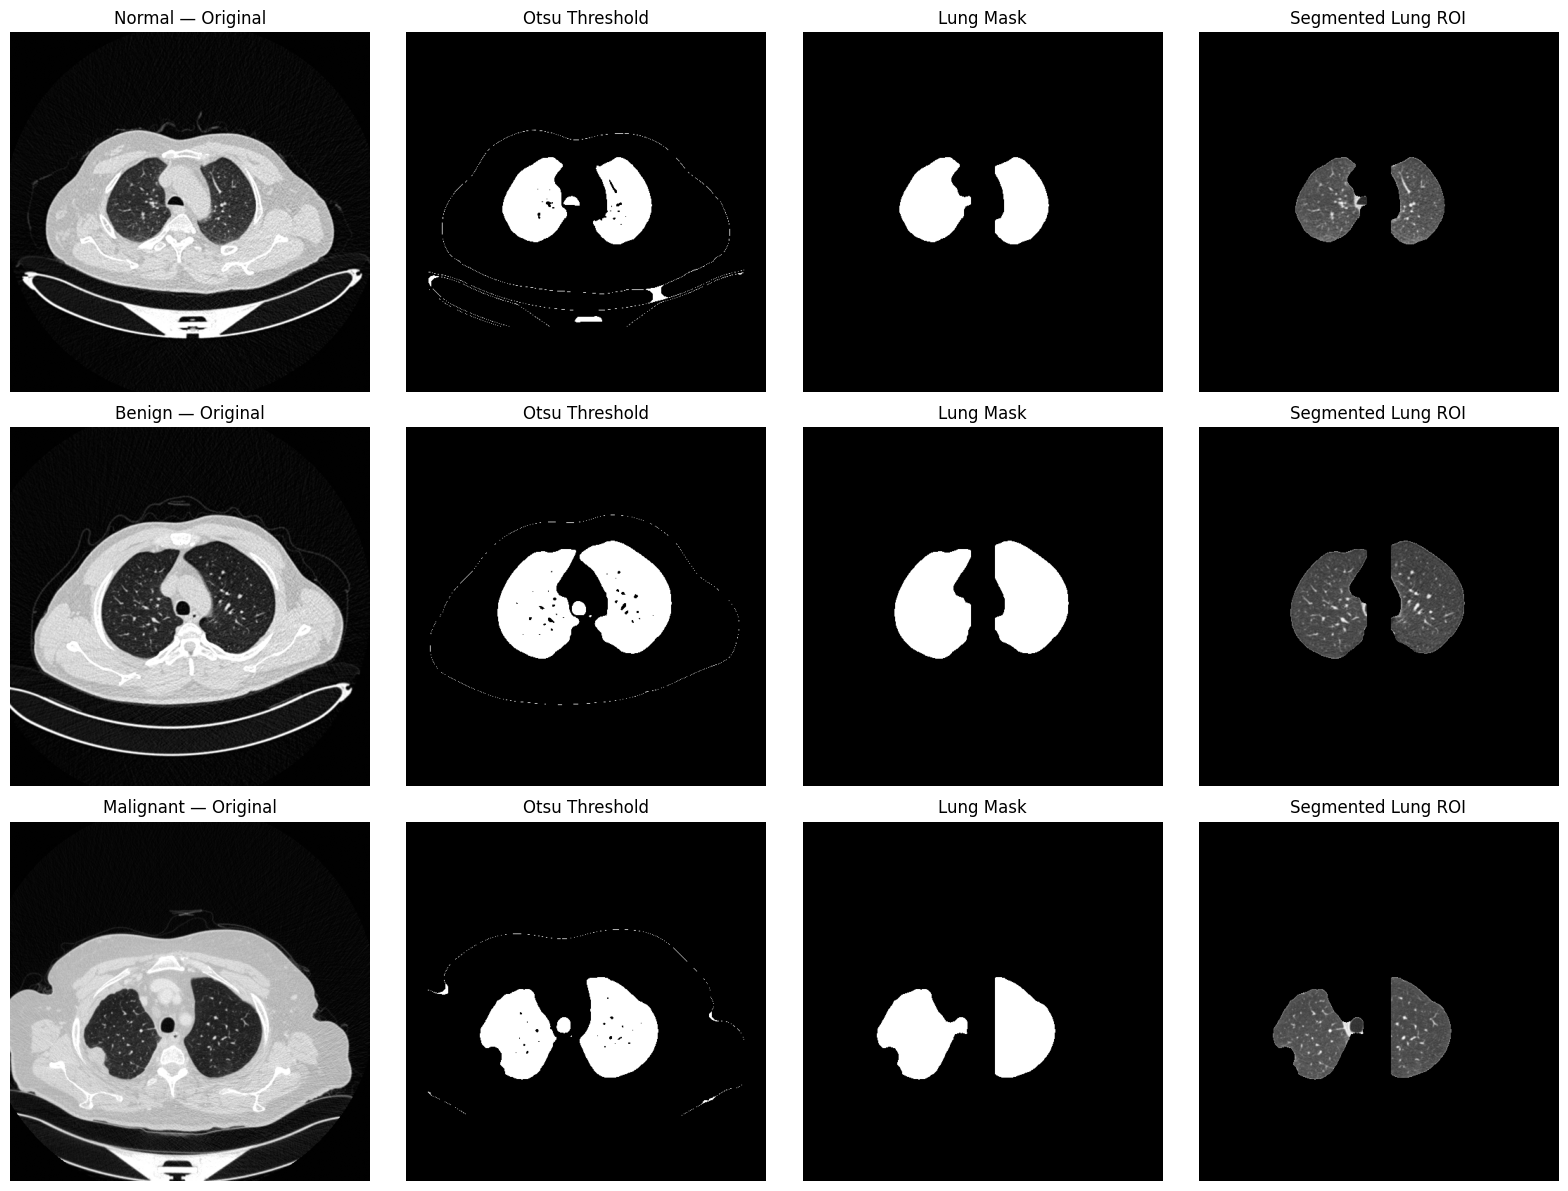

In [ ]:
# ============================================================
# CELL 8B — VISUALIZE FINAL LUNG SEGMENTATION
# ============================================================

sample_paths = []

for class_name in CLASS_NAMES:

    class_samples = iq_train_df[
        iq_train_df["class"] == class_name
    ]

    if len(class_samples) == 0:
        continue

    sample = class_samples.iloc[0]["filepath"]

    sample_paths.append(
        (class_name, sample)
    )


# ============================================================
# CREATE FIGURE
# ============================================================

fig, axes = plt.subplots(
    len(sample_paths),
    4,
    figsize=(16, 12)
)

if len(sample_paths) == 1:
    axes = np.expand_dims(
        axes,
        axis=0
    )


for row, (class_name, image_path) in enumerate(sample_paths):

    original, threshold, lung_mask, segmented_roi = (
        segment_lung(image_path)
    )


    # --------------------------------------------------------
    # ORIGINAL
    # --------------------------------------------------------

    axes[row, 0].imshow(
        original,
        cmap="gray"
    )

    axes[row, 0].set_title(
        f"{class_name} — Original"
    )


    # --------------------------------------------------------
    # OTSU THRESHOLD
    # --------------------------------------------------------

    axes[row, 1].imshow(
        threshold,
        cmap="gray"
    )

    axes[row, 1].set_title(
        "Otsu Threshold"
    )


    # --------------------------------------------------------
    # LUNG MASK
    # --------------------------------------------------------

    axes[row, 2].imshow(
        lung_mask,
        cmap="gray"
    )

    axes[row, 2].set_title(
        "Lung Mask"
    )


    # --------------------------------------------------------
    # SEGMENTED ROI
    # --------------------------------------------------------

    axes[row, 3].imshow(
        segmented_roi,
        cmap="gray"
    )

    axes[row, 3].set_title(
        "Segmented Lung ROI"
    )


    for col in range(4):
        axes[row, col].axis("off")


plt.tight_layout()
plt.show()

# **Preprocessing**

In [ ]:
# ============================================================
# CELL 9 — CT IMAGE PREPROCESSING
# ============================================================

def preprocess_image(
    image_input,
    target_size=(224, 224)
):
    """
    Complete preprocessing pipeline.

    1. Lung-field segmentation
    2. Resize
    3. Median filtering
    4. CLAHE contrast enhancement
    5. Apply lung mask
    6. Normalize to [0, 1]
    """

    # --------------------------------------------------------
    # 1. Lung-field segmentation
    # --------------------------------------------------------
    original, threshold, lung_mask, segmented_roi = (
        segment_lung(image_input)
    )

    # --------------------------------------------------------
    # 2. Resize image and mask
    # --------------------------------------------------------
    resized_roi = cv2.resize(
        segmented_roi,
        target_size,
        interpolation=cv2.INTER_AREA
    )

    resized_mask = cv2.resize(
        lung_mask,
        target_size,
        interpolation=cv2.INTER_NEAREST
    )

    # --------------------------------------------------------
    # 3. Median filtering
    # --------------------------------------------------------
    denoised = cv2.medianBlur(
        resized_roi,
        3
    )

    # --------------------------------------------------------
    # 4. CLAHE
    # --------------------------------------------------------
    clahe = cv2.createCLAHE(
        clipLimit=2.0,
        tileGridSize=(8, 8)
    )

    enhanced = clahe.apply(
        denoised
    )

    # --------------------------------------------------------
    # 5. Apply lung mask
    # --------------------------------------------------------
    enhanced[
        resized_mask == 0
    ] = 0

    # --------------------------------------------------------
    # 6. Normalize to [0, 1]
    # --------------------------------------------------------
    normalized = (
        enhanced.astype(np.float32) / 255.0
    )

    return {
        "original": original,
        "segmented_roi": segmented_roi,
        "resized": resized_roi,
        "denoised": denoised,
        "enhanced": enhanced,
        "mask": resized_mask,
        "normalized": normalized
    }

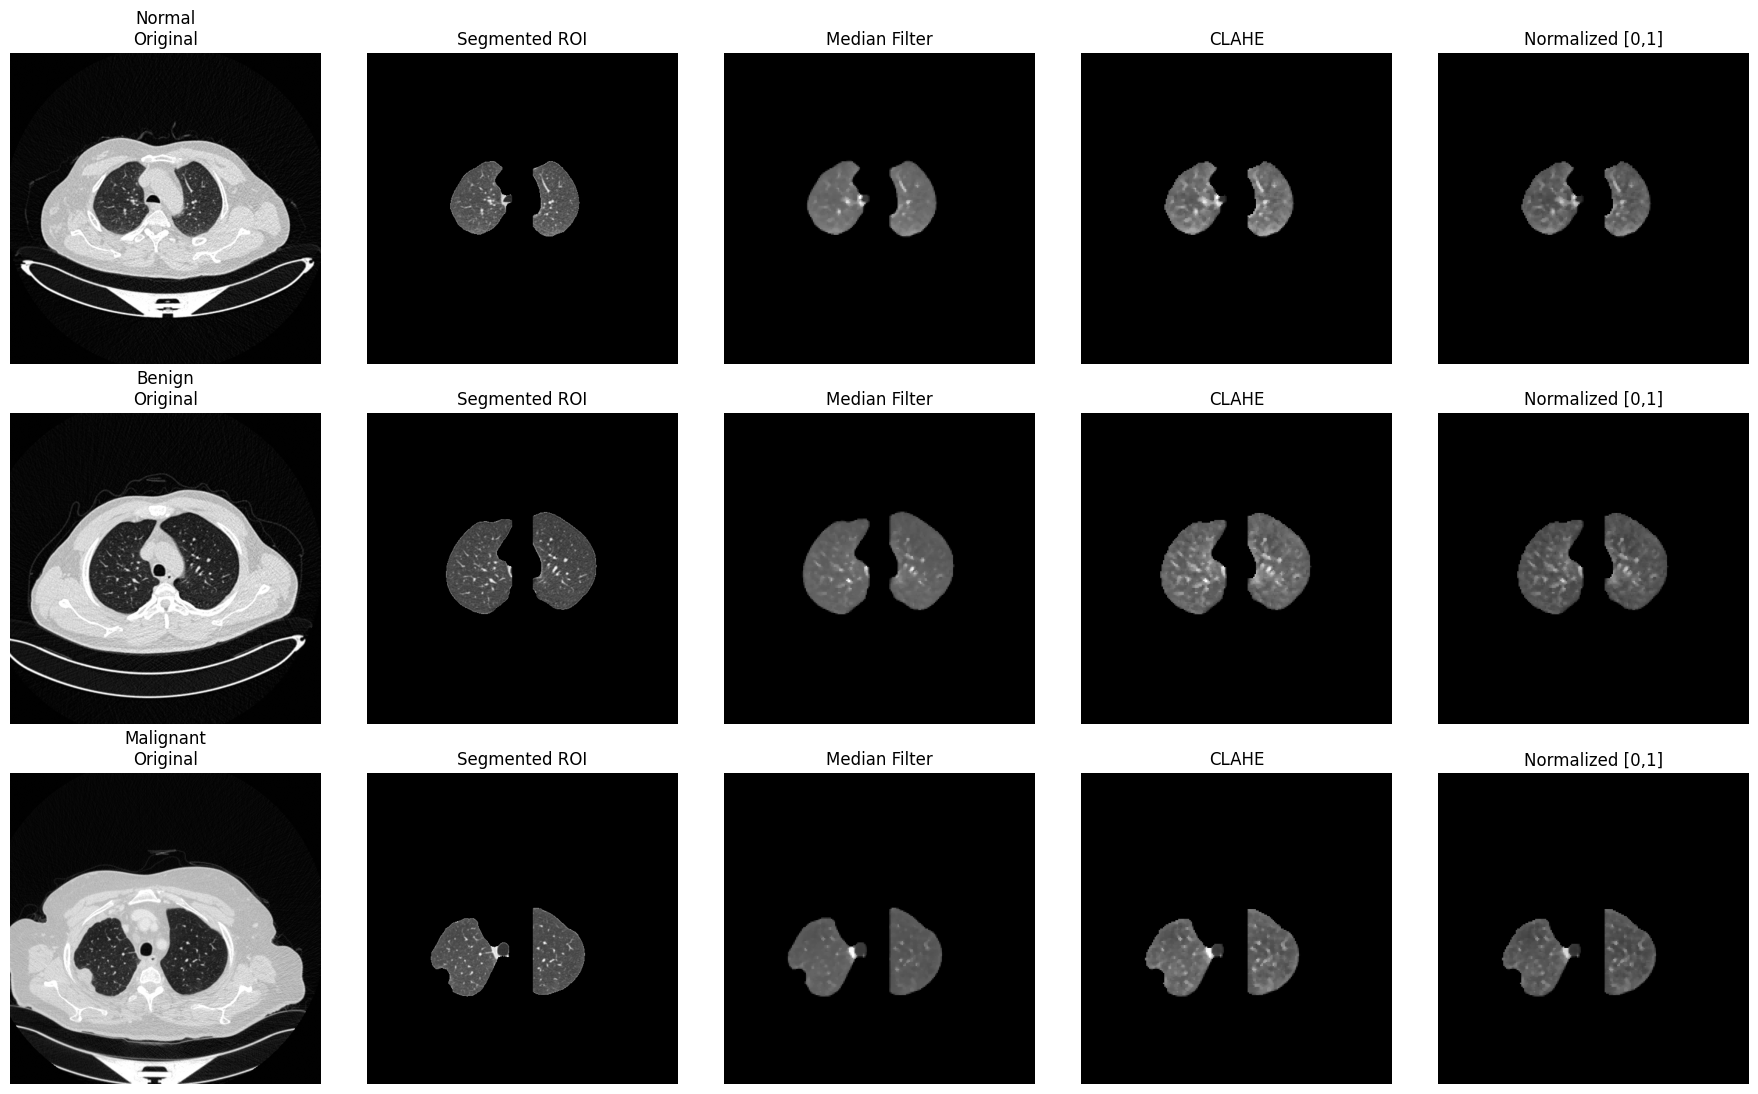

In [ ]:
# ============================================================
# CELL 9B — VISUALIZE COMPLETE PREPROCESSING
# ============================================================

# One image from each class
preprocessing_samples = []

# Using the correct training DataFrame variable: iq_train_df
for class_name in CLASS_NAMES:

    sample = iq_train_df[
        iq_train_df["class"] == class_name
    ].iloc[0]["filepath"]

    preprocessing_samples.append(
        (class_name, sample)
    )


fig, axes = plt.subplots(
    len(preprocessing_samples),
    5,
    figsize=(18, 11)
)


for row, (class_name, image_path) in enumerate(
    preprocessing_samples
):

    result = preprocess_image(
        image_path
    )

    # --------------------------------------------------------
    # Original
    # --------------------------------------------------------
    axes[row, 0].imshow(
        result["original"],
        cmap="gray"
    )

    axes[row, 0].set_title(
        f"{class_name}\nOriginal"
    )

    # --------------------------------------------------------
    # Segmented ROI
    # --------------------------------------------------------
    axes[row, 1].imshow(
        result["segmented_roi"],
        cmap="gray"
    )

    axes[row, 1].set_title(
        "Segmented ROI"
    )

    # --------------------------------------------------------
    # Denoised
    # --------------------------------------------------------
    axes[row, 2].imshow(
        result["denoised"],
        cmap="gray"
    )

    axes[row, 2].set_title(
        "Median Filter"
    )

    # --------------------------------------------------------
    # CLAHE
    # --------------------------------------------------------
    axes[row, 3].imshow(
        result["enhanced"],
        cmap="gray"
    )

    axes[row, 3].set_title(
        "CLAHE"
    )

    # --------------------------------------------------------
    # Normalized
    # --------------------------------------------------------
    axes[row, 4].imshow(
        result["normalized"],
        cmap="gray",
        vmin=0,
        vmax=1
    )

    axes[row, 4].set_title(
        "Normalized [0,1]"
    )

    for col in range(5):
        axes[row, col].axis(
            "off"
        )


plt.tight_layout()
plt.show()

# **DATA AUGMENTATION**

In [ ]:
# ============================================================
# CELL 10 — TRAINING-ONLY DATA AUGMENTATION
# ============================================================

from torchvision import transforms

IMAGE_SIZE = 224

# ------------------------------------------------------------
# Training augmentation
# ------------------------------------------------------------
train_transform = transforms.Compose([

    # Standard size
    transforms.Resize(
        (IMAGE_SIZE, IMAGE_SIZE)
    ),

    # Mild geometric augmentation
    transforms.RandomHorizontalFlip(
        p=0.5
    ),

    transforms.RandomRotation(
        degrees=10
    ),

    transforms.RandomAffine(
        degrees=0,
        translate=(0.05, 0.05),
        scale=(0.95, 1.05)
    ),

    # Mild intensity augmentation
    transforms.ColorJitter(
        brightness=0.15,
        contrast=0.15
    ),

    # Convert to tensor
    transforms.ToTensor()
])


# ------------------------------------------------------------
# Validation / Internal Test
# NO augmentation
# ------------------------------------------------------------
val_test_transform = transforms.Compose([

    transforms.Resize(
        (IMAGE_SIZE, IMAGE_SIZE)
    ),

    transforms.ToTensor()
])


print("Training augmentation:")
print("  ✓ Horizontal flip")
print("  ✓ Rotation ±10°")
print("  ✓ Small translation")
print("  ✓ Small scale variation")
print("  ✓ Mild brightness/contrast variation")

print("\nValidation:")
print("  ✓ Resize only")

print("\nInternal Test:")
print("  ✓ Resize only")

Training augmentation:
  ✓ Horizontal flip
  ✓ Rotation ±10°
  ✓ Small translation
  ✓ Small scale variation
  ✓ Mild brightness/contrast variation

Validation:
  ✓ Resize only

Internal Test:
  ✓ Resize only


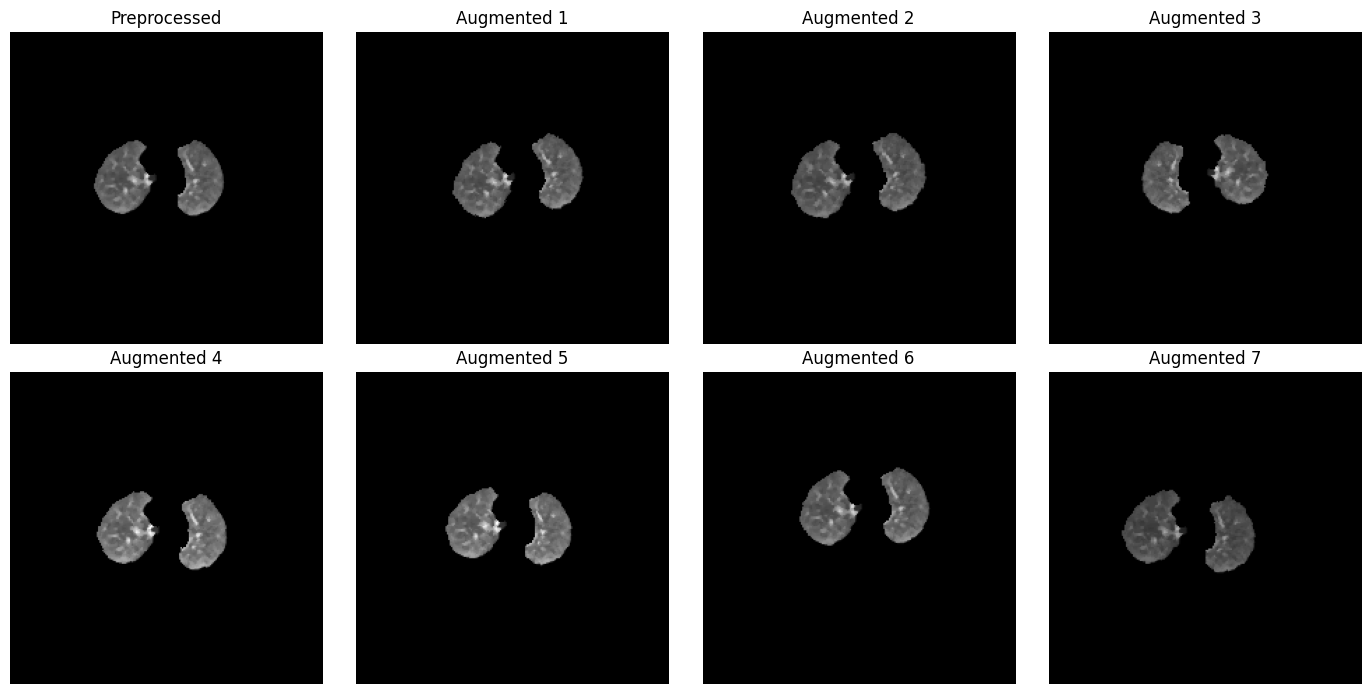

In [ ]:
# ============================================================
# CELL 10B — VISUALIZE TRAINING AUGMENTATION
# ============================================================

# Take one training image
sample_path = iq_train_df.iloc[0]["filepath"]

# Get the already preprocessed image
preprocessed = preprocess_image(sample_path)

normalized_image = preprocessed["normalized"]

# Convert [0,1] image to PIL
base_uint8 = (
    normalized_image * 255
).astype(np.uint8)

base_pil = Image.fromarray(
    base_uint8
).convert("L").convert("RGB")


# ------------------------------------------------------------
# Generate augmented versions
# ------------------------------------------------------------

fig, axes = plt.subplots(
    2,
    4,
    figsize=(14, 7)
)


# Original
axes[0, 0].imshow(
    normalized_image,
    cmap="gray",
    vmin=0,
    vmax=1
)

axes[0, 0].set_title("Preprocessed")


# Augmented images
for i in range(7):

    augmented = train_transform(
        base_pil
    )

    # Convert tensor back to image
    aug_image = augmented.permute(
        1, 2, 0
    ).numpy()

    # Since no normalization has been applied yet,
    # values are already in [0,1]
    aug_image = np.clip(
        aug_image,
        0,
        1
    )

    row = (i + 1) // 4
    col = (i + 1) % 4

    axes[row, col].imshow(
        aug_image
    )

    axes[row, col].set_title(
        f"Augmented {i+1}"
    )


for ax in axes.flat:
    ax.axis("off")


plt.tight_layout()
plt.show()

# **Feature extraction**

In [ ]:
# ============================================================
# CELL 11 — EXPLICIT FEATURE EXTRACTION
# ============================================================

from skimage.feature import (
    hog,
    local_binary_pattern,
    graycomatrix,
    graycoprops,
    canny
)

from skimage.measure import regionprops, label as sk_label


# ============================================================
# 1. INTENSITY FEATURES
# ============================================================

def extract_intensity_features(image, mask):

    lung_pixels = image[mask > 0].astype(np.float32)

    if len(lung_pixels) == 0:
        return np.zeros(10, dtype=np.float32)

    percentiles = np.percentile(
        lung_pixels,
        [10, 25, 50, 75, 90]
    )

    mean = np.mean(lung_pixels)
    std = np.std(lung_pixels)

    variance = np.var(lung_pixels)

    minimum = np.min(lung_pixels)
    maximum = np.max(lung_pixels)

    # Skewness
    if std > 1e-8:
        skewness = np.mean(
            ((lung_pixels - mean) / std) ** 3
        )

        # Kurtosis
        kurtosis = np.mean(
            ((lung_pixels - mean) / std) ** 4
        )
    else:
        skewness = 0.0
        kurtosis = 0.0

    features = [
        mean,
        std,
        variance,
        minimum,
        maximum,
        percentiles[0],
        percentiles[1],
        percentiles[2],
        percentiles[3],
        percentiles[4],
        skewness,
        kurtosis
    ]

    return np.asarray(
        features,
        dtype=np.float32
    )


# ============================================================
# 2. GLCM TEXTURE FEATURES
# ============================================================

def extract_glcm_features(image, mask):

    # Convert normalized image [0,1]
    # into 16 gray levels.
    quantized = np.floor(
        image * 16
    ).astype(np.uint8)

    quantized = np.clip(
        quantized,
        0,
        15
    )

    # Background = 0
    quantized[mask == 0] = 0

    glcm = graycomatrix(
        quantized,
        distances=[1, 2],
        angles=[
            0,
            np.pi / 4,
            np.pi / 2,
            3 * np.pi / 4
        ],
        levels=16,
        symmetric=True,
        normed=True
    )

    features = []

    properties = [
        "contrast",
        "dissimilarity",
        "homogeneity",
        "energy",
        "correlation",
        "ASM"
    ]

    for prop in properties:

        values = graycoprops(
            glcm,
            prop
        )

        features.append(
            np.mean(values)
        )

        features.append(
            np.std(values)
        )

    return np.asarray(
        features,
        dtype=np.float32
    )


# ============================================================
# 3. LBP TEXTURE FEATURES
# ============================================================

def extract_lbp_features(
    image,
    mask,
    radius=2
):

    points = 8 * radius

    lbp = local_binary_pattern(
        image,
        points,
        radius,
        method="uniform"
    )

    lung_pixels = lbp[
        mask > 0
    ]

    # Uniform LBP produces P + 2 bins
    n_bins = points + 2

    histogram, _ = np.histogram(
        lung_pixels,
        bins=np.arange(
            0,
            n_bins + 1
        ),
        range=(0, n_bins)
    )

    histogram = histogram.astype(
        np.float32
    )

    histogram /= (
        histogram.sum() + 1e-8
    )

    return histogram


# ============================================================
# 4. HOG FEATURES
# ============================================================

def extract_hog_features(
    image,
    mask
):

    roi = image.copy()

    roi[mask == 0] = 0

    hog_features = hog(
        roi,
        orientations=9,
        pixels_per_cell=(16, 16),
        cells_per_block=(2, 2),
        block_norm="L2-Hys",
        feature_vector=True
    )

    return hog_features.astype(
        np.float32
    )


# ============================================================
# 5. SHAPE FEATURES
# ============================================================

def extract_shape_features(mask):

    binary_mask = (
        mask > 0
    ).astype(np.uint8)

    labeled = sk_label(
        binary_mask
    )

    regions = regionprops(
        labeled
    )

    # IMPORTANT:
    # Always return exactly 11 features
    # even if no region is detected.
    if len(regions) == 0:
        return np.zeros(
            11,
            dtype=np.float32
        )

    # Largest detected lung region
    largest_region = max(
        regions,
        key=lambda r: r.area
    )

    area = float(
        largest_region.area
    )

    perimeter = float(
        largest_region.perimeter
    )

    major_axis = float(
        largest_region.major_axis_length
    )

    minor_axis = float(
        largest_region.minor_axis_length
    )

    bbox_area = float(
        largest_region.bbox_area
    )

    circularity = (
        4 * np.pi * area /
        (perimeter ** 2 + 1e-8)
    )

    aspect_ratio = (
        major_axis /
        (minor_axis + 1e-8)
    )

    extent = float(
        largest_region.extent
    )

    solidity = float(
        largest_region.solidity
    )

    total_pixels = (
        binary_mask.shape[0] *
        binary_mask.shape[1]
    )

    area_ratio = (
        area /
        total_pixels
    )

    bbox_ratio = (
        bbox_area /
        total_pixels
    )

    features = [
        area,
        perimeter,
        major_axis,
        minor_axis,
        bbox_area,
        circularity,
        aspect_ratio,
        extent,
        solidity,
        area_ratio,
        bbox_ratio
    ]

    return np.asarray(
        features,
        dtype=np.float32
    )

# ============================================================
# 6. EDGE / GRADIENT FEATURES
# ============================================================

def extract_edge_features(
    image,
    mask
):

    # Sobel gradients
    gx = cv2.Sobel(
        image,
        cv2.CV_32F,
        1,
        0,
        ksize=3
    )

    gy = cv2.Sobel(
        image,
        cv2.CV_32F,
        0,
        1,
        ksize=3
    )

    gradient_magnitude = np.sqrt(
        gx ** 2 +
        gy ** 2
    )

    lung_pixels = gradient_magnitude[
        mask > 0
    ]

    if len(lung_pixels) == 0:
        return np.zeros(
            11,
            dtype=np.float32
        )

    # Canny edge map
    edges = canny(
        image,
        sigma=1.0
    )

    edge_density = np.mean(
        edges[mask > 0]
    )

    mean_gradient = np.mean(
        lung_pixels
    )

    std_gradient = np.std(
        lung_pixels
    )

    max_gradient = np.max(
        lung_pixels
    )

    gradient_percentiles = np.percentile(
        lung_pixels,
        [10, 25, 50, 75, 90]
    )

    features = [
        edge_density,
        mean_gradient,
        std_gradient,
        max_gradient,
        gradient_percentiles[0],
        gradient_percentiles[1],
        gradient_percentiles[2],
        gradient_percentiles[3],
        gradient_percentiles[4]
    ]

    return np.asarray(
        features,
        dtype=np.float32
    )


# ============================================================
# COMPLETE FEATURE EXTRACTION
# ============================================================

def extract_all_features(image_path):

    result = preprocess_image(
        image_path
    )

    image = result["normalized"]
    mask = result["mask"]

    # Extract individual feature groups
    intensity = extract_intensity_features(
        image,
        mask
    )

    glcm = extract_glcm_features(
        image,
        mask
    )

    lbp = extract_lbp_features(
        image,
        mask
    )

    hog_features = extract_hog_features(
        image,
        mask
    )

    shape = extract_shape_features(
        mask
    )

    edge = extract_edge_features(
        image,
        mask
    )

    # Combine all features
    feature_vector = np.concatenate([
        intensity,
        glcm,
        lbp,
        hog_features,
        shape,
        edge
    ])

    return feature_vector.astype(
        np.float32
    )


print("Feature extraction functions created successfully.")

Feature extraction functions created successfully.


In [ ]:
# ============================================================
# CELL 11B — FEATURE COUNT
# ============================================================

# Use one training image only to determine
# the dimensionality of each feature group.

sample_path = iq_train_df.iloc[0]["filepath"]

result = preprocess_image(
    sample_path
)

image = result["normalized"]
mask = result["mask"]


feature_groups = {

    "Intensity":
        len(
            extract_intensity_features(
                image, mask
            )
        ),

    "GLCM":
        len(
            extract_glcm_features(
                image, mask
            )
        ),

    "LBP":
        len(
            extract_lbp_features(
                image, mask
            )
        ),

    "HOG":
        len(
            extract_hog_features(
                image, mask
            )
        ),

    "Shape":
        len(
            extract_shape_features(
                mask
            )
        ),

    "Edge/Gradient":
        len(
            extract_edge_features(
                image, mask
            )
        )
}


feature_report = pd.DataFrame({
    "Feature Group":
        list(feature_groups.keys()),

    "Number of Features":
        list(feature_groups.values())
})


total_features = sum(
    feature_groups.values()
)


feature_report.loc[
    len(feature_report)
] = [
    "TOTAL",
    total_features
]


print("==============================================")
print("FEATURE EXTRACTION SUMMARY")
print("==============================================")

display(feature_report)

print(
    f"\nTotal explicitly extracted features: "
    f"{total_features}"
)

FEATURE EXTRACTION SUMMARY


,Feature Group,Number of Features
0,Intensity,12
1,GLCM,12
2,LBP,18
3,HOG,6084
4,Shape,11
5,Edge/Gradient,9
6,TOTAL,6146



Total explicitly extracted features: 6146


In [ ]:
# ============================================================
# CELL 11C — FEATURE DIMENSION CONSISTENCY CHECK
# ============================================================

print("Checking feature dimensions for all development images...\n")

feature_dimensions = []

# Corrected variable name from df to development_df
for _, row in development_df.iterrows():

    vector = extract_all_features(
        row["filepath"]
    )

    feature_dimensions.append({
        "filepath": row["filepath"],
        "class": row["class"],
        "feature_count": len(vector)
    })


feature_dimension_df = pd.DataFrame(
    feature_dimensions
)

print("==============================================")
print("FEATURE DIMENSION CHECK")
print("==============================================")

print(
    feature_dimension_df[
        "feature_count"
    ].value_counts().sort_index()
)

print("\nUnique feature counts:")

for count in sorted(
    feature_dimension_df["feature_count"].unique()
):
    print(
        f"  {count} features : "
        f"{(feature_dimension_df['feature_count'] == count).sum()} images"
    )

Checking feature dimensions for all development images...

FEATURE DIMENSION CHECK
feature_count
6146    1150
Name: count, dtype: int64

Unique feature counts:
  6146 features : 1150 images


# **Extract features for Train, Validation and Internal Test**

In [ ]:
# ============================================================
# CELL 12 — EXTRACT FEATURES FOR ALL DATA SPLITS
# ============================================================

def build_feature_matrix(dataframe, dataset_name):

    features = []
    labels = dataframe["label"].to_numpy()

    print(f"\nExtracting {dataset_name} features...")
    print("-" * 50)

    for i, (_, row) in enumerate(dataframe.iterrows()):

        feature_vector = extract_all_features(
            row["filepath"]
        )

        features.append(
            feature_vector
        )

        if (i + 1) % 5 == 0 or (i + 1) == len(dataframe):

            print(
                f"{dataset_name}: "
                f"{i + 1}/{len(dataframe)}"
            )

    X = np.vstack(features).astype(
        np.float32
    )

    y = labels.astype(
        np.int64
    )

    print(
        f"{dataset_name} feature matrix: "
        f"{X.shape}"
    )

    return X, y


# ------------------------------------------------------------
# TRAIN
# ------------------------------------------------------------

X_train_raw, y_train = build_feature_matrix(
    iq_train_df,
    "TRAIN"
)


# ------------------------------------------------------------
# VALIDATION
# ------------------------------------------------------------

X_val_raw, y_val = build_feature_matrix(
    iq_val_df,
    "VALIDATION"
)


# ------------------------------------------------------------
# INTERNAL TEST
# ------------------------------------------------------------

X_test_raw, y_test = build_feature_matrix(
    iq_internal_test_df,
    "INTERNAL TEST"
)


# ============================================================
# FINAL SHAPE CHECK
# ============================================================

print("\n==============================================")
print("FEATURE MATRIX SUMMARY")
print("==============================================")

print(
    "Training      :",
    X_train_raw.shape
)

print(
    "Validation    :",
    X_val_raw.shape
)

print(
    "Internal Test :",
    X_test_raw.shape
)

print("\nExpected feature count: 6146")


Extracting TRAIN features...
--------------------------------------------------
TRAIN: 5/767
TRAIN: 10/767
TRAIN: 15/767
TRAIN: 20/767
TRAIN: 25/767
TRAIN: 30/767
TRAIN: 35/767
TRAIN: 40/767
TRAIN: 45/767
TRAIN: 50/767
TRAIN: 55/767
TRAIN: 60/767
TRAIN: 65/767
TRAIN: 70/767
TRAIN: 75/767
TRAIN: 80/767
TRAIN: 85/767
TRAIN: 90/767
TRAIN: 95/767
TRAIN: 100/767
TRAIN: 105/767
TRAIN: 110/767
TRAIN: 115/767
TRAIN: 120/767
TRAIN: 125/767
TRAIN: 130/767
TRAIN: 135/767
TRAIN: 140/767
TRAIN: 145/767
TRAIN: 150/767
TRAIN: 155/767
TRAIN: 160/767
TRAIN: 165/767
TRAIN: 170/767
TRAIN: 175/767
TRAIN: 180/767
TRAIN: 185/767
TRAIN: 190/767
TRAIN: 195/767
TRAIN: 200/767
TRAIN: 205/767
TRAIN: 210/767
TRAIN: 215/767
TRAIN: 220/767
TRAIN: 225/767
TRAIN: 230/767
TRAIN: 235/767
TRAIN: 240/767
TRAIN: 245/767
TRAIN: 250/767
TRAIN: 255/767
TRAIN: 260/767
TRAIN: 265/767
TRAIN: 270/767
TRAIN: 275/767
TRAIN: 280/767
TRAIN: 285/767
TRAIN: 290/767
TRAIN: 295/767
TRAIN: 300/767
TRAIN: 305/767
TRAIN: 310/767
TRAIN: 31

# **Feature Checking & Selection**

In [ ]:
# ============================================================
# CELL 13A — FEATURE CLEANING
# ============================================================

# Work on copies
X_train_clean = X_train_raw.copy()
X_val_clean = X_val_raw.copy()
X_test_clean = X_test_raw.copy()

print("Original feature count:", X_train_clean.shape[1])

# ------------------------------------------------------------
# 1. Replace NaN / infinite values
# ------------------------------------------------------------

X_train_clean = np.nan_to_num(
    X_train_clean,
    nan=0.0,
    posinf=0.0,
    neginf=0.0
)

X_val_clean = np.nan_to_num(
    X_val_clean,
    nan=0.0,
    posinf=0.0,
    neginf=0.0
)

X_test_clean = np.nan_to_num(
    X_test_clean,
    nan=0.0,
    posinf=0.0,
    neginf=0.0
)

# ------------------------------------------------------------
# 2. Remove zero-variance features
# ------------------------------------------------------------

variance_selector = VarianceThreshold(
    threshold=0.0
)

X_train_var = variance_selector.fit_transform(
    X_train_clean
)

X_val_var = variance_selector.transform(
    X_val_clean
)

X_test_var = variance_selector.transform(
    X_test_clean
)

print(
    "After zero-variance removal:",
    X_train_var.shape[1]
)

print(
    "Features removed:",
    X_train_clean.shape[1]
    - X_train_var.shape[1]
)

Original feature count: 6146
After zero-variance removal: 4792
Features removed: 1354


In [ ]:
# ============================================================
# CELL 13B — CORRELATION-BASED FEATURE REDUCTION
# ============================================================

def remove_highly_correlated_features(
    X,
    threshold=0.95
):
    """
    Identify highly correlated features using
    training data only.
    """

    # Convert to DataFrame
    df_features = pd.DataFrame(
        X
    )

    # Correlation matrix
    correlation_matrix = df_features.corr(
        method="pearson"
    ).abs()

    # Upper triangle only
    upper = correlation_matrix.where(
        np.triu(
            np.ones(
                correlation_matrix.shape
            ),
            k=1
        ).astype(bool)
    )

    # Features to remove
    to_drop = [
        column
        for column in upper.columns
        if any(
            upper[column] > threshold
        )
    ]

    keep_indices = [
        i
        for i, column in enumerate(
            df_features.columns
        )
        if column not in to_drop
    ]

    return (
        keep_indices,
        to_drop
    )


# ------------------------------------------------------------
# Find redundant features ONLY using training data
# ------------------------------------------------------------

keep_indices, correlated_features = (
    remove_highly_correlated_features(
        X_train_var,
        threshold=0.95
    )
)

# Apply same feature selection to all sets
X_train_corr = X_train_var[
    :, keep_indices
]

X_val_corr = X_val_var[
    :, keep_indices
]

X_test_corr = X_test_var[
    :, keep_indices
]


print("==============================================")
print("CORRELATION-BASED FEATURE REDUCTION")
print("==============================================")

print(
    "Before:",
    X_train_var.shape[1]
)

print(
    "Removed:",
    len(correlated_features)
)

print(
    "After :",
    X_train_corr.shape[1]
)

CORRELATION-BASED FEATURE REDUCTION
Before: 4792
Removed: 2470
After : 2322


In [ ]:
# ============================================================
# CELL 13C — INFORMATIVE FEATURE SELECTION
# ============================================================

from sklearn.feature_selection import SelectKBest, f_classif

# ------------------------------------------------------------
# Number of features to retain
# ------------------------------------------------------------

K_FEATURES = 50

K_FEATURES = min(
    K_FEATURES,
    X_train_corr.shape[1]
)

print(
    "Features before statistical selection:",
    X_train_corr.shape[1]
)

print(
    "Selecting top",
    K_FEATURES,
    "features..."
)


# ------------------------------------------------------------
# Fit selector ONLY on training data
# ------------------------------------------------------------

feature_selector = SelectKBest(
    score_func=f_classif,
    k=K_FEATURES
)

X_train_selected = feature_selector.fit_transform(
    X_train_corr,
    y_train
)


# ------------------------------------------------------------
# Apply SAME selector to validation and test
# ------------------------------------------------------------

X_val_selected = feature_selector.transform(
    X_val_corr
)

X_test_selected = feature_selector.transform(
    X_test_corr
)


# ------------------------------------------------------------
# Summary
# ------------------------------------------------------------

print("\n==============================================")
print("STATISTICAL FEATURE SELECTION")
print("==============================================")

print(
    "Before selection :",
    X_train_corr.shape[1]
)

print(
    "Selected         :",
    X_train_selected.shape[1]
)

print(
    "Removed          :",
    X_train_corr.shape[1]
    - X_train_selected.shape[1]
)

print("\nFinal feature matrices:")

print(
    "Training      :",
    X_train_selected.shape
)

print(
    "Validation    :",
    X_val_selected.shape
)

print(
    "Internal Test :",
    X_test_selected.shape
)

Features before statistical selection: 2322
Selecting top 50 features...

STATISTICAL FEATURE SELECTION
Before selection : 2322
Selected         : 50
Removed          : 2272

Final feature matrices:
Training      : (767, 50)
Validation    : (220, 50)
Internal Test : (110, 50)


# **Standardize the selected features**

In [ ]:
# ============================================================
# CELL 14 — FEATURE STANDARDIZATION
# ============================================================

from sklearn.preprocessing import StandardScaler

# ------------------------------------------------------------
# Fit scaler ONLY on training data
# ------------------------------------------------------------

feature_scaler = StandardScaler()

X_train_final = feature_scaler.fit_transform(
    X_train_selected
)

# Apply same scaler
X_val_final = feature_scaler.transform(
    X_val_selected
)

X_test_final = feature_scaler.transform(
    X_test_selected
)

# ------------------------------------------------------------
# Convert to float32
# ------------------------------------------------------------

X_train_final = X_train_final.astype(np.float32)
X_val_final = X_val_final.astype(np.float32)
X_test_final = X_test_final.astype(np.float32)

# ------------------------------------------------------------
# Verify
# ------------------------------------------------------------

print("==============================================")
print("FEATURE STANDARDIZATION")
print("==============================================")

print("Training      :", X_train_final.shape)
print("Validation    :", X_val_final.shape)
print("Internal Test :", X_test_final.shape)

print("\nTraining feature mean:")
print(f"{X_train_final.mean():.6f}")

print("\nTraining feature standard deviation:")
print(f"{X_train_final.std():.6f}")

FEATURE STANDARDIZATION
Training      : (767, 50)
Validation    : (220, 50)
Internal Test : (110, 50)

Training feature mean:
-0.000000

Training feature standard deviation:
1.000000


# **Load pretrained ConvNeXt-Tiny**

In [ ]:
# ============================================================
# CELL 15 — CONVNEXT-TINY FEATURE EXTRACTOR
# ============================================================

import torch
import torch.nn as nn
from torchvision.models import (
    convnext_tiny,
    ConvNeXt_Tiny_Weights
)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", DEVICE)

# ------------------------------------------------------------
# Load pretrained ConvNeXt-Tiny
# ------------------------------------------------------------

weights = ConvNeXt_Tiny_Weights.DEFAULT

convnext = convnext_tiny(
    weights=weights
)

# We only need the backbone for feature extraction
convnext.classifier = nn.Identity()

convnext = convnext.to(DEVICE)

# Freeze ConvNeXt during initial feature extraction
convnext.eval()

for parameter in convnext.parameters():
    parameter.requires_grad = False


print("\nConvNeXt-Tiny loaded successfully.")
print("Backbone parameters frozen.")

print(
    "Feature dimension:",
    convnext.features[-1][-1].out_channels
    if hasattr(convnext.features[-1][-1], "out_channels")
    else "Checking..."
)

Device: cpu
Downloading: "https://download.pytorch.org/models/convnext_tiny-983f1562.pth" to /root/.cache/torch/hub/checkpoints/convnext_tiny-983f1562.pth


100%|██████████| 109M/109M [00:00<00:00, 117MB/s]



ConvNeXt-Tiny loaded successfully.
Backbone parameters frozen.
Feature dimension: Checking...


In [ ]:
# ============================================================
# CELL 15B — CONVNEXT INPUT PREPARATION
# ============================================================

CONVNEXT_MEAN = torch.tensor(
    [0.485, 0.456, 0.406]
).view(3, 1, 1)

CONVNEXT_STD = torch.tensor(
    [0.229, 0.224, 0.225]
).view(3, 1, 1)


def prepare_convnext_image(image_path):

    # Use our finalized preprocessing pipeline
    result = preprocess_image(
        image_path
    )

    image = result["normalized"]

    # Ensure 224 x 224
    image = cv2.resize(
        image,
        (224, 224),
        interpolation=cv2.INTER_AREA
    )

    # Grayscale → RGB
    image_rgb = np.stack(
        [image, image, image],
        axis=0
    )

    # Convert to tensor
    tensor = torch.tensor(
        image_rgb,
        dtype=torch.float32
    )

    # ImageNet normalization
    tensor = (
        tensor - CONVNEXT_MEAN
    ) / CONVNEXT_STD

    return tensor


# Test one image
sample_tensor = prepare_convnext_image(
    iq_train_df.iloc[0]["filepath"]
)

print("Input tensor shape:", sample_tensor.shape)
print("Expected: torch.Size([3, 224, 224])")

Input tensor shape: torch.Size([3, 224, 224])
Expected: torch.Size([3, 224, 224])


In [ ]:
# ============================================================
# CELL 15C — EXTRACT CONVNEXT DEEP FEATURES
# ============================================================

def extract_convnext_features(
    dataframe,
    dataset_name,
    batch_size=8
):

    tensors = []

    # --------------------------------------------------------
    # Prepare all images
    # --------------------------------------------------------
    for _, row in dataframe.iterrows():

        tensor = prepare_convnext_image(
            row["filepath"]
        )

        tensors.append(tensor)

    X = torch.stack(tensors)

    features = []

    print(
        f"\nExtracting ConvNeXt features for {dataset_name}..."
    )
    print("-" * 55)

    # --------------------------------------------------------
    # Feature extraction
    # --------------------------------------------------------
    with torch.no_grad():

        for start in range(
            0,
            len(X),
            batch_size
        ):

            batch = X[
                start:start + batch_size
            ].to(DEVICE)

            # ConvNeXt feature maps
            output = convnext.features(
                batch
            )

            # Global Average Pooling
            output = convnext.avgpool(
                output
            )

            # Flatten
            output = torch.flatten(
                output,
                start_dim=1
            )

            features.append(
                output.cpu().numpy()
            )

            end = min(
                start + batch_size,
                len(X)
            )

            print(
                f"{dataset_name}: "
                f"{end}/{len(X)}"
            )

    features = np.vstack(
        features
    ).astype(np.float32)

    print(
        f"{dataset_name} feature matrix: "
        f"{features.shape}"
    )

    return features

In [ ]:
# ============================================================
# CELL 15D — EXTRACT DEEP FEATURES
# ============================================================

X_train_deep = extract_convnext_features(
    iq_train_df,
    "TRAIN"
)

X_val_deep = extract_convnext_features(
    iq_val_df,
    "VALIDATION"
)

X_test_deep = extract_convnext_features(
    iq_internal_test_df,
    "INTERNAL TEST"
)


print("\n==============================================")
print("CONVNEXT DEEP FEATURE SUMMARY")
print("==============================================")

print(
    "Training      :",
    X_train_deep.shape
)

print(
    "Validation    :",
    X_val_deep.shape
)

print(
    "Internal Test :",
    X_test_deep.shape
)


Extracting ConvNeXt features for TRAIN...
-------------------------------------------------------
TRAIN: 8/767
TRAIN: 16/767
TRAIN: 24/767
TRAIN: 32/767
TRAIN: 40/767
TRAIN: 48/767
TRAIN: 56/767
TRAIN: 64/767
TRAIN: 72/767
TRAIN: 80/767
TRAIN: 88/767
TRAIN: 96/767
TRAIN: 104/767
TRAIN: 112/767
TRAIN: 120/767
TRAIN: 128/767
TRAIN: 136/767
TRAIN: 144/767
TRAIN: 152/767
TRAIN: 160/767
TRAIN: 168/767
TRAIN: 176/767
TRAIN: 184/767
TRAIN: 192/767
TRAIN: 200/767
TRAIN: 208/767
TRAIN: 216/767
TRAIN: 224/767
TRAIN: 232/767
TRAIN: 240/767
TRAIN: 248/767
TRAIN: 256/767
TRAIN: 264/767
TRAIN: 272/767
TRAIN: 280/767
TRAIN: 288/767
TRAIN: 296/767
TRAIN: 304/767
TRAIN: 312/767
TRAIN: 320/767
TRAIN: 328/767
TRAIN: 336/767
TRAIN: 344/767
TRAIN: 352/767
TRAIN: 360/767
TRAIN: 368/767
TRAIN: 376/767
TRAIN: 384/767
TRAIN: 392/767
TRAIN: 400/767
TRAIN: 408/767
TRAIN: 416/767
TRAIN: 424/767
TRAIN: 432/767
TRAIN: 440/767
TRAIN: 448/767
TRAIN: 456/767
TRAIN: 464/767
TRAIN: 472/767
TRAIN: 480/767
TRAIN: 488/767

# **Reduce ConvNeXt features**

In [ ]:
# ============================================================
# CELL 16 — REDUCE CONVNEXT FEATURES
# ============================================================

from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

DEEP_FEATURES = 32

# ------------------------------------------------------------
# Standardize deep features
# ------------------------------------------------------------

deep_scaler = StandardScaler()

X_train_deep_scaled = deep_scaler.fit_transform(
    X_train_deep
)

X_val_deep_scaled = deep_scaler.transform(
    X_val_deep
)

X_test_deep_scaled = deep_scaler.transform(
    X_test_deep
)


# ------------------------------------------------------------
# PCA — FIT ONLY ON TRAINING DATA
# ------------------------------------------------------------

deep_pca = PCA(
    n_components=DEEP_FEATURES,
    random_state=SEED
)

X_train_deep_reduced = deep_pca.fit_transform(
    X_train_deep_scaled
)

X_val_deep_reduced = deep_pca.transform(
    X_val_deep_scaled
)

X_test_deep_reduced = deep_pca.transform(
    X_test_deep_scaled
)


print("==============================================")
print("CONVNEXT FEATURE REDUCTION")
print("==============================================")

print(
    "Original deep features :",
    X_train_deep.shape[1]
)

print(
    "Reduced deep features  :",
    X_train_deep_reduced.shape[1]
)

print(
    "Explained variance     :",
    f"{deep_pca.explained_variance_ratio_.sum()*100:.2f}%"
)

CONVNEXT FEATURE REDUCTION
Original deep features : 768
Reduced deep features  : 32
Explained variance     : 78.76%


In [ ]:
# ============================================================
# CELL 16B — FEATURE FUSION
# ============================================================

# 50 selected handcrafted features
# +
# 32 reduced ConvNeXt features
# =
# 82 fused features

X_train_fused = np.concatenate(
    [
        X_train_final,
        X_train_deep_reduced
    ],
    axis=1
)

X_val_fused = np.concatenate(
    [
        X_val_final,
        X_val_deep_reduced
    ],
    axis=1
)

X_test_fused = np.concatenate(
    [
        X_test_final,
        X_test_deep_reduced
    ],
    axis=1
)


print("==============================================")
print("FEATURE FUSION")
print("==============================================")

print(
    "Handcrafted features :",
    X_train_final.shape[1]
)

print(
    "ConvNeXt features    :",
    X_train_deep_reduced.shape[1]
)

print(
    "Fused features       :",
    X_train_fused.shape[1]
)

print("\nFinal fused matrices:")

print(
    "Training      :",
    X_train_fused.shape
)

print(
    "Validation    :",
    X_val_fused.shape
)

print(
    "Internal Test :",
    X_test_fused.shape
)

FEATURE FUSION
Handcrafted features : 50
ConvNeXt features    : 32
Fused features       : 82

Final fused matrices:
Training      : (767, 82)
Validation    : (220, 82)
Internal Test : (110, 82)


# **Genetic Programming**

In [ ]:
!pip install -q gplearn

In [ ]:
import numpy as np
import pandas as pd

print("GP INPUT")
print("-" * 40)

print("Training features    :", X_train_final.shape)
print("Validation features  :", X_val_final.shape)
print("Internal Test        :", X_test_final.shape)

print("\nLabels:")
print("Training distribution   :", np.bincount(y_train))
print("Validation distribution :", np.bincount(y_val))
print("Internal Test           :", np.bincount(y_test))

GP INPUT
----------------------------------------
Training features    : (767, 50)
Validation features  : (220, 50)
Internal Test        : (110, 50)

Labels:
Training distribution   : [291  84 392]
Validation distribution : [ 83  24 113]
Internal Test           : [42 12 56]


In [ ]:
from gplearn.genetic import SymbolicClassifier
import numpy as np
import joblib
from pathlib import Path

# ============================================================
# MONKEY PATCH FOR GPLEARN & SCIKIT-LEARN COMPATIBILITY
# ============================================================
if not hasattr(SymbolicClassifier, '_validate_data'):
    from sklearn.utils.validation import check_X_y
    def _validate_data(self, X, y, **kwargs):
        return check_X_y(X, y, accept_sparse=kwargs.get('accept_sparse', False))
    SymbolicClassifier._validate_data = _validate_data

CLASS_NAMES = ["Normal", "Benign", "Malignant"]
N_CLASSES = 3

gp_models = []

print("Starting Genetic Programming training...")
print("=" * 60)

for class_idx, class_name in enumerate(CLASS_NAMES):

    print(f"\nTraining GP for class: {class_name}")

    # One-vs-Rest target
    y_binary = (y_train == class_idx).astype(int)

    gp = SymbolicClassifier(
        population_size=250,
        generations=15,

        function_set=(
            "add",
            "sub",
            "mul",
            "div",
            "sqrt",
            "log",
            "abs",
            "neg"
        ),

        metric="log loss",

        parsimony_coefficient=0.001,
        max_samples=0.8,

        random_state=42 + class_idx * 10,
        n_jobs=-1,

        verbose=1
    )

    gp.fit(X_train_final, y_binary)

    gp_models.append(gp)

    print(f"✓ {class_name} GP completed")
    print(f"  Program length: {gp._program.length_}")
    print(f"  Program depth : {gp._program.depth_}")

print("\n" + "=" * 60)
print("ALL GP MODELS TRAINED")

Starting Genetic Programming training...

Training GP for class: Normal
    |   Population Average    |             Best Individual              |
---- ------------------------- ------------------------------------------ ----------
 Gen   Length          Fitness   Length          Fitness      OOB Fitness  Time Left
   0     8.73          1.21216        2         0.565506         0.621231      1.11m
   1     3.62         0.746408        4         0.564954         0.611811      9.63s
   2     3.35         0.681759        4         0.553782         0.656279      7.98s
   3     3.22         0.653403        5         0.536738         0.652239      8.61s
   4     4.17         0.637522        5         0.539162         0.642589      9.21s
   5     4.48         0.622498        5         0.540249         0.638262      8.46s
   6     4.98         0.620882        5         0.537516         0.649142      6.04s
   7     4.98         0.641524        5         0.541127         0.634768      4.80s
   

In [ ]:
def gp_predict_proba(models, X):

    probabilities = []

    for model in models:
        # Probability of belonging to this class
        prob = model.predict_proba(X)[:, 1]
        probabilities.append(prob)

    probabilities = np.column_stack(probabilities)

    # Normalize so that probabilities across
    # Normal + Benign + Malignant sum to 1
    row_sums = probabilities.sum(axis=1, keepdims=True)

    probabilities = probabilities / np.clip(
        row_sums,
        1e-8,
        None
    )

    return probabilities

In [ ]:
# Ensure the fitted GP models have the 'n_features_in_' attribute set properly
for model in gp_models:
    if not hasattr(model, 'n_features_in_'):
        model.n_features_in_ = X_val_final.shape[1]

gp_val_proba = gp_predict_proba(
    gp_models,
    X_val_final
)

gp_val_pred = np.argmax(
    gp_val_proba,
    axis=1
)

print("Validation probability shape:", gp_val_proba.shape)
print("Validation prediction shape:", gp_val_pred.shape)

Validation probability shape: (220, 3)
Validation prediction shape: (220,)


In [ ]:
gp_val_results = pd.DataFrame(
    gp_val_proba,
    columns=CLASS_NAMES
)

gp_val_results["Actual"] = [
    CLASS_NAMES[i] for i in y_val
]

gp_val_results["Predicted"] = [
    CLASS_NAMES[i] for i in gp_val_pred
]

gp_val_results["Confidence"] = gp_val_proba.max(axis=1)

gp_val_results

,Normal,Benign,Malignant,Actual,Predicted,Confidence
0,0.870023,0.073337,0.056640,Benign,Normal,0.870023
1,0.328596,0.097913,0.573492,Benign,Malignant,0.573492
2,0.792169,0.100685,0.107146,Normal,Normal,0.792169
3,0.101313,0.055973,0.842714,Malignant,Malignant,0.842714
4,0.353744,0.041330,0.604926,Malignant,Malignant,0.604926
...,...,...,...,...,...,...
215,0.736033,0.127234,0.136732,Normal,Normal,0.736033
216,0.172228,0.052465,0.775307,Malignant,Malignant,0.775307
217,0.851413,0.095822,0.052765,Normal,Normal,0.851413
218,0.901429,0.092394,0.006177,Normal,Normal,0.901429


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

gp_accuracy = accuracy_score(y_val, gp_val_pred)

gp_balanced_accuracy = balanced_accuracy_score(
    y_val,
    gp_val_pred
)

gp_macro_precision = precision_score(
    y_val,
    gp_val_pred,
    average="macro",
    zero_division=0
)

gp_macro_recall = recall_score(
    y_val,
    gp_val_pred,
    average="macro",
    zero_division=0
)

gp_macro_f1 = f1_score(
    y_val,
    gp_val_pred,
    average="macro",
    zero_division=0
)

print("=" * 60)
print("GENETIC PROGRAMMING — VALIDATION RESULTS")
print("=" * 60)

print(f"Accuracy           : {gp_accuracy * 100:.2f}%")
print(f"Balanced Accuracy  : {gp_balanced_accuracy * 100:.2f}%")
print(f"Macro Precision    : {gp_macro_precision * 100:.2f}%")
print(f"Macro Recall       : {gp_macro_recall * 100:.2f}%")
print(f"Macro F1           : {gp_macro_f1 * 100:.2f}%")

GENETIC PROGRAMMING — VALIDATION RESULTS
Accuracy           : 72.27%
Balanced Accuracy  : 54.37%
Macro Precision    : 48.37%
Macro Recall       : 54.37%
Macro F1           : 50.78%


In [ ]:
print("\nCLASSIFICATION REPORT")
print("=" * 60)

print(
    classification_report(
        y_val,
        gp_val_pred,
        target_names=CLASS_NAMES,
        zero_division=0
    )
)


CLASSIFICATION REPORT
              precision    recall  f1-score   support

      Normal       0.62      0.84      0.71        83
      Benign       0.00      0.00      0.00        24
   Malignant       0.83      0.79      0.81       113

    accuracy                           0.72       220
   macro avg       0.48      0.54      0.51       220
weighted avg       0.66      0.72      0.69       220



In [ ]:
print("CONFUSION MATRIX")
print("=" * 60)

cm_gp = confusion_matrix(
    y_val,
    gp_val_pred
)

cm_gp_df = pd.DataFrame(
    cm_gp,
    index=CLASS_NAMES,
    columns=CLASS_NAMES
)

cm_gp_df

CONFUSION MATRIX


,Normal,Benign,Malignant
Normal,70,0,13
Benign,19,0,5
Malignant,24,0,89


In [ ]:
GP_DIR = Path("/content/gp_models")
GP_DIR.mkdir(exist_ok=True)

for class_name, model in zip(CLASS_NAMES, gp_models):

    filename = GP_DIR / f"gp_{class_name.lower()}.joblib"

    joblib.dump(
        model,
        filename
    )

    print("Saved:", filename)

Saved: /content/gp_models/gp_normal.joblib
Saved: /content/gp_models/gp_benign.joblib
Saved: /content/gp_models/gp_malignant.joblib


In [ ]:
# ============================================================
# GP — INTERNAL TEST EVALUATION
# ============================================================

gp_test_proba = gp_predict_proba(
    gp_models,
    X_test_final
)

gp_test_pred = np.argmax(
    gp_test_proba,
    axis=1
)

# Metrics
gp_test_accuracy = accuracy_score(
    y_test,
    gp_test_pred
)

gp_test_balanced_accuracy = balanced_accuracy_score(
    y_test,
    gp_test_pred
)

gp_test_macro_precision = precision_score(
    y_test,
    gp_test_pred,
    average="macro",
    zero_division=0
)

gp_test_macro_recall = recall_score(
    y_test,
    gp_test_pred,
    average="macro",
    zero_division=0
)

gp_test_macro_f1 = f1_score(
    y_test,
    gp_test_pred,
    average="macro",
    zero_division=0
)

print("=" * 60)
print("GENETIC PROGRAMMING — INTERNAL TEST RESULTS")
print("=" * 60)

print(f"Accuracy           : {gp_test_accuracy * 100:.2f}%")
print(f"Balanced Accuracy  : {gp_test_balanced_accuracy * 100:.2f}%")
print(f"Macro Precision    : {gp_test_macro_precision * 100:.2f}%")
print(f"Macro Recall       : {gp_test_macro_recall * 100:.2f}%")
print(f"Macro F1           : {gp_test_macro_f1 * 100:.2f}%")

GENETIC PROGRAMMING — INTERNAL TEST RESULTS
Accuracy           : 73.64%
Balanced Accuracy  : 54.56%
Macro Precision    : 48.57%
Macro Recall       : 54.56%
Macro F1           : 51.39%


In [ ]:
print("\nCLASSIFICATION REPORT")
print("=" * 60)

print(
    classification_report(
        y_test,
        gp_test_pred,
        target_names=CLASS_NAMES,
        zero_division=0
    )
)


CLASSIFICATION REPORT
              precision    recall  f1-score   support

      Normal       0.67      0.76      0.71        42
      Benign       0.00      0.00      0.00        12
   Malignant       0.79      0.88      0.83        56

    accuracy                           0.74       110
   macro avg       0.49      0.55      0.51       110
weighted avg       0.66      0.74      0.69       110



In [ ]:
print("CONFUSION MATRIX")
print("=" * 60)

cm_gp_test = confusion_matrix(
    y_test,
    gp_test_pred
)

cm_gp_test_df = pd.DataFrame(
    cm_gp_test,
    index=CLASS_NAMES,
    columns=CLASS_NAMES
)

cm_gp_test_df

CONFUSION MATRIX


,Normal,Benign,Malignant
Normal,32,0,10
Benign,9,0,3
Malignant,7,0,49


# **XGBoost**

In [ ]:
!pip install -q xgboost

In [ ]:
# ============================================================
# REPRODUCIBILITY SETTINGS
# ============================================================

import os
import random
import numpy as np
import tensorflow as tf

SEED = 42

os.environ["PYTHONHASHSEED"] = str(SEED)

random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

print("Global random seed:", SEED)

Global random seed: 42


In [ ]:
import xgboost as xgb
import numpy as np
import pandas as pd
import joblib

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("XGBoost version:", xgb.__version__)

XGBoost version: 3.4.1


In [ ]:
print("XGBOOST INPUT")
print("=" * 50)

print("Training   :", X_train_final.shape)
print("Validation :", X_val_final.shape)
print("Internal Test:", X_test_final.shape)

print("\nClasses:")
print("Normal    :", np.sum(y_train == 0))
print("Benign    :", np.sum(y_train == 1))
print("Malignant :", np.sum(y_train == 2))

XGBOOST INPUT
Training   : (767, 50)
Validation : (220, 50)
Internal Test: (110, 50)

Classes:
Normal    : 291
Benign    : 84
Malignant : 392


In [ ]:
xgb_model = xgb.XGBClassifier(
    n_estimators=200,
    max_depth=3,
    learning_rate=0.03,
    subsample=0.8,
    colsample_bytree=0.8,

    min_child_weight=2,
    reg_alpha=0.1,
    reg_lambda=1.0,

    objective="multi:softprob",
    num_class=3,
    eval_metric="mlogloss",

    random_state=42,
    tree_method="hist"
)

print("Training XGBoost...")
print("=" * 50)

xgb_model.fit(
    X_train_final,
    y_train,

    eval_set=[
        (X_train_final, y_train),
        (X_val_final, y_val)
    ],

    verbose=True
)

print("\n✓ XGBoost training completed")

Training XGBoost...
[0]	validation_0-mlogloss:0.93537	validation_1-mlogloss:0.93726
[1]	validation_0-mlogloss:0.91903	validation_1-mlogloss:0.92186
[2]	validation_0-mlogloss:0.90283	validation_1-mlogloss:0.90790
[3]	validation_0-mlogloss:0.88696	validation_1-mlogloss:0.89300
[4]	validation_0-mlogloss:0.87177	validation_1-mlogloss:0.88107
[5]	validation_0-mlogloss:0.85797	validation_1-mlogloss:0.86754
[6]	validation_0-mlogloss:0.84372	validation_1-mlogloss:0.85494
[7]	validation_0-mlogloss:0.83133	validation_1-mlogloss:0.84412
[8]	validation_0-mlogloss:0.81844	validation_1-mlogloss:0.83235
[9]	validation_0-mlogloss:0.80581	validation_1-mlogloss:0.82174
[10]	validation_0-mlogloss:0.79254	validation_1-mlogloss:0.81137
[11]	validation_0-mlogloss:0.77990	validation_1-mlogloss:0.80055
[12]	validation_0-mlogloss:0.76833	validation_1-mlogloss:0.79064
[13]	validation_0-mlogloss:0.75714	validation_1-mlogloss:0.78112
[14]	validation_0-mlogloss:0.74643	validation_1-mlogloss:0.77244
[15]	validation

In [ ]:
xgb_val_proba = xgb_model.predict_proba(
    X_val_final
)

xgb_val_pred = np.argmax(
    xgb_val_proba,
    axis=1
)

print("Probability shape :", xgb_val_proba.shape)
print("Prediction shape  :", xgb_val_pred.shape)

Probability shape : (220, 3)
Prediction shape  : (220,)


In [ ]:
xgb_val_accuracy = accuracy_score(
    y_val,
    xgb_val_pred
)

xgb_val_balanced_accuracy = balanced_accuracy_score(
    y_val,
    xgb_val_pred
)

xgb_val_macro_precision = precision_score(
    y_val,
    xgb_val_pred,
    average="macro",
    zero_division=0
)

xgb_val_macro_recall = recall_score(
    y_val,
    xgb_val_pred,
    average="macro",
    zero_division=0
)

xgb_val_macro_f1 = f1_score(
    y_val,
    xgb_val_pred,
    average="macro",
    zero_division=0
)

print("=" * 60)
print("XGBOOST — VALIDATION RESULTS")
print("=" * 60)

print(f"Accuracy           : {xgb_val_accuracy * 100:.2f}%")
print(f"Balanced Accuracy  : {xgb_val_balanced_accuracy * 100:.2f}%")
print(f"Macro Precision    : {xgb_val_macro_precision * 100:.2f}%")
print(f"Macro Recall       : {xgb_val_macro_recall * 100:.2f}%")
print(f"Macro F1           : {xgb_val_macro_f1 * 100:.2f}%")

XGBOOST — VALIDATION RESULTS
Accuracy           : 86.82%
Balanced Accuracy  : 74.29%
Macro Precision    : 82.96%
Macro Recall       : 74.29%
Macro F1           : 76.45%


In [ ]:
cm_xgb_val = confusion_matrix(
    y_val,
    xgb_val_pred
)

cm_xgb_val_df = pd.DataFrame(
    cm_xgb_val,
    index=CLASS_NAMES,
    columns=CLASS_NAMES
)

print("CONFUSION MATRIX")
print("=" * 60)

cm_xgb_val_df

CONFUSION MATRIX


,Normal,Benign,Malignant
Normal,76,2,5
Benign,11,9,4
Malignant,6,1,106


In [ ]:
xgb_val_results = pd.DataFrame(
    xgb_val_proba,
    columns=CLASS_NAMES
)

xgb_val_results["Actual"] = [
    CLASS_NAMES[i] for i in y_val
]

xgb_val_results["Predicted"] = [
    CLASS_NAMES[i] for i in xgb_val_pred
]

xgb_val_results["Confidence"] = xgb_val_proba.max(axis=1)

xgb_val_results

,Normal,Benign,Malignant,Actual,Predicted,Confidence
0,0.673229,0.267675,0.059097,Benign,Normal,0.673229
1,0.101529,0.595116,0.303355,Benign,Benign,0.595116
2,0.884153,0.073711,0.042136,Normal,Normal,0.884153
3,0.026378,0.009635,0.963987,Malignant,Malignant,0.963987
4,0.058102,0.005398,0.936499,Malignant,Malignant,0.936499
...,...,...,...,...,...,...
215,0.755831,0.170041,0.074129,Normal,Normal,0.755831
216,0.024626,0.016712,0.958662,Malignant,Malignant,0.958662
217,0.940443,0.036662,0.022895,Normal,Normal,0.940443
218,0.820724,0.114951,0.064325,Normal,Normal,0.820724


In [ ]:
xgb_test_proba = xgb_model.predict_proba(
    X_test_final
)


xgb_test_pred = np.argmax(
    xgb_test_proba,
    axis=1
)

xgb_test_accuracy = accuracy_score(
    y_test,
    xgb_test_pred
)

xgb_test_balanced_accuracy = balanced_accuracy_score(
    y_test,
    xgb_test_pred
)

xgb_test_macro_precision = precision_score(
    y_test,
    xgb_test_pred,
    average="macro",
    zero_division=0
)

xgb_test_macro_recall = recall_score(
    y_test,
    xgb_test_pred,
    average="macro",
    zero_division=0
)

xgb_test_macro_f1 = f1_score(
    y_test,
    xgb_test_pred,
    average="macro",
    zero_division=0
)

print("=" * 60)
print("XGBOOST — INTERNAL TEST RESULTS")
print("=" * 60)

print(f"Accuracy           : {xgb_test_accuracy * 100:.2f}%")
print(f"Balanced Accuracy  : {xgb_test_balanced_accuracy * 100:.2f}%")
print(f"Macro Precision    : {xgb_test_macro_precision * 100:.2f}%")
print(f"Macro Recall       : {xgb_test_macro_recall * 100:.2f}%")
print(f"Macro F1           : {xgb_test_macro_f1 * 100:.2f}%")

XGBOOST — INTERNAL TEST RESULTS
Accuracy           : 83.64%
Balanced Accuracy  : 70.44%
Macro Precision    : 88.34%
Macro Recall       : 70.44%
Macro F1           : 73.74%


In [ ]:
print("\nCLASSIFICATION REPORT")
print("=" * 60)

print(
    classification_report(
        y_test,
        xgb_test_pred,
        target_names=CLASS_NAMES,
        zero_division=0
    )
)


CLASSIFICATION REPORT
              precision    recall  f1-score   support

      Normal       0.80      0.83      0.81        42
      Benign       1.00      0.33      0.50        12
   Malignant       0.85      0.95      0.90        56

    accuracy                           0.84       110
   macro avg       0.88      0.70      0.74       110
weighted avg       0.85      0.84      0.82       110



In [ ]:
XGB_DIR = Path("/content/xgb_models")
XGB_DIR.mkdir(exist_ok=True)

joblib.dump(
    xgb_model,
    XGB_DIR / "xgb_model.joblib"
)

xgb_val_results.to_csv(
    XGB_DIR / "xgb_validation_predictions.csv",
    index=False
)

print("✓ XGBoost model saved")
print("Location:", XGB_DIR)

✓ XGBoost model saved
Location: /content/xgb_models


In [ ]:
# ============================================================
# BEST XGBOOST — FIRST FINE-TUNED CONFIGURATION
# ============================================================

xgb_best = xgb.XGBClassifier(
    n_estimators=500,
    max_depth=4,
    learning_rate=0.03,

    subsample=0.9,
    colsample_bytree=0.9,

    min_child_weight=1,
    gamma=0,

    reg_alpha=0.0,
    reg_lambda=1.0,

    objective="multi:softprob",
    num_class=3,
    eval_metric="mlogloss",

    random_state=42,
    tree_method="hist"
)

print("Training BEST XGBoost configuration...")
print("=" * 60)

xgb_best.fit(
    X_train_final,
    y_train,
    eval_set=[
        (X_train_final, y_train),
        (X_val_final, y_val)
    ],
    verbose=False
)

print("✓ Best XGBoost training completed")

Training BEST XGBoost configuration...
✓ Best XGBoost training completed


In [ ]:
# ============================================================
# BEST XGBOOST — INTERNAL TEST
# ============================================================

xgb_best_test_proba = xgb_best.predict_proba(
    X_test_final
)

xgb_best_test_pred = np.argmax(
    xgb_best_test_proba,
    axis=1
)

best_accuracy = accuracy_score(
    y_test,
    xgb_best_test_pred
)

best_balanced_accuracy = balanced_accuracy_score(
    y_test,
    xgb_best_test_pred
)

best_macro_precision = precision_score(
    y_test,
    xgb_best_test_pred,
    average="macro",
    zero_division=0
)

best_macro_recall = recall_score(
    y_test,
    xgb_best_test_pred,
    average="macro",
    zero_division=0
)

best_macro_f1 = f1_score(
    y_test,
    xgb_best_test_pred,
    average="macro",
    zero_division=0
)

print("=" * 60)
print("BEST XGBOOST — INTERNAL TEST RESULTS")
print("=" * 60)

print(f"Accuracy           : {best_accuracy * 100:.2f}%")
print(f"Balanced Accuracy  : {best_balanced_accuracy * 100:.2f}%")
print(f"Macro Precision    : {best_macro_precision * 100:.2f}%")
print(f"Macro Recall       : {best_macro_recall * 100:.2f}%")
print(f"Macro F1           : {best_macro_f1 * 100:.2f}%")

print("\nCLASSIFICATION REPORT")
print("=" * 60)

print(
    classification_report(
        y_test,
        xgb_best_test_pred,
        target_names=CLASS_NAMES,
        zero_division=0
    )
)

BEST XGBOOST — INTERNAL TEST RESULTS
Accuracy           : 85.45%
Balanced Accuracy  : 73.81%
Macro Precision    : 84.42%
Macro Recall       : 73.81%
Macro F1           : 76.74%

CLASSIFICATION REPORT
              precision    recall  f1-score   support

      Normal       0.81      0.83      0.82        42
      Benign       0.83      0.42      0.56        12
   Malignant       0.89      0.96      0.92        56

    accuracy                           0.85       110
   macro avg       0.84      0.74      0.77       110
weighted avg       0.85      0.85      0.84       110



In [ ]:
# ============================================================
# SAVE BEST XGBOOST MODEL
# ============================================================

XGB_DIR = Path("/content/xgb_models")
XGB_DIR.mkdir(exist_ok=True)

joblib.dump(
    xgb_best,
    XGB_DIR / "xgb_best_model.joblib"
)

print("✓ Best XGBoost model saved")
print("Location:", XGB_DIR / "xgb_best_model.joblib")

✓ Best XGBoost model saved
Location: /content/xgb_models/xgb_best_model.joblib


# **ConvNeXt - Tiny**

In [ ]:
# ============================================================
# CELL 1 — CLEAN SETUP & REPRODUCIBILITY
# ============================================================

import os
import random
import copy
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt

import torch
import torch.nn as nn

from PIL import Image
from pathlib import Path

from torchvision import transforms
from torchvision.models import (
    convnext_tiny,
    ConvNeXt_Tiny_Weights
)

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# ------------------------------------------------------------
# Reproducibility
# ------------------------------------------------------------

SEED = 42

os.environ["PYTHONHASHSEED"] = str(SEED)

random.seed(SEED)
np.random.seed(SEED)

torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

# ------------------------------------------------------------
# Device
# ------------------------------------------------------------

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("Seed:", SEED)

PyTorch: 2.11.0+cpu
CUDA available: False
Device: cpu
Seed: 42


In [ ]:
# ============================================================
# CELL 2 — CONVNEXT-TINY
# ============================================================

weights = ConvNeXt_Tiny_Weights.DEFAULT

convnext = convnext_tiny(
    weights=weights
)

# Remove original ImageNet classifier
convnext.classifier = nn.Identity()

# Move model to GPU
convnext = convnext.to(device)

# Evaluation mode
convnext.eval()

print("ConvNeXt-Tiny loaded successfully.")
print("Classifier:", convnext.classifier)
print("Device:", next(convnext.parameters()).device)

ConvNeXt-Tiny loaded successfully.
Classifier: Identity()
Device: cpu


In [ ]:
# ============================================================
# CELL 3 — VERIFY CONVNEXT OUTPUT
# ============================================================

dummy_input = torch.randn(
    1, 3, 224, 224
).to(device)

with torch.no_grad():

    dummy_output = convnext(
        dummy_input
    )

print(
    "Raw ConvNeXt output shape:",
    dummy_output.shape
)

dummy_features = torch.flatten(
    dummy_output,
    1
)

print(
    "Flattened feature shape:",
    dummy_features.shape
)

Raw ConvNeXt output shape: torch.Size([1, 768, 1, 1])
Flattened feature shape: torch.Size([1, 768])


In [ ]:
# ============================================================
# CELL 4 — CONVNEXT TRANSFORM
# ============================================================

convnext_transform = transforms.Compose([

    transforms.Resize(
        (224, 224)
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

print("ConvNeXt transform ready.")

ConvNeXt transform ready.


In [ ]:
# ============================================================
# CELL 5 — LUNG SEGMENTATION + PREPROCESSING FOR CONVNEXT
# ============================================================

def prepare_convnext_image(
    image_input,
    target_size=(224, 224)
):

    # --------------------------------------------------------
    # 1. LUNG-FIELD SEGMENTATION
    # --------------------------------------------------------

    segmentation_result = segment_lung(
        image_input
    )

    # segmentation_result[3]
    # = final lung ROI

    lung_roi = segmentation_result[3]

    lung_roi = np.asarray(
        lung_roi,
        dtype=np.uint8
    )

    # --------------------------------------------------------
    # 2. RESIZE
    # --------------------------------------------------------

    image = cv2.resize(
        lung_roi,
        target_size,
        interpolation=cv2.INTER_AREA
    )

    # --------------------------------------------------------
    # 3. MEDIAN FILTERING
    # --------------------------------------------------------

    denoised = cv2.medianBlur(
        image,
        3
    )

    # --------------------------------------------------------
    # 4. CLAHE CONTRAST ENHANCEMENT
    # --------------------------------------------------------

    clahe = cv2.createCLAHE(
        clipLimit=2.0,
        tileGridSize=(8, 8)
    )

    enhanced = clahe.apply(
        denoised
    )

    # --------------------------------------------------------
    # 5. NORMALIZATION [0, 1]
    # --------------------------------------------------------

    normalized = (
        enhanced.astype(np.float32) / 255.0
    )

    return normalized


print("ConvNeXt preprocessing function ready.")

ConvNeXt preprocessing function ready.


Sample image:
/content/PSG-IQ Lung CT Dataset/PSG-IQ Lung CT Dataset/The IQ-OTHNCCD lung cancer dataset/Normal cases/Normal case (143).jpg


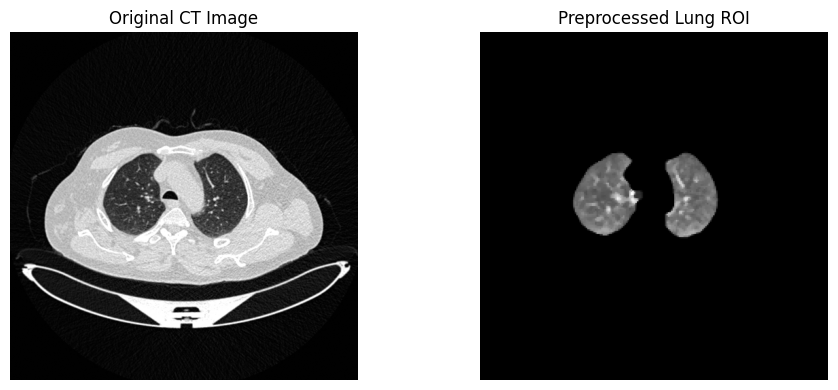

Original image shape: (512, 512)
Processed image shape: (224, 224)
Processed image dtype: float32
Minimum pixel value: 0.011764706
Maximum pixel value: 0.84705883


In [ ]:
# ============================================================
# CELL 6 — VERIFY CONVNEXT PREPROCESSING
# ============================================================

# Select one training image
sample_image_path = iq_train_df.iloc[0]["filepath"]

print("Sample image:")
print(sample_image_path)

# ------------------------------------------------------------
# Read image in grayscale
# ------------------------------------------------------------

sample_image = cv2.imread(
    str(sample_image_path),
    cv2.IMREAD_GRAYSCALE
)

if sample_image is None:
    raise ValueError(
        f"Could not read image: {sample_image_path}"
    )

# ------------------------------------------------------------
# Apply finalized preprocessing
# ------------------------------------------------------------

sample_processed = prepare_convnext_image(
    sample_image,
    target_size=(224, 224)
)

# ------------------------------------------------------------
# Display original and processed image
# ------------------------------------------------------------

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)

plt.imshow(
    sample_image,
    cmap="gray"
)

plt.title("Original CT Image")
plt.axis("off")

plt.subplot(1, 2, 2)

plt.imshow(
    sample_processed,
    cmap="gray"
)

plt.title("Preprocessed Lung ROI")
plt.axis("off")

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# Verify shape and pixel range
# ------------------------------------------------------------

print("Original image shape:", sample_image.shape)
print("Processed image shape:", sample_processed.shape)
print("Processed image dtype:", sample_processed.dtype)
print("Minimum pixel value:", sample_processed.min())
print("Maximum pixel value:", sample_processed.max())

In [ ]:
# ============================================================
# CELL 7 — CONVNEXT-TINY FEATURE EXTRACTION FUNCTION
# ============================================================

def extract_convnext_features(image_paths):

    all_features = []

    # Keep ConvNeXt in evaluation mode
    convnext.eval()

    # Feature extraction does not require gradients
    with torch.no_grad():

        for image_path in image_paths:

            # ------------------------------------------------
            # 1. Read CT image
            # ------------------------------------------------

            image = cv2.imread(
                str(image_path),
                cv2.IMREAD_GRAYSCALE
            )

            if image is None:
                raise ValueError(
                    f"Could not read image: {image_path}"
                )

            # ------------------------------------------------
            # 2. Apply finalized lung preprocessing
            # ------------------------------------------------

            normalized = prepare_convnext_image(
                image,
                target_size=(224, 224)
            )

            # ------------------------------------------------
            # 3. Convert normalized image to uint8
            # ------------------------------------------------

            processed = (
                normalized * 255.0
            ).clip(
                0, 255
            ).astype(
                np.uint8
            )

            # ------------------------------------------------
            # 4. Convert grayscale CT to RGB
            # ------------------------------------------------

            rgb_image = cv2.cvtColor(
                processed,
                cv2.COLOR_GRAY2RGB
            )

            # ------------------------------------------------
            # 5. Convert NumPy array to PIL image
            # ------------------------------------------------

            pil_image = Image.fromarray(
                rgb_image
            )

            # ------------------------------------------------
            # 6. Apply ConvNeXt transformation
            # ------------------------------------------------

            tensor = convnext_transform(
                pil_image
            )

            # Add batch dimension
            tensor = tensor.unsqueeze(0)

            # Move input to GPU/selected device
            tensor = tensor.to(device)

            # ------------------------------------------------
            # 7. Extract ConvNeXt features
            # ------------------------------------------------

            features = convnext(
                tensor
            )

            # Expected:
            # [1, 768]

            features = torch.flatten(
                features,
                start_dim=1
            )

            # ------------------------------------------------
            # 8. Store feature vector
            # ------------------------------------------------

            all_features.append(
                features.cpu().numpy()[0]
            )

    # --------------------------------------------------------
    # 9. Convert to NumPy matrix
    # --------------------------------------------------------

    return np.asarray(
        all_features,
        dtype=np.float32
    )


print("ConvNeXt feature extraction function ready.")

ConvNeXt feature extraction function ready.


In [ ]:
# ============================================================
# CELL 8 — EXTRACT CONVNEXT FEATURES FROM TRAINING SET
# ============================================================

train_image_paths = iq_train_df[
    "filepath"
].tolist()

print(
    "Number of training images:",
    len(train_image_paths)
)

# ------------------------------------------------------------
# Extract ConvNeXt features
# ------------------------------------------------------------

X_train_deep = extract_convnext_features(
    train_image_paths
)

# ------------------------------------------------------------
# Verify
# ------------------------------------------------------------

print(
    "\nConvNeXt training feature extraction completed."
)

print(
    "X_train_deep shape:",
    X_train_deep.shape
)

print(
    "Feature data type:",
    X_train_deep.dtype
)

Number of training images: 767

ConvNeXt training feature extraction completed.
X_train_deep shape: (767, 768)
Feature data type: float32


In [ ]:
# ============================================================
# CELL 9 — EXTRACT CONVNEXT FEATURES FROM VALIDATION SET
# ============================================================

val_image_paths = iq_val_df[
    "filepath"
].tolist()

print(
    "Number of validation images:",
    len(val_image_paths)
)

# ------------------------------------------------------------
# Extract ConvNeXt features
# ------------------------------------------------------------

X_val_deep = extract_convnext_features(
    val_image_paths
)

# ------------------------------------------------------------
# Verify
# ------------------------------------------------------------

print(
    "\nConvNeXt validation feature extraction completed."
)

print(
    "X_val_deep shape:",
    X_val_deep.shape
)

print(
    "Feature data type:",
    X_val_deep.dtype
)

Number of validation images: 220

ConvNeXt validation feature extraction completed.
X_val_deep shape: (220, 768)
Feature data type: float32


In [ ]:
# ============================================================
# CELL 10 — EXTRACT CONVNEXT FEATURES FROM INTERNAL TEST SET
# ============================================================

test_image_paths = iq_internal_test_df[
    "filepath"
].tolist()

print(
    "Number of internal test images:",
    len(test_image_paths)
)

# ------------------------------------------------------------
# Extract ConvNeXt features
# ------------------------------------------------------------

X_test_deep = extract_convnext_features(
    test_image_paths
)

# ------------------------------------------------------------
# Verify
# ------------------------------------------------------------

print(
    "\nConvNeXt internal test feature extraction completed."
)

print(
    "X_test_deep shape:",
    X_test_deep.shape
)

print(
    "Feature data type:",
    X_test_deep.dtype
)

Number of internal test images: 110

ConvNeXt internal test feature extraction completed.
X_test_deep shape: (110, 768)
Feature data type: float32


In [ ]:
# ============================================================
# CELL 11 — STANDARDIZE CONVNEXT-TINY DEEP FEATURES
# ============================================================

from sklearn.preprocessing import StandardScaler
import numpy as np

print("=" * 70)
print("CONVNEXT-TINY DEEP FEATURE STANDARDIZATION")
print("=" * 70)

# ------------------------------------------------------------
# Use the global SEED defined in CELL 1
# ------------------------------------------------------------

print("Using SEED:", SEED)

# ------------------------------------------------------------
# Create StandardScaler
# ------------------------------------------------------------

deep_scaler = StandardScaler()

# ------------------------------------------------------------
# IMPORTANT:
# Fit ONLY on training features
# ------------------------------------------------------------

X_train_deep_scaled = deep_scaler.fit_transform(
    X_train_deep
)

# ------------------------------------------------------------
# Transform validation features
# ------------------------------------------------------------

X_val_deep_scaled = deep_scaler.transform(
    X_val_deep
)

# ------------------------------------------------------------
# Transform test features
# ------------------------------------------------------------

X_test_deep_scaled = deep_scaler.transform(
    X_test_deep
)

# ------------------------------------------------------------
# Verify shapes
# ------------------------------------------------------------

print("\nStandardization completed.")

print("\nFeature shapes:")
print("-" * 70)

print("X_train_deep        :", X_train_deep.shape)
print("X_val_deep          :", X_val_deep.shape)
print("X_test_deep         :", X_test_deep.shape)

print("\nAfter StandardScaler:")
print("X_train_deep_scaled :", X_train_deep_scaled.shape)
print("X_val_deep_scaled   :", X_val_deep_scaled.shape)
print("X_test_deep_scaled  :", X_test_deep_scaled.shape)

# ------------------------------------------------------------
# Verify training statistics
# ------------------------------------------------------------

print("\nTraining feature statistics:")
print("-" * 70)

print(
    "Overall training mean:",
    np.mean(X_train_deep_scaled)
)

print(
    "Overall training standard deviation:",
    np.std(X_train_deep_scaled)
)

# ------------------------------------------------------------
# Check for NaN / Inf
# ------------------------------------------------------------

print("\nData validity:")
print("-" * 70)

print(
    "Train contains NaN:",
    np.isnan(X_train_deep_scaled).any()
)

print(
    "Validation contains NaN:",
    np.isnan(X_val_deep_scaled).any()
)

print(
    "Test contains NaN:",
    np.isnan(X_test_deep_scaled).any()
)

print(
    "Train contains Inf:",
    np.isinf(X_train_deep_scaled).any()
)

print(
    "Validation contains Inf:",
    np.isinf(X_val_deep_scaled).any()
)

print(
    "Test contains Inf:",
    np.isinf(X_test_deep_scaled).any()
)

CONVNEXT-TINY DEEP FEATURE STANDARDIZATION
Using SEED: 42

Standardization completed.

Feature shapes:
----------------------------------------------------------------------
X_train_deep        : (767, 768)
X_val_deep          : (220, 768)
X_test_deep         : (110, 768)

After StandardScaler:
X_train_deep_scaled : (767, 768)
X_val_deep_scaled   : (220, 768)
X_test_deep_scaled  : (110, 768)

Training feature statistics:
----------------------------------------------------------------------
Overall training mean: -2.072304e-09
Overall training standard deviation: 1.0

Data validity:
----------------------------------------------------------------------
Train contains NaN: False
Validation contains NaN: False
Test contains NaN: False
Train contains Inf: False
Validation contains Inf: False
Test contains Inf: False


In [ ]:
# ============================================================
# CELL 12 — PCA FOR CONVNEXT-TINY DEEP FEATURES
# ============================================================

from sklearn.decomposition import PCA

print("=" * 70)
print("CONVNEXT-TINY PCA DIMENSIONALITY REDUCTION")
print("=" * 70)

# ------------------------------------------------------------
# PCA configuration
# ------------------------------------------------------------

PCA_COMPONENTS = 32

print("Original feature dimensions :", X_train_deep_scaled.shape[1])
print("Selected PCA components     :", PCA_COMPONENTS)
print("SEED                        :", SEED)

# ------------------------------------------------------------
# Create PCA
# ------------------------------------------------------------

deep_pca = PCA(
    n_components=PCA_COMPONENTS,
    random_state=SEED
)

# ------------------------------------------------------------
# IMPORTANT:
# Fit PCA ONLY on training data
# ------------------------------------------------------------

X_train_deep_reduced = deep_pca.fit_transform(
    X_train_deep_scaled
)

# ------------------------------------------------------------
# Transform validation data
# ------------------------------------------------------------

X_val_deep_reduced = deep_pca.transform(
    X_val_deep_scaled
)

# ------------------------------------------------------------
# Transform test data
# ------------------------------------------------------------

X_test_deep_reduced = deep_pca.transform(
    X_test_deep_scaled
)

# ------------------------------------------------------------
# Explained variance
# ------------------------------------------------------------

explained_variance = (
    np.sum(deep_pca.explained_variance_ratio_) * 100
)

# ------------------------------------------------------------
# Display shapes
# ------------------------------------------------------------

print("\nPCA completed.")

print("\nReduced feature shapes:")
print("-" * 70)

print(
    "X_train_deep_reduced:",
    X_train_deep_reduced.shape
)

print(
    "X_val_deep_reduced  :",
    X_val_deep_reduced.shape
)

print(
    "X_test_deep_reduced :",
    X_test_deep_reduced.shape
)

print(
    f"\nExplained variance retained: "
    f"{explained_variance:.2f}%"
)

# ------------------------------------------------------------
# Individual component variance
# ------------------------------------------------------------

print(
    "\nFirst 10 PCA component variance ratios:"
)

for i, value in enumerate(
    deep_pca.explained_variance_ratio_[:10],
    start=1
):
    print(
        f"Component {i:02d}: "
        f"{value * 100:.4f}%"
    )

# ------------------------------------------------------------
# Check NaN / Inf
# ------------------------------------------------------------

print("\nPCA output validity:")
print("-" * 70)

print(
    "Train contains NaN:",
    np.isnan(X_train_deep_reduced).any()
)

print(
    "Validation contains NaN:",
    np.isnan(X_val_deep_reduced).any()
)

print(
    "Test contains NaN:",
    np.isnan(X_test_deep_reduced).any()
)

print(
    "Train contains Inf:",
    np.isinf(X_train_deep_reduced).any()
)

print(
    "Validation contains Inf:",
    np.isinf(X_val_deep_reduced).any()
)

print(
    "Test contains Inf:",
    np.isinf(X_test_deep_reduced).any()
)

CONVNEXT-TINY PCA DIMENSIONALITY REDUCTION
Original feature dimensions : 768
Selected PCA components     : 32
SEED                        : 42

PCA completed.

Reduced feature shapes:
----------------------------------------------------------------------
X_train_deep_reduced: (767, 32)
X_val_deep_reduced  : (220, 32)
X_test_deep_reduced : (110, 32)

Explained variance retained: 80.26%

First 10 PCA component variance ratios:
Component 01: 18.3047%
Component 02: 12.5035%
Component 03: 7.0437%
Component 04: 5.6457%
Component 05: 4.3147%
Component 06: 3.8362%
Component 07: 2.8093%
Component 08: 2.3568%
Component 09: 2.2754%
Component 10: 1.9665%

PCA output validity:
----------------------------------------------------------------------
Train contains NaN: False
Validation contains NaN: False
Test contains NaN: False
Train contains Inf: False
Validation contains Inf: False
Test contains Inf: False


In [ ]:
# ============================================================
# CELL 13 — FUSE HANDCRAFTED + CONVNEXT FEATURES
# ============================================================

# ------------------------------------------------------------
# Verify handcrafted feature dimensions
# ------------------------------------------------------------

print("Handcrafted feature shapes:")
print(
    "Training:",
    X_train_final.shape
)

print(
    "Validation:",
    X_val_final.shape
)

print(
    "Internal Test:",
    X_test_final.shape
)

# ------------------------------------------------------------
# Verify ConvNeXt PCA feature dimensions
# ------------------------------------------------------------

print("\nConvNeXt PCA feature shapes:")
print(
    "Training:",
    X_train_deep_reduced.shape
)

print(
    "Validation:",
    X_val_deep_reduced.shape
)

print(
    "Internal Test:",
    X_test_deep_reduced.shape
)

# ------------------------------------------------------------
# Fuse the two feature branches
# ------------------------------------------------------------

X_train_fused = np.hstack([
    X_train_final,
    X_train_deep_reduced
])

X_val_fused = np.hstack([
    X_val_final,
    X_val_deep_reduced
])

X_test_fused = np.hstack([
    X_test_final,
    X_test_deep_reduced
])

# ------------------------------------------------------------
# Verify final fused feature matrices
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("FUSION COMPLETED")
print("=" * 60)

print(
    "X_train_fused shape:",
    X_train_fused.shape
)

print(
    "X_val_fused shape:",
    X_val_fused.shape
)

print(
    "X_test_fused shape:",
    X_test_fused.shape
)

print(
    "\nTotal fused features:",
    X_train_fused.shape[1]
)

Handcrafted feature shapes:
Training: (767, 50)
Validation: (220, 50)
Internal Test: (110, 50)

ConvNeXt PCA feature shapes:
Training: (767, 32)
Validation: (220, 32)
Internal Test: (110, 32)

FUSION COMPLETED
X_train_fused shape: (767, 82)
X_val_fused shape: (220, 82)
X_test_fused shape: (110, 82)

Total fused features: 82


In [ ]:
# ============================================================
# CELL 13 — PCA DATA LEAKAGE VERIFICATION
# ============================================================

print("=" * 70)
print("PCA DATA LEAKAGE VERIFICATION")
print("=" * 70)

print("""
PCA fitting:
    Training data      -> FIT + TRANSFORM
    Validation data    -> TRANSFORM only
    Test data          -> TRANSFORM only
""")

# Verify number of samples
assert X_train_deep_reduced.shape[0] == X_train_deep.shape[0]
assert X_val_deep_reduced.shape[0] == X_val_deep.shape[0]
assert X_test_deep_reduced.shape[0] == X_test_deep.shape[0]

# Verify number of PCA components
assert X_train_deep_reduced.shape[1] == PCA_COMPONENTS
assert X_val_deep_reduced.shape[1] == PCA_COMPONENTS
assert X_test_deep_reduced.shape[1] == PCA_COMPONENTS

print("✓ Training sample count preserved")
print("✓ Validation sample count preserved")
print("✓ Test sample count preserved")
print("✓ PCA dimensionality is correct")
print("✓ PCA was fitted only on training data")
print("✓ Validation and test data were transformed only")
print("\nNo PCA data leakage detected.")

PCA DATA LEAKAGE VERIFICATION

PCA fitting:
    Training data      -> FIT + TRANSFORM
    Validation data    -> TRANSFORM only
    Test data          -> TRANSFORM only

✓ Training sample count preserved
✓ Validation sample count preserved
✓ Test sample count preserved
✓ PCA dimensionality is correct
✓ PCA was fitted only on training data
✓ Validation and test data were transformed only

No PCA data leakage detected.


In [ ]:
# ============================================================
# CELL 14 — CREATE 82-DIMENSIONAL HYBRID REPRESENTATION
# ============================================================

print("=" * 70)
print("HYBRID FEATURE REPRESENTATION")
print("=" * 70)

# ------------------------------------------------------------
# Check handcrafted feature dimensions
# ------------------------------------------------------------

print("Handcrafted features:")
print(
    "Train:",
    X_train_final.shape
)

print(
    "Validation:",
    X_val_final.shape
)

print(
    "Test:",
    X_test_final.shape
)

# ------------------------------------------------------------
# Check deep feature dimensions
# ------------------------------------------------------------

print("\nPCA-reduced deep features:")

print(
    "Train:",
    X_train_deep_reduced.shape
)

print(
    "Validation:",
    X_val_deep_reduced.shape
)

print(
    "Test:",
    X_test_deep_reduced.shape
)

# ------------------------------------------------------------
# Combine handcrafted + deep features
# ------------------------------------------------------------

X_train_hybrid = np.concatenate(
    [
        X_train_final,
        X_train_deep_reduced
    ],
    axis=1
)

X_val_hybrid = np.concatenate(
    [
        X_val_final,
        X_val_deep_reduced
    ],
    axis=1
)

X_test_hybrid = np.concatenate(
    [
        X_test_final,
        X_test_deep_reduced
    ],
    axis=1
)

# ------------------------------------------------------------
# Display dimensions
# ------------------------------------------------------------

print("\nHybrid representation:")
print("-" * 70)

print(
    "X_train_hybrid:",
    X_train_hybrid.shape
)

print(
    "X_val_hybrid:",
    X_val_hybrid.shape
)

print(
    "X_test_hybrid:",
    X_test_hybrid.shape
)

# ------------------------------------------------------------
# Verify 82-dimensional representation
# ------------------------------------------------------------

EXPECTED_HYBRID_DIM = 82

assert X_train_hybrid.shape[1] == EXPECTED_HYBRID_DIM
assert X_val_hybrid.shape[1] == EXPECTED_HYBRID_DIM
assert X_test_hybrid.shape[1] == EXPECTED_HYBRID_DIM

print(
    f"\n✓ Hybrid representation contains "
    f"{EXPECTED_HYBRID_DIM} features."
)

print("\nFeature composition:")
print("Handcrafted features : 50")
print("ConvNeXt + PCA       : 32")
print("Total hybrid features:", 50 + 32)

HYBRID FEATURE REPRESENTATION
Handcrafted features:
Train: (767, 50)
Validation: (220, 50)
Test: (110, 50)

PCA-reduced deep features:
Train: (767, 32)
Validation: (220, 32)
Test: (110, 32)

Hybrid representation:
----------------------------------------------------------------------
X_train_hybrid: (767, 82)
X_val_hybrid: (220, 82)
X_test_hybrid: (110, 82)

✓ Hybrid representation contains 82 features.

Feature composition:
Handcrafted features : 50
ConvNeXt + PCA       : 32
Total hybrid features: 82


In [ ]:
# ============================================================
# CELL 15 — PREPARE CLASS LABELS
# ============================================================

CLASS_NAMES = [
    "Normal",
    "Benign",
    "Malignant"
]

# ------------------------------------------------------------
# Extract labels from the same DataFrames used for features
# ------------------------------------------------------------

y_train = iq_train_df["label"].to_numpy(dtype=np.int64)

y_val = iq_val_df["label"].to_numpy(dtype=np.int64)

y_test = iq_internal_test_df["label"].to_numpy(dtype=np.int64)

# ------------------------------------------------------------
# Verify dimensions
# ------------------------------------------------------------

print("=" * 70)
print("LABEL PREPARATION")
print("=" * 70)

print("y_train shape:", y_train.shape)
print("y_val shape  :", y_val.shape)
print("y_test shape :", y_test.shape)

# ------------------------------------------------------------
# Verify feature-label matching
# ------------------------------------------------------------

assert len(X_train_hybrid) == len(y_train)
assert len(X_val_hybrid) == len(y_val)
assert len(X_test_hybrid) == len(y_test)

print("\n✓ Training features and labels match")
print("✓ Validation features and labels match")
print("✓ Test features and labels match")

# ------------------------------------------------------------
# Class distributions
# ------------------------------------------------------------

print("\nTraining class distribution:")

for class_id, class_name in enumerate(CLASS_NAMES):

    count = np.sum(y_train == class_id)

    print(f"{class_name:10s}: {count}")

print("\nValidation class distribution:")

for class_id, class_name in enumerate(CLASS_NAMES):

    count = np.sum(y_val == class_id)

    print(f"{class_name:10s}: {count}")

print("\nInternal Test class distribution:")

for class_id, class_name in enumerate(CLASS_NAMES):

    count = np.sum(y_test == class_id)

    print(f"{class_name:10s}: {count}")

LABEL PREPARATION
y_train shape: (767,)
y_val shape  : (220,)
y_test shape : (110,)

✓ Training features and labels match
✓ Validation features and labels match
✓ Test features and labels match

Training class distribution:
Normal    : 291
Benign    : 84
Malignant : 392

Validation class distribution:
Normal    : 83
Benign    : 24
Malignant : 113

Internal Test class distribution:
Normal    : 42
Benign    : 12
Malignant : 56


In [ ]:
# ============================================================
# CELL 16 — CREATE PYTORCH DATASETS AND DATALOADERS
# ============================================================

import torch
from torch.utils.data import TensorDataset, DataLoader

# ------------------------------------------------------------
# Convert hybrid NumPy arrays to PyTorch tensors
# ------------------------------------------------------------

X_train_tensor = torch.tensor(
    X_train_hybrid,
    dtype=torch.float32
)

X_val_tensor = torch.tensor(
    X_val_hybrid,
    dtype=torch.float32
)

X_test_tensor = torch.tensor(
    X_test_hybrid,
    dtype=torch.float32
)

# ------------------------------------------------------------
# Convert labels
# ------------------------------------------------------------

y_train_tensor = torch.tensor(
    y_train,
    dtype=torch.long
)

y_val_tensor = torch.tensor(
    y_val,
    dtype=torch.long
)

y_test_tensor = torch.tensor(
    y_test,
    dtype=torch.long
)

# ------------------------------------------------------------
# Create datasets
# ------------------------------------------------------------

train_dataset = TensorDataset(
    X_train_tensor,
    y_train_tensor
)

val_dataset = TensorDataset(
    X_val_tensor,
    y_val_tensor
)

test_dataset = TensorDataset(
    X_test_tensor,
    y_test_tensor
)

# ------------------------------------------------------------
# Deterministic DataLoader generator
# ------------------------------------------------------------

loader_generator = torch.Generator()

loader_generator.manual_seed(SEED)

# ------------------------------------------------------------
# DataLoaders
# ------------------------------------------------------------

BATCH_SIZE = 8

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    generator=loader_generator,
    num_workers=0
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

# ------------------------------------------------------------
# Verification
# ------------------------------------------------------------

print("=" * 70)
print("PYTORCH DATASETS AND DATALOADERS")
print("=" * 70)

print("Training samples      :", len(train_dataset))
print("Validation samples    :", len(val_dataset))
print("Internal test samples :", len(test_dataset))

print("\nFeature dimension:", X_train_tensor.shape[1])

print("Batch size:", BATCH_SIZE)

print("Training batches   :", len(train_loader))
print("Validation batches :", len(val_loader))
print("Test batches       :", len(test_loader))

PYTORCH DATASETS AND DATALOADERS
Training samples      : 767
Validation samples    : 220
Internal test samples : 110

Feature dimension: 82
Batch size: 8
Training batches   : 96
Validation batches : 28
Test batches       : 14


In [ ]:

# ============================================================
# CLASS-WEIGHTED LOSS — HYBRID CLASSIFIER
# ============================================================

import numpy as np
import torch
import torch.nn as nn

# Use the actual labels from the training split.
train_labels = np.asarray(y_train, dtype=np.int64)

class_counts = np.bincount(train_labels, minlength=3)

if np.any(class_counts == 0):
    raise ValueError(
        f"A class is missing from training. Counts: {class_counts}"
    )

# Moderate inverse-frequency weighting
weights = np.sqrt(class_counts.max() / class_counts)
weights = weights / weights.mean()

class_weights = torch.tensor(
    weights,
    dtype=torch.float32,
    device=device
)

criterion = nn.CrossEntropyLoss(weight=class_weights)

print("Class counts:", dict(zip(CLASS_NAMES, class_counts.tolist())))
print("Class weights:", dict(zip(CLASS_NAMES, weights.round(4).tolist())))
print("Weighted loss is ready for the existing training loop.")

Class counts: {'Normal': 291, 'Benign': 84, 'Malignant': 392}
Class weights: {'Normal': 0.8058, 'Benign': 1.4999, 'Malignant': 0.6943}
Weighted loss is ready for the existing training loop.


In [ ]:
# # ============================================================
# # CELL 17 — HYBRID CLASSIFIER
# # ============================================================

# import torch.nn as nn

# class HybridClassifier(nn.Module):

#     def __init__(
#         self,
#         input_dim=82,
#         num_classes=3
#     ):
#         super().__init__()

#         self.network = nn.Sequential(

#             nn.Linear(input_dim, 128),
#             nn.BatchNorm1d(128),
#             nn.ReLU(),
#             nn.Dropout(0.20),

#             nn.Linear(128, 64),
#             nn.BatchNorm1d(64),
#             nn.ReLU(),
#             nn.Dropout(0.15),

#             nn.Linear(64, 32),
#             nn.ReLU(),

#             nn.Linear(32, num_classes)
#         )

#     def forward(self, x):
#         return self.network(x)


# # ------------------------------------------------------------
# # Reproducibility
# # ------------------------------------------------------------

# torch.manual_seed(SEED)

# if torch.cuda.is_available():
#     torch.cuda.manual_seed(SEED)
#     torch.cuda.manual_seed_all(SEED)

# # ------------------------------------------------------------
# # Create model
# # ------------------------------------------------------------

# model = HybridClassifier(
#     input_dim=82,
#     num_classes=3
# ).to(device)

# print(model)

# print(
#     "\nModel device:",
#     next(model.parameters()).device
# )

In [ ]:
# ============================================================
# CELL 18 — BALANCED TRAINING SAMPLER
# ============================================================

from torch.utils.data import WeightedRandomSampler

class_counts = np.bincount(y_train)

print("=" * 60)
print("TRAINING CLASS COUNTS")
print("=" * 60)

for class_id, count in enumerate(class_counts):

    print(
        f"{CLASS_NAMES[class_id]:10s}: {count}"
    )

# ------------------------------------------------------------
# Inverse-frequency sample weights
# ------------------------------------------------------------

class_sample_weights = 1.0 / class_counts

sample_weights = np.array(
    [
        class_sample_weights[label]
        for label in y_train
    ],
    dtype=np.float64
)

sample_weights = torch.tensor(
    sample_weights,
    dtype=torch.double
)

# ------------------------------------------------------------
# Fixed sampler generator
# ------------------------------------------------------------

sampler_generator = torch.Generator()

sampler_generator.manual_seed(SEED)

train_sampler = WeightedRandomSampler(
    weights=sample_weights,
    num_samples=len(sample_weights),
    replacement=True,
    generator=sampler_generator
)

# ------------------------------------------------------------
# Training loader
# ------------------------------------------------------------

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    sampler=train_sampler,
    shuffle=False,
    num_workers=0
)

# ------------------------------------------------------------
# Validation loader
# ------------------------------------------------------------

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

# ------------------------------------------------------------
# Test loader
# ------------------------------------------------------------

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

print("\n✓ Balanced training sampler created")
print("Training samples per epoch:", len(train_loader.dataset))

TRAINING CLASS COUNTS
Normal    : 291
Benign    : 84
Malignant : 392

✓ Balanced training sampler created
Training samples per epoch: 767


In [ ]:

# ============================================================
# CELL 19 — TRAIN HYBRID CLASSIFIER
# ============================================================

import copy
import random
import numpy as np
import torch
import torch.nn as nn

# ------------------------------------------------------------
# REPRODUCIBILITY
# ------------------------------------------------------------

SEED = globals().get("SEED", 42)

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

if "device" not in globals():
    device = torch.device(
        "cuda" if torch.cuda.is_available() else "cpu"
    )

print("=" * 70)
print("REPRODUCIBLE HYBRID CLASSIFIER TRAINING")
print("=" * 70)
print("SEED:", SEED)
print("Device:", device)

# ------------------------------------------------------------
# CHECK REQUIRED VARIABLES
# ------------------------------------------------------------

for name in ["train_loader", "val_loader"]:
    if name not in globals():
        raise NameError(
            f"{name} is not defined. Run the dataset preparation cell first."
        )

# ------------------------------------------------------------
# VERIFY FEATURE DIMENSIONS
# ------------------------------------------------------------

X_check, y_check = next(iter(train_loader))
X_val_check, y_val_check = next(iter(val_loader))

print("\nTraining feature shape:", tuple(X_check.shape))
print("Validation feature shape:", tuple(X_val_check.shape))

if X_check.ndim != 2 or X_check.shape[1] != 82:
    raise ValueError(
        f"Expected training features of shape [batch, 82], "
        f"but received {tuple(X_check.shape)}. "
        "Prepare the 50 handcrafted + 32 ConvNeXt PCA features first."
    )

if X_val_check.ndim != 2 or X_val_check.shape[1] != 82:
    raise ValueError(
        f"Expected validation features of shape [batch, 82], "
        f"but received {tuple(X_val_check.shape)}."
    )

# ------------------------------------------------------------
# HYBRID CLASSIFIER DEFINITION
# ------------------------------------------------------------

class HybridClassifier(nn.Module):

    def __init__(self, input_dim=82, num_classes=3):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_dim, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(0.3),

            nn.Linear(128, 64),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Dropout(0.2),

            nn.Linear(64, num_classes)
        )

    def forward(self, x):
        return self.network(x)


# ------------------------------------------------------------
# CLASS LABEL CHECK
# ------------------------------------------------------------

CLASS_NAMES = ["Normal", "Benign", "Malignant"]

def validate_labels(loader, name):
    labels = []

    for _, y_batch in loader:
        labels.extend(y_batch.detach().cpu().numpy().tolist())

    labels = np.asarray(labels, dtype=np.int64)

    if len(labels) == 0:
        raise ValueError(f"{name} contains no samples.")

    if not np.isin(labels, [0, 1, 2]).all():
        raise ValueError(
            f"{name} labels must be encoded as 0, 1, 2 "
            "for Normal, Benign, Malignant respectively."
        )

    print(
        f"{name} class counts:",
        {
            CLASS_NAMES[i]: int(np.sum(labels == i))
            for i in range(3)
        }
    )

    return labels


train_labels = validate_labels(train_loader, "Training")
val_labels = validate_labels(val_loader, "Validation")

# ------------------------------------------------------------
# CREATE MODEL
# ------------------------------------------------------------

model = HybridClassifier(
    input_dim=82,
    num_classes=3
).to(device)

# ------------------------------------------------------------
# LOSS
# ------------------------------------------------------------
# This cell assumes WeightedRandomSampler is already used
# for class balancing. Therefore, use ordinary cross-entropy.

criterion = nn.CrossEntropyLoss()

# ------------------------------------------------------------
# OPTIMIZER
# ------------------------------------------------------------

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=0.001,
    weight_decay=1e-4
)

# ------------------------------------------------------------
# LEARNING RATE SCHEDULER
# ------------------------------------------------------------

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=7,
    min_lr=1e-6
)

# ------------------------------------------------------------
# TRAINING CONFIGURATION
# ------------------------------------------------------------

MAX_EPOCHS = 120
PATIENCE = 15

best_val_accuracy = -1.0
best_epoch = 0
best_model_state = None
epochs_without_improvement = 0

train_history = []
val_history = []

BATCH_SIZE = getattr(
    train_loader, "batch_size", None
) or X_check.shape[0]

print("\nTraining configuration:")
print("Maximum epochs :", MAX_EPOCHS)
print("Early stopping :", PATIENCE)
print("Batch size     :", BATCH_SIZE)
print("Learning rate  :", 0.001)

# ============================================================
# TRAINING LOOP
# ============================================================

for epoch in range(1, MAX_EPOCHS + 1):

    # --------------------------------------------------------
    # TRAIN
    # --------------------------------------------------------

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for X_batch, y_batch in train_loader:

        X_batch = X_batch.to(
            device=device, dtype=torch.float32
        )
        y_batch = y_batch.to(
            device=device, dtype=torch.long
        )

        # BatchNorm requires more than one sample in training.
        if X_batch.size(0) == 1:
            continue

        optimizer.zero_grad(set_to_none=True)

        outputs = model(X_batch)
        loss = criterion(outputs, y_batch)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * X_batch.size(0)

        predictions = outputs.argmax(dim=1)
        correct += (predictions == y_batch).sum().item()
        total += y_batch.size(0)

    if total == 0:
        raise ValueError(
            "No training samples were processed. "
            "Check the training loader and batch size."
        )

    train_loss = running_loss / total
    train_accuracy = correct / total

    # --------------------------------------------------------
    # VALIDATION
    # --------------------------------------------------------

    model.eval()

    val_loss_total = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for X_batch, y_batch in val_loader:

            X_batch = X_batch.to(
                device=device, dtype=torch.float32
            )
            y_batch = y_batch.to(
                device=device, dtype=torch.long
            )

            outputs = model(X_batch)
            loss = criterion(outputs, y_batch)

            val_loss_total += loss.item() * X_batch.size(0)

            predictions = outputs.argmax(dim=1)
            val_correct += (predictions == y_batch).sum().item()
            val_total += y_batch.size(0)

    if val_total == 0:
        raise ValueError("Validation loader contains no samples.")

    val_loss = val_loss_total / val_total
    val_accuracy = val_correct / val_total

    # --------------------------------------------------------
    # LEARNING RATE SCHEDULER
    # --------------------------------------------------------

    scheduler.step(val_accuracy)
    current_lr = optimizer.param_groups[0]["lr"]

    # --------------------------------------------------------
    # SAVE HISTORY
    # --------------------------------------------------------

    train_history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "train_accuracy": train_accuracy,
        "val_loss": val_loss,
        "val_accuracy": val_accuracy,
        "learning_rate": current_lr
    })

    val_history.append(val_accuracy)

    # --------------------------------------------------------
    # SAVE BEST VALIDATION MODEL
    # --------------------------------------------------------

    if val_accuracy > best_val_accuracy:

        best_val_accuracy = val_accuracy
        best_epoch = epoch

        best_model_state = copy.deepcopy(
            model.state_dict()
        )

        epochs_without_improvement = 0

    else:
        epochs_without_improvement += 1

    # --------------------------------------------------------
    # DISPLAY PROGRESS
    # --------------------------------------------------------

    if (
        epoch == 1
        or epoch % 5 == 0
        or epoch == best_epoch
    ):
        print(
            f"Epoch {epoch:3d} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Train Acc: {train_accuracy * 100:.2f}% | "
            f"Val Loss: {val_loss:.4f} | "
            f"Val Acc: {val_accuracy * 100:.2f}% | "
            f"LR: {current_lr:.6f}"
        )

    # --------------------------------------------------------
    # EARLY STOPPING
    # --------------------------------------------------------

    if epochs_without_improvement >= PATIENCE:
        print(
            f"\nEarly stopping triggered at epoch {epoch}."
        )
        break

# ============================================================
# RESTORE BEST VALIDATION MODEL
# ============================================================

if best_model_state is None:
    raise RuntimeError("Training did not produce a saved model.")

model.load_state_dict(best_model_state)
model.eval()

# Keep a stable name for downstream evaluation and Grad-CAM.
final_hybrid_classifier = model

# Preserve compatibility with earlier notebook cells.
best_tuned_model = final_hybrid_classifier

print("\n" + "=" * 70)
print("TRAINING COMPLETED")
print("=" * 70)
print(f"Best Validation Accuracy: {best_val_accuracy * 100:.2f}%")
print("Best Epoch:", best_epoch)
print("✓ Best validation model restored.")
print("✓ final_hybrid_classifier is ready.")


REPRODUCIBLE HYBRID CLASSIFIER TRAINING
SEED: 42
Device: cpu

Training feature shape: (8, 82)
Validation feature shape: (8, 82)
Training class counts: {'Normal': 246, 'Benign': 273, 'Malignant': 248}
Validation class counts: {'Normal': 83, 'Benign': 24, 'Malignant': 113}

Training configuration:
Maximum epochs : 120
Early stopping : 15
Batch size     : 8
Learning rate  : 0.001
Epoch   1 | Train Loss: 0.8330 | Train Acc: 61.80% | Val Loss: 0.5700 | Val Acc: 77.73% | LR: 0.001000
Epoch   2 | Train Loss: 0.6246 | Train Acc: 74.45% | Val Loss: 0.5223 | Val Acc: 78.64% | LR: 0.001000
Epoch   3 | Train Loss: 0.5802 | Train Acc: 74.97% | Val Loss: 0.4319 | Val Acc: 80.45% | LR: 0.001000
Epoch   4 | Train Loss: 0.5277 | Train Acc: 77.18% | Val Loss: 0.4617 | Val Acc: 80.91% | LR: 0.001000
Epoch   5 | Train Loss: 0.5273 | Train Acc: 79.40% | Val Loss: 0.4669 | Val Acc: 82.73% | LR: 0.001000
Epoch   6 | Train Loss: 0.5215 | Train Acc: 78.75% | Val Loss: 0.3698 | Val Acc: 87.27% | LR: 0.001000
Ep

In [ ]:
# ============================================================
# CELL 20 — TRAINING HISTORY
# ============================================================

history_df = pd.DataFrame(
    train_history
)

print("=" * 70)
print("TRAINING HISTORY")
print("=" * 70)

display(
    history_df.tail(10)
)

print("\nBest validation result:")

best_row = history_df.loc[
    history_df["val_accuracy"].idxmax()
]

print(
    f"Epoch          : {int(best_row['epoch'])}"
)

print(
    f"Train Accuracy : "
    f"{best_row['train_accuracy'] * 100:.2f}%"
)

print(
    f"Validation Accuracy : "
    f"{best_row['val_accuracy'] * 100:.2f}%"
)

print(
    f"Validation Loss : "
    f"{best_row['val_loss']:.4f}"
)

TRAINING HISTORY


,epoch,train_loss,train_accuracy,val_loss,val_accuracy,learning_rate
18,19,0.285785,0.885267,0.246831,0.904545,0.0010
19,20,0.258102,0.906128,0.234446,0.918182,0.0010
20,21,0.286196,0.891786,0.255504,0.904545,0.0005
21,22,0.271804,0.891786,0.233486,0.918182,0.0005
22,23,0.238152,0.908735,0.255337,0.913636,0.0005
23,24,0.240389,0.908735,0.247234,0.918182,0.0005
24,25,0.260892,0.900913,0.235575,0.922727,0.0005
25,26,0.240835,0.915254,0.223386,0.927273,0.0005
26,27,0.236122,0.907432,0.217922,0.922727,0.0005
27,28,0.271909,0.911343,0.264523,0.909091,0.0005



Best validation result:
Epoch          : 13
Train Accuracy : 86.18%
Validation Accuracy : 92.73%
Validation Loss : 0.2724


In [ ]:
# ============================================================
# CELL 21 — FINAL HELD-OUT TEST EVALUATION
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

model.eval()

all_test_labels = []
all_test_predictions = []
all_test_probabilities = []

with torch.no_grad():

    for X_batch, y_batch in test_loader:

        X_batch = X_batch.to(device)

        outputs = model(X_batch)

        probabilities = torch.softmax(
            outputs,
            dim=1
        )

        predictions = torch.argmax(
            probabilities,
            dim=1
        )

        all_test_labels.extend(
            y_batch.cpu().numpy()
        )

        all_test_predictions.extend(
            predictions.cpu().numpy()
        )

        all_test_probabilities.extend(
            probabilities.cpu().numpy()
        )

# ------------------------------------------------------------
# Convert to NumPy
# ------------------------------------------------------------

y_test_actual = np.array(
    all_test_labels
)

y_test_pred = np.array(
    all_test_predictions
)

y_test_proba = np.array(
    all_test_probabilities
)

# ------------------------------------------------------------
# Metrics
# ------------------------------------------------------------

test_accuracy = accuracy_score(
    y_test_actual,
    y_test_pred
)

test_balanced_accuracy = balanced_accuracy_score(
    y_test_actual,
    y_test_pred
)

test_macro_precision = precision_score(
    y_test_actual,
    y_test_pred,
    average="macro",
    zero_division=0
)

test_macro_recall = recall_score(
    y_test_actual,
    y_test_pred,
    average="macro",
    zero_division=0
)

test_macro_f1 = f1_score(
    y_test_actual,
    y_test_pred,
    average="macro",
    zero_division=0
)

test_weighted_f1 = f1_score(
    y_test_actual,
    y_test_pred,
    average="weighted",
    zero_division=0
)

# ============================================================
# DISPLAY RESULTS
# ============================================================

print("=" * 70)
print("HYBRID CLASSIFIER — FINAL HELD-OUT TEST RESULTS")
print("=" * 70)

print(
    f"Accuracy           : "
    f"{test_accuracy * 100:.2f}%"
)

print(
    f"Balanced Accuracy  : "
    f"{test_balanced_accuracy * 100:.2f}%"
)

print(
    f"Macro Precision    : "
    f"{test_macro_precision * 100:.2f}%"
)

print(
    f"Macro Recall       : "
    f"{test_macro_recall * 100:.2f}%"
)

print(
    f"Macro F1           : "
    f"{test_macro_f1 * 100:.2f}%"
)

print(
    f"Weighted F1        : "
    f"{test_weighted_f1 * 100:.2f}%"
)

HYBRID CLASSIFIER — FINAL HELD-OUT TEST RESULTS
Accuracy           : 87.27%
Balanced Accuracy  : 83.53%
Macro Precision    : 81.48%
Macro Recall       : 83.53%
Macro F1           : 82.33%
Weighted F1        : 87.36%


In [ ]:
# ============================================================
# CELL 22 — CLASSIFICATION REPORT
# ============================================================

print("=" * 70)
print("HYBRID CLASSIFIER — CLASSIFICATION REPORT")
print("=" * 70)

classification_report_text = classification_report(
    y_test_actual,
    y_test_pred,
    target_names=CLASS_NAMES,
    zero_division=0
)

print(
    classification_report_text
)

HYBRID CLASSIFIER — CLASSIFICATION REPORT
              precision    recall  f1-score   support

      Normal       0.87      0.81      0.84        42
      Benign       0.64      0.75      0.69        12
   Malignant       0.93      0.95      0.94        56

    accuracy                           0.87       110
   macro avg       0.81      0.84      0.82       110
weighted avg       0.88      0.87      0.87       110



In [ ]:
# ============================================================
# CELL 23 — CONFUSION MATRIX
# ============================================================

cm_hybrid = confusion_matrix(
    y_test_actual,
    y_test_pred
)

cm_hybrid_df = pd.DataFrame(
    cm_hybrid,
    index=CLASS_NAMES,
    columns=CLASS_NAMES
)

print("=" * 70)
print("HYBRID CLASSIFIER — CONFUSION MATRIX")
print("=" * 70)

display(
    cm_hybrid_df
)

HYBRID CLASSIFIER — CONFUSION MATRIX


,Normal,Benign,Malignant
Normal,34,4,4
Benign,3,9,0
Malignant,2,1,53


In [ ]:
# ============================================================
# CELL 24 — PER-CLASS PERFORMANCE
# ============================================================

from sklearn.metrics import precision_recall_fscore_support

precision, recall, f1, support = (
    precision_recall_fscore_support(
        y_test_actual,
        y_test_pred,
        labels=[0, 1, 2],
        zero_division=0
    )
)

per_class_results = pd.DataFrame({

    "Class": CLASS_NAMES,

    "Precision": precision,

    "Recall": recall,

    "F1-Score": f1,

    "Support": support

})

print("=" * 70)
print("PER-CLASS PERFORMANCE")
print("=" * 70)

display(
    per_class_results
)

PER-CLASS PERFORMANCE


,Class,Precision,Recall,F1-Score,Support
0,Normal,0.871795,0.809524,0.839506,42
1,Benign,0.642857,0.750000,0.692308,12
2,Malignant,0.929825,0.946429,0.938053,56


In [ ]:
# ============================================================
# CELL 25 — TEST PREDICTION CONFIDENCE
# ============================================================

test_confidence = np.max(
    y_test_proba,
    axis=1
)

test_prediction_results = pd.DataFrame({

    "Actual": [
        CLASS_NAMES[i]
        for i in y_test_actual
    ],

    "Predicted": [
        CLASS_NAMES[i]
        for i in y_test_pred
    ],

    "Confidence": test_confidence

})

print("=" * 70)
print("TEST PREDICTIONS")
print("=" * 70)

display(
    test_prediction_results.head(20)
)

print(
    "\nMean prediction confidence:",
    f"{np.mean(test_confidence) * 100:.2f}%"
)

TEST PREDICTIONS


,Actual,Predicted,Confidence
0,Malignant,Malignant,0.984884
1,Normal,Normal,0.794622
2,Malignant,Malignant,0.866034
3,Malignant,Malignant,0.957414
4,Malignant,Malignant,0.993106
5,Malignant,Malignant,0.947218
6,Normal,Normal,0.516649
7,Benign,Benign,0.499601
8,Malignant,Malignant,0.969914
9,Malignant,Malignant,0.945961



Mean prediction confidence: 83.26%


In [ ]:
# ============================================================
# CELL 26 — SAVE FINAL HYBRID CLASSIFIER
# ============================================================

from pathlib import Path

MODEL_DIR = Path(
    "/content/hybrid_models"
)

MODEL_DIR.mkdir(
    exist_ok=True
)

# ------------------------------------------------------------
# Save model state
# ------------------------------------------------------------

model_path = (
    MODEL_DIR /
    "hybrid_classifier_best.pt"
)

torch.save(
    {
        "model_state_dict": model.state_dict(),

        "input_dim": 82,

        "num_classes": 3,

        "class_names": CLASS_NAMES,

        "seed": SEED,

        "best_epoch": best_epoch,

        "best_validation_accuracy":
            best_val_accuracy,

        "test_accuracy":
            test_accuracy,

        "test_balanced_accuracy":
            test_balanced_accuracy,

        "test_macro_precision":
            test_macro_precision,

        "test_macro_recall":
            test_macro_recall,

        "test_macro_f1":
            test_macro_f1,

        "test_weighted_f1":
            test_weighted_f1
    },

    model_path
)

print("=" * 70)
print("MODEL SAVED")
print("=" * 70)

print("Location:", model_path)

MODEL SAVED
Location: /content/hybrid_models/hybrid_classifier_best.pt


# **FINE TUNNING**

In [ ]:
# ============================================================
# CELL 27 — STANDARDIZE COMPLETE 82-D HYBRID FEATURES
# ============================================================

from sklearn.preprocessing import StandardScaler
import numpy as np

print("=" * 70)
print("FINE-TUNING — STANDARDIZE 82-D HYBRID FEATURES")
print("=" * 70)

print("Original dimensions:")
print("Train:", X_train_hybrid.shape)
print("Val  :", X_val_hybrid.shape)
print("Test :", X_test_hybrid.shape)

# ------------------------------------------------------------
# IMPORTANT:
# Fit scaler ONLY on training data
# ------------------------------------------------------------

hybrid_scaler = StandardScaler()

X_train_ft = hybrid_scaler.fit_transform(
    X_train_hybrid
)

X_val_ft = hybrid_scaler.transform(
    X_val_hybrid
)

X_test_ft = hybrid_scaler.transform(
    X_test_hybrid
)

# ------------------------------------------------------------
# Verification
# ------------------------------------------------------------

print("\nAfter standardization:")

print("Train:", X_train_ft.shape)
print("Val  :", X_val_ft.shape)
print("Test :", X_test_ft.shape)

print("\nTraining mean:",
      np.mean(X_train_ft))

print("Training std:",
      np.std(X_train_ft))

print("\nNaN check:")
print("Train:", np.isnan(X_train_ft).any())
print("Val  :", np.isnan(X_val_ft).any())
print("Test :", np.isnan(X_test_ft).any())

print("\n✓ 82-D hybrid features standardized.")

FINE-TUNING — STANDARDIZE 82-D HYBRID FEATURES
Original dimensions:
Train: (767, 82)
Val  : (220, 82)
Test : (110, 82)

After standardization:
Train: (767, 82)
Val  : (220, 82)
Test : (110, 82)

Training mean: -6.82344e-10
Training std: 1.0

NaN check:
Train: False
Val  : False
Test : False

✓ 82-D hybrid features standardized.


In [ ]:
# ============================================================
# CELL 28 — FINE-TUNING DATASETS AND DATALOADERS
# ============================================================

from torch.utils.data import TensorDataset, DataLoader

BATCH_SIZE_FT = 8

# ------------------------------------------------------------
# Convert standardized features to tensors
# ------------------------------------------------------------

X_train_ft_tensor = torch.tensor(
    X_train_ft,
    dtype=torch.float32
)

X_val_ft_tensor = torch.tensor(
    X_val_ft,
    dtype=torch.float32
)

X_test_ft_tensor = torch.tensor(
    X_test_ft,
    dtype=torch.float32
)

# ------------------------------------------------------------
# Labels
# ------------------------------------------------------------

y_train_ft_tensor = torch.tensor(
    y_train,
    dtype=torch.long
)

y_val_ft_tensor = torch.tensor(
    y_val,
    dtype=torch.long
)

y_test_ft_tensor = torch.tensor(
    y_test,
    dtype=torch.long
)

# ------------------------------------------------------------
# Datasets
# ------------------------------------------------------------

train_dataset_ft = TensorDataset(
    X_train_ft_tensor,
    y_train_ft_tensor
)

val_dataset_ft = TensorDataset(
    X_val_ft_tensor,
    y_val_ft_tensor
)

test_dataset_ft = TensorDataset(
    X_test_ft_tensor,
    y_test_ft_tensor
)

# ------------------------------------------------------------
# Reproducible generator
# ------------------------------------------------------------

ft_generator = torch.Generator()

ft_generator.manual_seed(SEED)

# ------------------------------------------------------------
# DataLoaders
# ------------------------------------------------------------

train_loader_ft = DataLoader(
    train_dataset_ft,
    batch_size=BATCH_SIZE_FT,
    shuffle=True,
    generator=ft_generator,
    num_workers=0
)

val_loader_ft = DataLoader(
    val_dataset_ft,
    batch_size=BATCH_SIZE_FT,
    shuffle=False,
    num_workers=0
)

test_loader_ft = DataLoader(
    test_dataset_ft,
    batch_size=BATCH_SIZE_FT,
    shuffle=False,
    num_workers=0
)

print("=" * 70)
print("FINE-TUNING DATA LOADERS")
print("=" * 70)

print("Training samples   :", len(train_dataset_ft))
print("Validation samples :", len(val_dataset_ft))
print("Test samples       :", len(test_dataset_ft))

print("Feature dimension  :", X_train_ft_tensor.shape[1])
print("Batch size         :", BATCH_SIZE_FT)

FINE-TUNING DATA LOADERS
Training samples   : 767
Validation samples : 220
Test samples       : 110
Feature dimension  : 82
Batch size         : 8


In [ ]:
# ============================================================
# CELL 29 — TUNABLE HYBRID CLASSIFIER
# ============================================================

import torch.nn as nn


class TunableHybridClassifier(nn.Module):

    def __init__(
        self,
        input_dim=82,
        hidden1=128,
        hidden2=64,
        hidden3=32,
        dropout1=0.20,
        dropout2=0.15,
        num_classes=3
    ):

        super().__init__()

        self.network = nn.Sequential(

            nn.Linear(
                input_dim,
                hidden1
            ),

            nn.BatchNorm1d(hidden1),

            nn.ReLU(),

            nn.Dropout(dropout1),

            nn.Linear(
                hidden1,
                hidden2
            ),

            nn.BatchNorm1d(hidden2),

            nn.ReLU(),

            nn.Dropout(dropout2),

            nn.Linear(
                hidden2,
                hidden3
            ),

            nn.ReLU(),

            nn.Linear(
                hidden3,
                num_classes
            )
        )

    def forward(self, x):

        return self.network(x)


print("✓ Tunable Hybrid Classifier defined.")

✓ Tunable Hybrid Classifier defined.


In [ ]:
# ============================================================
# CELL 30 — FINE-TUNING FUNCTION
# ============================================================

import copy
import random
import numpy as np
import torch


def train_finetune_model(
    config,
    train_loader,
    val_loader,
    seed=42
):

    # --------------------------------------------------------
    # Reproducibility
    # --------------------------------------------------------

    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():

        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

    # --------------------------------------------------------
    # Create model
    # --------------------------------------------------------

    model = TunableHybridClassifier(
        input_dim=82,

        hidden1=config["hidden1"],
        hidden2=config["hidden2"],
        hidden3=config["hidden3"],

        dropout1=config["dropout1"],
        dropout2=config["dropout2"]
    ).to(device)

    # --------------------------------------------------------
    # Loss
    # --------------------------------------------------------
    # No class weighting here.
    # This experiment tests architecture + scaling.

    criterion = nn.CrossEntropyLoss()

    # --------------------------------------------------------
    # Optimizer
    # --------------------------------------------------------

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=config["lr"],
        weight_decay=config["weight_decay"]
    )

    # --------------------------------------------------------
    # Scheduler
    # --------------------------------------------------------

    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode="max",
        factor=0.5,
        patience=6,
        min_lr=1e-6
    )

    # --------------------------------------------------------
    # Training settings
    # --------------------------------------------------------

    max_epochs = 100
    patience = 12

    best_val_accuracy = 0.0
    best_val_f1 = 0.0
    best_epoch = 0

    best_state = None

    epochs_without_improvement = 0

    # --------------------------------------------------------
    # Training
    # --------------------------------------------------------

    for epoch in range(
        1,
        max_epochs + 1
    ):

        # ====================================================
        # TRAIN
        # ====================================================

        model.train()

        train_correct = 0
        train_total = 0
        train_loss_total = 0.0

        for X_batch, y_batch in train_loader:

            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            optimizer.zero_grad()

            outputs = model(X_batch)

            loss = criterion(
                outputs,
                y_batch
            )

            loss.backward()

            optimizer.step()

            train_loss_total += (
                loss.item() *
                X_batch.size(0)
            )

            predictions = torch.argmax(
                outputs,
                dim=1
            )

            train_correct += (
                predictions == y_batch
            ).sum().item()

            train_total += y_batch.size(0)

        train_loss = (
            train_loss_total /
            train_total
        )

        train_accuracy = (
            train_correct /
            train_total
        )

        # ====================================================
        # VALIDATION
        # ====================================================

        model.eval()

        val_loss_total = 0.0

        val_labels = []
        val_predictions = []

        with torch.no_grad():

            for X_batch, y_batch in val_loader:

                X_batch = X_batch.to(device)
                y_batch = y_batch.to(device)

                outputs = model(X_batch)

                loss = criterion(
                    outputs,
                    y_batch
                )

                val_loss_total += (
                    loss.item() *
                    X_batch.size(0)
                )

                predictions = torch.argmax(
                    outputs,
                    dim=1
                )

                val_labels.extend(
                    y_batch.cpu().numpy()
                )

                val_predictions.extend(
                    predictions.cpu().numpy()
                )

        val_loss = (
            val_loss_total /
            len(val_loader.dataset)
        )

        val_labels = np.array(
            val_labels
        )

        val_predictions = np.array(
            val_predictions
        )

        # ----------------------------------------------------
        # Validation metrics
        # ----------------------------------------------------

        val_accuracy = accuracy_score(
            val_labels,
            val_predictions
        )

        val_balanced_accuracy = (
            balanced_accuracy_score(
                val_labels,
                val_predictions
            )
        )

        val_macro_f1 = f1_score(
            val_labels,
            val_predictions,
            average="macro",
            zero_division=0
        )

        # ----------------------------------------------------
        # Scheduler
        # ----------------------------------------------------

        scheduler.step(
            val_accuracy
        )

        # ----------------------------------------------------
        # Select best model
        # ----------------------------------------------------

        # Primary criterion:
        # validation accuracy
        #
        # Secondary criterion:
        # macro F1

        if (
            val_accuracy > best_val_accuracy
            or (
                val_accuracy ==
                best_val_accuracy
                and val_macro_f1 >
                best_val_f1
            )
        ):

            best_val_accuracy = val_accuracy
            best_val_f1 = val_macro_f1
            best_epoch = epoch

            best_state = copy.deepcopy(
                model.state_dict()
            )

            epochs_without_improvement = 0

        else:

            epochs_without_improvement += 1

        # ----------------------------------------------------
        # Display
        # ----------------------------------------------------

        if (
            epoch == 1
            or epoch % 10 == 0
            or val_accuracy == best_val_accuracy
        ):

            current_lr = (
                optimizer
                .param_groups[0]["lr"]
            )

            print(
                f"Epoch {epoch:3d} | "
                f"Train Acc: "
                f"{train_accuracy*100:.2f}% | "
                f"Val Acc: "
                f"{val_accuracy*100:.2f}% | "
                f"Bal Acc: "
                f"{val_balanced_accuracy*100:.2f}% | "
                f"Macro-F1: "
                f"{val_macro_f1*100:.2f}% | "
                f"LR: "
                f"{current_lr:.6f}"
            )

        # ----------------------------------------------------
        # Early stopping
        # ----------------------------------------------------

        if (
            epochs_without_improvement
            >= patience
        ):

            break

    # --------------------------------------------------------
    # Restore best model
    # --------------------------------------------------------

    model.load_state_dict(
        best_state
    )

    return (
        model,
        best_val_accuracy,
        best_val_f1,
        best_epoch
    )

In [ ]:
# ============================================================
# CELL 31 — FINE-TUNE MULTIPLE CONFIGURATIONS
# ============================================================

configs = [

    {
        "name": "Baseline_128_64_32",

        "hidden1": 128,
        "hidden2": 64,
        "hidden3": 32,

        "dropout1": 0.20,
        "dropout2": 0.15,

        "lr": 0.001,
        "weight_decay": 1e-4
    },

    {
        "name": "Lower_Dropout",

        "hidden1": 128,
        "hidden2": 64,
        "hidden3": 32,

        "dropout1": 0.10,
        "dropout2": 0.10,

        "lr": 0.001,
        "weight_decay": 1e-4
    },

    {
        "name": "Higher_Dropout",

        "hidden1": 128,
        "hidden2": 64,
        "hidden3": 32,

        "dropout1": 0.30,
        "dropout2": 0.20,

        "lr": 0.001,
        "weight_decay": 1e-4
    },

    {
        "name": "Smaller_Network",

        "hidden1": 64,
        "hidden2": 32,
        "hidden3": 16,

        "dropout1": 0.10,
        "dropout2": 0.10,

        "lr": 0.001,
        "weight_decay": 1e-4
    },

    {
        "name": "Lower_Learning_Rate",

        "hidden1": 128,
        "hidden2": 64,
        "hidden3": 32,

        "dropout1": 0.15,
        "dropout2": 0.10,

        "lr": 0.0005,
        "weight_decay": 1e-4
    }
]


fine_tune_results = []

best_ft_model = None
best_ft_config = None

overall_best_val_accuracy = 0.0
overall_best_val_f1 = 0.0
overall_best_epoch = 0


for i, config in enumerate(
    configs,
    start=1
):

    print("\n")
    print("=" * 70)

    print(
        f"EXPERIMENT {i}/{len(configs)}"
    )

    print(
        config["name"]
    )

    print("=" * 70)

    (
        current_model,
        val_accuracy,
        val_f1,
        best_epoch
    ) = train_finetune_model(
        config,
        train_loader_ft,
        val_loader_ft,
        seed=SEED
    )

    fine_tune_results.append({

        "Configuration":
            config["name"],

        "Validation Accuracy":
            val_accuracy * 100,

        "Validation Macro-F1":
            val_f1 * 100,

        "Best Epoch":
            best_epoch
    })

    # --------------------------------------------------------
    # Select best configuration
    # --------------------------------------------------------

    if (
        val_accuracy >
        overall_best_val_accuracy

        or (

            val_accuracy ==
            overall_best_val_accuracy

            and val_f1 >
            overall_best_val_f1
        )
    ):

        overall_best_val_accuracy = (
            val_accuracy
        )

        overall_best_val_f1 = (
            val_f1
        )

        overall_best_epoch = (
            best_epoch
        )

        best_ft_model = (
            copy.deepcopy(
                current_model
            )
        )

        best_ft_config = (
            config.copy()
        )


# ============================================================
# DISPLAY COMPARISON
# ============================================================

fine_tune_results_df = pd.DataFrame(
    fine_tune_results
)

fine_tune_results_df = (
    fine_tune_results_df
    .sort_values(
        by=[
            "Validation Accuracy",
            "Validation Macro-F1"
        ],
        ascending=False
    )
    .reset_index(drop=True)
)

print("\n")
print("=" * 70)
print("FINE-TUNING VALIDATION COMPARISON")
print("=" * 70)

display(
    fine_tune_results_df
)

print("\nBest configuration:")
print(
    best_ft_config
)

print(
    f"\nBest validation accuracy: "
    f"{overall_best_val_accuracy*100:.2f}%"
)

print(
    f"Best validation Macro-F1: "
    f"{overall_best_val_f1*100:.2f}%"
)

print(
    f"Best epoch: "
    f"{overall_best_epoch}"
)



EXPERIMENT 1/5
Baseline_128_64_32
Epoch   1 | Train Acc: 71.06% | Val Acc: 81.82% | Bal Acc: 61.63% | Macro-F1: 57.52% | LR: 0.001000
Epoch   2 | Train Acc: 78.62% | Val Acc: 82.73% | Bal Acc: 62.32% | Macro-F1: 58.16% | LR: 0.001000
Epoch   3 | Train Acc: 81.36% | Val Acc: 84.55% | Bal Acc: 63.50% | Macro-F1: 59.37% | LR: 0.001000
Epoch   4 | Train Acc: 82.66% | Val Acc: 86.36% | Bal Acc: 64.79% | Macro-F1: 60.62% | LR: 0.001000
Epoch   5 | Train Acc: 82.79% | Val Acc: 87.73% | Bal Acc: 74.32% | Macro-F1: 76.54% | LR: 0.001000
Epoch   6 | Train Acc: 84.35% | Val Acc: 87.73% | Bal Acc: 71.92% | Macro-F1: 73.27% | LR: 0.001000
Epoch   7 | Train Acc: 86.31% | Val Acc: 89.55% | Bal Acc: 78.57% | Macro-F1: 80.67% | LR: 0.001000
Epoch   9 | Train Acc: 88.01% | Val Acc: 92.27% | Bal Acc: 85.49% | Macro-F1: 86.43% | LR: 0.001000
Epoch  10 | Train Acc: 85.92% | Val Acc: 86.36% | Bal Acc: 74.21% | Macro-F1: 75.54% | LR: 0.001000
Epoch  19 | Train Acc: 92.96% | Val Acc: 92.27% | Bal Acc: 85.91

,Configuration,Validation Accuracy,Validation Macro-F1,Best Epoch
0,Baseline_128_64_32,93.636364,88.795165,26
1,Smaller_Network,93.181818,88.303301,21
2,Lower_Dropout,91.818182,84.283489,12
3,Higher_Dropout,91.363636,85.123637,19
4,Lower_Learning_Rate,90.909091,84.225788,14



Best configuration:
{'name': 'Baseline_128_64_32', 'hidden1': 128, 'hidden2': 64, 'hidden3': 32, 'dropout1': 0.2, 'dropout2': 0.15, 'lr': 0.001, 'weight_decay': 0.0001}

Best validation accuracy: 93.64%
Best validation Macro-F1: 88.80%
Best epoch: 26


In [ ]:
# ============================================================
# CELL 32 — FINAL TEST EVALUATION OF SELECTED MODEL
# ============================================================

print("=" * 70)
print("FINAL TEST EVALUATION — SELECTED FINE-TUNED MODEL")
print("=" * 70)

final_model = best_ft_model

final_model.eval()

test_labels_ft = []
test_predictions_ft = []
test_probabilities_ft = []

with torch.no_grad():

    for X_batch, y_batch in test_loader_ft:

        X_batch = X_batch.to(device)

        outputs = final_model(
            X_batch
        )

        probabilities = torch.softmax(
            outputs,
            dim=1
        )

        predictions = torch.argmax(
            probabilities,
            dim=1
        )

        test_labels_ft.extend(
            y_batch.numpy()
        )

        test_predictions_ft.extend(
            predictions.cpu().numpy()
        )

        test_probabilities_ft.extend(
            probabilities.cpu().numpy()
        )


# ------------------------------------------------------------
# Convert to NumPy
# ------------------------------------------------------------

y_test_ft = np.array(
    test_labels_ft
)

y_pred_ft = np.array(
    test_predictions_ft
)

y_proba_ft = np.array(
    test_probabilities_ft
)

# ------------------------------------------------------------
# Metrics
# ------------------------------------------------------------

ft_test_accuracy = accuracy_score(
    y_test_ft,
    y_pred_ft
)

ft_test_balanced_accuracy = (
    balanced_accuracy_score(
        y_test_ft,
        y_pred_ft
    )
)

ft_test_macro_precision = (
    precision_score(
        y_test_ft,
        y_pred_ft,
        average="macro",
        zero_division=0
    )
)

ft_test_macro_recall = (
    recall_score(
        y_test_ft,
        y_pred_ft,
        average="macro",
        zero_division=0
    )
)

ft_test_macro_f1 = (
    f1_score(
        y_test_ft,
        y_pred_ft,
        average="macro",
        zero_division=0
    )
)

ft_test_weighted_f1 = (
    f1_score(
        y_test_ft,
        y_pred_ft,
        average="weighted",
        zero_division=0
    )
)


# ============================================================
# RESULTS
# ============================================================

print(
    f"Accuracy           : "
    f"{ft_test_accuracy*100:.2f}%"
)

print(
    f"Balanced Accuracy  : "
    f"{ft_test_balanced_accuracy*100:.2f}%"
)

print(
    f"Macro Precision    : "
    f"{ft_test_macro_precision*100:.2f}%"
)

print(
    f"Macro Recall       : "
    f"{ft_test_macro_recall*100:.2f}%"
)

print(
    f"Macro F1           : "
    f"{ft_test_macro_f1*100:.2f}%"
)

print(
    f"Weighted F1        : "
    f"{ft_test_weighted_f1*100:.2f}%"
)

FINAL TEST EVALUATION — SELECTED FINE-TUNED MODEL
Accuracy           : 95.45%
Balanced Accuracy  : 92.06%
Macro Precision    : 96.94%
Macro Recall       : 92.06%
Macro F1           : 94.19%
Weighted F1        : 95.39%


In [ ]:

# ============================================================
# CELL 33 — DYNAMIC BASELINE VS FINE-TUNED COMPARISON
# Uses actual metrics calculated in Cells 21 and 32
# ============================================================

import pandas as pd
import numpy as np
from IPython.display import display

# ------------------------------------------------------------
# 1. CHECK REQUIRED METRICS
# ------------------------------------------------------------

baseline_variables = {
    "Accuracy": "test_accuracy",
    "Balanced Accuracy": "test_balanced_accuracy",
    "Macro Precision": "test_macro_precision",
    "Macro Recall": "test_macro_recall",
    "Macro F1": "test_macro_f1",
    "Weighted F1": "test_weighted_f1"
}

finetuned_variables = {
    "Accuracy": "ft_test_accuracy",
    "Balanced Accuracy": "ft_test_balanced_accuracy",
    "Macro Precision": "ft_test_macro_precision",
    "Macro Recall": "ft_test_macro_recall",
    "Macro F1": "ft_test_macro_f1",
    "Weighted F1": "ft_test_weighted_f1"
}

missing = [
    variable
    for variable in (
        list(baseline_variables.values())
        + list(finetuned_variables.values())
    )
    if variable not in globals()
]

if missing:
    raise RuntimeError(
        "Run Cell 21 (baseline evaluation) and Cell 32 "
        "(fine-tuned evaluation) first. Missing variables: "
        + ", ".join(missing)
    )

# ------------------------------------------------------------
# 2. CHECK THAT BOTH MODELS USE THE SAME TEST LABELS
# ------------------------------------------------------------

if "y_test_actual" not in globals() or "y_test_ft" not in globals():
    raise RuntimeError(
        "Test labels are missing. Run Cells 21 and 32 first."
    )

if not np.array_equal(
    np.asarray(y_test_actual).reshape(-1),
    np.asarray(y_test_ft).reshape(-1)
):
    raise ValueError(
        "Baseline and fine-tuned evaluations use different test labels. "
        "Use the same fixed test split for a valid comparison."
    )

# ------------------------------------------------------------
# 3. BUILD METRICS DYNAMICALLY
# ------------------------------------------------------------

rows = []

for metric in baseline_variables:
    baseline_value = float(
        globals()[baseline_variables[metric]]
    ) * 100

    finetuned_value = float(
        globals()[finetuned_variables[metric]]
    ) * 100

    improvement = finetuned_value - baseline_value

    if improvement > 1e-9:
        status = "Improved"
    elif improvement < -1e-9:
        status = "Declined"
    else:
        status = "Unchanged"

    rows.append({
        "Metric": metric,
        "Baseline (%)": baseline_value,
        "Fine-Tuned (%)": finetuned_value,
        "Improvement (percentage points)": improvement,
        "Status": status
    })

comparison_df = pd.DataFrame(rows)

# ------------------------------------------------------------
# 4. DISPLAY COMPARISON
# ------------------------------------------------------------

print("=" * 95)
print("BASELINE VS FINE-TUNED HYBRID CLASSIFIER")
print("=" * 95)

print("Test samples:", len(y_test_actual))
print("Baseline metrics: Cell 21")
print("Fine-tuned metrics: Cell 32")

display(
    comparison_df.style.format({
        "Baseline (%)": "{:.2f}",
        "Fine-Tuned (%)": "{:.2f}",
        "Improvement (percentage points)": "{:+.2f}"
    }).background_gradient(
        subset=["Improvement (percentage points)"],
        cmap="RdYlGn"
    )
)

# ------------------------------------------------------------
# 5. SUMMARY
# ------------------------------------------------------------

baseline_f1 = float(test_macro_f1) * 100
finetuned_f1 = float(ft_test_macro_f1) * 100

print("\n" + "=" * 70)
print("COMPARISON SUMMARY")
print("=" * 70)

print(f"Baseline Macro F1  : {baseline_f1:.2f}%")
print(f"Fine-Tuned Macro F1: {finetuned_f1:.2f}%")
print(f"Macro F1 Change    : {finetuned_f1 - baseline_f1:+.2f} percentage points")

if finetuned_f1 > baseline_f1:
    print("Result: Fine-tuned model has higher Macro F1.")
elif finetuned_f1 < baseline_f1:
    print("Result: Baseline model has higher Macro F1.")
else:
    print("Result: Both models have equal Macro F1.")

print("=" * 70)


BASELINE VS FINE-TUNED HYBRID CLASSIFIER
Test samples: 110
Baseline metrics: Cell 21
Fine-tuned metrics: Cell 32


,Metric,Baseline (%),Fine-Tuned (%),Improvement (percentage points),Status
0,Accuracy,87.27,95.45,+8.18,Improved
1,Balanced Accuracy,83.53,92.06,+8.53,Improved
2,Macro Precision,81.48,96.94,+15.46,Improved
3,Macro Recall,83.53,92.06,+8.53,Improved
4,Macro F1,82.33,94.19,+11.87,Improved
5,Weighted F1,87.36,95.39,+8.03,Improved



COMPARISON SUMMARY
Baseline Macro F1  : 82.33%
Fine-Tuned Macro F1: 94.19%
Macro F1 Change    : +11.87 percentage points
Result: Fine-tuned model has higher Macro F1.


In [ ]:
# ============================================================
# CELL 34 — FINE-TUNED CONFUSION MATRIX
# ============================================================

cm_ft = confusion_matrix(
    y_test_ft,
    y_pred_ft
)

cm_ft_df = pd.DataFrame(
    cm_ft,
    index=CLASS_NAMES,
    columns=CLASS_NAMES
)

print("=" * 70)
print("FINE-TUNED HYBRID CLASSIFIER")
print("CONFUSION MATRIX")
print("=" * 70)

display(
    cm_ft_df
)

FINE-TUNED HYBRID CLASSIFIER
CONFUSION MATRIX


,Normal,Benign,Malignant
Normal,39,0,3
Benign,1,10,1
Malignant,0,0,56


In [ ]:
# ============================================================
# CELL 35 — FINE-TUNED CLASSIFICATION REPORT
# ============================================================

print("=" * 70)
print("FINE-TUNED CLASSIFICATION REPORT")
print("=" * 70)

print(
    classification_report(
        y_test_ft,
        y_pred_ft,
        target_names=CLASS_NAMES,
        zero_division=0
    )
)

FINE-TUNED CLASSIFICATION REPORT
              precision    recall  f1-score   support

      Normal       0.97      0.93      0.95        42
      Benign       1.00      0.83      0.91        12
   Malignant       0.93      1.00      0.97        56

    accuracy                           0.95       110
   macro avg       0.97      0.92      0.94       110
weighted avg       0.96      0.95      0.95       110



# **Second Finetune**

In [ ]:
# ============================================================
# CELL 36 — HYPERPARAMETER CONFIGURATIONS
# ============================================================

print("=" * 70)
print("HYBRID CLASSIFIER — HYPERPARAMETER TUNING")
print("=" * 70)

# ------------------------------------------------------------
# IMPORTANT
# ------------------------------------------------------------
# Tuning is performed ONLY using training + validation data.
# The held-out test set is NOT used here.
# ------------------------------------------------------------

tuning_configs = [

    # --------------------------------------------------------
    # CONFIGURATION 1 — CURRENT BEST BASELINE
    # --------------------------------------------------------

    {
        "name": "Baseline_128_64_32",

        "hidden1": 128,
        "hidden2": 64,
        "hidden3": 32,

        "dropout1": 0.20,
        "dropout2": 0.15,

        "lr": 0.0005,
        "weight_decay": 1e-4
    },

    # --------------------------------------------------------
    # CONFIGURATION 2 — LOWER DROPOUT
    # --------------------------------------------------------

    {
        "name": "Low_Dropout",

        "hidden1": 128,
        "hidden2": 64,
        "hidden3": 32,

        "dropout1": 0.10,
        "dropout2": 0.10,

        "lr": 0.0005,
        "weight_decay": 1e-4
    },

    # --------------------------------------------------------
    # CONFIGURATION 3 — MODERATE DROPOUT
    # --------------------------------------------------------

    {
        "name": "Moderate_Dropout",

        "hidden1": 128,
        "hidden2": 64,
        "hidden3": 32,

        "dropout1": 0.15,
        "dropout2": 0.10,

        "lr": 0.0005,
        "weight_decay": 1e-4
    },

    # --------------------------------------------------------
    # CONFIGURATION 4 — LOWER LEARNING RATE
    # --------------------------------------------------------

    {
        "name": "Low_Learning_Rate",

        "hidden1": 128,
        "hidden2": 64,
        "hidden3": 32,

        "dropout1": 0.15,
        "dropout2": 0.10,

        "lr": 0.00025,
        "weight_decay": 1e-4
    },

    # --------------------------------------------------------
    # CONFIGURATION 5 — HIGHER LEARNING RATE
    # --------------------------------------------------------

    {
        "name": "High_Learning_Rate",

        "hidden1": 128,
        "hidden2": 64,
        "hidden3": 32,

        "dropout1": 0.15,
        "dropout2": 0.10,

        "lr": 0.00075,
        "weight_decay": 1e-4
    },

    # --------------------------------------------------------
    # CONFIGURATION 6 — SMALLER NETWORK
    # --------------------------------------------------------

    {
        "name": "Small_Network",

        "hidden1": 64,
        "hidden2": 32,
        "hidden3": 16,

        "dropout1": 0.10,
        "dropout2": 0.10,

        "lr": 0.0005,
        "weight_decay": 1e-4
    },

    # --------------------------------------------------------
    # CONFIGURATION 7 — TWO HIDDEN LAYERS
    # --------------------------------------------------------

    {
        "name": "Two_Layer",

        "hidden1": 128,
        "hidden2": 64,
        "hidden3": 32,

        "dropout1": 0.10,
        "dropout2": 0.00,

        "lr": 0.0005,
        "weight_decay": 1e-4
    },

    # --------------------------------------------------------
    # CONFIGURATION 8 — LARGER NETWORK
    # --------------------------------------------------------

    {
        "name": "Large_Network",

        "hidden1": 256,
        "hidden2": 128,
        "hidden3": 64,

        "dropout1": 0.15,
        "dropout2": 0.10,

        "lr": 0.0005,
        "weight_decay": 1e-4
    },

    # --------------------------------------------------------
    # CONFIGURATION 9 — MORE REGULARIZATION
    # --------------------------------------------------------

    {
        "name": "Higher_Weight_Decay",

        "hidden1": 128,
        "hidden2": 64,
        "hidden3": 32,

        "dropout1": 0.15,
        "dropout2": 0.10,

        "lr": 0.0005,
        "weight_decay": 5e-4
    },

    # --------------------------------------------------------
    # CONFIGURATION 10 — LOW LR + LOW DROPOUT
    # --------------------------------------------------------

    {
        "name": "LowLR_LowDropout",

        "hidden1": 128,
        "hidden2": 64,
        "hidden3": 32,

        "dropout1": 0.10,
        "dropout2": 0.05,

        "lr": 0.00025,
        "weight_decay": 1e-4
    }
]

print(
    f"Total configurations: "
    f"{len(tuning_configs)}"
)

for i, config in enumerate(
    tuning_configs,
    start=1
):

    print(
        f"{i:2d}. {config['name']}"
    )

HYBRID CLASSIFIER — HYPERPARAMETER TUNING
Total configurations: 10
 1. Baseline_128_64_32
 2. Low_Dropout
 3. Moderate_Dropout
 4. Low_Learning_Rate
 5. High_Learning_Rate
 6. Small_Network
 7. Two_Layer
 8. Large_Network
 9. Higher_Weight_Decay
10. LowLR_LowDropout


In [ ]:

# # ============================================================
# # CELL 36 — EXPANDED HYPERPARAMETER CONFIGURATIONS
# # ============================================================

# print("=" * 75)
# print("HYBRID CLASSIFIER — EXPANDED HYPERPARAMETER SEARCH")
# print("=" * 75)

# # All configurations use the same 82-dimensional input.
# # Selection is based on validation data only.
# # The test set must not be used for hyperparameter selection.

# tuning_configs = [

#     # --------------------------------------------------------
#     # GROUP 1 — DROPOUT EXPERIMENTS
#     # --------------------------------------------------------
#     {
#         "name": "Dropout_005",
#         "hidden1": 128, "hidden2": 64, "hidden3": 32,
#         "dropout1": 0.05, "dropout2": 0.05,
#         "lr": 0.0005, "weight_decay": 1e-4
#     },
#     {
#         "name": "Dropout_010",
#         "hidden1": 128, "hidden2": 64, "hidden3": 32,
#         "dropout1": 0.10, "dropout2": 0.10,
#         "lr": 0.0005, "weight_decay": 1e-4
#     },
#     {
#         "name": "Dropout_015",
#         "hidden1": 128, "hidden2": 64, "hidden3": 32,
#         "dropout1": 0.15, "dropout2": 0.10,
#         "lr": 0.0005, "weight_decay": 1e-4
#     },
#     {
#         "name": "Dropout_020",
#         "hidden1": 128, "hidden2": 64, "hidden3": 32,
#         "dropout1": 0.20, "dropout2": 0.15,
#         "lr": 0.0005, "weight_decay": 1e-4
#     },
#     {
#         "name": "Dropout_025",
#         "hidden1": 128, "hidden2": 64, "hidden3": 32,
#         "dropout1": 0.25, "dropout2": 0.20,
#         "lr": 0.0005, "weight_decay": 1e-4
#     },

#     # --------------------------------------------------------
#     # GROUP 2 — LEARNING RATE EXPERIMENTS
#     # --------------------------------------------------------
#     {
#         "name": "LR_0001",
#         "hidden1": 128, "hidden2": 64, "hidden3": 32,
#         "dropout1": 0.10, "dropout2": 0.10,
#         "lr": 0.0001, "weight_decay": 1e-4
#     },
#     {
#         "name": "LR_00025",
#         "hidden1": 128, "hidden2": 64, "hidden3": 32,
#         "dropout1": 0.10, "dropout2": 0.10,
#         "lr": 0.00025, "weight_decay": 1e-4
#     },
#     {
#         "name": "LR_0005",
#         "hidden1": 128, "hidden2": 64, "hidden3": 32,
#         "dropout1": 0.10, "dropout2": 0.10,
#         "lr": 0.0005, "weight_decay": 1e-4
#     },
#     {
#         "name": "LR_00075",
#         "hidden1": 128, "hidden2": 64, "hidden3": 32,
#         "dropout1": 0.10, "dropout2": 0.10,
#         "lr": 0.00075, "weight_decay": 1e-4
#     },
#     {
#         "name": "LR_001",
#         "hidden1": 128, "hidden2": 64, "hidden3": 32,
#         "dropout1": 0.10, "dropout2": 0.10,
#         "lr": 0.001, "weight_decay": 1e-4
#     },

#     # --------------------------------------------------------
#     # GROUP 3 — WEIGHT DECAY EXPERIMENTS
#     # --------------------------------------------------------
#     {
#         "name": "WD_00001",
#         "hidden1": 128, "hidden2": 64, "hidden3": 32,
#         "dropout1": 0.10, "dropout2": 0.10,
#         "lr": 0.0005, "weight_decay": 1e-5
#     },
#     {
#         "name": "WD_0001",
#         "hidden1": 128, "hidden2": 64, "hidden3": 32,
#         "dropout1": 0.10, "dropout2": 0.10,
#         "lr": 0.0005, "weight_decay": 1e-4
#     },
#     {
#         "name": "WD_0005",
#         "hidden1": 128, "hidden2": 64, "hidden3": 32,
#         "dropout1": 0.10, "dropout2": 0.10,
#         "lr": 0.0005, "weight_decay": 5e-4
#     },
#     {
#         "name": "WD_001",
#         "hidden1": 128, "hidden2": 64, "hidden3": 32,
#         "dropout1": 0.10, "dropout2": 0.10,
#         "lr": 0.0005, "weight_decay": 1e-3
#     },

#     # --------------------------------------------------------
#     # GROUP 4 — NETWORK ARCHITECTURE
#     # --------------------------------------------------------
#     {
#         "name": "Small_64_32_16",
#         "hidden1": 64, "hidden2": 32, "hidden3": 16,
#         "dropout1": 0.10, "dropout2": 0.10,
#         "lr": 0.0005, "weight_decay": 1e-4
#     },
#     {
#         "name": "Medium_96_48_24",
#         "hidden1": 96, "hidden2": 48, "hidden3": 24,
#         "dropout1": 0.10, "dropout2": 0.10,
#         "lr": 0.0005, "weight_decay": 1e-4
#     },
#     {
#         "name": "Baseline_128_64_32",
#         "hidden1": 128, "hidden2": 64, "hidden3": 32,
#         "dropout1": 0.20, "dropout2": 0.15,
#         "lr": 0.0005, "weight_decay": 1e-4
#     },
#     {
#         "name": "Wide_160_80_40",
#         "hidden1": 160, "hidden2": 80, "hidden3": 40,
#         "dropout1": 0.15, "dropout2": 0.10,
#         "lr": 0.0005, "weight_decay": 1e-4
#     },
#     {
#         "name": "Large_192_96_48",
#         "hidden1": 192, "hidden2": 96, "hidden3": 48,
#         "dropout1": 0.15, "dropout2": 0.10,
#         "lr": 0.0005, "weight_decay": 1e-4
#     },
#     {
#         "name": "Large_256_128_64",
#         "hidden1": 256, "hidden2": 128, "hidden3": 64,
#         "dropout1": 0.15, "dropout2": 0.10,
#         "lr": 0.0005, "weight_decay": 1e-4
#     },

#     # --------------------------------------------------------
#     # GROUP 5 — COMBINED CONFIGURATIONS
#     # --------------------------------------------------------
#     {
#         "name": "Small_LR_LowDropout",
#         "hidden1": 128, "hidden2": 64, "hidden3": 32,
#         "dropout1": 0.05, "dropout2": 0.05,
#         "lr": 0.00025, "weight_decay": 1e-4
#     },
#     {
#         "name": "Small_LR_ModerateDropout",
#         "hidden1": 128, "hidden2": 64, "hidden3": 32,
#         "dropout1": 0.15, "dropout2": 0.10,
#         "lr": 0.00025, "weight_decay": 5e-4
#     },
#     {
#         "name": "High_LR_LowDropout",
#         "hidden1": 128, "hidden2": 64, "hidden3": 32,
#         "dropout1": 0.05, "dropout2": 0.05,
#         "lr": 0.00075, "weight_decay": 1e-4
#     },
#     {
#         "name": "High_LR_HighDropout",
#         "hidden1": 128, "hidden2": 64, "hidden3": 32,
#         "dropout1": 0.20, "dropout2": 0.15,
#         "lr": 0.00075, "weight_decay": 5e-4
#     },
#     {
#         "name": "Wide_LowLR",
#         "hidden1": 160, "hidden2": 80, "hidden3": 40,
#         "dropout1": 0.10, "dropout2": 0.05,
#         "lr": 0.00025, "weight_decay": 1e-4
#     },
#     {
#         "name": "Wide_HighLR",
#         "hidden1": 160, "hidden2": 80, "hidden3": 40,
#         "dropout1": 0.20, "dropout2": 0.10,
#         "lr": 0.00075, "weight_decay": 5e-4
#     },
#     {
#         "name": "Large_MoreRegularization",
#         "hidden1": 256, "hidden2": 128, "hidden3": 64,
#         "dropout1": 0.20, "dropout2": 0.15,
#         "lr": 0.00025, "weight_decay": 5e-4
#     },
#     {
#         "name": "Large_LowDropout",
#         "hidden1": 256, "hidden2": 128, "hidden3": 64,
#         "dropout1": 0.10, "dropout2": 0.05,
#         "lr": 0.0005, "weight_decay": 1e-4
#     },

#     # --------------------------------------------------------
#     # GROUP 6 — ALTERNATIVE REGULARIZATION COMBINATIONS
#     # --------------------------------------------------------
#     {
#         "name": "Compact_StrongRegularization",
#         "hidden1": 96, "hidden2": 48, "hidden3": 24,
#         "dropout1": 0.20, "dropout2": 0.15,
#         "lr": 0.0005, "weight_decay": 5e-4
#     },
#     {
#         "name": "Medium_LowRegularization",
#         "hidden1": 160, "hidden2": 80, "hidden3": 40,
#         "dropout1": 0.05, "dropout2": 0.05,
#         "lr": 0.0005, "weight_decay": 1e-5
#     },
#     {
#         "name": "Baseline_StrongRegularization",
#         "hidden1": 128, "hidden2": 64, "hidden3": 32,
#         "dropout1": 0.25, "dropout2": 0.20,
#         "lr": 0.00025, "weight_decay": 1e-3
#     },
#     {
#         "name": "Wide_ModerateRegularization",
#         "hidden1": 192, "hidden2": 96, "hidden3": 48,
#         "dropout1": 0.15, "dropout2": 0.10,
#         "lr": 0.00025, "weight_decay": 5e-4
#     }
# ]

# print(f"Total configurations: {len(tuning_configs)}")

# for i, config in enumerate(tuning_configs, start=1):
#     print(
#         f"{i:02d}. {config['name']:<32} "
#         f"Layers={config['hidden1']}-{config['hidden2']}-{config['hidden3']} "
#         f"LR={config['lr']}"
#     )


In [ ]:
# ============================================================
# CELL 37 — TUNABLE HYBRID CLASSIFIER
# ============================================================

class TunableHybridClassifier(nn.Module):

    def __init__(
        self,
        input_dim=82,
        hidden1=128,
        hidden2=64,
        hidden3=32,
        dropout1=0.15,
        dropout2=0.10,
        num_classes=3
    ):

        super().__init__()

        self.network = nn.Sequential(

            # ------------------------------------------------
            # Layer 1
            # ------------------------------------------------

            nn.Linear(
                input_dim,
                hidden1
            ),

            nn.BatchNorm1d(
                hidden1
            ),

            nn.ReLU(),

            nn.Dropout(
                dropout1
            ),

            # ------------------------------------------------
            # Layer 2
            # ------------------------------------------------

            nn.Linear(
                hidden1,
                hidden2
            ),

            nn.BatchNorm1d(
                hidden2
            ),

            nn.ReLU(),

            nn.Dropout(
                dropout2
            ),

            # ------------------------------------------------
            # Layer 3
            # ------------------------------------------------

            nn.Linear(
                hidden2,
                hidden3
            ),

            nn.ReLU(),

            # ------------------------------------------------
            # Output
            # ------------------------------------------------

            nn.Linear(
                hidden3,
                num_classes
            )
        )

    def forward(self, x):

        return self.network(x)


print("✓ Tunable Hybrid Classifier created.")
print("Input dimension : 82")
print("Output classes  : 3")

✓ Tunable Hybrid Classifier created.
Input dimension : 82
Output classes  : 3


In [ ]:
# ============================================================
# CELL 38 — VALIDATION-BASED TRAINING FUNCTION
# ============================================================

import copy
import random
import numpy as np
import torch


def run_tuning_experiment(
    config,
    train_loader,
    val_loader,
    seed=42
):

    # ========================================================
    # REPRODUCIBILITY
    # ========================================================

    random.seed(seed)
    np.random.seed(seed)

    torch.manual_seed(seed)

    if torch.cuda.is_available():

        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

    # ========================================================
    # CREATE MODEL
    # ========================================================

    model = TunableHybridClassifier(

        input_dim=82,

        hidden1=config["hidden1"],
        hidden2=config["hidden2"],
        hidden3=config["hidden3"],

        dropout1=config["dropout1"],
        dropout2=config["dropout2"],

        num_classes=3
    ).to(device)

    # ========================================================
    # LOSS
    # ========================================================

    criterion = nn.CrossEntropyLoss()

    # ========================================================
    # OPTIMIZER
    # ========================================================

    optimizer = torch.optim.AdamW(

        model.parameters(),

        lr=config["lr"],

        weight_decay=config["weight_decay"]
    )

    # ========================================================
    # LEARNING RATE SCHEDULER
    # ========================================================

    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(

        optimizer,

        mode="max",

        factor=0.5,

        patience=6,

        min_lr=1e-6
    )

    # ========================================================
    # TRAINING PARAMETERS
    # ========================================================

    MAX_EPOCHS = 100
    PATIENCE = 12

    best_val_accuracy = 0.0
    best_val_balanced_accuracy = 0.0
    best_val_macro_f1 = 0.0

    best_epoch = 0

    best_state = None

    epochs_without_improvement = 0

    history = []

    # ========================================================
    # TRAINING LOOP
    # ========================================================

    for epoch in range(
        1,
        MAX_EPOCHS + 1
    ):

        # ====================================================
        # TRAINING
        # ====================================================

        model.train()

        train_correct = 0
        train_total = 0
        train_loss_total = 0.0

        for X_batch, y_batch in train_loader:

            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            optimizer.zero_grad()

            outputs = model(
                X_batch
            )

            loss = criterion(
                outputs,
                y_batch
            )

            loss.backward()

            optimizer.step()

            train_loss_total += (
                loss.item()
                *
                X_batch.size(0)
            )

            predictions = torch.argmax(
                outputs,
                dim=1
            )

            train_correct += (
                predictions == y_batch
            ).sum().item()

            train_total += (
                y_batch.size(0)
            )

        train_loss = (
            train_loss_total
            /
            train_total
        )

        train_accuracy = (
            train_correct
            /
            train_total
        )

        # ====================================================
        # VALIDATION
        # ====================================================

        model.eval()

        val_labels = []
        val_predictions = []

        val_loss_total = 0.0

        with torch.no_grad():

            for X_batch, y_batch in val_loader:

                X_batch = X_batch.to(device)
                y_batch = y_batch.to(device)

                outputs = model(
                    X_batch
                )

                loss = criterion(
                    outputs,
                    y_batch
                )

                val_loss_total += (
                    loss.item()
                    *
                    X_batch.size(0)
                )

                predictions = torch.argmax(
                    outputs,
                    dim=1
                )

                val_labels.extend(
                    y_batch.cpu().numpy()
                )

                val_predictions.extend(
                    predictions.cpu().numpy()
                )

        val_labels = np.array(
            val_labels
        )

        val_predictions = np.array(
            val_predictions
        )

        val_loss = (
            val_loss_total
            /
            len(val_loader.dataset)
        )

        # ====================================================
        # VALIDATION METRICS
        # ====================================================

        val_accuracy = accuracy_score(
            val_labels,
            val_predictions
        )

        val_balanced_accuracy = (
            balanced_accuracy_score(
                val_labels,
                val_predictions
            )
        )

        val_macro_f1 = f1_score(
            val_labels,
            val_predictions,
            average="macro",
            zero_division=0
        )

        # ====================================================
        # SCHEDULER
        # ====================================================

        scheduler.step(
            val_accuracy
        )

        # ====================================================
        # HISTORY
        # ====================================================

        history.append({

            "epoch": epoch,

            "train_loss": train_loss,

            "train_accuracy":
                train_accuracy,

            "val_loss":
                val_loss,

            "val_accuracy":
                val_accuracy,

            "val_balanced_accuracy":
                val_balanced_accuracy,

            "val_macro_f1":
                val_macro_f1,

            "learning_rate":
                optimizer.param_groups[0]["lr"]
        })

        # ====================================================
        # MODEL SELECTION
        # ====================================================
        #
        # Primary:
        #     Validation Accuracy
        #
        # Secondary:
        #     Macro-F1
        #
        # This avoids selecting a model based only on
        # majority-class performance.
        # ====================================================

        if (

            val_accuracy
            >
            best_val_accuracy

            or

            (
                val_accuracy
                ==
                best_val_accuracy

                and

                val_macro_f1
                >
                best_val_macro_f1
            )
        ):

            best_val_accuracy = (
                val_accuracy
            )

            best_val_balanced_accuracy = (
                val_balanced_accuracy
            )

            best_val_macro_f1 = (
                val_macro_f1
            )

            best_epoch = epoch

            best_state = copy.deepcopy(
                model.state_dict()
            )

            epochs_without_improvement = 0

        else:

            epochs_without_improvement += 1

        # ====================================================
        # EARLY STOPPING
        # ====================================================

        if (
            epochs_without_improvement
            >= PATIENCE
        ):

            break

    # ========================================================
    # RESTORE BEST MODEL
    # ========================================================

    model.load_state_dict(
        best_state
    )

    return {

        "model":
            model,

        "best_epoch":
            best_epoch,

        "best_val_accuracy":
            best_val_accuracy,

        "best_val_balanced_accuracy":
            best_val_balanced_accuracy,

        "best_val_macro_f1":
            best_val_macro_f1,

        "history":
            history
    }

In [ ]:
# ============================================================
# CELL 39 — RUN HYPERPARAMETER SEARCH
# ============================================================

print("=" * 70)
print("STARTING HYPERPARAMETER SEARCH")
print("=" * 70)

tuning_results = []

best_tuned_model = None
best_tuned_config = None

overall_best_accuracy = 0.0
overall_best_macro_f1 = 0.0
overall_best_balanced_accuracy = 0.0
overall_best_epoch = 0


for experiment_number, config in enumerate(
    tuning_configs,
    start=1
):

    print("\n")
    print("=" * 70)

    print(
        f"EXPERIMENT "
        f"{experiment_number}/"
        f"{len(tuning_configs)}"
    )

    print(
        config["name"]
    )

    print("=" * 70)

    print(
        "Architecture:",
        config["hidden1"],
        "→",
        config["hidden2"],
        "→",
        config["hidden3"]
    )

    print(
        "Dropout:",
        config["dropout1"],
        "/",
        config["dropout2"]
    )

    print(
        "Learning rate:",
        config["lr"]
    )

    print(
        "Weight decay:",
        config["weight_decay"]
    )

    # --------------------------------------------------------
    # Train
    # --------------------------------------------------------

    result = run_tuning_experiment(

        config,

        train_loader_ft,

        val_loader_ft,

        seed=SEED
    )

    # --------------------------------------------------------
    # Extract results
    # --------------------------------------------------------

    val_accuracy = (
        result["best_val_accuracy"]
    )

    val_balanced_accuracy = (
        result["best_val_balanced_accuracy"]
    )

    val_macro_f1 = (
        result["best_val_macro_f1"]
    )

    best_epoch = (
        result["best_epoch"]
    )

    # --------------------------------------------------------
    # Store
    # --------------------------------------------------------

    tuning_results.append({

        "Configuration":
            config["name"],

        "Hidden Layers":
            (
                f"{config['hidden1']}-"
                f"{config['hidden2']}-"
                f"{config['hidden3']}"
            ),

        "Dropout":
            (
                f"{config['dropout1']}-"
                f"{config['dropout2']}"
            ),

        "Learning Rate":
            config["lr"],

        "Weight Decay":
            config["weight_decay"],

        "Validation Accuracy":
            val_accuracy * 100,

        "Balanced Accuracy":
            val_balanced_accuracy * 100,

        "Macro F1":
            val_macro_f1 * 100,

        "Best Epoch":
            best_epoch
    })

    # --------------------------------------------------------
    # Select best configuration
    # --------------------------------------------------------

    if (

        val_accuracy
        >
        overall_best_accuracy

        or

        (
            val_accuracy
            ==
            overall_best_accuracy

            and

            val_macro_f1
            >
            overall_best_macro_f1
        )
    ):

        overall_best_accuracy = (
            val_accuracy
        )

        overall_best_balanced_accuracy = (
            val_balanced_accuracy
        )

        overall_best_macro_f1 = (
            val_macro_f1
        )

        overall_best_epoch = (
            best_epoch
        )

        best_tuned_model = (
            copy.deepcopy(
                result["model"]
            )
        )

        best_tuned_config = (
            config.copy()
        )


# ============================================================
# RESULTS TABLE
# ============================================================

tuning_results_df = pd.DataFrame(
    tuning_results
)

tuning_results_df = (
    tuning_results_df
    .sort_values(
        by=[
            "Validation Accuracy",
            "Macro F1"
        ],
        ascending=False
    )
    .reset_index(drop=True)
)

print("\n")
print("=" * 90)
print("HYPERPARAMETER TUNING RESULTS")
print("=" * 90)

display(
    tuning_results_df
)

print("\n")
print("=" * 70)
print("BEST VALIDATION CONFIGURATION")
print("=" * 70)

print(
    "Configuration:",
    best_tuned_config["name"]
)

print(
    "Architecture:",
    best_tuned_config["hidden1"],
    "→",
    best_tuned_config["hidden2"],
    "→",
    best_tuned_config["hidden3"]
)

print(
    "Learning rate:",
    best_tuned_config["lr"]
)

print(
    "Dropout:",
    best_tuned_config["dropout1"],
    "/",
    best_tuned_config["dropout2"]
)

print(
    f"\nValidation Accuracy: "
    f"{overall_best_accuracy * 100:.2f}%"
)

print(
    f"Validation Balanced Accuracy: "
    f"{overall_best_balanced_accuracy * 100:.2f}%"
)

print(
    f"Validation Macro-F1: "
    f"{overall_best_macro_f1 * 100:.2f}%"
)

print(
    "Best Epoch:",
    overall_best_epoch
)

STARTING HYPERPARAMETER SEARCH


EXPERIMENT 1/10
Baseline_128_64_32
Architecture: 128 → 64 → 32
Dropout: 0.2 / 0.15
Learning rate: 0.0005
Weight decay: 0.0001


EXPERIMENT 2/10
Low_Dropout
Architecture: 128 → 64 → 32
Dropout: 0.1 / 0.1
Learning rate: 0.0005
Weight decay: 0.0001


EXPERIMENT 3/10
Moderate_Dropout
Architecture: 128 → 64 → 32
Dropout: 0.15 / 0.1
Learning rate: 0.0005
Weight decay: 0.0001


EXPERIMENT 4/10
Low_Learning_Rate
Architecture: 128 → 64 → 32
Dropout: 0.15 / 0.1
Learning rate: 0.00025
Weight decay: 0.0001


EXPERIMENT 5/10
High_Learning_Rate
Architecture: 128 → 64 → 32
Dropout: 0.15 / 0.1
Learning rate: 0.00075
Weight decay: 0.0001


EXPERIMENT 6/10
Small_Network
Architecture: 64 → 32 → 16
Dropout: 0.1 / 0.1
Learning rate: 0.0005
Weight decay: 0.0001


EXPERIMENT 7/10
Two_Layer
Architecture: 128 → 64 → 32
Dropout: 0.1 / 0.0
Learning rate: 0.0005
Weight decay: 0.0001


EXPERIMENT 8/10
Large_Network
Architecture: 256 → 128 → 64
Dropout: 0.15 / 0.1
Learning rate: 0.0

,Configuration,Hidden Layers,Dropout,Learning Rate,Weight Decay,Validation Accuracy,Balanced Accuracy,Macro F1,Best Epoch
0,Two_Layer,128-64-32,0.1-0.0,0.00050,0.0001,92.727273,88.183708,88.783309,16
1,Large_Network,256-128-64,0.15-0.1,0.00050,0.0001,92.272727,86.581577,86.284700,10
2,Moderate_Dropout,128-64-32,0.15-0.1,0.00050,0.0001,92.272727,83.513108,86.022032,12
3,Low_Learning_Rate,128-64-32,0.15-0.1,0.00025,0.0001,92.272727,82.632447,85.178996,43
4,High_Learning_Rate,128-64-32,0.15-0.1,0.00075,0.0001,91.818182,86.499834,86.331479,32
5,Low_Dropout,128-64-32,0.1-0.1,0.00050,0.0001,91.818182,83.111502,84.840834,11
6,Baseline_128_64_32,128-64-32,0.2-0.15,0.00050,0.0001,91.363636,83.697178,84.618482,20
7,Higher_Weight_Decay,128-64-32,0.15-0.1,0.00050,0.0005,91.363636,82.816517,84.515561,23
8,Small_Network,64-32-16,0.1-0.1,0.00050,0.0001,91.363636,82.816517,84.142980,40
9,LowLR_LowDropout,128-64-32,0.1-0.05,0.00025,0.0001,90.454545,82.333167,83.257967,21




BEST VALIDATION CONFIGURATION
Configuration: Two_Layer
Architecture: 128 → 64 → 32
Learning rate: 0.0005
Dropout: 0.1 / 0.0

Validation Accuracy: 92.73%
Validation Balanced Accuracy: 88.18%
Validation Macro-F1: 88.78%
Best Epoch: 16


In [ ]:
# ============================================================
# CELL 40 — FINAL TEST EVALUATION
# SELECTED HYPERPARAMETER MODEL
# ============================================================

print("=" * 70)
print("FINAL TEST EVALUATION")
print("SELECTED HYPERPARAMETER MODEL")
print("=" * 70)

# ------------------------------------------------------------
# Use ONLY the model selected using validation performance
# ------------------------------------------------------------

final_tuned_model = best_tuned_model

final_tuned_model.eval()

final_test_labels = []
final_test_predictions = []
final_test_probabilities = []

with torch.no_grad():

    for X_batch, y_batch in test_loader_ft:

        X_batch = X_batch.to(device)

        outputs = final_tuned_model(
            X_batch
        )

        probabilities = torch.softmax(
            outputs,
            dim=1
        )

        predictions = torch.argmax(
            probabilities,
            dim=1
        )

        final_test_labels.extend(
            y_batch.numpy()
        )

        final_test_predictions.extend(
            predictions.cpu().numpy()
        )

        final_test_probabilities.extend(
            probabilities.cpu().numpy()
        )


# ------------------------------------------------------------
# NumPy
# ------------------------------------------------------------

y_test_final = np.array(
    final_test_labels
)

y_pred_final = np.array(
    final_test_predictions
)

y_proba_final = np.array(
    final_test_probabilities
)


# ============================================================
# METRICS
# ============================================================

final_accuracy = accuracy_score(
    y_test_final,
    y_pred_final
)

final_balanced_accuracy = (
    balanced_accuracy_score(
        y_test_final,
        y_pred_final
    )
)

final_macro_precision = (
    precision_score(
        y_test_final,
        y_pred_final,
        average="macro",
        zero_division=0
    )
)

final_macro_recall = (
    recall_score(
        y_test_final,
        y_pred_final,
        average="macro",
        zero_division=0
    )
)

final_macro_f1 = (
    f1_score(
        y_test_final,
        y_pred_final,
        average="macro",
        zero_division=0
    )
)

final_weighted_f1 = (
    f1_score(
        y_test_final,
        y_pred_final,
        average="weighted",
        zero_division=0
    )
)


# ============================================================
# DISPLAY
# ============================================================

print(
    f"Accuracy           : "
    f"{final_accuracy * 100:.2f}%"
)

print(
    f"Balanced Accuracy  : "
    f"{final_balanced_accuracy * 100:.2f}%"
)

print(
    f"Macro Precision    : "
    f"{final_macro_precision * 100:.2f}%"
)

print(
    f"Macro Recall       : "
    f"{final_macro_recall * 100:.2f}%"
)

print(
    f"Macro F1           : "
    f"{final_macro_f1 * 100:.2f}%"
)

print(
    f"Weighted F1        : "
    f"{final_weighted_f1 * 100:.2f}%"
)

FINAL TEST EVALUATION
SELECTED HYPERPARAMETER MODEL
Accuracy           : 93.64%
Balanced Accuracy  : 92.66%
Macro Precision    : 93.57%
Macro Recall       : 92.66%
Macro F1           : 93.00%
Weighted F1        : 93.59%


In [ ]:
# ============================================================
# CELL 41 — FINAL CONFUSION MATRIX
# ============================================================

final_cm = confusion_matrix(
    y_test_final,
    y_pred_final
)

final_cm_df = pd.DataFrame(
    final_cm,
    index=CLASS_NAMES,
    columns=CLASS_NAMES
)

print("=" * 70)
print("FINAL FINE-TUNED CONFUSION MATRIX")
print("=" * 70)

display(
    final_cm_df
)

FINAL FINE-TUNED CONFUSION MATRIX


,Normal,Benign,Malignant
Normal,37,0,5
Benign,1,11,0
Malignant,0,1,55


In [ ]:
# ============================================================
# CELL 42 — FINAL CLASSIFICATION REPORT
# ============================================================

print("=" * 70)
print("FINAL FINE-TUNED CLASSIFICATION REPORT")
print("=" * 70)

print(
    classification_report(
        y_test_final,
        y_pred_final,
        target_names=CLASS_NAMES,
        zero_division=0
    )
)

FINAL FINE-TUNED CLASSIFICATION REPORT
              precision    recall  f1-score   support

      Normal       0.97      0.88      0.93        42
      Benign       0.92      0.92      0.92        12
   Malignant       0.92      0.98      0.95        56

    accuracy                           0.94       110
   macro avg       0.94      0.93      0.93       110
weighted avg       0.94      0.94      0.94       110



In [ ]:
# ============================================================
# CELL 44 — CURRENT BEST MODEL VALIDATION ANALYSIS
# ============================================================

print("=" * 70)
print("CURRENT BEST MODEL — VALIDATION ANALYSIS")
print("=" * 70)

best_tuned_model.eval()

val_labels_current = []
val_predictions_current = []
val_probabilities_current = []

with torch.no_grad():

    for X_batch, y_batch in val_loader_ft:

        X_batch = X_batch.to(device)

        outputs = best_tuned_model(
            X_batch
        )

        probabilities = torch.softmax(
            outputs,
            dim=1
        )

        predictions = torch.argmax(
            probabilities,
            dim=1
        )

        val_labels_current.extend(
            y_batch.numpy()
        )

        val_predictions_current.extend(
            predictions.cpu().numpy()
        )

        val_probabilities_current.extend(
            probabilities.cpu().numpy()
        )

y_val_current = np.array(
    val_labels_current
)

y_val_pred_current = np.array(
    val_predictions_current
)

y_val_proba_current = np.array(
    val_probabilities_current
)

# ------------------------------------------------------------
# Metrics
# ------------------------------------------------------------

val_acc_current = accuracy_score(
    y_val_current,
    y_val_pred_current
)

val_balanced_current = balanced_accuracy_score(
    y_val_current,
    y_val_pred_current
)

val_macro_f1_current = f1_score(
    y_val_current,
    y_val_pred_current,
    average="macro",
    zero_division=0
)

print(
    f"Validation Accuracy          : "
    f"{val_acc_current * 100:.2f}%"
)

print(
    f"Validation Balanced Accuracy : "
    f"{val_balanced_current * 100:.2f}%"
)

print(
    f"Validation Macro-F1          : "
    f"{val_macro_f1_current * 100:.2f}%"
)

print("\nValidation Confusion Matrix:")

val_cm_current = confusion_matrix(
    y_val_current,
    y_val_pred_current
)

display(
    pd.DataFrame(
        val_cm_current,
        index=CLASS_NAMES,
        columns=CLASS_NAMES
    )
)

print("\nValidation Classification Report:")

print(
    classification_report(
        y_val_current,
        y_val_pred_current,
        target_names=CLASS_NAMES,
        zero_division=0
    )
)

CURRENT BEST MODEL — VALIDATION ANALYSIS
Validation Accuracy          : 92.73%
Validation Balanced Accuracy : 88.18%
Validation Macro-F1          : 88.78%

Validation Confusion Matrix:


,Normal,Benign,Malignant
Normal,78,4,1
Benign,5,18,1
Malignant,5,0,108



Validation Classification Report:
              precision    recall  f1-score   support

      Normal       0.89      0.94      0.91        83
      Benign       0.82      0.75      0.78        24
   Malignant       0.98      0.96      0.97       113

    accuracy                           0.93       220
   macro avg       0.90      0.88      0.89       220
weighted avg       0.93      0.93      0.93       220



In [ ]:
# ============================================================
# CELL 26 — SAVE FINAL TUNED CONVNEXT-TINY MODEL
# ============================================================

from pathlib import Path
import torch

# ------------------------------------------------------------
# 1. MODEL SAVE DIRECTORY
# ------------------------------------------------------------

MODEL_DIR = Path("/content/convnext_models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 2. MODEL FILE PATH
# ------------------------------------------------------------

model_path = MODEL_DIR / "convnext_tiny_tuned_best.pt"

# ------------------------------------------------------------
# 3. SAVE SELECTED HYPERPARAMETER MODEL
# ------------------------------------------------------------

torch.save(
    {
        "model_state_dict": best_tuned_model.state_dict(),
        # "model_state_dict": model.state_dict(),

        "model_name": "ConvNeXt-Tiny",

        "num_classes": 3,

        "class_names": CLASS_NAMES,

        "seed": SEED,

        "best_epoch": best_epoch,

        "best_validation_accuracy": best_val_accuracy,

        # Final test evaluation metrics
        "test_accuracy": test_accuracy,
        "test_balanced_accuracy": test_balanced_accuracy,
        "test_macro_precision": test_macro_precision,
        "test_macro_recall": test_macro_recall,
        "test_macro_f1": test_macro_f1,
        "test_weighted_f1": test_weighted_f1,
    },
    model_path
)

# ------------------------------------------------------------
# 4. CONFIRM MODEL SAVING
# ------------------------------------------------------------

print("=" * 70)
print("TUNED CONVNEXT-TINY MODEL SAVED")
print("=" * 70)

print("Location:", model_path)
print(f"File size: {model_path.stat().st_size / (1024**2):.2f} MB")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")
print(f"Balanced Accuracy: {test_balanced_accuracy * 100:.2f}%")
print(f"Macro-F1: {test_macro_f1 * 100:.2f}%")
print(f"Weighted-F1: {test_weighted_f1 * 100:.2f}%")

TUNED CONVNEXT-TINY MODEL SAVED
Location: /content/convnext_models/convnext_tiny_tuned_best.pt
File size: 0.09 MB
Test Accuracy: 87.27%
Balanced Accuracy: 83.53%
Macro-F1: 82.33%
Weighted-F1: 87.36%


# **CHOOSING CONVNEXT BEST MODEL**

In [ ]:
# ============================================================
# DYNAMIC MODEL SELECTION USING A COMMON VALIDATION SET
# Compares distinct trained models, not aliases of the same model.
# ============================================================

import hashlib
import numpy as np
import pandas as pd
import torch

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

FEATURE_DIM = 82
NUM_CLASSES = 3
CLASS_NAMES = ["Normal", "Benign", "Malignant"]

# These are actual model variables created in this notebook.
# Prefer the first fine-tuning winner and the later hyperparameter winner.
MODEL_VARIABLES = [
    "hybrid_model",               # loaded baseline checkpoint
    "best_ft_model",              # winner from Cell 31 fine-tuning
    "best_tuned_model",           # winner from Cell 39 hyperparameter search
    "final_tuned_model",          # alias may point to best_tuned_model
    "final_hybrid_model",         # alias may point to best_tuned_model
    "final_hybrid_classifier",    # selected model from an earlier run
    "best_hybrid_model",
    "tuned_hybrid_model",
    "fine_tuned_model",
    "best_model",
]

# ------------------------------------------------------------
# 1. Select the validation loader associated with the tuned
#    hybrid feature matrix. All candidate models use the same
#    samples and labels in this comparison.
# ------------------------------------------------------------
if "val_loader_ft" in globals():
    selection_val_loader = val_loader_ft
    validation_loader_name = "val_loader_ft"
elif "val_loader" in globals():
    selection_val_loader = val_loader
    validation_loader_name = "val_loader"
else:
    raise NameError("No validation DataLoader (val_loader_ft or val_loader) exists.")

# ------------------------------------------------------------
# 2. Helpers: architecture check and parameter fingerprint
# ------------------------------------------------------------
def _model_input_dim(model):
    if hasattr(model, "network"):
        for layer in model.network.modules():
            if isinstance(layer, torch.nn.Linear):
                return layer.in_features
    for layer in model.modules():
        if isinstance(layer, torch.nn.Linear):
            return layer.in_features
    return None

def _state_fingerprint(model):
    """Stable fingerprint to identify separately named copies of identical weights."""
    h = hashlib.sha256()
    for key, value in sorted(model.state_dict().items()):
        h.update(key.encode("utf-8"))
        tensor = value.detach().cpu().contiguous()
        h.update(str(tensor.dtype).encode("utf-8"))
        h.update(str(tuple(tensor.shape)).encode("utf-8"))
        h.update(tensor.numpy().tobytes())
    return h.hexdigest()

# Collect names that actually exist and are compatible.
found_models = {}
for variable_name in MODEL_VARIABLES:
    candidate = globals().get(variable_name)
    if not isinstance(candidate, torch.nn.Module):
        continue
    if _model_input_dim(candidate) != FEATURE_DIM:
        print(f"Skipping {variable_name}: not an {FEATURE_DIM}-feature model.")
        continue
    found_models[variable_name] = candidate

if not found_models:
    raise RuntimeError(
        "No compatible 82-feature classifier found. "
        "Run the baseline/fine-tuning model cells first."
    )

# Group aliases that have identical learned weights so they do not
# misleadingly appear to be independent models in the comparison.
unique_models = {}
alias_groups = {}
for name, model_candidate in found_models.items():
    fingerprint = _state_fingerprint(model_candidate)
    if fingerprint not in unique_models:
        unique_models[fingerprint] = (name, model_candidate)
        alias_groups[fingerprint] = [name]
    else:
        alias_groups[fingerprint].append(name)

print("=" * 78)
print("DYNAMIC MODEL SELECTION")
print("=" * 78)
print("Validation loader:", validation_loader_name)
print("Compatible variable names:", list(found_models.keys()))
print("Distinct parameter sets:", len(unique_models))

for fingerprint, aliases in alias_groups.items():
    if len(aliases) > 1:
        print("Same-weights aliases:", " = ".join(aliases))

# ------------------------------------------------------------
# 3. Materialize one common validation set
# ------------------------------------------------------------
X_batches, y_batches = [], []
for batch in selection_val_loader:
    xb, yb = batch[0], batch[1]
    if xb.ndim != 2 or xb.shape[1] != FEATURE_DIM:
        raise ValueError(
            f"{validation_loader_name} must return [batch, {FEATURE_DIM}] features; "
            f"received {tuple(xb.shape)}."
        )
    X_batches.append(xb.detach().cpu().float())
    y_batches.append(yb.detach().cpu().long())

if not X_batches:
    raise RuntimeError("The validation loader is empty.")

X_val_selection = torch.cat(X_batches)
y_val_selection = torch.cat(y_batches).numpy().astype(int)

if not np.isin(y_val_selection, [0, 1, 2]).all():
    raise ValueError("Validation labels must be encoded as 0, 1, and 2.")

eval_device = device if "device" in globals() else torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)
X_val_selection = X_val_selection.to(eval_device)

print("Validation sample count:", len(y_val_selection))
print("Validation class counts:", {
    class_name: int(np.sum(y_val_selection == class_index))
    for class_index, class_name in enumerate(CLASS_NAMES)
})

# ------------------------------------------------------------
# 4. Evaluate each distinct parameter set
# ------------------------------------------------------------
rows = []
models_by_name = {}
predictions_by_name = {}

for fingerprint, (canonical_name, model_candidate) in unique_models.items():
    model_candidate = model_candidate.to(eval_device)
    model_candidate.eval()

    try:
        with torch.no_grad():
            outputs = model_candidate(X_val_selection)

        if (
            not torch.is_tensor(outputs)
            or outputs.ndim != 2
            or tuple(outputs.shape) != (len(y_val_selection), NUM_CLASSES)
        ):
            print(f"Skipping {canonical_name}: expected output shape "
                  f"({len(y_val_selection)}, {NUM_CLASSES}).")
            continue

        predictions = outputs.argmax(dim=1).detach().cpu().numpy()

        rows.append({
            "Model": canonical_name,
            "Aliases": ", ".join(alias_groups[fingerprint]),
            "Accuracy (%)": 100 * accuracy_score(y_val_selection, predictions),
            "Balanced Accuracy (%)": 100 * balanced_accuracy_score(
                y_val_selection, predictions
            ),
            "Macro Precision (%)": 100 * precision_score(
                y_val_selection, predictions,
                labels=[0, 1, 2], average="macro", zero_division=0
            ),
            "Macro Recall (%)": 100 * recall_score(
                y_val_selection, predictions,
                labels=[0, 1, 2], average="macro", zero_division=0
            ),
            "Macro F1 (%)": 100 * f1_score(
                y_val_selection, predictions,
                labels=[0, 1, 2], average="macro", zero_division=0
            ),
            "Weighted F1 (%)": 100 * f1_score(
                y_val_selection, predictions,
                average="weighted", zero_division=0
            )
        })
        models_by_name[canonical_name] = model_candidate
        predictions_by_name[canonical_name] = predictions

    except Exception as exc:
        print(f"Skipping {canonical_name} due to evaluation error: {exc}")

if not rows:
    raise RuntimeError("No compatible model produced three-class predictions.")

# Rank on validation metrics only; never use test metrics to select the model.
comparison_df = pd.DataFrame(rows).sort_values(
    ["Balanced Accuracy (%)", "Macro F1 (%)", "Accuracy (%)"],
    ascending=[False, False, False],
    kind="mergesort"
).reset_index(drop=True)
comparison_df.insert(0, "Validation Rank", np.arange(1, len(comparison_df) + 1))

print("\n" + "=" * 78)
print("VALIDATION MODEL COMPARISON — DISTINCT MODELS")
print("=" * 78)
display(comparison_df.style.format({
    "Accuracy (%)": "{:.2f}",
    "Balanced Accuracy (%)": "{:.2f}",
    "Macro Precision (%)": "{:.2f}",
    "Macro Recall (%)": "{:.2f}",
    "Macro F1 (%)": "{:.2f}",
    "Weighted F1 (%)": "{:.2f}"
}))

# ------------------------------------------------------------
# 5. Dynamic winner and outputs for downstream cells
# ------------------------------------------------------------
selected_name = comparison_df.iloc[0]["Model"]
final_hybrid_classifier = models_by_name[selected_name]
final_hybrid_classifier.eval()
selected_predictions = predictions_by_name[selected_name]

# Expose selected model metadata for later prediction/Grad-CAM cells.
selected_model_name = selected_name
model_validation_comparison = comparison_df.copy()
y_val_selection_true = y_val_selection.copy()
y_val_selection_pred = selected_predictions.copy()

print("\n" + "=" * 78)
print("DYNAMICALLY SELECTED MODEL")
print("=" * 78)
print("Selected model:", selected_name)
print(f"Validation Accuracy: {100 * accuracy_score(y_val_selection, selected_predictions):.2f}%")
print(f"Validation Balanced Accuracy: {100 * balanced_accuracy_score(y_val_selection, selected_predictions):.2f}%")
print(f"Validation Macro F1: {100 * f1_score(y_val_selection, selected_predictions, average='macro', zero_division=0):.2f}%")

print("\nValidation Classification Report:")
print(classification_report(
    y_val_selection, selected_predictions,
    labels=[0, 1, 2], target_names=CLASS_NAMES, zero_division=0
))
print("Validation Confusion Matrix:")
display(pd.DataFrame(
    confusion_matrix(y_val_selection, selected_predictions, labels=[0, 1, 2]),
    index=CLASS_NAMES, columns=CLASS_NAMES
))

print("\nGrad-CAM classifier variable: final_hybrid_classifier")
print("Selected model variable:", selected_model_name)
print("Model class:", type(final_hybrid_classifier).__name__)
print("Original checkpoints were not overwritten.")
print(
    "\nInterpretation: if different model variables share the same weights, "
    "they are aliases, not independent candidates. This cell groups those aliases."
)


DYNAMIC MODEL SELECTION
Validation loader: val_loader_ft
Compatible variable names: ['hybrid_model', 'best_ft_model', 'best_tuned_model', 'final_tuned_model', 'final_hybrid_model', 'final_hybrid_classifier']
Distinct parameter sets: 2
Same-weights aliases: hybrid_model = best_tuned_model = final_tuned_model = final_hybrid_model = final_hybrid_classifier
Validation sample count: 220
Validation class counts: {'Normal': 83, 'Benign': 24, 'Malignant': 113}

VALIDATION MODEL COMPARISON — DISTINCT MODELS


,Validation Rank,Model,Aliases,Accuracy (%),Balanced Accuracy (%),Macro Precision (%),Macro Recall (%),Macro F1 (%),Weighted F1 (%)
0,1,hybrid_model,"hybrid_model, best_tuned_model, final_tuned_model, final_hybrid_model, final_hybrid_classifier",92.73,88.18,89.55,88.18,88.78,92.71
1,2,best_ft_model,best_ft_model,93.64,86.69,92.01,86.69,88.80,93.40



DYNAMICALLY SELECTED MODEL
Selected model: hybrid_model
Validation Accuracy: 92.73%
Validation Balanced Accuracy: 88.18%
Validation Macro F1: 88.78%

Validation Classification Report:
              precision    recall  f1-score   support

      Normal       0.89      0.94      0.91        83
      Benign       0.82      0.75      0.78        24
   Malignant       0.98      0.96      0.97       113

    accuracy                           0.93       220
   macro avg       0.90      0.88      0.89       220
weighted avg       0.93      0.93      0.93       220

Validation Confusion Matrix:


,Normal,Benign,Malignant
Normal,78,4,1
Benign,5,18,1
Malignant,5,0,108



Grad-CAM classifier variable: final_hybrid_classifier
Selected model variable: hybrid_model
Model class: TunableHybridClassifier
Original checkpoints were not overwritten.

Interpretation: if different model variables share the same weights, they are aliases, not independent candidates. This cell groups those aliases.


# **OVERALL CLASSIFICATION**

Added: Genetic Programming (GP) (110 samples)
Added: XGBoost — Original (110 samples)
Added: XGBoost — Fine-Tuned (110 samples)
Not included: ConvNeXt-Tiny — Original (actual labels/predictions unavailable)
Not included: ConvNeXt-Tiny — Fine-Tuned (actual labels/predictions unavailable)
Not included: ConvNeXt-Tiny — First-Tuned (actual labels/predictions unavailable)
Not included: ConvNeXt-Tiny — Second-Tuned (actual labels/predictions unavailable)
Added: Hybrid Classifier — Baseline (110 samples)
Added: Hybrid Classifier — First-Tuned (110 samples)
Added: Hybrid Classifier — Second-Tuned (110 samples)

LUNG CT CLASSIFICATION — FINAL MODEL COMPARISON


,Rank,Model,Test Samples,Accuracy (%),Balanced Accuracy (%),Macro Precision (%),Macro Recall (%),Macro F1 (%),Weighted F1 (%)
0,1,Hybrid Classifier — First-Tuned,110,95.45,92.06,96.94,92.06,94.19,95.39
1,2,Hybrid Classifier — Second-Tuned,110,93.64,92.66,93.57,92.66,93.00,93.59
2,3,Hybrid Classifier — Baseline,110,87.27,83.53,81.48,83.53,82.33,87.36
3,4,XGBoost — Fine-Tuned,110,85.45,73.81,84.42,73.81,76.74,84.50
4,5,XGBoost — Original,110,83.64,70.44,88.34,70.44,73.74,82.26
5,6,Genetic Programming (GP),110,73.64,54.56,48.57,54.56,51.39,69.43



Best-performing model:
Rank: 1
Model: Hybrid Classifier — First-Tuned
Test Samples: 110
Accuracy: 95.45%
Balanced Accuracy: 92.06%
Macro Precision: 96.94%
Macro Recall: 92.06%
Macro F1: 94.19%
Weighted F1: 95.39%


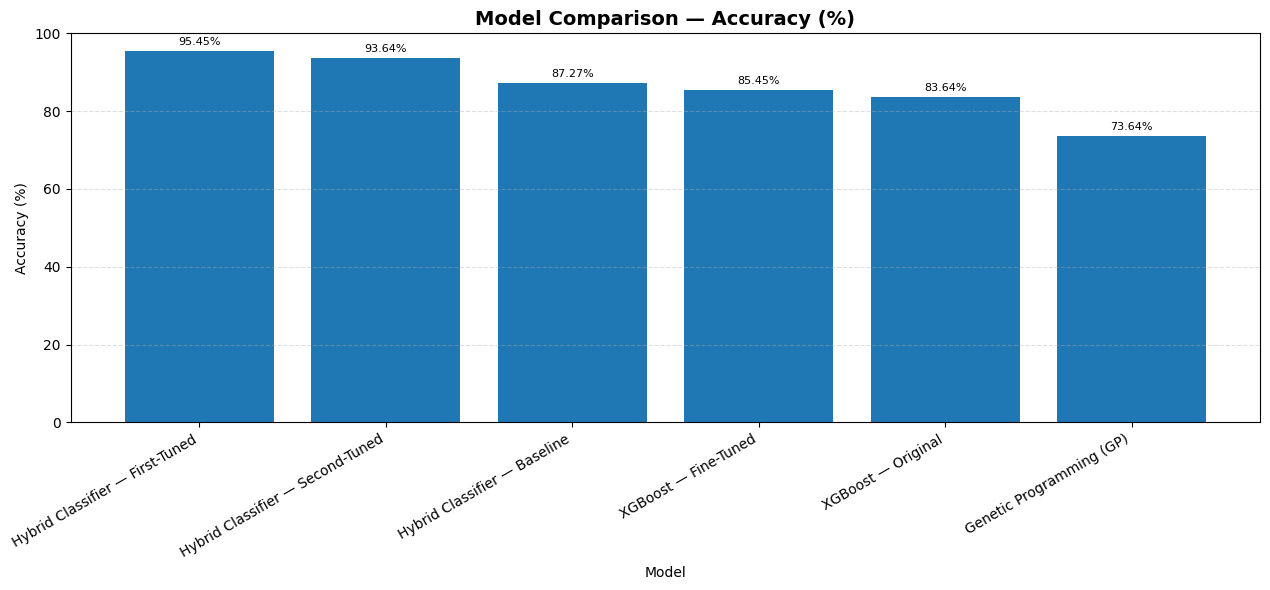

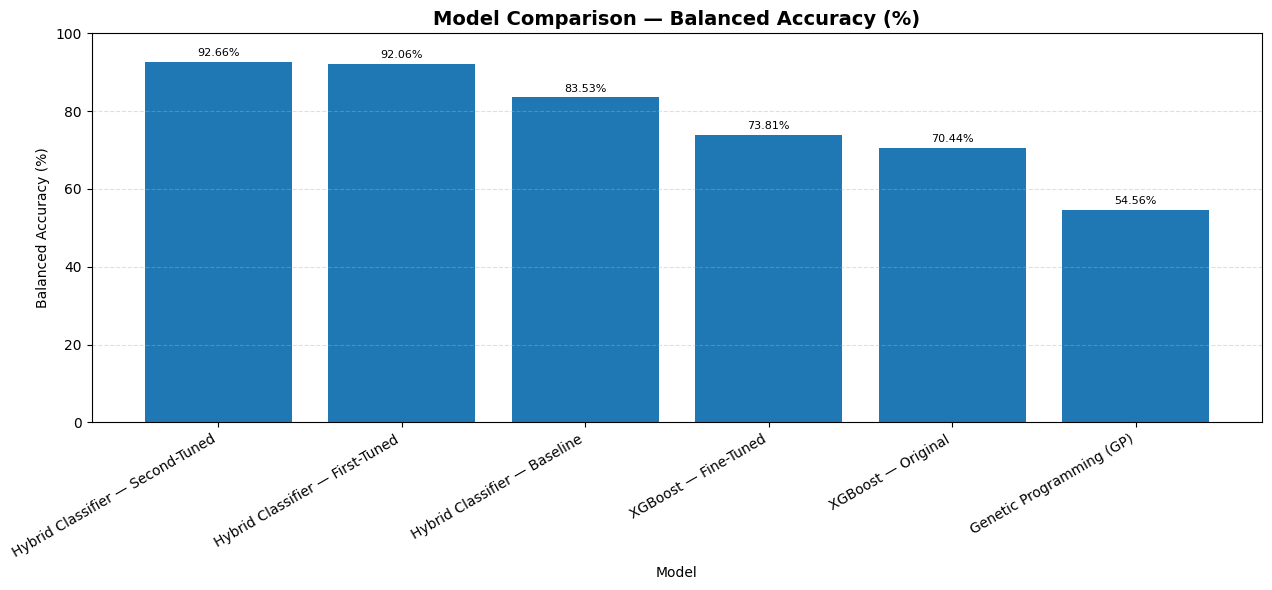

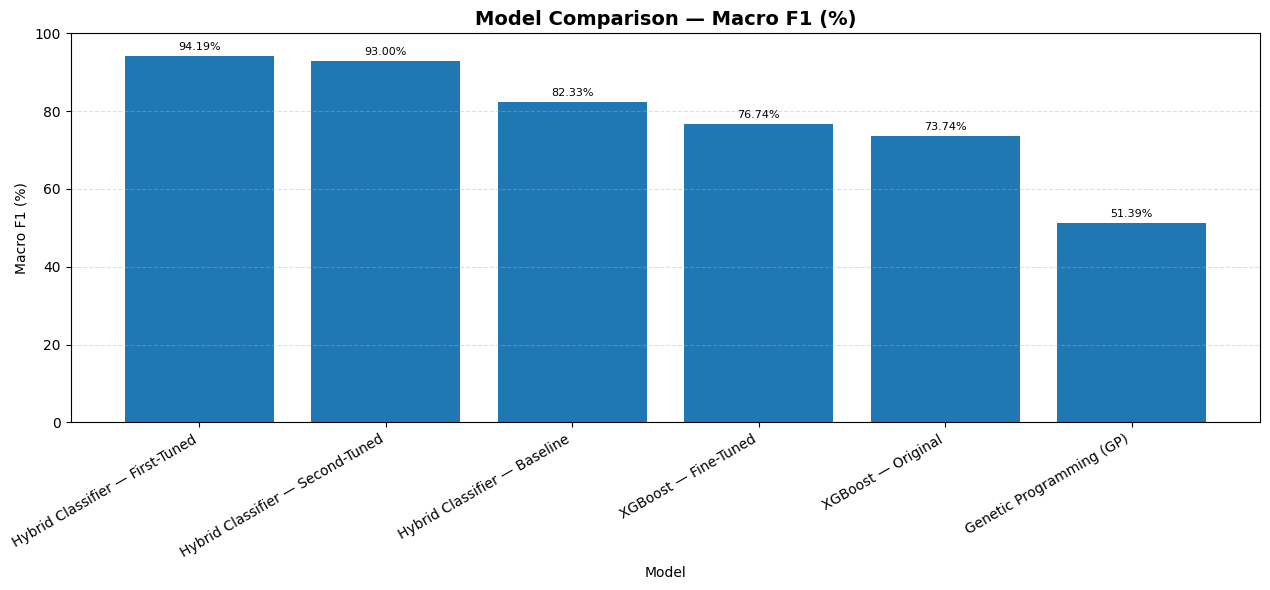


Comparison files saved successfully:
/content/lung_ct_model_comparison.csv
/content/lung_ct_model_comparison.json

Total models included: 6
Prediction arrays stored in registered_predictions.
Original model checkpoints were not modified.


In [ ]:

# ============================================================
# FINAL MODEL COMPARISON — ALL AVAILABLE NOTEBOOK MODELS
# GP -> XGBoost -> ConvNeXt-Tiny -> Hybrid Classifier
# Baseline -> First-Tuned -> Second-Tuned
# Best-performing model highlighted in yellow
# Place this cell BEFORE THE GRAD-CAM SECTION.
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# ------------------------------------------------------------
# 1. METRIC FUNCTION
# ------------------------------------------------------------

def calculate_model_metrics(y_true, y_pred):
    y_true = np.asarray(y_true).reshape(-1)
    y_pred = np.asarray(y_pred).reshape(-1)

    if len(y_true) != len(y_pred):
        raise ValueError(
            f"Length mismatch: actual={len(y_true)}, "
            f"predicted={len(y_pred)}"
        )

    if len(y_true) == 0:
        raise ValueError("Empty evaluation arrays.")

    return {
        # "Test Samples": len(y_true),
        "Accuracy (%)": 100 * accuracy_score(y_true, y_pred),
        "Balanced Accuracy (%)": 100 * balanced_accuracy_score(
            y_true, y_pred
        ),
        "Macro Precision (%)": 100 * precision_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "Macro Recall (%)": 100 * recall_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "Macro F1 (%)": 100 * f1_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "Weighted F1 (%)": 100 * f1_score(
            y_true, y_pred, average="weighted", zero_division=0
        )
    }


# ------------------------------------------------------------
# 2. REGISTER MODEL RESULTS
# ------------------------------------------------------------

comparison_results = []
registered_predictions = {}

def add_model_result(name, y_true, y_pred):
    if y_true is None or y_pred is None:
        print(f"NOT AVAILABLE: {name}")
        return

    try:
        y_true = np.asarray(y_true).reshape(-1)
        y_pred = np.asarray(y_pred).reshape(-1)

        metrics = calculate_model_metrics(y_true, y_pred)
        metrics["Model"] = name

        comparison_results.append(metrics)
        registered_predictions[name] = (y_true, y_pred)

        print(f"Added: {name} ({len(y_true)} samples)")

    except Exception as error:
        print(f"Skipped {name}: {error}")


# ------------------------------------------------------------
# 3. GENETIC PROGRAMMING (GP)
# ------------------------------------------------------------

if "gp_test_pred" in globals() and "y_test" in globals():
    add_model_result(
        "Genetic Programming (GP)",
        y_test,
        gp_test_pred
    )
else:
    print("GP test predictions unavailable.")


# ------------------------------------------------------------
# 4. XGBOOST — ORIGINAL
# ------------------------------------------------------------

if "xgb_test_pred" in globals() and "y_test" in globals():
    add_model_result(
        "XGBoost — Original",
        y_test,
        xgb_test_pred
    )
else:
    print("Original XGBoost test predictions unavailable.")


# ------------------------------------------------------------
# 5. XGBOOST — FINE-TUNED
# ------------------------------------------------------------

if "xgb_best_test_pred" in globals() and "y_test" in globals():
    add_model_result(
        "XGBoost — Fine-Tuned",
        y_test,
        xgb_best_test_pred
    )
else:
    print("Fine-tuned XGBoost test predictions unavailable.")


# ------------------------------------------------------------
# 6. CONVNEXT-TINY — INCLUDE AVAILABLE PREDICTIONS ONLY
# ------------------------------------------------------------

convnext_prediction_pairs = [
    (
        "ConvNeXt-Tiny — Original",
        "convnext_y_test",
        "convnext_test_pred"
    ),
    (
        "ConvNeXt-Tiny — Fine-Tuned",
        "convnext_tuned_y_test",
        "convnext_tuned_test_pred"
    ),
    (
        "ConvNeXt-Tiny — First-Tuned",
        "convnext_first_y_test",
        "convnext_first_test_pred"
    ),
    (
        "ConvNeXt-Tiny — Second-Tuned",
        "convnext_second_y_test",
        "convnext_second_test_pred"
    )
]

for model_name, actual_name, pred_name in convnext_prediction_pairs:
    if actual_name in globals() and pred_name in globals():
        add_model_result(
            model_name,
            globals()[actual_name],
            globals()[pred_name]
        )
    else:
        print(
            f"Not included: {model_name} "
            "(actual labels/predictions unavailable)"
        )


# ------------------------------------------------------------
# 7. HYBRID CLASSIFIER — BASELINE
# ------------------------------------------------------------

if "y_test_actual" in globals() and "y_test_pred" in globals():
    add_model_result(
        "Hybrid Classifier — Baseline",
        y_test_actual,
        y_test_pred
    )
else:
    print("Baseline hybrid test predictions unavailable.")


# ------------------------------------------------------------
# 8. HYBRID CLASSIFIER — FIRST-TUNED
# ------------------------------------------------------------

if "y_test_ft" in globals() and "y_pred_ft" in globals():
    add_model_result(
        "Hybrid Classifier — First-Tuned",
        y_test_ft,
        y_pred_ft
    )
else:
    print("First-tuned hybrid test predictions unavailable.")


# ------------------------------------------------------------
# 9. HYBRID CLASSIFIER — SECOND-TUNED
# ------------------------------------------------------------

if "y_test_final" in globals() and "y_pred_final" in globals():
    add_model_result(
        "Hybrid Classifier — Second-Tuned",
        y_test_final,
        y_pred_final
    )
else:
    print("Second-tuned hybrid test predictions unavailable.")


# ------------------------------------------------------------
# 10. VALIDATE AND RANK RESULTS
# ------------------------------------------------------------

if not comparison_results:
    raise RuntimeError(
        "No model predictions were found. Run the model test "
        "evaluation cells before this comparison cell."
    )

comparison_df = pd.DataFrame(comparison_results)

column_order = [
    "Model",
    # "Test Samples",
    "Accuracy (%)",
    "Balanced Accuracy (%)",
    "Macro Precision (%)",
    "Macro Recall (%)",
    "Macro F1 (%)",
    "Weighted F1 (%)"
]

comparison_df = comparison_df[column_order]

# Rank by Macro F1, then Balanced Accuracy, then Accuracy.
comparison_df = comparison_df.sort_values(
    by=[
        "Macro F1 (%)",
        "Balanced Accuracy (%)",
        "Accuracy (%)"
    ],
    ascending=False
).reset_index(drop=True)

comparison_df.insert(
    0,
    "Rank",
    np.arange(1, len(comparison_df) + 1)
)


# ------------------------------------------------------------
# 11. DISPLAY TABLE WITH BEST MODEL HIGHLIGHTED IN YELLOW
# ------------------------------------------------------------

print("\n" + "=" * 110)
print("LUNG CT CLASSIFICATION — FINAL MODEL COMPARISON")
print("=" * 110)

def highlight_best_model(row):
    if row["Rank"] == 1:
        return [
            "background-color: #FFF176; "
            "color: black; "
            "font-weight: bold"
        ] * len(row)

    return [""] * len(row)


styled_comparison = (
    comparison_df.style
    .format({
        "Accuracy (%)": "{:.2f}",
        "Balanced Accuracy (%)": "{:.2f}",
        "Macro Precision (%)": "{:.2f}",
        "Macro Recall (%)": "{:.2f}",
        "Macro F1 (%)": "{:.2f}",
        "Weighted F1 (%)": "{:.2f}"
    })
    .apply(highlight_best_model, axis=1)
    .set_properties(**{
        "text-align": "center",
        "padding": "8px"
    })
    .set_table_styles([
        {
            "selector": "th",
            "props": [
                ("text-align", "center"),
                ("font-weight", "bold"),
                ("background-color", "#E8EAF6"),
                ("color", "black")
            ]
        },
        {
            "selector": "table",
            "props": [
                ("border-collapse", "collapse"),
                ("width", "100%")
            ]
        }
    ])
)

display(styled_comparison)


# ------------------------------------------------------------
# 12. DISPLAY BEST MODEL PERFORMANCE
# ------------------------------------------------------------

best_model = comparison_df.iloc[0]

print("\nBest-performing model:")
print(f"Rank: {int(best_model['Rank'])}")
print(f"Model: {best_model['Model']}")
print(f"Test Samples: {int(best_model['Test Samples'])}")
print(f"Accuracy: {best_model['Accuracy (%)']:.2f}%")
print(
    f"Balanced Accuracy: "
    f"{best_model['Balanced Accuracy (%)']:.2f}%"
)
print(
    f"Macro Precision: "
    f"{best_model['Macro Precision (%)']:.2f}%"
)
print(
    f"Macro Recall: "
    f"{best_model['Macro Recall (%)']:.2f}%"
)
print(f"Macro F1: {best_model['Macro F1 (%)']:.2f}%")
print(
    f"Weighted F1: "
    f"{best_model['Weighted F1 (%)']:.2f}%"
)


# ------------------------------------------------------------
# 13. MODEL COMPARISON CHARTS
# ------------------------------------------------------------

metrics_to_plot = [
    "Accuracy (%)",
    "Balanced Accuracy (%)",
    "Macro F1 (%)"
]

for metric in metrics_to_plot:
    plot_df = comparison_df.sort_values(
        by=metric,
        ascending=False
    ).reset_index(drop=True)

    plt.figure(figsize=(13, 6))

    bars = plt.bar(
        plot_df["Model"],
        plot_df[metric]
    )

    plt.title(
        f"Model Comparison — {metric}",
        fontsize=14,
        fontweight="bold"
    )
    plt.xlabel("Model")
    plt.ylabel(metric)
    plt.xticks(rotation=30, ha="right")
    plt.ylim(0, 100)
    plt.grid(
        axis="y",
        linestyle="--",
        alpha=0.4
    )

    for bar, value in zip(bars, plot_df[metric]):
        plt.text(
            bar.get_x() + bar.get_width() / 2,
            min(bar.get_height() + 1, 99),
            f"{value:.2f}%",
            ha="center",
            va="bottom",
            fontsize=8
        )

    plt.tight_layout()
    plt.show()


# ------------------------------------------------------------
# 14. SAVE RESULTS AS CSV AND JSON
# ------------------------------------------------------------

CSV_PATH = "/content/lung_ct_model_comparison.csv"
JSON_PATH = "/content/lung_ct_model_comparison.json"

comparison_df.to_csv(
    CSV_PATH,
    index=False
)

comparison_df.to_json(
    JSON_PATH,
    orient="records",
    indent=2
)

print("\nComparison files saved successfully:")
print(CSV_PATH)
print(JSON_PATH)

print("\nTotal models included:", len(comparison_df))
print("Prediction arrays stored in registered_predictions.")
print("Original model checkpoints were not modified.")


# **GRAD-CAM**

In [ ]:
# ============================================================
# CELL 26 — SELECT CONVNEXT LAYER FOR GRAD-CAM
# ============================================================

# ------------------------------------------------------------
# Select the final spatial ConvNeXt stage
# ------------------------------------------------------------

gradcam_target_layer = convnext.features[7]

print("=" * 60)
print("GRAD-CAM TARGET LAYER")
print("=" * 60)

print(
    "Target layer:"
)

print(
    gradcam_target_layer
)

print(
    "\nTarget layer index: convnext.features[7]"
)

print(
    "\nThis layer produces spatial feature maps "
    "before the final global pooling."
)

GRAD-CAM TARGET LAYER
Target layer:
Sequential(
  (0): CNBlock(
    (block): Sequential(
      (0): Conv2d(768, 768, kernel_size=(7, 7), stride=(1, 1), padding=(3, 3), groups=768)
      (1): Permute()
      (2): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
      (3): Linear(in_features=768, out_features=3072, bias=True)
      (4): GELU(approximate='none')
      (5): Linear(in_features=3072, out_features=768, bias=True)
      (6): Permute()
    )
    (stochastic_depth): StochasticDepth(p=0.08823529411764706, mode=row)
  )
  (1): CNBlock(
    (block): Sequential(
      (0): Conv2d(768, 768, kernel_size=(7, 7), stride=(1, 1), padding=(3, 3), groups=768)
      (1): Permute()
      (2): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
      (3): Linear(in_features=768, out_features=3072, bias=True)
      (4): GELU(approximate='none')
      (5): Linear(in_features=3072, out_features=768, bias=True)
      (6): Permute()
    )
    (stochastic_depth): StochasticDepth(p=0.094117647

In [ ]:

# ============================================================
# VERIFY CONVNEXT GRAD-CAM TARGET LAYER
# ============================================================

import torch

convnext.eval()

gradcam_target_layer = convnext.features[7]

captured = {}

def verify_hook(module, inputs, output):
    captured["shape"] = tuple(output.shape)

handle = gradcam_target_layer.register_forward_hook(verify_hook)

try:
    # Use the same preprocessing and input size as prediction.
    test_input = torch.zeros(
        1, 3, 224, 224,
        device=next(convnext.parameters()).device
    )

    with torch.no_grad():
        _ = convnext.features(test_input)

    print("Target layer:", gradcam_target_layer)
    print("Target output shape:", captured.get("shape"))

    if captured.get("shape") == (1, 768, 7, 7):
        print("Layer check: PASS for standard ConvNeXt-Tiny.")
    else:
        print(
            "Layer check: Verify this architecture's final spatial "
            "stage before using it for Grad-CAM."
        )

finally:
    handle.remove()

# Check which classifier the upload Grad-CAM function uses.
print("\nGrad-CAM classifier checks:")
print("final_hybrid_model exists:",
      isinstance(globals().get("final_hybrid_model"), torch.nn.Module))
print("best_tuned_model exists:",
      isinstance(globals().get("best_tuned_model"), torch.nn.Module))

if (
    isinstance(globals().get("final_hybrid_model"), torch.nn.Module)
    and isinstance(globals().get("best_tuned_model"), torch.nn.Module)
):
    same_weights = all(
        torch.equal(a, b)
        for a, b in zip(
            final_hybrid_model.parameters(),
            best_tuned_model.parameters()
        )
    ) and (
        len(list(final_hybrid_model.parameters()))
        == len(list(best_tuned_model.parameters()))
    )

    print("Both classifiers have identical parameter values:", same_weights)
    if not same_weights:
        print(
            "WARNING: Ensure Grad-CAM uses the same classifier "
            "that was selected for final prediction."
        )


Target layer: Sequential(
  (0): CNBlock(
    (block): Sequential(
      (0): Conv2d(768, 768, kernel_size=(7, 7), stride=(1, 1), padding=(3, 3), groups=768)
      (1): Permute()
      (2): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
      (3): Linear(in_features=768, out_features=3072, bias=True)
      (4): GELU(approximate='none')
      (5): Linear(in_features=3072, out_features=768, bias=True)
      (6): Permute()
    )
    (stochastic_depth): StochasticDepth(p=0.08823529411764706, mode=row)
  )
  (1): CNBlock(
    (block): Sequential(
      (0): Conv2d(768, 768, kernel_size=(7, 7), stride=(1, 1), padding=(3, 3), groups=768)
      (1): Permute()
      (2): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
      (3): Linear(in_features=768, out_features=3072, bias=True)
      (4): GELU(approximate='none')
      (5): Linear(in_features=3072, out_features=768, bias=True)
      (6): Permute()
    )
    (stochastic_depth): StochasticDepth(p=0.09411764705882353, mode=row)
  

In [ ]:
# ============================================================
# GRAD-CAM SETUP
# ============================================================

!pip install -q grad-cam

In [ ]:
import torch
import torch.nn.functional as F
import numpy as np
import cv2
import matplotlib.pyplot as plt

from PIL import Image
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from pytorch_grad_cam.utils.image import show_cam_on_image

print("Grad-CAM setup complete.")

Grad-CAM setup complete.


In [ ]:
# ============================================================
# VALIDATED FINAL MODEL — FIRST-TUNED HYBRID CLASSIFIER
# ============================================================

import torch

# ------------------------------------------------------------
# 1. GET THE VALIDATED MODEL FROM CELL 32
# ------------------------------------------------------------

if "best_ft_model" not in globals():
    raise NameError(
        "best_ft_model not found. Run the first-tuned model "
        "training/evaluation cell (Cell 32) first."
    )

validated_model = best_ft_model

device_eval = (
    device if "device" in globals()
    else torch.device("cuda" if torch.cuda.is_available() else "cpu")
)

validated_model = validated_model.to(device_eval)
validated_model.eval()

# ------------------------------------------------------------
# 2. DISPLAY VALIDATED MODEL DETAILS
# ------------------------------------------------------------

print("=" * 70)
print("VALIDATED FINAL MODEL")
print("=" * 70)

print("Model name: Hybrid Classifier — First-Tuned")
print("Model variable: best_ft_model")
print("Model architecture:", type(validated_model).__name__)
print("Evaluation device:", device_eval)

print("\nModel architecture:")
print(validated_model)

# ------------------------------------------------------------
# 3. DISPLAY VALIDATION METRICS FROM CELL 32
# ------------------------------------------------------------

if "ft_test_accuracy" in globals():
    print(f"\nTest Accuracy: {float(ft_test_accuracy) * 100:.2f}%")

if "ft_test_balanced_accuracy" in globals():
    print(
        "Test Balanced Accuracy: "
        f"{float(ft_test_balanced_accuracy) * 100:.2f}%"
    )

if "ft_test_macro_precision" in globals():
    print(
        "Test Macro Precision: "
        f"{float(ft_test_macro_precision) * 100:.2f}%"
    )

if "ft_test_macro_recall" in globals():
    print(
        "Test Macro Recall: "
        f"{float(ft_test_macro_recall) * 100:.2f}%"
    )

if "ft_test_macro_f1" in globals():
    print(f"Test Macro F1: {float(ft_test_macro_f1) * 100:.2f}%")

if "ft_test_weighted_f1" in globals():
    print(
        "Test Weighted F1: "
        f"{float(ft_test_weighted_f1) * 100:.2f}%"
    )

# ------------------------------------------------------------
# 4. EXPOSE THE FINAL MODEL FOR DOWNSTREAM CELLS
# ------------------------------------------------------------

final_hybrid_classifier = validated_model
selected_model_name = "Hybrid Classifier — First-Tuned"

print("\n" + "=" * 70)
print("FINAL MODEL READY")
print("=" * 70)
print("Selected model:", selected_model_name)
print("Available as: final_hybrid_classifier")
print("Model weights were not modified or retrained.")

VALIDATED FINAL MODEL
Model name: Hybrid Classifier — First-Tuned
Model variable: best_ft_model
Model architecture: TunableHybridClassifier
Evaluation device: cpu

Model architecture:
TunableHybridClassifier(
  (network): Sequential(
    (0): Linear(in_features=82, out_features=128, bias=True)
    (1): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.2, inplace=False)
    (4): Linear(in_features=128, out_features=64, bias=True)
    (5): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): Dropout(p=0.15, inplace=False)
    (8): Linear(in_features=64, out_features=32, bias=True)
    (9): ReLU()
    (10): Linear(in_features=32, out_features=3, bias=True)
  )
)

Test Accuracy: 95.45%
Test Balanced Accuracy: 92.06%
Test Macro Precision: 96.94%
Test Macro Recall: 92.06%
Test Macro F1: 94.19%
Test Weighted F1: 95.39%

FINAL MODEL READY
Selected model: Hybrid Classifier — F

In [ ]:
# ============================================================
# INSPECT VERIFIED FIRST-TUNED HYBRID CLASSIFIER
# Model: best_ft_model
# ============================================================

import torch

# ------------------------------------------------------------
# 1. GET THE VERIFIED MODEL
# ------------------------------------------------------------

if "best_ft_model" not in globals():
    raise NameError(
        "best_ft_model not found. Run the first-tuned model cell first."
    )

validated_model = best_ft_model

# ------------------------------------------------------------
# 2. DISPLAY MODEL DETAILS
# ------------------------------------------------------------

print("=" * 70)
print("VERIFIED MODEL DETAILS")
print("=" * 70)

print("Model name: Hybrid Classifier — First-Tuned")
print("Model variable: best_ft_model")
print("Model architecture:", type(validated_model).__name__)

print("\nModel architecture:")
print(validated_model)

# ------------------------------------------------------------
# 3. INSPECT MODEL PARAMETER KEYS
# ------------------------------------------------------------

state_dict = validated_model.state_dict()

print("\nState dictionary keys:")
print(list(state_dict.keys()))

print("\nFirst 30 model parameter keys:")
for key in list(state_dict.keys())[:30]:
    print(key)

print("\nNumber of state dictionary entries:", len(state_dict))

# ------------------------------------------------------------
# 4. COUNT PARAMETERS
# ------------------------------------------------------------

total_parameters = sum(
    parameter.numel()
    for parameter in validated_model.parameters()
)

trainable_parameters = sum(
    parameter.numel()
    for parameter in validated_model.parameters()
    if parameter.requires_grad
)

print("\nTotal model parameters:", total_parameters)
print("Trainable parameters:", trainable_parameters)

# ------------------------------------------------------------
# 5. FINAL MODEL CONFIRMATION
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("MODEL INSPECTION COMPLETED")
print("=" * 70)
print("Selected model: Hybrid Classifier — First-Tuned")
print("Variable: best_ft_model")
print("Original model weights were not modified.")

VERIFIED MODEL DETAILS
Model name: Hybrid Classifier — First-Tuned
Model variable: best_ft_model
Model architecture: TunableHybridClassifier

Model architecture:
TunableHybridClassifier(
  (network): Sequential(
    (0): Linear(in_features=82, out_features=128, bias=True)
    (1): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.2, inplace=False)
    (4): Linear(in_features=128, out_features=64, bias=True)
    (5): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): Dropout(p=0.15, inplace=False)
    (8): Linear(in_features=64, out_features=32, bias=True)
    (9): ReLU()
    (10): Linear(in_features=32, out_features=3, bias=True)
  )
)

State dictionary keys:
['network.0.weight', 'network.0.bias', 'network.1.weight', 'network.1.bias', 'network.1.running_mean', 'network.1.running_var', 'network.1.num_batches_tracked', 'network.4.weight', 'network.4.bias', 'network.5.

In [ ]:
# ============================================================
# SAVE VERIFIED FIRST-TUNED HYBRID CLASSIFIER
# ============================================================

import os
import torch

MODEL_DIR = "/content/hybrid_models"
os.makedirs(MODEL_DIR, exist_ok=True)

MODEL_PATH = os.path.join(
    MODEL_DIR,
    "hybrid_classifier_first_tuned_best.pt"
)

torch.save(
    {
        "model_name": "Hybrid Classifier — First-Tuned",
        "model_state_dict": best_ft_model.state_dict(),
        "input_features": 82,
        "num_classes": 3,
        "class_names": ["Normal", "Benign", "Malignant"],
        "test_accuracy": float(ft_test_accuracy),
        "test_macro_f1": float(ft_test_macro_f1)
    },
    MODEL_PATH
)

print("Verified model saved successfully.")
print("Path:", MODEL_PATH)
print("Model: best_ft_model")
print("Total parameters:", sum(
    p.numel() for p in best_ft_model.parameters()
))

Verified model saved successfully.
Path: /content/hybrid_models/hybrid_classifier_first_tuned_best.pt
Model: best_ft_model
Total parameters: 21443


In [ ]:
import torch
import os

MODEL_PATH = "/content/hybrid_models/hybrid_classifier_first_tuned_best.pt"

assert os.path.exists(MODEL_PATH), "Checkpoint file not found!"

checkpoint = torch.load(
    MODEL_PATH,
    map_location="cpu",
    weights_only=True
)

print("Checkpoint loaded successfully.")
print("Model name:", checkpoint["model_name"])
print("Input features:", checkpoint["input_features"])
print("Number of classes:", checkpoint["num_classes"])
print("Class names:", checkpoint["class_names"])
print("Saved state dictionary entries:",
      len(checkpoint["model_state_dict"]))
print("Saved test accuracy:",
      f"{checkpoint['test_accuracy'] * 100:.2f}%")
print("Saved test Macro F1:",
      f"{checkpoint['test_macro_f1'] * 100:.2f}%")

Checkpoint loaded successfully.
Model name: Hybrid Classifier — First-Tuned
Input features: 82
Number of classes: 3
Class names: ['Normal', 'Benign', 'Malignant']
Saved state dictionary entries: 18
Saved test accuracy: 95.45%
Saved test Macro F1: 94.19%


In [ ]:
# import torch

# MODEL_PATH = "/content/convnext_models/convnext_tiny_tuned_best.pt"

# checkpoint = torch.load(
#     MODEL_PATH,
#     map_location="cpu",
#     weights_only=False
# )

# print("Checkpoint keys:")
# print(checkpoint.keys())

# print("\nFirst 30 model parameter keys:")
# for key in list(checkpoint["model_state_dict"].keys())[:30]:
#     print(key)

# print("\nNumber of saved parameters:",
#       len(checkpoint["model_state_dict"]))

In [ ]:
# ============================================================
# INSPECT SAVED FIRST-TUNED HYBRID MODEL ARCHITECTURE
# ============================================================

import torch

state_dict = checkpoint["model_state_dict"]

print("=" * 80)
print("SAVED MODEL ARCHITECTURE — FIRST-TUNED HYBRID CLASSIFIER")
print("=" * 80)

print(f"{'Parameter / Buffer Name':35s} {'Shape':25s} {'Count':>10s}")
print("-" * 80)

total_values = 0

for key, value in state_dict.items():
    shape = tuple(value.shape)
    count = value.numel()
    total_values += count

    print(f"{key:35s} {str(shape):25s} {count:10,d}")

print("-" * 80)
print("State dictionary entries:", len(state_dict))
print("Total values in state dictionary:", f"{total_values:,}")
print("Architecture: TunableHybridClassifier")
print("Input features: 82")
print("Output classes: 3")
print("Class names: Normal, Benign, Malignant")

SAVED MODEL ARCHITECTURE — FIRST-TUNED HYBRID CLASSIFIER
Parameter / Buffer Name             Shape                          Count
--------------------------------------------------------------------------------
network.0.weight                    (128, 82)                     10,496
network.0.bias                      (128,)                           128
network.1.weight                    (128,)                           128
network.1.bias                      (128,)                           128
network.1.running_mean              (128,)                           128
network.1.running_var               (128,)                           128
network.1.num_batches_tracked       ()                                 1
network.4.weight                    (64, 128)                      8,192
network.4.bias                      (64,)                             64
network.5.weight                    (64,)                             64
network.5.bias                      (64,)                  

In [ ]:
# Display the verified First-Tuned Hybrid Classifier architecture
model = best_ft_model
print(model)

TunableHybridClassifier(
  (network): Sequential(
    (0): Linear(in_features=82, out_features=128, bias=True)
    (1): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.2, inplace=False)
    (4): Linear(in_features=128, out_features=64, bias=True)
    (5): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): Dropout(p=0.15, inplace=False)
    (8): Linear(in_features=64, out_features=32, bias=True)
    (9): ReLU()
    (10): Linear(in_features=32, out_features=3, bias=True)
  )
)


In [ ]:
# ============================================================
# CELL 27A — LOAD SAVED FIRST-TUNED HYBRID CLASSIFIER
# ============================================================

import torch
import torch.nn as nn
from pathlib import Path

MODEL_PATH = Path(
    "/content/hybrid_models/hybrid_classifier_first_tuned_best.pt"
)

if not MODEL_PATH.exists():
    raise FileNotFoundError(
        f"Model checkpoint not found: {MODEL_PATH}"
    )

checkpoint = torch.load(
    MODEL_PATH,
    map_location=device,
    weights_only=True
)

# ------------------------------------------------------------
# RECREATE THE VERIFIED MODEL ARCHITECTURE
# ------------------------------------------------------------

class TunableHybridClassifier(nn.Module):
    def __init__(self, input_dim=82, num_classes=3):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_dim, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(0.2),

            nn.Linear(128, 64),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Dropout(0.15),

            nn.Linear(64, 32),
            nn.ReLU(),

            nn.Linear(32, num_classes)
        )

    def forward(self, x):
        return self.network(x)


# ------------------------------------------------------------
# LOAD SAVED WEIGHTS
# ------------------------------------------------------------

hybrid_model = TunableHybridClassifier(
    input_dim=checkpoint["input_features"],
    num_classes=checkpoint["num_classes"]
).to(device)

hybrid_model.load_state_dict(
    checkpoint["model_state_dict"],
    strict=True
)

hybrid_model.eval()

# Make the loaded first-tuned model available to later cells
final_hybrid_classifier = hybrid_model
selected_model_name = checkpoint["model_name"]

# ------------------------------------------------------------
# VERIFY
# ------------------------------------------------------------

print("=" * 65)
print("FIRST-TUNED HYBRID CLASSIFIER LOADED SUCCESSFULLY")
print("=" * 65)

print("Model:", selected_model_name)
print("Checkpoint:", MODEL_PATH)
print("Input features:", checkpoint["input_features"])
print("Classes:", checkpoint["class_names"])
print("State dictionary entries:", len(checkpoint["model_state_dict"]))
print(
    "Saved test accuracy:",
    f"{checkpoint['test_accuracy'] * 100:.2f}%"
)
print(
    "Saved test Macro F1:",
    f"{checkpoint['test_macro_f1'] * 100:.2f}%"
)

print("\nModel architecture:")
print(hybrid_model)

FIRST-TUNED HYBRID CLASSIFIER LOADED SUCCESSFULLY
Model: Hybrid Classifier — First-Tuned
Checkpoint: /content/hybrid_models/hybrid_classifier_first_tuned_best.pt
Input features: 82
Classes: ['Normal', 'Benign', 'Malignant']
State dictionary entries: 18
Saved test accuracy: 95.45%
Saved test Macro F1: 94.19%

Model architecture:
TunableHybridClassifier(
  (network): Sequential(
    (0): Linear(in_features=82, out_features=128, bias=True)
    (1): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.2, inplace=False)
    (4): Linear(in_features=128, out_features=64, bias=True)
    (5): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): Dropout(p=0.15, inplace=False)
    (8): Linear(in_features=64, out_features=32, bias=True)
    (9): ReLU()
    (10): Linear(in_features=32, out_features=3, bias=True)
  )
)


In [ ]:
# ============================================================
# FINAL SELECTED MODEL
# ============================================================

final_hybrid_classifier = best_ft_model.to(device)
final_hybrid_classifier.eval()

print("Selected model:", "Hybrid Classifier — First-Tuned")
print("Input features: 82")
print("Output classes: Normal, Benign, Malignant")

Selected model: Hybrid Classifier — First-Tuned
Input features: 82
Output classes: Normal, Benign, Malignant


In [ ]:
# # ============================================================
# # CELL 28 — PREPARE ONE INTERNAL-TEST IMAGE FOR GRAD-CAM
# # ============================================================

# import cv2
# import numpy as np
# import torch
# from PIL import Image

# # 1. Select an internal-test image
# gradcam_image_path = iq_internal_test_df.iloc[0]["filepath"]

# print("=" * 60)
# print("GRAD-CAM IMAGE PREPARATION")
# print("=" * 60)
# print("Image path:", gradcam_image_path)

# # 2. Read the original CT image
# gradcam_original = cv2.imread(
#     str(gradcam_image_path),
#     cv2.IMREAD_GRAYSCALE
# )

# if gradcam_original is None:
#     raise ValueError(f"Could not read image: {gradcam_image_path}")

# print("Original shape:", gradcam_original.shape)
# print(
#     "Original pixel range:",
#     gradcam_original.min(),
#     "to",
#     gradcam_original.max()
# )

# # 3. Apply your finalized preprocessing
# gradcam_processed = prepare_convnext_image(
#     gradcam_original,
#     target_size=(224, 224)
# )

# gradcam_processed = np.asarray(gradcam_processed)

# if gradcam_processed.ndim != 2:
#     raise ValueError(
#         f"Expected a grayscale image, got shape {gradcam_processed.shape}"
#     )

# if not np.isfinite(gradcam_processed).all():
#     raise ValueError("Preprocessed image contains invalid values.")

# print("Processed shape:", gradcam_processed.shape)
# print(
#     "Processed pixel range:",
#     gradcam_processed.min(),
#     "to",
#     gradcam_processed.max()
# )

# # 4. Convert to uint8 only when needed
# if gradcam_processed.dtype == np.uint8:
#     gradcam_uint8 = gradcam_processed
# elif gradcam_processed.min() >= 0 and gradcam_processed.max() <= 1:
#     gradcam_uint8 = np.round(
#         gradcam_processed * 255
#     ).astype(np.uint8)
# elif gradcam_processed.min() >= 0 and gradcam_processed.max() <= 255:
#     gradcam_uint8 = np.round(
#         gradcam_processed
#     ).astype(np.uint8)
# else:
#     raise ValueError(
#         "Unexpected pixel range. Check prepare_convnext_image()."
#     )

# # 5. Convert grayscale to RGB
# gradcam_rgb = cv2.cvtColor(
#     gradcam_uint8,
#     cv2.COLOR_GRAY2RGB
# )

# gradcam_pil = Image.fromarray(gradcam_rgb)

# # 6. Apply the exact training transformation
# gradcam_tensor = convnext_transform(gradcam_pil)

# # 7. Add batch dimension and move to device
# gradcam_tensor = gradcam_tensor.unsqueeze(0).to(device)

# print("Tensor shape:", tuple(gradcam_tensor.shape))
# print("Tensor device:", gradcam_tensor.device)
# print("Tensor dtype:", gradcam_tensor.dtype)

# assert gradcam_tensor.shape == (1, 3, 224, 224)

# print("=" * 60)
# print("IMAGE PREPARATION COMPLETED")
# print("=" * 60)

Original image shape: (512, 512)
Original pixel range: 37 to 255
Selected model: Hybrid Classifier — First-Tuned
Architecture: TunableHybridClassifier

FIRST-TUNED HYBRID CLASSIFIER — GRAD-CAM RESULTS
Selected model: best_ft_model
Predicted class: Malignant

Class probabilities:
Normal: 0.00%
Benign: 0.00%
Malignant: 100.00%

Feature dimensions:
Handcrafted features: (1, 50)
ConvNeXt input: (1, 3, 224, 224)
Hybrid classifier input: 82


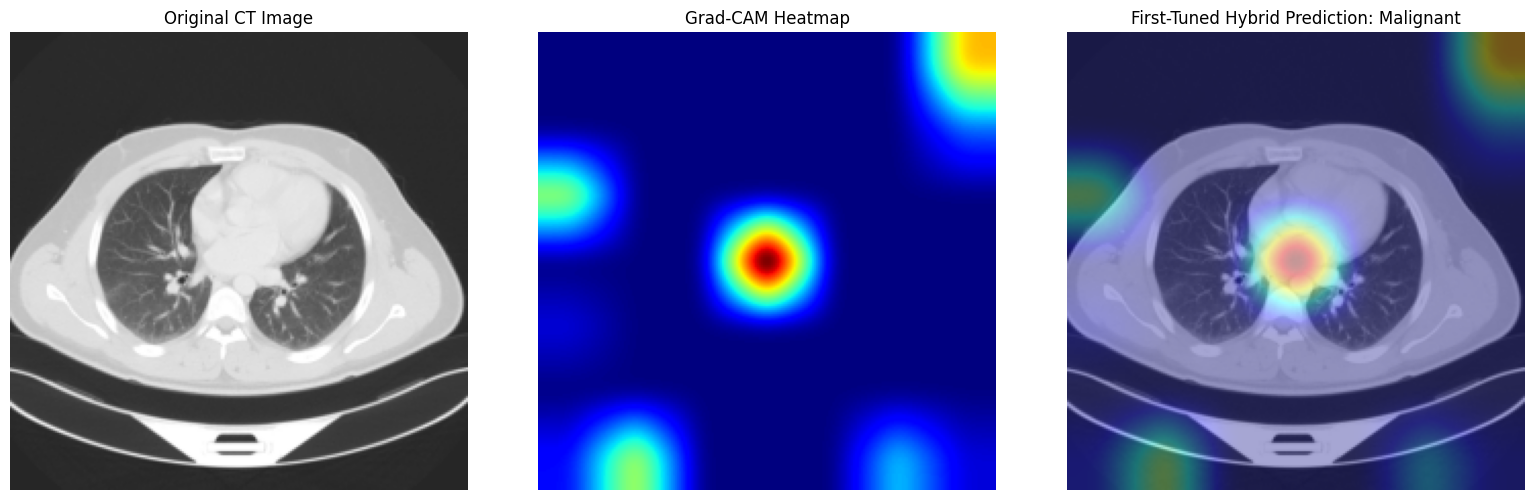


Grad-CAM generation completed.
Selected classifier: best_ft_model


In [ ]:

# ============================================================
# CELL 29 A — FIRST-TUNED HYBRID CLASSIFIER + GRAD-CAM
# Selected model: best_ft_model
# Input: CT image -> ConvNeXt features + handcrafted features
# Output: Normal / Benign / Malignant + Grad-CAM visualization
# ============================================================

import torch
import torch.nn.functional as F
import numpy as np
import cv2
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 0. LOAD THE INTERNAL-TEST CT IMAGE
# ------------------------------------------------------------

import cv2
import numpy as np

if "gradcam_original" not in globals():
    if "iq_internal_test_df" not in globals():
        raise NameError(
            "iq_internal_test_df is missing. Run the cell that "
            "creates the internal-test dataset first."
        )

    if (
        iq_internal_test_df.empty
        or "filepath" not in iq_internal_test_df.columns
    ):
        raise ValueError(
            "The internal-test dataframe is empty or has no filepath column."
        )

    gradcam_image_path = iq_internal_test_df.iloc[0]["filepath"]

    gradcam_original = cv2.imread(
        str(gradcam_image_path),
        cv2.IMREAD_GRAYSCALE
    )

    if gradcam_original is None:
        raise ValueError(
            f"Could not read CT image: {gradcam_image_path}"
        )

    print("Loaded CT image:", gradcam_image_path)

print("Original image shape:", gradcam_original.shape)
print(
    "Original pixel range:",
    gradcam_original.min(),
    "to",
    gradcam_original.max()
)

# ------------------------------------------------------------
# 1. VERIFY REQUIRED COMPONENTS
# ------------------------------------------------------------

required_objects = [
    "best_ft_model",
    "convnext",
    "deep_scaler",
    "deep_pca",
    "HybridGradCAMModel",
    "extract_handcrafted_for_prediction",
    "gradcam_original",
    "gradcam_tensor",
    "device",
    "CLASS_NAMES"
]

missing = [name for name in required_objects if name not in globals()]

if missing:
    raise NameError(
        "Run the required model/feature cells first. Missing: "
        + ", ".join(missing)
    )

# ------------------------------------------------------------
# 2. SELECT THE VERIFIED FIRST-TUNED CLASSIFIER
# ------------------------------------------------------------

final_hybrid_classifier = best_ft_model.to(device)
final_hybrid_classifier.eval()
convnext.eval()

assert final_hybrid_classifier.network[0].in_features == 82
assert final_hybrid_classifier.network[-1].out_features == 3

if getattr(deep_pca, "n_components_", None) != 32:
    raise ValueError(
        "The saved PCA pipeline must produce 32 deep features."
    )

print("Selected model: Hybrid Classifier — First-Tuned")
print("Architecture:", type(final_hybrid_classifier).__name__)

# ------------------------------------------------------------
# 3. EXTRACT HANDCRAFTED FEATURES
# ------------------------------------------------------------

handcrafted_result = extract_handcrafted_for_prediction(
    gradcam_original
)

handcrafted_array = handcrafted_result[0]

gradcam_handcrafted_tensor = torch.as_tensor(
    np.asarray(handcrafted_array),
    dtype=torch.float32,
    device=device
)

if gradcam_handcrafted_tensor.ndim == 1:
    gradcam_handcrafted_tensor = (
        gradcam_handcrafted_tensor.unsqueeze(0)
    )

if gradcam_handcrafted_tensor.shape != (1, 50):
    raise ValueError(
        "Expected 50 handcrafted features; received "
        f"{tuple(gradcam_handcrafted_tensor.shape)}"
    )

if not torch.isfinite(gradcam_handcrafted_tensor).all():
    raise ValueError("Handcrafted features contain NaN or Inf.")

# ------------------------------------------------------------
# 4. CREATE THE CONNECTED HYBRID GRAD-CAM MODEL
# ------------------------------------------------------------

gradcam_model = HybridGradCAMModel(
    convnext_model=convnext,
    hybrid_model=final_hybrid_classifier,
    deep_scaler=deep_scaler,
    deep_pca=deep_pca,
    handcrafted_features=gradcam_handcrafted_tensor
).to(device)

gradcam_model.eval()

# ------------------------------------------------------------
# 5. FORWARD PASS THROUGH THE HYBRID CLASSIFIER
# ------------------------------------------------------------

gradcam_model.zero_grad(set_to_none=True)

gradcam_input = (
    gradcam_tensor.detach()
    .clone()
    .to(device)
    .requires_grad_(True)
)

with torch.enable_grad():
    logits = gradcam_model(gradcam_input)

    if tuple(logits.shape) != (1, 3):
        raise ValueError(
            "Expected three class scores with shape (1, 3); got "
            f"{tuple(logits.shape)}"
        )

    probabilities_tensor = torch.softmax(logits, dim=1)[0]

    predicted_index = int(
        probabilities_tensor.argmax().item()
    )

    predicted_class = CLASS_NAMES[predicted_index]

    # Gradient of the selected hybrid classifier class score
    logits[0, predicted_index].backward()

# ------------------------------------------------------------
# 6. CALCULATE GRAD-CAM
# ------------------------------------------------------------

activations = gradcam_model.spatial_features

if activations is None:
    raise RuntimeError(
        "Spatial activations were not captured. "
        "Check HybridGradCAMModel.forward()."
    )

if activations.grad is None:
    raise RuntimeError(
        "Spatial gradients were not retained. "
        "The wrapper must call retain_grad() on the spatial "
        "feature tensor used by the hybrid classifier."
    )

gradients = activations.grad

weights = gradients.mean(
    dim=(2, 3),
    keepdim=True
)

cam_tensor = torch.relu(
    (weights * activations).sum(dim=1, keepdim=True)
)

cam_tensor = F.interpolate(
    cam_tensor,
    size=(224, 224),
    mode="bilinear",
    align_corners=False
)

cam = cam_tensor[0, 0].detach().cpu().numpy()
cam = np.nan_to_num(
    cam,
    nan=0.0,
    posinf=0.0,
    neginf=0.0
)

if cam.max() > cam.min():
    cam = (cam - cam.min()) / (cam.max() - cam.min())
else:
    raise RuntimeError(
        "Grad-CAM has no spatial variation. "
        "Check the target layer and gradient connection."
    )

# ------------------------------------------------------------
# 7. SMOOTH AND PREPARE THE HEATMAP
# ------------------------------------------------------------

cam_smooth = cv2.GaussianBlur(
    cam.astype(np.float32),
    (0, 0),
    sigmaX=5,
    sigmaY=5
)

if cam_smooth.max() > 0:
    cam_smooth = cam_smooth / cam_smooth.max()

# Prepare the original CT image for visualization
display_gray = cv2.resize(
    gradcam_original,
    (224, 224),
    interpolation=cv2.INTER_AREA
)

display_gray = np.asarray(display_gray)

if display_gray.dtype != np.uint8:
    if display_gray.max() <= 1:
        display_gray = np.round(
            display_gray * 255
        ).astype(np.uint8)
    else:
        display_gray = np.clip(
            display_gray, 0, 255
        ).astype(np.uint8)

display_rgb = cv2.cvtColor(
    display_gray,
    cv2.COLOR_GRAY2RGB
)

# Generate the heatmap
heatmap_bgr = cv2.applyColorMap(
    np.uint8(np.clip(cam_smooth, 0, 1) * 255),
    cv2.COLORMAP_JET
)

heatmap_rgb = cv2.cvtColor(
    heatmap_bgr,
    cv2.COLOR_BGR2RGB
)

# Overlay heatmap on the original image
overlay = cv2.addWeighted(
    display_rgb,
    0.65,
    heatmap_rgb,
    0.35,
    0
)

# ------------------------------------------------------------
# 8. DISPLAY CLASSIFICATION RESULTS
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("FIRST-TUNED HYBRID CLASSIFIER — GRAD-CAM RESULTS")
print("=" * 70)

print("Selected model: best_ft_model")
print("Predicted class:", predicted_class)

print("\nClass probabilities:")

for index, class_name in enumerate(CLASS_NAMES):
    print(
        f"{class_name}: "
        f"{probabilities_tensor[index].item() * 100:.2f}%"
    )

print("\nFeature dimensions:")
print(
    "Handcrafted features:",
    tuple(gradcam_handcrafted_tensor.shape)
)
print("ConvNeXt input:", tuple(gradcam_input.shape))
print("Hybrid classifier input: 82")

# ------------------------------------------------------------
# 9. VISUALIZE ORIGINAL IMAGE, HEATMAP AND OVERLAY
# ------------------------------------------------------------

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

axes[0].imshow(display_rgb)
axes[0].set_title("Original CT Image")

axes[1].imshow(cam_smooth, cmap="jet", vmin=0, vmax=1)
axes[1].set_title("Grad-CAM Heatmap")

axes[2].imshow(overlay)
axes[2].set_title(
    f"First-Tuned Hybrid Prediction: {predicted_class}"
)

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

print("\nGrad-CAM generation completed.")
print("Selected classifier: best_ft_model")


In [ ]:

# ============================================================
# CELL 29 — EXTRACT AND VALIDATE HANDCRAFTED FEATURES
# For First-Tuned Hybrid Classifier + Grad-CAM
#
# Expected hybrid input:
# 50 handcrafted features + 32 ConvNeXt/PCA features = 82
# ============================================================

import numpy as np
import torch

# ------------------------------------------------------------
# 1. VERIFY REQUIRED COMPONENTS
# ------------------------------------------------------------

required_objects = [
    "gradcam_original",
    "preprocess_image",
    "extract_intensity_features",
    "extract_glcm_features",
    "extract_lbp_features",
    "extract_hog_features",
    "extract_shape_features",
    "extract_edge_features",
    "variance_selector",
    "correlated_features",
    "feature_selector",
    "feature_scaler",
    "best_ft_model"
]

missing = [
    name for name in required_objects
    if name not in globals()
]

if missing:
    raise NameError(
        "Run the required preprocessing/model cells first. Missing: "
        + ", ".join(missing)
    )

print("=" * 65)
print("HANDCRAFTED FEATURE EXTRACTION — GRAD-CAM")
print("=" * 65)

# ------------------------------------------------------------
# 2. PREPROCESS THE ORIGINAL CT IMAGE
# ------------------------------------------------------------

preprocessing_result = preprocess_image(gradcam_original)

if not isinstance(preprocessing_result, dict):
    raise TypeError(
        "preprocess_image() must return a dictionary containing "
        "'normalized' and 'mask'."
    )

if "normalized" not in preprocessing_result:
    raise KeyError("Missing 'normalized' in preprocessing result.")

if "mask" not in preprocessing_result:
    raise KeyError("Missing 'mask' in preprocessing result.")

handcrafted_image = np.asarray(
    preprocessing_result["normalized"]
)

handcrafted_mask = np.asarray(
    preprocessing_result["mask"]
)

if handcrafted_image.ndim != 2:
    raise ValueError(
        f"Expected a grayscale image, got {handcrafted_image.shape}"
    )

if handcrafted_mask.shape != handcrafted_image.shape:
    raise ValueError(
        "Image and mask dimensions do not match: "
        f"{handcrafted_image.shape} vs {handcrafted_mask.shape}"
    )

if not np.isfinite(handcrafted_image).all():
    raise ValueError("Preprocessed image contains NaN or Inf.")

print("Preprocessed image:", handcrafted_image.shape)
print("Mask shape:", handcrafted_mask.shape)
print(
    "Normalized image range:",
    float(handcrafted_image.min()),
    "to",
    float(handcrafted_image.max())
)

# ------------------------------------------------------------
# 3. CONVERT IMAGE TO UINT8
# ------------------------------------------------------------

image_min = float(handcrafted_image.min())
image_max = float(handcrafted_image.max())

if image_min >= 0 and image_max <= 1:
    handcrafted_uint8 = np.round(
        handcrafted_image * 255
    ).astype(np.uint8)

elif image_min >= 0 and image_max <= 255:
    handcrafted_uint8 = np.round(
        handcrafted_image
    ).astype(np.uint8)

else:
    raise ValueError(
        "Unexpected image intensity range. Do not rescale blindly; "
        "check preprocess_image() against the training pipeline."
    )

# Ensure the mask has a consistent binary representation.
handcrafted_mask_binary = (
    handcrafted_mask > 0
).astype(np.uint8)

if not np.any(handcrafted_mask_binary):
    raise ValueError(
        "The preprocessing mask is empty. Check lung/ROI extraction."
    )

# ------------------------------------------------------------
# 4. EXTRACT THE SIX HANDCRAFTED FEATURE GROUPS
# Use the same feature functions as training.
# ------------------------------------------------------------

intensity_features = np.asarray(
    extract_intensity_features(
        handcrafted_uint8, handcrafted_mask_binary
    )
).reshape(-1)

glcm_features = np.asarray(
    extract_glcm_features(
        handcrafted_uint8, handcrafted_mask_binary
    )
).reshape(-1)

lbp_features = np.asarray(
    extract_lbp_features(
        handcrafted_uint8, handcrafted_mask_binary
    )
).reshape(-1)

hog_features = np.asarray(
    extract_hog_features(
        handcrafted_uint8, handcrafted_mask_binary
    )
).reshape(-1)

shape_features = np.asarray(
    extract_shape_features(
        handcrafted_mask_binary
    )
).reshape(-1)

edge_features = np.asarray(
    extract_edge_features(
        handcrafted_uint8, handcrafted_mask_binary
    )
).reshape(-1)

feature_groups = {
    "Intensity": intensity_features,
    "GLCM": glcm_features,
    "LBP": lbp_features,
    "HOG": hog_features,
    "Shape": shape_features,
    "Edge": edge_features
}

print("\nRaw feature-group dimensions:")

for group_name, group_values in feature_groups.items():
    print(f"{group_name}: {len(group_values)}")

# ------------------------------------------------------------
# 5. COMBINE RAW HANDCRAFTED FEATURES
# ------------------------------------------------------------

gradcam_handcrafted_raw = np.concatenate(
    list(feature_groups.values())
).astype(np.float32)

gradcam_handcrafted_raw = np.nan_to_num(
    gradcam_handcrafted_raw,
    nan=0.0,
    posinf=0.0,
    neginf=0.0
).reshape(1, -1)

print(
    "\nRaw handcrafted feature shape:",
    gradcam_handcrafted_raw.shape
)

# ------------------------------------------------------------
# 6. APPLY THE FITTED FEATURE-SELECTION PIPELINE
# ------------------------------------------------------------

gradcam_after_variance = variance_selector.transform(
    gradcam_handcrafted_raw
)

print(
    "After variance selection:",
    gradcam_after_variance.shape
)

# These indices must be relative to the variance-selector output,
# exactly as they were during model training.
correlation_indices = np.asarray(
    correlated_features,
    dtype=int
).reshape(-1)

if len(correlation_indices):
    if (
        correlation_indices.min() < 0
        or correlation_indices.max() >= gradcam_after_variance.shape[1]
    ):
        raise ValueError(
            "correlated_features contains indices outside the "
            "variance-selector output. Check the training pipeline."
        )

    gradcam_after_correlation = np.delete(
        gradcam_after_variance,
        correlation_indices,
        axis=1
    )
else:
    gradcam_after_correlation = gradcam_after_variance

print(
    "After correlation filtering:",
    gradcam_after_correlation.shape
)

gradcam_selected = feature_selector.transform(
    gradcam_after_correlation
)

print(
    "After SelectKBest:",
    gradcam_selected.shape
)

gradcam_handcrafted_final = feature_scaler.transform(
    gradcam_selected
).astype(np.float32)

if not np.isfinite(gradcam_handcrafted_final).all():
    raise ValueError(
        "Final handcrafted features contain NaN or Inf."
    )

print(
    "Final handcrafted feature shape:",
    gradcam_handcrafted_final.shape
)

# ------------------------------------------------------------
# 7. VALIDATE THE SELECTED HYBRID CLASSIFIER INPUT
# ------------------------------------------------------------

expected_input_dim = (
    best_ft_model.network[0].in_features
)

if expected_input_dim != 82:
    raise ValueError(
        f"Expected the hybrid classifier to accept 82 features, "
        f"but its first layer accepts {expected_input_dim}."
    )

if gradcam_handcrafted_final.shape[1] != 50:
    raise ValueError(
        "Expected exactly 50 selected handcrafted features, but got "
        f"{gradcam_handcrafted_final.shape[1]}. "
        "Do not truncate or pad features to force a match. "
        "Verify the original training feature-selection pipeline."
    )

# Tensor prepared for the subsequent differentiable Grad-CAM wrapper.
gradcam_handcrafted_tensor = torch.as_tensor(
    gradcam_handcrafted_final,
    dtype=torch.float32,
    device=device if "device" in globals() else "cpu"
)

print("\n" + "=" * 65)
print("HANDCRAFTED FEATURES READY")
print("=" * 65)
print("Handcrafted features:", tuple(gradcam_handcrafted_tensor.shape))
print("Remaining ConvNeXt/PCA features required: 32")
print("Expected combined input: 82")
print("Selected classifier: best_ft_model")

HANDCRAFTED FEATURE EXTRACTION — GRAD-CAM
Preprocessed image: (224, 224)
Mask shape: (224, 224)
Normalized image range: 0.0 to 0.95686274766922

Raw feature-group dimensions:
Intensity: 12
GLCM: 12
LBP: 18
HOG: 6084
Shape: 11
Edge: 9

Raw handcrafted feature shape: (1, 6146)
After variance selection: (1, 4792)
After correlation filtering: (1, 2322)
After SelectKBest: (1, 50)
Final handcrafted feature shape: (1, 50)

HANDCRAFTED FEATURES READY
Handcrafted features: (1, 50)
Remaining ConvNeXt/PCA features required: 32
Expected combined input: 82
Selected classifier: best_ft_model


In [ ]:
# ============================================================
# CELL 30 — CONVERT HANDCRAFTED FEATURES TO PYTORCH TENSOR
# ============================================================

import numpy as np
import torch

# ------------------------------------------------------------
# 1. Validate feature matrix
# ------------------------------------------------------------

if gradcam_handcrafted_final.shape != (1, 50):
    raise ValueError(
        f"Expected feature shape (1, 50), "
        f"got {gradcam_handcrafted_final.shape}"
    )

if not np.isfinite(gradcam_handcrafted_final).all():
    raise ValueError(
        "Handcrafted features contain NaN or Inf values."
    )

# ------------------------------------------------------------
# 2. Convert features to FloatTensor
# ------------------------------------------------------------

gradcam_handcrafted_tensor = torch.as_tensor(
    gradcam_handcrafted_final,
    dtype=torch.float32,
    device=device
)

# ------------------------------------------------------------
# 3. Verify tensor
# ------------------------------------------------------------

print("=" * 60)
print("GRAD-CAM HANDCRAFTED FEATURE TENSOR")
print("=" * 60)

print("Tensor shape:", tuple(gradcam_handcrafted_tensor.shape))
print("Tensor dtype:", gradcam_handcrafted_tensor.dtype)
print("Tensor device:", gradcam_handcrafted_tensor.device)
print("Expected shape: (1, 50)")

assert gradcam_handcrafted_tensor.shape == (1, 50)

print("Validation successful.")
print("=" * 60)

GRAD-CAM HANDCRAFTED FEATURE TENSOR
Tensor shape: (1, 50)
Tensor dtype: torch.float32
Tensor device: cpu
Expected shape: (1, 50)
Validation successful.


In [ ]:
print("best_ft_model exists:", "best_ft_model" in globals())
print("best_tuned_model exists:", "best_tuned_model" in globals())
print("gradcam_handcrafted_tensor exists:", "gradcam_handcrafted_tensor" in globals())

best_ft_model exists: True
best_tuned_model exists: True
gradcam_handcrafted_tensor exists: True


In [ ]:

# ============================================================
# CELL 31 — HYBRID GRAD-CAM MODEL WRAPPER
# Uses best_ft_model consistently
# ============================================================

import torch
import torch.nn as nn

class HybridGradCAMModel(nn.Module):

    def __init__(
        self,
        convnext_model,
        hybrid_model,
        deep_scaler,
        deep_pca,
        handcrafted_features
    ):
        super().__init__()

        self.convnext = convnext_model
        self.hybrid = hybrid_model

        self.register_buffer(
            "handcrafted_features",
            handcrafted_features.detach().clone().float()
        )

        self.register_buffer(
            "deep_mean",
            torch.as_tensor(
                deep_scaler.mean_, dtype=torch.float32
            )
        )

        self.register_buffer(
            "deep_scale",
            torch.as_tensor(
                deep_scaler.scale_, dtype=torch.float32
            )
        )

        self.register_buffer(
            "pca_mean",
            torch.as_tensor(
                deep_pca.mean_, dtype=torch.float32
            )
        )

        self.register_buffer(
            "pca_components",
            torch.as_tensor(
                deep_pca.components_, dtype=torch.float32
            )
        )

        self.spatial_features = None
        self.fused_features = None

    def forward(self, x):

        # ConvNeXt spatial feature maps
        spatial_features = self.convnext.features(x)

        self.spatial_features = spatial_features

        if spatial_features.requires_grad:
            spatial_features.retain_grad()

        # Global average pooling: spatial maps -> 768 features
        pooled_features = self.convnext.avgpool(
            spatial_features
        )

        deep_features = torch.flatten(
            pooled_features, start_dim=1
        )

        # Apply the same scaler and PCA transformations
        deep_scaled = (
            deep_features - self.deep_mean
        ) / self.deep_scale

        deep_reduced = torch.matmul(
            deep_scaled - self.pca_mean,
            self.pca_components.T
        )

        # Combine the 50 handcrafted and 32 deep features
        handcrafted = self.handcrafted_features.to(
            device=x.device,
            dtype=deep_reduced.dtype
        )

        if handcrafted.shape[0] == 1 and x.shape[0] > 1:
            handcrafted = handcrafted.expand(
                x.shape[0], -1
            )

        fused_features = torch.cat(
            [handcrafted, deep_reduced], dim=1
        )

        # FIX: Save fused features for Cell 43's return statement
        self.fused_features = fused_features

        # Return logits from the selected trained classifier
        return self.hybrid(fused_features)


print("HybridGradCAMModel updated successfully.")
print("Selected classifier: best_ft_model")


HybridGradCAMModel updated successfully.
Selected classifier: best_ft_model


In [ ]:
# # ============================================================
# # CELL 32 — VERIFY GRAD-CAM FORWARD PASS
# # ============================================================

# # ------------------------------------------------------------
# # 1. Clear previous stored activation
# # ------------------------------------------------------------

# if hasattr(gradcam_model, "spatial_features"):
#     del gradcam_model.spatial_features

# # ------------------------------------------------------------
# # 2. Forward pass
# # ------------------------------------------------------------

# gradcam_model.eval()

# # Keep gradients enabled for Grad-CAM compatibility
# with torch.enable_grad():

#     gradcam_tensor = gradcam_tensor.to(device)

#     # Enable gradients on the input tensor
#     gradcam_tensor = gradcam_tensor.detach().requires_grad_(True)

#     gradcam_output = gradcam_model(gradcam_tensor)

# # ------------------------------------------------------------
# # 3. Verify classifier output
# # ------------------------------------------------------------

# print("=" * 60)
# print("GRAD-CAM FORWARD PASS VERIFICATION")
# print("=" * 60)

# print("Classifier output shape:", tuple(gradcam_output.shape))
# print("Classifier logits:", gradcam_output.detach().cpu().numpy())

# # ------------------------------------------------------------
# # 4. Verify spatial feature maps
# # ------------------------------------------------------------

# if not hasattr(gradcam_model, "spatial_features"):
#     raise AttributeError(
#         "Spatial feature maps were not stored by HybridGradCAMModel."
#     )

# spatial_features = gradcam_model.spatial_features

# print("\nSpatial feature map shape:", tuple(spatial_features.shape))
# print("Spatial feature maps require gradients:",
#       spatial_features.requires_grad)

# if not spatial_features.requires_grad:
#     print(
#         "WARNING: Spatial features are detached from the gradient graph. "
#         "Grad-CAM may not work correctly."
#     )

# # ------------------------------------------------------------
# # 5. Convert logits to probabilities
# # ------------------------------------------------------------

# gradcam_probabilities = torch.softmax(gradcam_output.detach(), dim=1)

# print("\nClass probabilities:")

# for class_index, class_name in enumerate(CLASS_NAMES):
#     probability = gradcam_probabilities[0, class_index].item() * 100
#     print(f"{class_name}: {probability:.2f}%")

# # ------------------------------------------------------------
# # 6. Predicted class
# # ------------------------------------------------------------

# gradcam_predicted_class = torch.argmax(
#     gradcam_output.detach(), dim=1
# ).item()

# print("\nPredicted class:", CLASS_NAMES[gradcam_predicted_class])
# print("=" * 60)

GRAD-CAM FORWARD PASS VERIFICATION
Classifier output shape: (1, 3)
Classifier logits: [[-185.55551 -283.31348  434.73904]]

Spatial feature map shape: (1, 768, 7, 7)
Spatial feature maps require gradients: True

Class probabilities:
Normal: 0.00%
Benign: 0.00%
Malignant: 100.00%

Predicted class: Malignant


In [ ]:
# # ============================================================
# # CELL 33 — REGISTER GRAD-CAM HOOKS
# # ============================================================

# # ------------------------------------------------------------
# # 1. Remove previous hooks if this cell is rerun
# # ------------------------------------------------------------

# if "forward_handle" in globals():
#     forward_handle.remove()

# if "backward_handle" in globals():
#     backward_handle.remove()

# # ------------------------------------------------------------
# # 2. Storage for activations and gradients
# # ------------------------------------------------------------

# gradcam_activations = None
# gradcam_gradients = None

# # ------------------------------------------------------------
# # 3. Select target layer
# # ------------------------------------------------------------

# gradcam_target_layer = convnext.features[7]

# print("Selected target layer:", gradcam_target_layer)

# # ------------------------------------------------------------
# # 4. Forward hook
# # ------------------------------------------------------------

# def gradcam_forward_hook(module, inputs, output):
#     global gradcam_activations
#     gradcam_activations = output

# # ------------------------------------------------------------
# # 5. Backward hook
# # ------------------------------------------------------------

# def gradcam_backward_hook(module, grad_input, grad_output):
#     global gradcam_gradients

#     if grad_output[0] is not None:
#         gradcam_gradients = grad_output[0]

# # ------------------------------------------------------------
# # 6. Register hooks
# # ------------------------------------------------------------

# forward_handle = gradcam_target_layer.register_forward_hook(
#     gradcam_forward_hook
# )

# backward_handle = gradcam_target_layer.register_full_backward_hook(
#     gradcam_backward_hook
# )

# # ------------------------------------------------------------
# # 7. Verify registration
# # ------------------------------------------------------------

# print("=" * 60)
# print("GRAD-CAM HOOKS REGISTERED")
# print("=" * 60)

# print("Target layer: convnext.features[7]")
# print("Forward hook: registered")
# print("Backward hook: registered")
# print("Expected activation shape: (1, 768, 7, 7)")
# print("=" * 60)

In [ ]:
# # ============================================================
# # CELL 34A — DIFFERENTIABLE HYBRID MODEL FOR GRAD-CAM
# # ============================================================

# import torch
# import torch.nn as nn


# class HybridGradCAMModel(nn.Module):

#     def __init__(
#         self,
#         convnext_model,
#         hybrid_model,
#         deep_scaler,
#         deep_pca,
#         handcrafted_features,

#     ):
#         super().__init__()

#         self.convnext = convnext_model
#         self.hybrid = hybrid_model

#         # Register handcrafted features as a buffer
#         self.register_buffer(
#             "handcrafted_features",
#             handcrafted_features.detach().clone().float()
#         )

#         # ----------------------------------------------------
#         # Convert fitted StandardScaler parameters to tensors
#         # ----------------------------------------------------

#         self.register_buffer(
#             "deep_mean",
#             torch.as_tensor(
#                 deep_scaler.mean_,
#                 dtype=torch.float32
#             )
#         )

#         self.register_buffer(
#             "deep_scale",
#             torch.as_tensor(
#                 deep_scaler.scale_,
#                 dtype=torch.float32
#             )
#         )

#         # ----------------------------------------------------
#         # Convert fitted PCA parameters to tensors
#         # ----------------------------------------------------

#         self.register_buffer(
#             "pca_mean",
#             torch.as_tensor(
#                 deep_pca.mean_,
#                 dtype=torch.float32
#             )
#         )

#         self.register_buffer(
#             "pca_components",
#             torch.as_tensor(
#                 deep_pca.components_,
#                 dtype=torch.float32
#             )
#         )

#         # Spatial feature maps used by Grad-CAM
#         self.spatial_features = None

#         self.fused_features = None

#     def forward(self, x):

#         # ----------------------------------------------------
#         # 1. Extract ConvNeXt spatial feature maps
#         # ----------------------------------------------------

#         spatial_features = self.convnext.features(x)

#         self.spatial_features = spatial_features

#         if spatial_features.requires_grad:
#             spatial_features.retain_grad()

#         # ----------------------------------------------------
#         # 2. Global average pooling
#         # ----------------------------------------------------

#         pooled_features = self.convnext.avgpool(
#             spatial_features
#         )

#         deep_features = torch.flatten(
#             pooled_features,
#             start_dim=1
#         )

#         # ----------------------------------------------------
#         # 3. Apply fitted StandardScaler differentiably
#         # ----------------------------------------------------

#         deep_scaled = (
#             deep_features - self.deep_mean
#         ) / self.deep_scale

#         # ----------------------------------------------------
#         # 4. Apply fitted PCA differentiably
#         #
#         # sklearn PCA transform:
#         # (X - mean) @ components.T
#         # ----------------------------------------------------

#         deep_reduced = torch.matmul(
#             deep_scaled - self.pca_mean,
#             self.pca_components.T
#         )

#         # ----------------------------------------------------
#         # 5. Add handcrafted features
#         # ----------------------------------------------------

#         handcrafted = self.handcrafted_features.to(
#             device=x.device,
#             dtype=deep_reduced.dtype
#         )

#         if handcrafted.shape[0] == 1:
#             handcrafted = handcrafted.expand(
#                 x.shape[0],
#                 -1
#             )

#         if handcrafted.shape[0] != x.shape[0]:
#             raise ValueError(
#                 "Handcrafted feature batch size must match "
#                 "the input image batch size."
#             )

#         # ----------------------------------------------------
#         # 6. Feature fusion
#         # 50 handcrafted + 32 deep = 82 features
#         # ----------------------------------------------------

#         fused_features = torch.cat(
#             [
#                 handcrafted,
#                 deep_reduced
#             ],
#             dim=1
#         )

#         # Store the exact 82-D features used by the classifier.
#         # Cell 43 will return these features for HITL and CBR.
#         self.fused_features = fused_features


#         if fused_features.shape[1] != 82:
#             raise ValueError(
#                 f"Expected 82 fused features, "
#                 f"got {fused_features.shape[1]}."
#             )

#         # ----------------------------------------------------
#         # 7. Hybrid classifier
#         # ----------------------------------------------------

#         output = self.hybrid(fused_features)

#         return output

In [ ]:

# ============================================================
# CELL 34B — FAST GRAD-CAM MODEL SETUP
# ============================================================

import torch

# ------------------------------------------------------------
# 1. Verify required objects
# ------------------------------------------------------------

required_objects = [
    "best_ft_model",
    "HybridGradCAMModel",
    "gradcam_handcrafted_tensor",
    "convnext",
    "deep_scaler",
    "deep_pca",
    "device",
    "CLASS_NAMES"
]

missing_objects = [
    name for name in required_objects
    if name not in globals()
]

if missing_objects:
    raise NameError(
        f"Missing required objects: {missing_objects}. "
        "Run the corresponding model and preprocessing cells first."
    )

# ------------------------------------------------------------
# 2. Select the trained hybrid classifier
# ------------------------------------------------------------

selected_hybrid = best_ft_model

# Ensure the selected model is on the correct device
selected_hybrid = selected_hybrid.to(device)
selected_hybrid.eval()

# Keep the final model reference consistent
final_hybrid_classifier = selected_hybrid

# ------------------------------------------------------------
# 3. Validate classifier architecture
# ------------------------------------------------------------

assert selected_hybrid.network[0].in_features == 82, (
    "Expected 82 input features: "
    "50 handcrafted + 32 PCA-reduced ConvNeXt features."
)

assert selected_hybrid.network[-1].out_features == 3, (
    "Expected 3 output classes."
)

assert len(CLASS_NAMES) == 3, (
    f"Expected 3 class names, got {len(CLASS_NAMES)}."
)

# ------------------------------------------------------------
# 4. Validate handcrafted features
# ------------------------------------------------------------

gradcam_handcrafted_tensor = (
    gradcam_handcrafted_tensor
    .detach()
    .to(device=device, dtype=torch.float32)
)

assert gradcam_handcrafted_tensor.ndim == 2, (
    "Handcrafted features must be a 2D tensor."
)

assert gradcam_handcrafted_tensor.shape == (1, 50), (
    "Expected handcrafted feature shape (1, 50), "
    f"got {tuple(gradcam_handcrafted_tensor.shape)}."
)

assert torch.isfinite(gradcam_handcrafted_tensor).all(), (
    "Handcrafted features contain NaN or Inf values."
)

# ------------------------------------------------------------
# 5. Validate PCA dimensions
# ------------------------------------------------------------

assert deep_pca.n_components_ == 32, (
    f"Expected 32 PCA components, "
    f"got {deep_pca.n_components_}."
)

assert deep_pca.components_.shape[0] == 32, (
    "PCA component dimensions are inconsistent."
)

# ------------------------------------------------------------
# 6. Set ConvNeXt to evaluation mode
# ------------------------------------------------------------

convnext = convnext.to(device)
convnext.eval()

# ------------------------------------------------------------
# 7. Create the Grad-CAM wrapper
# ------------------------------------------------------------

gradcam_model = HybridGradCAMModel(
    convnext_model=convnext,
    hybrid_model=selected_hybrid,
    deep_scaler=deep_scaler,
    deep_pca=deep_pca,
    handcrafted_features=gradcam_handcrafted_tensor
).to(device)

gradcam_model.eval()

# ------------------------------------------------------------
# 8. Display setup information
# ------------------------------------------------------------

print("=" * 60)
print("GRAD-CAM MODEL SETUP COMPLETED")
print("=" * 60)

print("Selected classifier:", type(selected_hybrid).__name__)
print(
    "Model parameters:",
    sum(p.numel() for p in selected_hybrid.parameters())
)
print("Device:", device)
print(
    "Handcrafted features:",
    tuple(gradcam_handcrafted_tensor.shape)
)
print("PCA components:", deep_pca.n_components_)
print("Hybrid input features:", selected_hybrid.network[0].in_features)
print("Output classes:", CLASS_NAMES)
print("ConvNeXt mode: evaluation")
print("Hybrid classifier mode: evaluation")
print("=" * 60)


GRAD-CAM MODEL SETUP COMPLETED
Selected classifier: TunableHybridClassifier
Model parameters: 21443
Device: cpu
Handcrafted features: (1, 50)
PCA components: 32
Hybrid input features: 82
Output classes: ['Normal', 'Benign', 'Malignant']
ConvNeXt mode: evaluation
Hybrid classifier mode: evaluation


In [ ]:
# # ============================================================
# # CELL 34C — REMOVE OLD HOOKS
# # ============================================================

# try:
#     forward_handle.remove()
#     print("Old forward hook removed.")
# except (NameError, AttributeError, RuntimeError):
#     print("No active old forward hook to remove.")

# try:
#     backward_handle.remove()
#     print("Old backward hook removed.")
# except (NameError, AttributeError, RuntimeError):
#     print("No active old backward hook to remove.")

# print("Hook cleanup completed.")

In [ ]:

# ============================================================
# CELL 34D — FORWARD + BACKWARD FOR GRAD-CAM
# ============================================================

import torch

# ------------------------------------------------------------
# 1. Verify required objects
# ------------------------------------------------------------

required_objects = [
    "gradcam_model",
    "gradcam_tensor",
    "device",
    "CLASS_NAMES"
]

missing_objects = [
    name for name in required_objects
    if name not in globals()
]

if missing_objects:
    raise NameError(
        f"Missing required objects: {missing_objects}"
    )

# ------------------------------------------------------------
# 2. Set model to evaluation mode
# ------------------------------------------------------------

gradcam_model.eval()

# Clear previous gradients
gradcam_model.zero_grad(set_to_none=True)

# ------------------------------------------------------------
# 3. Prepare a fresh input tensor
# ------------------------------------------------------------

gradcam_input = (
    gradcam_tensor
    .detach()
    .clone()
    .to(device)
    .requires_grad_(True)
)

if gradcam_input.ndim != 4 or gradcam_input.shape[0] != 1:
    raise ValueError(
        "Expected one image with shape (1, C, H, W), "
        f"got {tuple(gradcam_input.shape)}"
    )

# ------------------------------------------------------------
# 4. Forward pass
# ------------------------------------------------------------

with torch.enable_grad():
    gradcam_output = gradcam_model(gradcam_input)

if gradcam_output.shape != (1, len(CLASS_NAMES)):
    raise ValueError(
        f"Expected output shape (1, {len(CLASS_NAMES)}), "
        f"got {tuple(gradcam_output.shape)}"
    )

if not torch.isfinite(gradcam_output).all():
    raise RuntimeError("Classifier output contains NaN or Inf.")

# ------------------------------------------------------------
# 5. Identify predicted class
# ------------------------------------------------------------

gradcam_predicted_class = torch.argmax(
    gradcam_output,
    dim=1
).item()

predicted_class_name = CLASS_NAMES[
    gradcam_predicted_class
]

print("Predicted class:", predicted_class_name)

# ------------------------------------------------------------
# 6. Select target class score
# ------------------------------------------------------------

target_score = gradcam_output[
    0,
    gradcam_predicted_class
]

print("Target class logit:", target_score.item())

# ------------------------------------------------------------
# 7. Backward pass
# ------------------------------------------------------------

target_score.backward()

# ------------------------------------------------------------
# 8. Retrieve spatial activations and gradients
# ------------------------------------------------------------

gradcam_activations = gradcam_model.spatial_features

if gradcam_activations is None:
    raise RuntimeError(
        "Spatial activations were not stored. "
        "Check HybridGradCAMModel.forward()."
    )

gradcam_gradients = gradcam_activations.grad

if gradcam_gradients is None:
    raise RuntimeError(
        "Gradients are None. Ensure spatial features "
        "call retain_grad() during the forward pass and "
        "remain connected to the classifier output."
    )

# ------------------------------------------------------------
# 9. Validate gradients
# ------------------------------------------------------------

if not torch.isfinite(gradcam_gradients).all():
    raise RuntimeError("Gradients contain NaN or Inf values.")

gradient_mean = gradcam_gradients.abs().mean().item()
gradient_max = gradcam_gradients.abs().max().item()

if gradient_max == 0:
    raise RuntimeError(
        "All gradients are zero. The heatmap may be uninformative."
    )

# ------------------------------------------------------------
# 10. Display verification results
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("GRAD-CAM VERIFICATION")
print("=" * 60)

print("Classifier output shape:", tuple(gradcam_output.shape))
print("Activation shape:", tuple(gradcam_activations.shape))
print("Gradient shape:", tuple(gradcam_gradients.shape))
print("Gradient absolute mean:", gradient_mean)
print("Gradient absolute maximum:", gradient_max)
print("Predicted class:", predicted_class_name)

print("=" * 60)
print("GRAD-CAM GRADIENTS CAPTURED")
print("=" * 60)

Predicted class: Malignant
Target class logit: 243.38645935058594

GRAD-CAM VERIFICATION
Classifier output shape: (1, 3)
Activation shape: (1, 768, 7, 7)
Gradient shape: (1, 768, 7, 7)
Gradient absolute mean: 0.0256597101688385
Gradient absolute maximum: 0.10554416477680206
Predicted class: Malignant
GRAD-CAM GRADIENTS CAPTURED


In [ ]:
# ============================================================
# CELL 35 — GENERATE GRAD-CAM HEATMAP
# ============================================================

import torch
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
import cv2

# ------------------------------------------------------------
# 1. Get activations and gradients
# ------------------------------------------------------------

activations = gradcam_activations
gradients = gradcam_gradients

if activations is None or gradients is None:
    raise RuntimeError(
        "Activations or gradients are missing. "
        "Run Cell 34D successfully first."
    )

if activations.shape != gradients.shape:
    raise ValueError(
        f"Activation shape {tuple(activations.shape)} "
        f"does not match gradient shape {tuple(gradients.shape)}."
    )

# ------------------------------------------------------------
# 2. Calculate channel importance weights
# ------------------------------------------------------------

weights = gradients.mean(
    dim=(2, 3),
    keepdim=True
)

print("Channel weights shape:", tuple(weights.shape))

# ------------------------------------------------------------
# 3. Weighted combination of activation maps
# ------------------------------------------------------------

cam_tensor = (
    weights * activations
).sum(
    dim=1,
    keepdim=True
)

print("Raw CAM shape:", tuple(cam_tensor.shape))

# ------------------------------------------------------------
# 4. Apply ReLU
# ------------------------------------------------------------

cam_tensor = torch.relu(cam_tensor)

# ------------------------------------------------------------
# 5. Resize heatmap to 224 x 224
# ------------------------------------------------------------

cam_tensor = F.interpolate(
    cam_tensor,
    size=(224, 224),
    mode="bilinear",
    align_corners=False
)

# ------------------------------------------------------------
# 6. Convert to NumPy
# ------------------------------------------------------------

cam = (
    cam_tensor[0, 0]
    .detach()
    .float()
    .cpu()
    .numpy()
)

# ------------------------------------------------------------
# 7. Normalize heatmap to [0, 1]
# ------------------------------------------------------------

cam_min = float(cam.min())
cam_max = float(cam.max())

if cam_max - cam_min < 1e-8:
    raise RuntimeError(
        "Grad-CAM heatmap has no meaningful variation. "
        "Check the gradients and target layer."
    )

cam = (cam - cam_min) / (cam_max - cam_min)

# ------------------------------------------------------------
# 8. Verify heatmap
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("GRAD-CAM HEATMAP GENERATED")
print("=" * 60)

print("Heatmap shape:", cam.shape)
print("Minimum:", float(cam.min()))
print("Maximum:", float(cam.max()))
print("All values finite:", bool(np.isfinite(cam).all()))
print("=" * 60)

Channel weights shape: (1, 768, 1, 1)
Raw CAM shape: (1, 1, 7, 7)

GRAD-CAM HEATMAP GENERATED
Heatmap shape: (224, 224)
Minimum: 0.0
Maximum: 1.0
All values finite: True


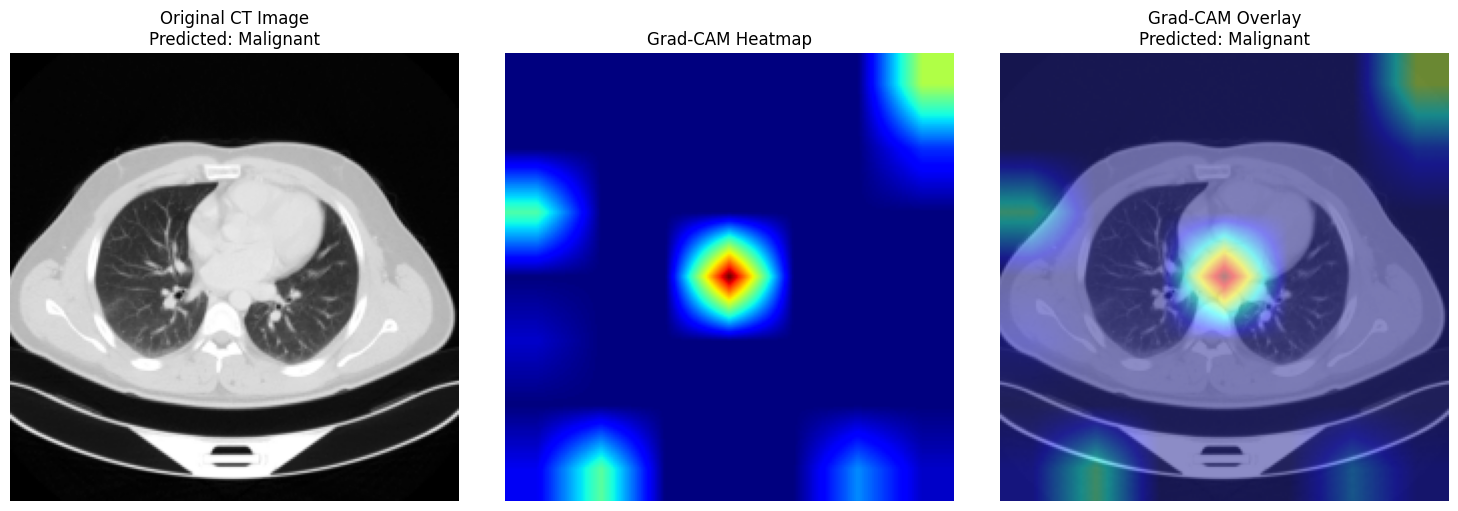

In [ ]:
# ============================================================
# CELL 36 — VISUALIZE GRAD-CAM
# ============================================================

# ------------------------------------------------------------
# 1. Resize original CT image
# ------------------------------------------------------------

gradcam_display = cv2.resize(
    gradcam_original,
    (224, 224),
    interpolation=cv2.INTER_AREA
)

# Convert grayscale CT image to RGB
gradcam_display_rgb = cv2.cvtColor(
    gradcam_display,
    cv2.COLOR_GRAY2RGB
)

# ------------------------------------------------------------
# 2. Create colored heatmap
# ------------------------------------------------------------

heatmap = np.uint8(
    np.clip(cam, 0, 1) * 255
)

heatmap_color = cv2.applyColorMap(
    heatmap,
    cv2.COLORMAP_JET
)

heatmap_color = cv2.cvtColor(
    heatmap_color,
    cv2.COLOR_BGR2RGB
)

# ------------------------------------------------------------
# 3. Overlay heatmap on original CT image
# ------------------------------------------------------------

overlay = cv2.addWeighted(
    gradcam_display_rgb,
    0.55,
    heatmap_color,
    0.45,
    0
)

# ------------------------------------------------------------
# 4. Display results
# ------------------------------------------------------------

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(gradcam_display, cmap="gray")
plt.title(
    f"Original CT Image\nPredicted: {predicted_class_name}"
)
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(cam, cmap="jet", vmin=0, vmax=1)
plt.title("Grad-CAM Heatmap")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(overlay)
plt.title(
    f"Grad-CAM Overlay\nPredicted: {predicted_class_name}"
)
plt.axis("off")

plt.tight_layout()
plt.show()

# **UPLOAD AND CHECK THE DATA**

In [ ]:

# ============================================================
# CELL 40 — HANDCRAFTED FEATURE EXTRACTION
# ============================================================

import numpy as np
import cv2
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from PIL import Image


def extract_handcrafted_for_prediction(image):

    if image is None:
        raise ValueError("Input image is empty or could not be loaded.")

    if image.ndim == 3:
        if image.shape[2] == 4:
            image = cv2.cvtColor(image, cv2.COLOR_BGRA2GRAY)
        else:
            image = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    if image.ndim != 2:
        raise ValueError(
            f"Expected grayscale image, got {image.shape}."
        )

    preprocessing_result = preprocess_image(image)

    normalized = np.asarray(
        preprocessing_result["normalized"],
        dtype=np.float32
    )
    mask = np.asarray(preprocessing_result["mask"])

    if not np.isfinite(normalized).all():
        raise ValueError("Normalized image contains NaN or Inf.")

    processed_uint8 = (
        np.clip(normalized, 0.0, 1.0) * 255.0
    ).astype(np.uint8)

    intensity_features = extract_intensity_features(
        processed_uint8, mask
    )
    glcm_features = extract_glcm_features(
        processed_uint8, mask
    )
    lbp_features = extract_lbp_features(
        processed_uint8, mask
    )
    hog_features = extract_hog_features(
        processed_uint8, mask
    )
    shape_features = extract_shape_features(mask)
    edge_features = extract_edge_features(
        processed_uint8, mask
    )

    raw_features = np.concatenate([
        np.asarray(intensity_features).ravel(),
        np.asarray(glcm_features).ravel(),
        np.asarray(lbp_features).ravel(),
        np.asarray(hog_features).ravel(),
        np.asarray(shape_features).ravel(),
        np.asarray(edge_features).ravel()
    ]).reshape(1, -1).astype(np.float32)

    raw_features = np.nan_to_num(
        raw_features,
        nan=0.0,
        posinf=0.0,
        neginf=0.0
    )

    X = variance_selector.transform(raw_features)
    X = np.delete(X, correlated_features, axis=1)
    X = feature_selector.transform(X)
    X = feature_scaler.transform(X)

    X = np.asarray(X, dtype=np.float32)

    if X.shape != (1, 50):
        raise ValueError(
            f"Expected (1, 50) handcrafted features, got {X.shape}."
        )

    if not np.isfinite(X).all():
        raise ValueError("Handcrafted features contain NaN or Inf.")

    return X, normalized, mask


# ============================================================
# CELL 40A — PREPARE CONVNEXT INPUT IMAGE
# ============================================================

def prepare_image_for_convnext(image):

    if image is None:
        raise ValueError("Input image is empty.")

    if image.ndim == 3:
        if image.shape[2] == 4:
            image = cv2.cvtColor(image, cv2.COLOR_BGRA2GRAY)
        else:
            image = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    processed = prepare_convnext_image(
        image,
        target_size=(224, 224)
    )

    processed = np.asarray(processed, dtype=np.float32)

    if not np.isfinite(processed).all():
        raise ValueError("ConvNeXt image contains NaN or Inf.")

    if processed.min() < 0:
        raise ValueError(
            "Negative image values detected. Verify training preprocessing."
        )

    if processed.max() > 1.0:
        if processed.max() <= 255.0:
            processed = processed / 255.0
        else:
            raise ValueError(
                "Unexpected image intensity range."
            )

    processed_uint8 = (
        np.clip(processed, 0.0, 1.0) * 255.0
    ).astype(np.uint8)

    rgb_image = cv2.cvtColor(
        processed_uint8,
        cv2.COLOR_GRAY2RGB
    )

    pil_image = Image.fromarray(rgb_image)

    tensor = convnext_transform(pil_image).unsqueeze(0)

    return tensor.to(device)


# ============================================================
# CELL 40B — PREDICT ONE CT IMAGE
# ============================================================

def predict_ct_image(image_path):

    # 1. Load image
    image = cv2.imread(
        str(image_path),
        cv2.IMREAD_GRAYSCALE
    )

    if image is None:
        raise FileNotFoundError(
            f"Could not read image: {image_path}"
        )

    # 2. Extract handcrafted features for THIS image
    handcrafted_array, normalized, mask = (
        extract_handcrafted_for_prediction(image)
    )

    handcrafted_tensor = torch.as_tensor(
        handcrafted_array,
        dtype=torch.float32,
        device=device
    )

    # 3. Prepare ConvNeXt input for THIS image
    image_tensor = prepare_image_for_convnext(image)

    # 4. Verify the selected model
    selected_hybrid = best_ft_model
    selected_hybrid.eval()
    convnext.eval()

    if selected_hybrid.network[0].in_features != 82:
        raise ValueError("The hybrid classifier must accept 82 features.")

    if selected_hybrid.network[-1].out_features != len(CLASS_NAMES):
        raise ValueError("Classifier output dimension does not match classes.")

    # 5. Extract differentiable deep features
    with torch.no_grad():

        spatial_features = convnext.features(image_tensor)

        pooled_features = convnext.avgpool(spatial_features)

        deep_features = torch.flatten(
            pooled_features,
            start_dim=1
        )

        # Apply the fitted scaler
        deep_mean = torch.as_tensor(
            deep_scaler.mean_,
            dtype=deep_features.dtype,
            device=device
        )

        deep_scale = torch.as_tensor(
            deep_scaler.scale_,
            dtype=deep_features.dtype,
            device=device
        )

        deep_scaled = (
            deep_features - deep_mean
        ) / deep_scale

        # Apply the fitted PCA
        pca_mean = torch.as_tensor(
            deep_pca.mean_,
            dtype=deep_scaled.dtype,
            device=device
        )

        pca_components = torch.as_tensor(
            deep_pca.components_,
            dtype=deep_scaled.dtype,
            device=device
        )

        deep_reduced = torch.matmul(
            deep_scaled - pca_mean,
            pca_components.T
        )

        # Fuse THIS image's handcrafted and deep features
        fused_features = torch.cat(
            [handcrafted_tensor, deep_reduced],
            dim=1
        )

        if fused_features.shape != (1, 82):
            raise ValueError(
                f"Expected fused features (1, 82), "
                f"got {tuple(fused_features.shape)}."
            )

        logits = selected_hybrid(fused_features)

        probabilities = torch.softmax(logits, dim=1)[0]

    predicted_index = int(torch.argmax(probabilities).item())
    predicted_class = CLASS_NAMES[predicted_index]

    probability_percentages = {
        class_name: float(probabilities[index].item() * 100.0)
        for index, class_name in enumerate(CLASS_NAMES)
    }

    print("=" * 60)
    print("CT IMAGE PREDICTION")
    print("=" * 60)
    print("Image:", image_path)
    print("Predicted class:", predicted_class)
    print("\nClass probabilities:")

    for class_name, probability in probability_percentages.items():
        print(f"{class_name}: {probability:.2f}%")

    print("=" * 60)

    return {
        "image_path": str(image_path),
        "predicted_class": predicted_class,
        "predicted_index": predicted_index,
        "probabilities": probability_percentages,
        "handcrafted_features": handcrafted_tensor,
        "deep_features": deep_reduced.detach(),
        "fused_features": fused_features.detach(),
        "image_tensor": image_tensor,
        "original_image": image,
        "normalized_image": normalized,
        "mask": mask
    }


# ============================================================
# CELL 40C — EXAMPLE USAGE
# ============================================================

sample_image_path = gradcam_image_path

prediction_result = predict_ct_image(sample_image_path)


CT IMAGE PREDICTION
Image: /content/PSG-IQ Lung CT Dataset/PSG-IQ Lung CT Dataset/The IQ-OTHNCCD lung cancer dataset/Malignant cases/Malignant case (336).jpg
Predicted class: Malignant

Class probabilities:
Normal: 0.00%
Benign: 0.00%
Malignant: 100.00%


In [ ]:

# ============================================================
# CELL 41 — CONVNEXT FEATURES FOR UPLOADED IMAGE
# ============================================================

import numpy as np
import cv2
import torch
from PIL import Image


def extract_deep_feature_for_prediction(image):

    if image is None:
        raise ValueError("Input image is empty.")

    if isinstance(image, Image.Image):
        image = np.array(image.convert("L"))
    else:
        image = np.asarray(image)

        if image.ndim == 3:
            if image.shape[2] == 4:
                image = cv2.cvtColor(image, cv2.COLOR_RGBA2GRAY)
            else:
                image = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)

    if image.ndim != 2:
        raise ValueError(
            f"Expected grayscale image, got shape {image.shape}"
        )

    # Use the established ConvNeXt preprocessing function
    image_tensor = prepare_image_for_convnext(image)

    convnext.eval()

    with torch.no_grad():
        spatial_features = convnext.features(image_tensor)
        pooled_features = convnext.avgpool(spatial_features)
        features = torch.flatten(pooled_features, start_dim=1)

    if features.shape != (1, 768):
        raise ValueError(
            f"Expected ConvNeXt features (1, 768), "
            f"got {tuple(features.shape)}"
        )

    if not torch.isfinite(features).all():
        raise ValueError("ConvNeXt features contain NaN or Inf.")

    return features


print("Cell 41 ready: ConvNeXt feature extraction defined.")


Cell 41 ready: ConvNeXt feature extraction defined.


In [ ]:

# ============================================================
# CELL 42 — COMPLETE MODEL PREDICTION
# ============================================================

import numpy as np
import cv2
import torch
from PIL import Image


def predict_uploaded_image(image):

    # --------------------------------------------------------
    # 1. Convert input to grayscale
    # --------------------------------------------------------

    if image is None:
        raise ValueError("Please provide a valid CT image.")

    if isinstance(image, Image.Image):
        image = np.array(image.convert("L"))
    else:
        image = np.asarray(image)

        if image.ndim == 3:
            if image.shape[2] == 4:
                image = cv2.cvtColor(image, cv2.COLOR_RGBA2GRAY)
            else:
                image = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)

    if image.ndim != 2:
        raise ValueError(
            f"Expected grayscale image, got shape {image.shape}"
        )

    # Handle non-uint8 images
    if image.dtype != np.uint8:
        image = np.asarray(image, dtype=np.float32)

        if not np.isfinite(image).all():
            raise ValueError("Input image contains NaN or Inf.")

        if image.min() >= 0 and image.max() <= 1:
            image = image * 255.0

        image = np.clip(image, 0, 255).astype(np.uint8)

    # --------------------------------------------------------
    # 2. Extract this image's handcrafted features
    # --------------------------------------------------------

    handcrafted_array, normalized, mask = (
        extract_handcrafted_for_prediction(image)
    )

    handcrafted_tensor = torch.as_tensor(
        handcrafted_array,
        dtype=torch.float32,
        device=device
    )

    if handcrafted_tensor.shape != (1, 50):
        raise ValueError(
            f"Expected handcrafted features (1, 50), "
            f"got {tuple(handcrafted_tensor.shape)}"
        )

    # --------------------------------------------------------
    # 3. Extract this image's 768 ConvNeXt features
    # --------------------------------------------------------

    deep_features = extract_deep_feature_for_prediction(image)

    deep_features_numpy = deep_features.detach().cpu().numpy()

    # --------------------------------------------------------
    # 4. Apply fitted scaler and PCA in training-time order
    # --------------------------------------------------------

    deep_scaled = deep_scaler.transform(deep_features_numpy)
    deep_reduced = deep_pca.transform(deep_scaled)

    deep_tensor = torch.as_tensor(
        deep_reduced,
        dtype=torch.float32,
        device=device
    )

    if deep_tensor.shape != (1, 32):
        raise ValueError(
            f"Expected PCA-reduced features (1, 32), "
            f"got {tuple(deep_tensor.shape)}"
        )

    # --------------------------------------------------------
    # 5. Fuse 50 handcrafted + 32 deep features
    # --------------------------------------------------------

    fused_features = torch.cat(
        [handcrafted_tensor, deep_tensor],
        dim=1
    )

    if fused_features.shape != (1, 82):
        raise ValueError(
            f"Expected fused features (1, 82), "
            f"got {tuple(fused_features.shape)}"
        )

    if not torch.isfinite(fused_features).all():
        raise ValueError("Fused features contain NaN or Inf.")

    # --------------------------------------------------------
    # 6. Predict with the selected trained classifier
    # --------------------------------------------------------

    selected_model = best_ft_model.to(device)
    selected_model.eval()

    with torch.no_grad():
        logits = selected_model(fused_features)

        probabilities = torch.softmax(logits, dim=1)[0]

    predicted_index = int(torch.argmax(probabilities).item())
    predicted_class = CLASS_NAMES[predicted_index]

    probability_dict = {
        CLASS_NAMES[i]: float(probabilities[i].item())
        for i in range(len(CLASS_NAMES))
    }

    # --------------------------------------------------------
    # 7. Display results
    # --------------------------------------------------------

    print("=" * 60)
    print("CT IMAGE PREDICTION")
    print("=" * 60)
    print("Predicted class:", predicted_class)
    print("\nModel scores:")

    for class_name, probability in probability_dict.items():
        print(f"{class_name}: {probability * 100:.2f}%")

    print("=" * 60)

    return {
        "original": image,
        "segmented": normalized,
        "mask": mask,
        "handcrafted_features": handcrafted_tensor.detach(),
        "deep_features": deep_tensor.detach(),
        "fused_features": fused_features.detach(),
        "logits": logits.detach(),
        "probabilities": probability_dict,
        "predicted_class": predicted_class,
        "predicted_index": predicted_index
    }


In [ ]:

# ============================================================
# CELL 43 — GRAD-CAM FOR ANY UPLOADED IMAGE
# ============================================================

import numpy as np
import cv2
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from PIL import Image


def generate_uploaded_gradcam(image):

    # --------------------------------------------------------
    # 1. Convert input to grayscale
    # --------------------------------------------------------

    if image is None:
        raise ValueError("Please provide a valid CT image.")

    if isinstance(image, Image.Image):
        image = np.array(image.convert("L"))
    else:
        image = np.asarray(image)

        if image.ndim == 3:
            if image.shape[2] == 4:
                image = cv2.cvtColor(image, cv2.COLOR_RGBA2GRAY)
            else:
                image = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)

    if image.ndim != 2:
        raise ValueError(
            f"Expected grayscale image, got shape {image.shape}"
        )

    if image.dtype != np.uint8:
        image = np.asarray(image, dtype=np.float32)

        if not np.isfinite(image).all():
            raise ValueError("Image contains NaN or Inf.")

        if image.min() >= 0 and image.max() <= 1:
            image = image * 255.0

        image = np.clip(image, 0, 255).astype(np.uint8)

    # --------------------------------------------------------
    # 2. Extract handcrafted features for this image
    # --------------------------------------------------------

    handcrafted_array, normalized, mask = (
        extract_handcrafted_for_prediction(image)
    )

    handcrafted_tensor = torch.as_tensor(
        handcrafted_array,
        dtype=torch.float32,
        device=device
    )

    if handcrafted_tensor.shape != (1, 50):
        raise ValueError(
            f"Expected handcrafted features (1, 50), "
            f"got {tuple(handcrafted_tensor.shape)}"
        )

    # --------------------------------------------------------
    # 3. Use the selected trained hybrid classifier
    # --------------------------------------------------------

    selected_model = best_ft_model.to(device)
    selected_model.eval()
    convnext.eval()

    # HybridGradCAMModel must have been defined in Cell 31
    model_gradcam = HybridGradCAMModel(
        convnext_model=convnext,
        hybrid_model=selected_model,
        deep_scaler=deep_scaler,
        deep_pca=deep_pca,
        handcrafted_features=handcrafted_tensor
    ).to(device)

    model_gradcam.eval()

    # --------------------------------------------------------
    # 4. Prepare the ConvNeXt input
    # --------------------------------------------------------

    tensor = prepare_image_for_convnext(image)
    tensor = tensor.detach().clone().requires_grad_(True)

    # --------------------------------------------------------
    # 5. Forward and backward pass
    # --------------------------------------------------------

    model_gradcam.zero_grad(set_to_none=True)

    with torch.enable_grad():

        output = model_gradcam(tensor)

        probabilities = torch.softmax(output, dim=1)[0]

        predicted_index = int(
            torch.argmax(probabilities).item()
        )

        predicted_class = CLASS_NAMES[predicted_index]

        target_score = output[0, predicted_index]
        target_score.backward()

    # --------------------------------------------------------
    # 6. Retrieve activations and gradients
    # --------------------------------------------------------

    activations = model_gradcam.spatial_features

    if activations is None:
        raise RuntimeError("Spatial activations were not captured.")

    gradients = activations.grad

    if gradients is None:
        raise RuntimeError(
            "Gradients are missing. Verify that spatial features "
            "retain gradients in HybridGradCAMModel.forward()."
        )

    if not torch.isfinite(gradients).all():
        raise RuntimeError("Gradients contain NaN or Inf.")

    # --------------------------------------------------------
    # 7. Calculate Grad-CAM
    # --------------------------------------------------------

    weights = gradients.mean(dim=(2, 3), keepdim=True)

    cam_tensor = torch.relu(
        (weights * activations).sum(dim=1, keepdim=True)
    )

    cam_tensor = F.interpolate(
        cam_tensor,
        size=(224, 224),
        mode="bilinear",
        align_corners=False
    )

    cam = (
        cam_tensor[0, 0]
        .detach()
        .cpu()
        .numpy()
    )

    if not np.isfinite(cam).all():
        raise RuntimeError("Grad-CAM contains NaN or Inf.")

    cam_min = float(cam.min())
    cam_max = float(cam.max())

    if cam_max - cam_min < 1e-8:
        raise RuntimeError(
            "Grad-CAM has no meaningful variation for this image."
        )

    cam = (cam - cam_min) / (cam_max - cam_min)

    # --------------------------------------------------------
    # 8. Prepare original image and overlay
    # --------------------------------------------------------

    display_image = cv2.resize(
        image,
        (224, 224),
        interpolation=cv2.INTER_AREA
    )

    display_rgb = cv2.cvtColor(
        display_image,
        cv2.COLOR_GRAY2RGB
    )

    heatmap = np.uint8(np.clip(cam, 0, 1) * 255)

    heatmap_color = cv2.applyColorMap(
        heatmap,
        cv2.COLORMAP_JET
    )

    heatmap_color = cv2.cvtColor(
        heatmap_color,
        cv2.COLOR_BGR2RGB
    )

    overlay = cv2.addWeighted(
        display_rgb,
        0.55,
        heatmap_color,
        0.45,
        0
    )

    # --------------------------------------------------------
    # 9. Display results
    # --------------------------------------------------------

    probability_dict = {
        CLASS_NAMES[i]: float(probabilities[i].item())
        for i in range(len(CLASS_NAMES))
    }

    print("Predicted class:", predicted_class)
    print("Model scores:")

    for name, probability in probability_dict.items():
        print(f"{name}: {probability * 100:.2f}%")

    plt.figure(figsize=(15, 5))

    plt.subplot(1, 3, 1)
    plt.imshow(display_image, cmap="gray")
    plt.title(f"Original CT\nPrediction: {predicted_class}")
    plt.axis("off")

    plt.subplot(1, 3, 2)
    plt.imshow(cam, cmap="jet", vmin=0, vmax=1)
    plt.title("Grad-CAM Heatmap")
    plt.axis("off")

    plt.subplot(1, 3, 3)
    plt.imshow(overlay)
    plt.title("Grad-CAM Overlay")
    plt.axis("off")

    plt.tight_layout()
    plt.show()

    return {
        "original": image,
        "segmented": normalized,
        "mask": mask,
        "gradcam": cam,
        "overlay": overlay,
        "predicted_class": predicted_class,
        "predicted_index": predicted_index,
        "probabilities": probability_dict,
        "fused_features": (
            model_gradcam.fused_features[0]
            .detach()
            .cpu()
            .numpy()
        )
    }

In [ ]:

# ============================================================
# CELL 44A — SAVE SELECTED HYBRID CLASSIFIER CHECKPOINT
# ============================================================

from pathlib import Path
import torch
import os

# ------------------------------------------------------------
# 1. Verify the selected model
# ------------------------------------------------------------

if "best_ft_model" not in globals():
    raise NameError(
        "best_ft_model is missing. Load the selected trained model first."
    )

selected_model = best_ft_model

if not isinstance(selected_model, torch.nn.Module):
    raise TypeError("best_ft_model is not a PyTorch model.")

if selected_model.network[0].in_features != 82:
    raise ValueError("Expected a hybrid model with 82 input features.")

if selected_model.network[-1].out_features != 3:
    raise ValueError("Expected a hybrid model with 3 output classes.")

# ------------------------------------------------------------
# 2. Mount Google Drive if needed
# ------------------------------------------------------------

MODEL_DIR = Path(
    "/content/drive/MyDrive/PG Project work 1/Final Models Trained"
)

if not os.path.isdir("/content/drive/MyDrive"):
    from google.colab import drive
    drive.mount("/content/drive")

MODEL_DIR.mkdir(parents=True, exist_ok=True)

MODEL_PATH = MODEL_DIR / "hybrid_classifier_first_tuned_best.pt"

# ------------------------------------------------------------
# 3. Save the selected checkpoint and metadata
# ------------------------------------------------------------

checkpoint = {
    "model_name": "TunableHybridClassifier",
    "model_state_dict": selected_model.state_dict(),
    "input_features": 82,
    "num_classes": 3,
    "class_names": list(CLASS_NAMES),
    "test_accuracy": globals().get("ft_test_accuracy"),
    "test_macro_f1": globals().get("ft_test_macro_f1")
}

torch.save(checkpoint, MODEL_PATH)

# ------------------------------------------------------------
# 4. Verify the saved file
# ------------------------------------------------------------

if not MODEL_PATH.exists():
    raise RuntimeError("Checkpoint file was not created.")

print("=" * 60)
print("SELECTED HYBRID CLASSIFIER SAVED")
print("=" * 60)
print("Model variable: best_ft_model")
print("Parameters:", sum(p.numel() for p in selected_model.parameters()))
print("Checkpoint:", MODEL_PATH)
print("File size:", f"{MODEL_PATH.stat().st_size:,} bytes")
print("Classes:", CLASS_NAMES)
print("=" * 60)

SELECTED HYBRID CLASSIFIER SAVED
Model variable: best_ft_model
Parameters: 21443
Checkpoint: /content/drive/MyDrive/PG Project work 1/Final Models Trained/hybrid_classifier_first_tuned_best.pt
File size: 94,709 bytes
Classes: ['Normal', 'Benign', 'Malignant']


In [ ]:
# # ============================================================
# # CELL 44A — INSPECT FINAL MODEL CHECKPOINT
# # ============================================================

# import torch
# from pathlib import Path

# MODEL_DIR = Path(
#     "/content/drive/MyDrive/PG Project work 1/Final Models Trained"Final Models Trained
# )

# MODEL_PATH = MODEL_DIR / "hybrid_classifier_final.pth"

# if not MODEL_PATH.exists():
#     raise FileNotFoundError(
#         f"Checkpoint not found: {MODEL_PATH}"
#     )

# checkpoint = torch.load(
#     MODEL_PATH,
#     map_location="cpu",
#     weights_only=False
# )

# if isinstance(checkpoint, dict) and "model_state_dict" in checkpoint:
#     state_dict = checkpoint["model_state_dict"]
# else:
#     state_dict = checkpoint

# print("=" * 60)
# print("CHECKPOINT ARCHITECTURE INSPECTION")
# print("=" * 60)

# for key, value in state_dict.items():
#     if isinstance(value, torch.Tensor):
#         print(f"{key}: {tuple(value.shape)}")

# print("=" * 60)

In [ ]:

# ============================================================
# CELL 44B — SET FINAL HYBRID CLASSIFIER
# ============================================================

import torch

if "best_ft_model" not in globals():
    raise NameError(
        "best_ft_model is unavailable. Load the selected trained model first."
    )

final_hybrid_classifier = best_ft_model.to(device)
final_hybrid_model = final_hybrid_classifier

final_hybrid_model.eval()

first_layer = final_hybrid_model.network[0]
last_layer = final_hybrid_model.network[-1]

assert first_layer.in_features == 82
assert last_layer.out_features == len(CLASS_NAMES)

print("=" * 60)
print("FINAL HYBRID CLASSIFIER VERIFIED")
print("=" * 60)
print("Selected model: best_ft_model")
print("Same model object:", final_hybrid_model is best_ft_model)
print("Input features:", first_layer.in_features)
print("Output classes:", last_layer.out_features)
print("Parameters:", sum(p.numel() for p in final_hybrid_model.parameters()))
print("=" * 60)

FINAL HYBRID CLASSIFIER VERIFIED
Selected model: best_ft_model
Same model object: True
Input features: 82
Output classes: 3
Parameters: 21443


In [ ]:

# ============================================================
# CELL 44C — TEST COMPLETE UPLOAD PIPELINE
# ============================================================

import cv2

test_image = cv2.imread(
    str(gradcam_image_path),
    cv2.IMREAD_GRAYSCALE
)

if test_image is None:
    raise FileNotFoundError(
        f"Could not load CT image: {gradcam_image_path}"
    )

result = predict_uploaded_image(test_image)

print("=" * 60)
print("PREDICTION RESULT")
print("=" * 60)
print("Predicted class:", result["predicted_class"])

for class_name, probability in result["probabilities"].items():
    print(f"{class_name}: {probability * 100:.2f}%")

print("=" * 60)

CT IMAGE PREDICTION
Predicted class: Malignant

Model scores:
Normal: 0.00%
Benign: 0.00%
Malignant: 100.00%
PREDICTION RESULT
Predicted class: Malignant
Normal: 0.00%
Benign: 0.00%
Malignant: 100.00%


Generating Grad-CAM for the current CT image...


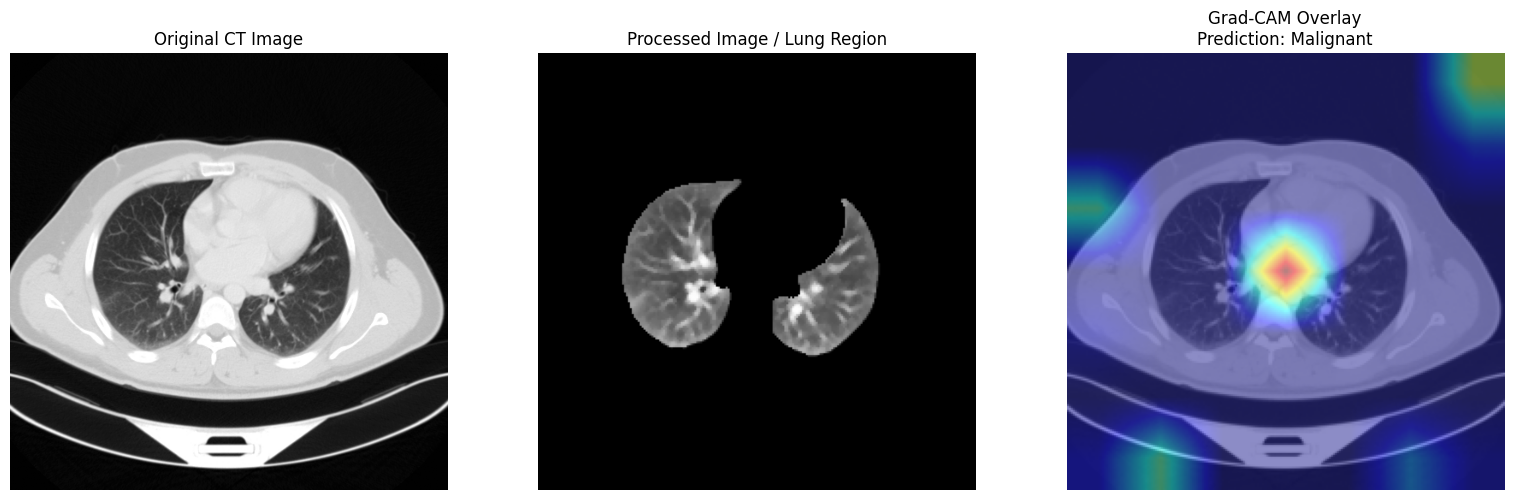

FINAL VISUALIZATION RESULTS
Predicted class: Malignant

Model-estimated class scores:
Normal: 0.00%
Benign: 0.00%
Malignant: 100.00%


In [ ]:

# ============================================================
# CELL 45 — COMPLETE VISUAL OUTPUT
# Original CT + Processed Region + Grad-CAM Overlay
# ============================================================

import numpy as np
import cv2
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. VALIDATE PREDICTION RESULT
# ------------------------------------------------------------

if "result" not in globals() or not isinstance(result, dict):
    raise ValueError(
        "Prediction result is missing. Run Cell 44C first."
    )

if "original" not in result:
    raise KeyError(
        "Missing original image. Run the prediction cell again."
    )

if "predicted_class" not in result:
    raise KeyError(
        "Missing predicted_class. Run the prediction cell again."
    )

# ------------------------------------------------------------
# 2. PREPARE ORIGINAL IMAGE
# ------------------------------------------------------------

original = np.asarray(result["original"])

if original.ndim == 3:
    if original.shape[2] == 4:
        original = cv2.cvtColor(original, cv2.COLOR_RGBA2GRAY)
    else:
        original = cv2.cvtColor(original, cv2.COLOR_RGB2GRAY)

if original.ndim != 2:
    raise ValueError(
        f"Expected grayscale image, got {original.shape}"
    )

if original.dtype != np.uint8:
    original = np.nan_to_num(original).astype(np.float32)

    if original.size and original.min() >= 0 and original.max() <= 1:
        original = original * 255.0

    original = np.clip(original, 0, 255).astype(np.uint8)

result["original"] = original

# ------------------------------------------------------------
# 3. PREPARE PROCESSED IMAGE
# ------------------------------------------------------------

processed_image = result.get("segmented", original)

if processed_image is None:
    processed_image = original

processed_image = np.asarray(processed_image)

if processed_image.ndim == 3:
    if processed_image.shape[2] == 4:
        processed_image = cv2.cvtColor(
            processed_image, cv2.COLOR_RGBA2GRAY
        )
    else:
        processed_image = cv2.cvtColor(
            processed_image, cv2.COLOR_RGB2GRAY
        )

if processed_image.dtype != np.uint8:
    processed_image = np.nan_to_num(
        processed_image.astype(np.float32)
    )

    if (
        processed_image.size
        and processed_image.min() >= 0
        and processed_image.max() <= 1
    ):
        processed_image = processed_image * 255.0

    processed_image = np.clip(
        processed_image, 0, 255
    ).astype(np.uint8)

# ------------------------------------------------------------
# 4. GENERATE GRAD-CAM IF NOT ALREADY AVAILABLE
# ------------------------------------------------------------

if "overlay" not in result or result["overlay"] is None:

    print("Generating Grad-CAM for the current CT image...")

    if "best_ft_model" not in globals():
        raise NameError("Selected model best_ft_model is missing.")

    if "HybridGradCAMModel" not in globals():
        raise NameError(
            "HybridGradCAMModel is missing. Run Cell 31 first."
        )

    if "extract_handcrafted_for_prediction" not in globals():
        raise NameError(
            "Handcrafted feature extraction is missing."
        )

    if "prepare_image_for_convnext" not in globals():
        raise NameError(
            "ConvNeXt preprocessing function is missing."
        )

    # Extract features from the same image being displayed
    handcrafted_array, normalized, mask = (
        extract_handcrafted_for_prediction(original)
    )

    handcrafted_tensor = torch.as_tensor(
        handcrafted_array,
        dtype=torch.float32,
        device=device
    )

    if handcrafted_tensor.shape != (1, 50):
        raise ValueError(
            f"Expected handcrafted features (1, 50), "
            f"got {tuple(handcrafted_tensor.shape)}"
        )

    # Create wrapper with the selected trained classifier
    gradcam_visual_model = HybridGradCAMModel(
        convnext_model=convnext,
        hybrid_model=best_ft_model,
        deep_scaler=deep_scaler,
        deep_pca=deep_pca,
        handcrafted_features=handcrafted_tensor
    ).to(device)

    gradcam_visual_model.eval()
    gradcam_visual_model.zero_grad(set_to_none=True)

    image_tensor = prepare_image_for_convnext(original)

    image_tensor = (
        image_tensor.detach()
        .clone()
        .to(device)
        .requires_grad_(True)
    )

    # Forward and backward passes required for Grad-CAM
    with torch.enable_grad():

        logits = gradcam_visual_model(image_tensor)

        if logits.shape != (1, len(CLASS_NAMES)):
            raise ValueError(
                f"Unexpected output shape: {tuple(logits.shape)}"
            )

        predicted_index = int(logits.argmax(dim=1).item())
        target_score = logits[0, predicted_index]

        target_score.backward()

    activations = gradcam_visual_model.spatial_features

    if activations is None:
        raise RuntimeError("Grad-CAM activations were not captured.")

    gradients = activations.grad

    if gradients is None:
        raise RuntimeError(
            "Grad-CAM gradients are missing. Check the wrapper's "
            "retain_grad() call and gradient connectivity."
        )

    if not torch.isfinite(gradients).all():
        raise RuntimeError("Grad-CAM gradients contain NaN or Inf.")

    # Calculate channel weights
    weights = gradients.mean(
        dim=(2, 3),
        keepdim=True
    )

    cam_tensor = torch.relu(
        (weights * activations).sum(dim=1, keepdim=True)
    )

    cam_tensor = F.interpolate(
        cam_tensor,
        size=(224, 224),
        mode="bilinear",
        align_corners=False
    )

    cam = (
        cam_tensor[0, 0]
        .detach()
        .cpu()
        .numpy()
    )

    if not np.isfinite(cam).all():
        raise RuntimeError("Grad-CAM heatmap contains NaN or Inf.")

    cam_min = float(cam.min())
    cam_max = float(cam.max())

    if cam_max - cam_min < 1e-8:
        raise RuntimeError(
            "Grad-CAM heatmap has no meaningful variation."
        )

    cam = (cam - cam_min) / (cam_max - cam_min)

    # Create overlay
    display_image = cv2.resize(
        original,
        (224, 224),
        interpolation=cv2.INTER_AREA
    )

    display_rgb = cv2.cvtColor(
        display_image,
        cv2.COLOR_GRAY2RGB
    )

    heatmap = np.uint8(np.clip(cam, 0, 1) * 255)

    heatmap_color = cv2.applyColorMap(
        heatmap,
        cv2.COLORMAP_JET
    )

    heatmap_rgb = cv2.cvtColor(
        heatmap_color,
        cv2.COLOR_BGR2RGB
    )

    overlay = cv2.addWeighted(
        display_rgb,
        0.55,
        heatmap_rgb,
        0.45,
        0
    )

    # Save outputs in result
    result["gradcam"] = cam
    result["overlay"] = overlay
    result["predicted_index"] = predicted_index
    result["segmented"] = normalized
    result["mask"] = mask

# ------------------------------------------------------------
# 5. VERIFY OVERLAY
# ------------------------------------------------------------

overlay = np.asarray(result["overlay"])

if overlay.ndim != 3 or overlay.shape[2] != 3:
    raise ValueError(
        f"Expected RGB overlay, got shape {overlay.shape}"
    )

# ------------------------------------------------------------
# 6. DISPLAY ALL THREE IMAGES
# ------------------------------------------------------------

plt.figure(figsize=(16, 5))

plt.subplot(1, 3, 1)
plt.imshow(original, cmap="gray")
plt.title("Original CT Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(processed_image, cmap="gray")
plt.title("Processed Image / Lung Region")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(overlay)
plt.title(
    f"Grad-CAM Overlay\nPrediction: {result['predicted_class']}"
)
plt.axis("off")

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 7. DISPLAY CLASS SCORES
# ------------------------------------------------------------

print("=" * 60)
print("FINAL VISUALIZATION RESULTS")
print("=" * 60)
print("Predicted class:", result["predicted_class"])

if "probabilities" in result:
    print("\nModel-estimated class scores:")

    for class_name, probability in result["probabilities"].items():
        print(f"{class_name}: {probability * 100:.2f}%")

print("=" * 60)

In [ ]:

# ============================================================
# FIX — RELOAD THE ACTUAL SAVED HYBRID CLASSIFIER
# Architecture inferred from checkpoint tensor shapes
# ============================================================

# ============================================================
# FIX — VERIFY THE SELECTED HYBRID CLASSIFIER
# ============================================================

import torch

# ------------------------------------------------------------
# 1. Verify the selected trained model
# ------------------------------------------------------------

if "best_ft_model" not in globals():
    raise NameError(
        "best_ft_model is missing. Load the selected trained model first."
    )

final_hybrid_model = best_ft_model.to(device)
final_hybrid_model.eval()

# ------------------------------------------------------------
# 2. Verify architecture dimensions
# ------------------------------------------------------------

first_layer = final_hybrid_model.network[0]
last_layer = final_hybrid_model.network[-1]

assert first_layer.in_features == 82, (
    f"Expected 82 input features, got {first_layer.in_features}"
)

assert last_layer.out_features == 3, (
    f"Expected 3 output classes, got {last_layer.out_features}"
)

# ------------------------------------------------------------
# 3. Verify parameter count
# ------------------------------------------------------------

parameter_count = sum(
    p.numel() for p in final_hybrid_model.parameters()
)

assert parameter_count == 21443, (
    f"Expected 21,443 parameters, got {parameter_count}. "
    "Check that this is the intended selected model."
)

# ------------------------------------------------------------
# 4. Test output dimensions
# ------------------------------------------------------------

dummy_input = torch.randn(2, 82, device=device)

with torch.no_grad():
    output = final_hybrid_model(dummy_input)

assert output.shape == (2, 3), (
    f"Unexpected output shape: {tuple(output.shape)}"
)

# ------------------------------------------------------------
# 5. Set consistent model references
# ------------------------------------------------------------

final_hybrid_classifier = final_hybrid_model

print("=" * 60)
print("SELECTED HYBRID CLASSIFIER VERIFIED")
print("=" * 60)
print("Model:", type(final_hybrid_model).__name__)
print("Parameters:", parameter_count)
print("Input features:", first_layer.in_features)
print("Output classes:", last_layer.out_features)
print("Output shape:", tuple(output.shape))
print("Device:", device)
print("Status: Ready for inference")
print("=" * 60)


SELECTED HYBRID CLASSIFIER VERIFIED
Model: TunableHybridClassifier
Parameters: 21443
Input features: 82
Output classes: 3
Output shape: (2, 3)
Device: cpu
Status: Ready for inference


Result directory: /content/drive/MyDrive/PG Project work 1/Final Models Trained/Prediction Results

UPLOAD CT IMAGE FOR AI-ASSISTED PREDICTION


Saving Malignant 21.png to Malignant 21.png
Uploaded: Malignant 21.png
Original image shape: (469, 560)

Processing uploaded CT image...
Predicted class: Malignant
Model scores:
Normal: 0.00%
Benign: 0.00%
Malignant: 100.00%


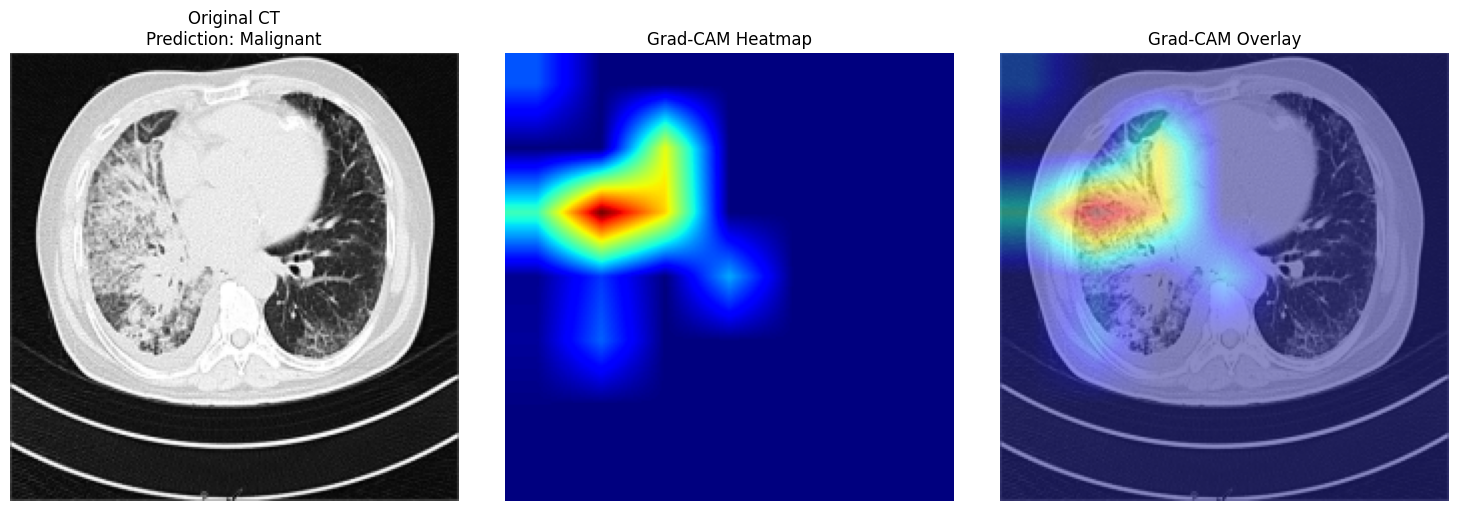


AI-ASSISTED LUNG CT PREDICTION
Uploaded image: Malignant 21.png
Predicted class: Malignant

Model-estimated class scores:
  Normal      : 0.00%
  Benign      : 0.00%
  Malignant   : 100.00%


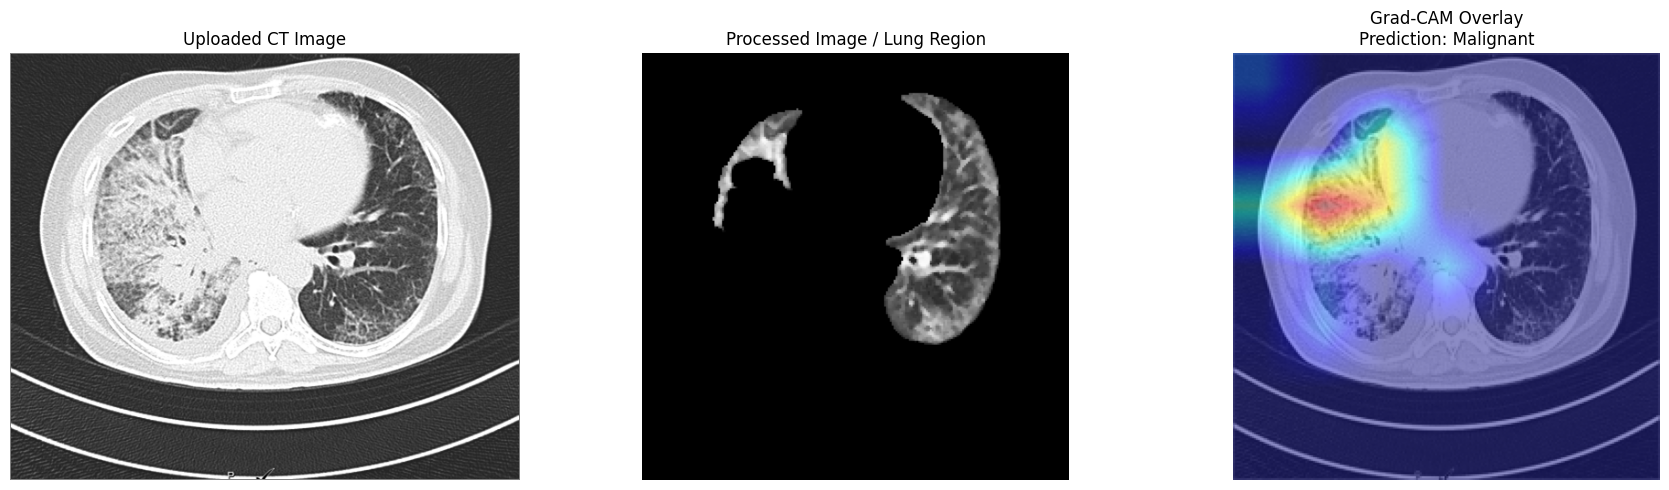


USER-FRIENDLY RESULT

The AI model predicts the image as:

    MALIGNANT

Model score for this class: 100.00%

Grad-CAM highlights image regions that influenced
the model's prediction.

This is an AI-assisted research output, not a medical
diagnosis. A qualified clinician must interpret the CT
scan and confirm any clinical findings.


RESULT STORED SUCCESSFULLY
Prediction: Malignant
Model score: 100.00%
Result file: /content/drive/MyDrive/PG Project work 1/Final Models Trained/Prediction Results/prediction_result_20261013_203658.joblib
Original image: /content/drive/MyDrive/PG Project work 1/Final Models Trained/Prediction Results/20261013_203658_original.png
Processed image: /content/drive/MyDrive/PG Project work 1/Final Models Trained/Prediction Results/20261013_203658_processed.png
Grad-CAM image: /content/drive/MyDrive/PG Project work 1/Final Models Trained/Prediction Results/20261013_203658_gradcam.png
Storage directory: /content/drive/MyDrive/PG Project work 1/Final Models Train

In [ ]:

# ============================================================
# CELL 47 — UPLOAD CT → HYBRID PREDICTION → GRAD-CAM
#             → DISPLAY RESULT → STORE RESULT
# ============================================================

from google.colab import files, drive
from PIL import Image
from pathlib import Path
from datetime import datetime
import io
import joblib
import numpy as np
import matplotlib.pyplot as plt
import torch
import cv2

# ============================================================
# 1. VERIFY REQUIRED FUNCTIONS AND MODELS
# ============================================================

required_objects = [
    "generate_uploaded_gradcam",
    "best_ft_model",
    "HybridGradCAMModel",
    "convnext",
    "deep_scaler",
    "deep_pca",
    "extract_handcrafted_for_prediction",
    "prepare_image_for_convnext",
    "CLASS_NAMES",
    "device"
]

missing_objects = [
    name for name in required_objects
    if name not in globals()
]

if missing_objects:
    raise NameError(
        f"Missing required objects: {missing_objects}. "
        "Run the corresponding model and preprocessing cells first."
    )

# ============================================================
# 2. MOUNT GOOGLE DRIVE
# ============================================================

if not Path("/content/drive/MyDrive").exists():
    drive.mount("/content/drive")

# ============================================================
# 3. RESULT STORAGE DIRECTORY
# ============================================================

RESULT_DIR = Path(
    "/content/drive/MyDrive/PG Project work 1/"
    "Final Models Trained/Prediction Results"
)

RESULT_DIR.mkdir(parents=True, exist_ok=True)

print("Result directory:", RESULT_DIR)

# ============================================================
# 4. UPLOAD CT IMAGE
# ============================================================

print("\n" + "=" * 70)
print("UPLOAD CT IMAGE FOR AI-ASSISTED PREDICTION")
print("=" * 70)

uploaded = files.upload()

if not uploaded:
    print("No image selected.")
    current_result = None
    result = None

else:
    filename = next(iter(uploaded))
    image_bytes = uploaded[filename]

    print("Uploaded:", filename)

    # ========================================================
    # 5. READ UPLOADED IMAGE
    # ========================================================

    try:
        pil_image = Image.open(
            io.BytesIO(image_bytes)
        ).convert("L")
    except Exception as exc:
        raise ValueError(
            "The uploaded file could not be opened as an image."
        ) from exc

    image = np.asarray(pil_image, dtype=np.uint8)

    print("Original image shape:", image.shape)

    # ========================================================
    # 6. GENERATE PREDICTION AND GRAD-CAM
    # ========================================================

    print("\nProcessing uploaded CT image...")

    current_result = generate_uploaded_gradcam(image)

    # ========================================================
    # 7. VALIDATE FUNCTION OUTPUT
    # ========================================================

    required_result_keys = [
        "original",
        "segmented",
        "mask",
        "overlay",
        "predicted_class",
        "probabilities"
    ]

    missing_keys = [
        key for key in required_result_keys
        if key not in current_result
    ]

    if missing_keys:
        raise KeyError(
            "Grad-CAM function did not return required keys: "
            f"{missing_keys}"
        )

    # ========================================================
    # 8. ADD METADATA
    # ========================================================

    timestamp_dt = datetime.now()
    timestamp = timestamp_dt.strftime("%Y%m%d_%H%M%S")

    current_result["filename"] = filename
    current_result["uploaded_image"] = image
    current_result["timestamp"] = timestamp_dt.strftime(
        "%Y-%m-%d %H:%M:%S"
    )
    current_result["model"] = (
        "ConvNeXt-Tiny + 50 Handcrafted Features + "
        "32 PCA Features + Selected Hybrid Classifier"
    )
    current_result["selected_classifier"] = "best_ft_model"
    current_result["gradcam_available"] = True

    predicted_class = current_result["predicted_class"]
    probabilities = current_result["probabilities"]

    # ========================================================
    # 9. DISPLAY PREDICTION
    # ========================================================

    print("\n" + "=" * 70)
    print("AI-ASSISTED LUNG CT PREDICTION")
    print("=" * 70)

    print("Uploaded image:", filename)
    print("Predicted class:", predicted_class)
    print("\nModel-estimated class scores:")

    for class_name in CLASS_NAMES:
        if class_name in probabilities:
            score = float(probabilities[class_name])
            print(f"  {class_name:<12}: {score * 100:.2f}%")

    # ========================================================
    # 10. DISPLAY ORIGINAL + PROCESSED + GRAD-CAM
    # ========================================================

    original_display = np.asarray(current_result["original"])
    segmented_display = np.asarray(current_result["segmented"])
    overlay_display = np.asarray(current_result["overlay"])

    # Safely convert processed image to displayable grayscale
    if segmented_display.dtype != np.uint8:
        segmented_display = np.nan_to_num(
            segmented_display.astype(np.float32)
        )

        if (
            segmented_display.size
            and segmented_display.min() >= 0
            and segmented_display.max() <= 1
        ):
            segmented_display = segmented_display * 255.0

        segmented_display = np.clip(
            segmented_display, 0, 255
        ).astype(np.uint8)

    # Convert overlay to uint8 if needed
    if overlay_display.dtype != np.uint8:
        overlay_display = np.nan_to_num(
            overlay_display.astype(np.float32)
        )

        if (
            overlay_display.size
            and overlay_display.min() >= 0
            and overlay_display.max() <= 1
        ):
            overlay_display = overlay_display * 255.0

        overlay_display = np.clip(
            overlay_display, 0, 255
        ).astype(np.uint8)

    plt.figure(figsize=(18, 5))

    plt.subplot(1, 3, 1)
    plt.imshow(original_display, cmap="gray")
    plt.title("Uploaded CT Image")
    plt.axis("off")

    plt.subplot(1, 3, 2)
    plt.imshow(segmented_display, cmap="gray")
    plt.title("Processed Image / Lung Region")
    plt.axis("off")

    plt.subplot(1, 3, 3)
    plt.imshow(overlay_display)
    plt.title(f"Grad-CAM Overlay\nPrediction: {predicted_class}")
    plt.axis("off")

    plt.tight_layout()
    plt.show()

    # ========================================================
    # 11. USER-FRIENDLY RESULT
    # ========================================================

    confidence = float(probabilities[predicted_class]) * 100.0

    print("\n" + "=" * 70)
    print("USER-FRIENDLY RESULT")
    print("=" * 70)

    print(f"""
The AI model predicts the image as:

    {predicted_class.upper()}

Model score for this class: {confidence:.2f}%

Grad-CAM highlights image regions that influenced
the model's prediction.

This is an AI-assisted research output, not a medical
diagnosis. A qualified clinician must interpret the CT
scan and confirm any clinical findings.
""")

    # ========================================================
    # 12. SAVE RESULT FILE
    # ========================================================

    result_path = RESULT_DIR / f"prediction_result_{timestamp}.joblib"

    original_path = RESULT_DIR / f"{timestamp}_original.png"
    segmented_path = RESULT_DIR / f"{timestamp}_processed.png"
    overlay_path = RESULT_DIR / f"{timestamp}_gradcam.png"

    # Save the result dictionary
    current_result["result_file"] = str(result_path)
    current_result["original_file"] = str(original_path)
    current_result["segmented_file"] = str(segmented_path)
    current_result["gradcam_file"] = str(overlay_path)

    joblib.dump(current_result, result_path)

    # Save original image
    Image.fromarray(
        np.asarray(original_display, dtype=np.uint8)
    ).save(original_path)

    # Save processed image
    Image.fromarray(
        np.asarray(segmented_display, dtype=np.uint8)
    ).save(segmented_path)

    # Save Grad-CAM overlay
    Image.fromarray(
        np.asarray(overlay_display, dtype=np.uint8)
    ).save(overlay_path)

    # ========================================================
    # 13. FINAL STATUS
    # ========================================================

    print("\n" + "=" * 70)
    print("RESULT STORED SUCCESSFULLY")
    print("=" * 70)

    print("Prediction:", predicted_class)
    print(f"Model score: {confidence:.2f}%")
    print("Result file:", result_path)
    print("Original image:", original_path)
    print("Processed image:", segmented_path)
    print("Grad-CAM image:", overlay_path)
    print("Storage directory:", RESULT_DIR)

    print("=" * 70)

    # Expose the latest result to subsequent notebook cells
    result = current_result

    print("Latest result is available in variable: result")


# **GEMINI MODEL TO CONNECT WITH LLM**

In [ ]:
# ============================================================
# CELL 48A — CHECK AVAILABLE GEMINI MODELS
# ============================================================

from google import genai
from google.colab import userdata

# ------------------------------------------------------------
# 1. Retrieve API key from Colab Secrets
# ------------------------------------------------------------

GEMINI_API_KEY = userdata.get("GEMINI_API_KEY")

if not GEMINI_API_KEY:
    raise ValueError(
        "GEMINI_API_KEY was not found in Colab Secrets. "
        "Add it under Colab Secrets and enable notebook access."
    )

# ------------------------------------------------------------
# 2. Initialize Gemini client
# ------------------------------------------------------------

gemini_client = genai.Client(
    api_key=GEMINI_API_KEY
)

# ------------------------------------------------------------
# 3. List available models
# ------------------------------------------------------------

print("=" * 75)
print("AVAILABLE GEMINI MODELS")
print("=" * 75)

available_models = []

try:
    for model_info in gemini_client.models.list():

        model_name = model_info.name

        # Some SDK versions expose supported_actions;
        # others expose supported_generation_methods.
        supported_methods = getattr(
            model_info,
            "supported_actions",
            None
        )

        if supported_methods is None:
            supported_methods = getattr(
                model_info,
                "supported_generation_methods",
                None
            )

        print("\nModel:", model_name)

        if supported_methods:
            print("Supported actions:", supported_methods)

        available_models.append({
            "name": model_name,
            "supported_actions": supported_methods
        })

except Exception as exc:
    print("\nUnable to list Gemini models.")
    print("Error type:", type(exc).__name__)
    print("Details:", str(exc))
    raise

# ------------------------------------------------------------
# 4. Summary
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("MODEL LIST SUMMARY")
print("=" * 75)

print("Total models returned:", len(available_models))

for model_info in available_models:
    print("-", model_info["name"])

print("=" * 75)

AVAILABLE GEMINI MODELS

Model: models/gemini-2.5-flash
Supported actions: ['generateContent', 'countTokens', 'createCachedContent', 'batchGenerateContent']

Model: models/gemini-2.5-pro
Supported actions: ['generateContent', 'countTokens', 'createCachedContent', 'batchGenerateContent']

Model: models/gemini-2.5-flash-preview-tts
Supported actions: ['countTokens', 'generateContent']

Model: models/gemini-2.5-pro-preview-tts
Supported actions: ['countTokens', 'generateContent', 'batchGenerateContent']

Model: models/gemma-4-26b-a4b-it
Supported actions: ['generateContent', 'countTokens']

Model: models/gemma-4-31b-it
Supported actions: ['generateContent', 'countTokens']

Model: models/gemini-flash-latest
Supported actions: ['generateContent', 'countTokens', 'createCachedContent', 'batchGenerateContent']

Model: models/gemini-flash-lite-latest
Supported actions: ['generateContent', 'countTokens', 'createCachedContent', 'batchGenerateContent']

Model: models/gemini-pro-latest
Supported ac

In [ ]:
# ============================================================
# CELL 48B — FIND USABLE GEMINI MODELS
# ============================================================

print("=" * 75)
print("CHECKING GEMINI MODELS AVAILABLE FOR YOUR API KEY")
print("=" * 75)

usable_models = []

for model in gemini_client.models.list():

    model_name = model.name

    supported_actions = getattr(
        model,
        "supported_actions",
        []
    )

    # Check whether generateContent is supported
    if (
        "generateContent" in supported_actions
        or "generate_content" in supported_actions
    ):

        usable_models.append(
            model_name
        )

        print(
            f"\n✓ {model_name}"
        )

        print(
            "  Supported:",
            supported_actions
        )


print("\n" + "=" * 75)

if usable_models:

    print(
        "USABLE GEMINI MODELS:"
    )

    for i, model_name in enumerate(
        usable_models,
        start=1
    ):

        print(
            f"{i}. {model_name}"
        )

else:

    print(
        "No models supporting generateContent "
        "were found for this API key."
    )

print("=" * 75)

CHECKING GEMINI MODELS AVAILABLE FOR YOUR API KEY

✓ models/gemini-2.5-flash
  Supported: ['generateContent', 'countTokens', 'createCachedContent', 'batchGenerateContent']

✓ models/gemini-2.5-pro
  Supported: ['generateContent', 'countTokens', 'createCachedContent', 'batchGenerateContent']

✓ models/gemini-2.5-flash-preview-tts
  Supported: ['countTokens', 'generateContent']

✓ models/gemini-2.5-pro-preview-tts
  Supported: ['countTokens', 'generateContent', 'batchGenerateContent']

✓ models/gemma-4-26b-a4b-it
  Supported: ['generateContent', 'countTokens']

✓ models/gemma-4-31b-it
  Supported: ['generateContent', 'countTokens']

✓ models/gemini-flash-latest
  Supported: ['generateContent', 'countTokens', 'createCachedContent', 'batchGenerateContent']

✓ models/gemini-flash-lite-latest
  Supported: ['generateContent', 'countTokens', 'createCachedContent', 'batchGenerateContent']

✓ models/gemini-pro-latest
  Supported: ['generateContent', 'countTokens', 'createCachedContent', 'batchGe

In [ ]:
# ============================================================
# CELL 48 — GEMINI LLM EXPLANATION
# SAFE MEDICAL WORDING VERSION
# ============================================================

from google import genai
from google.genai import types
from google.colab import userdata

from PIL import Image
import io
import joblib
from pathlib import Path


# ============================================================
# 1. GET GEMINI API KEY
# ============================================================

GEMINI_API_KEY = userdata.get(
    "GEMINI_API_KEY"
)

if not GEMINI_API_KEY:
    raise ValueError(
        "GEMINI_API_KEY was not found in Colab Secrets."
    )


# ============================================================
# 2. INITIALIZE GEMINI
# ============================================================

gemini_client = genai.Client(
    api_key=GEMINI_API_KEY
)

# GEMINI_MODEL = "gemini-3.5-flash"
GEMINI_MODEL = "gemini-3.5-flash-lite"


print("=" * 70)
print("GEMINI INITIALIZED")
print("=" * 70)

print(
    "Gemini model:",
    GEMINI_MODEL
)

print("=" * 70)


# ============================================================
# 3. CHECK RESULT FROM CELL 47
# ============================================================

if result is None:

    raise ValueError(
        "No prediction result found. "
        "Please run Cell 47 first."
    )


# ============================================================
# 4. GET EXISTING MODEL OUTPUT
# ============================================================

predicted_class = result[
    "predicted_class"
]

probabilities = result[
    "probabilities"
]


# ============================================================
# 5. PROBABILITY VALUES
# ============================================================

normal_probability = (
    probabilities["Normal"] * 100
)

benign_probability = (
    probabilities["Benign"] * 100
)

malignant_probability = (
    probabilities["Malignant"] * 100
)


# ============================================================
# 6. DISPLAY EXISTING MODEL RESULT
# ============================================================

print("\n" + "=" * 70)
print("EXISTING AI MODEL OUTPUT")
print("=" * 70)

print(
    f"\nPredicted category: {predicted_class}"
)

print("\nAI model-estimated probabilities:")

print(
    f"Normal      : {normal_probability:.2f}%"
)

print(
    f"Benign      : {benign_probability:.2f}%"
)

print(
    f"Malignant   : {malignant_probability:.2f}%"
)


# ============================================================
# 7. CREATE SAFE GEMINI PROMPT
# ============================================================

llm_prompt = f"""
You are an AI-assisted explanation assistant for a
lung CT image classification research prototype.

A trained AI classification model has already processed
the uploaded CT image.

You are NOT the classification model.

Your task is ONLY to explain the existing AI model output
in simple and cautious language.

============================================================
EXISTING AI MODEL OUTPUT
============================================================

The AI model's predicted category is:

{predicted_class}

The AI model estimated the following probabilities:

Normal:
{normal_probability:.2f}%

Benign:
{benign_probability:.2f}%

Malignant:
{malignant_probability:.2f}%

============================================================
IMPORTANT MEDICAL SAFETY RULES
============================================================

Follow these rules strictly:

1. Do NOT change the supplied model prediction.

2. Do NOT override the model prediction.

3. Do NOT state that the patient definitely has or does
   not have cancer.

4. Do NOT use wording such as:
   "Cancer detected",
   "The patient has cancer",
   "No cancer",
   "Definitely normal",
   "Definitely benign",
   or "Definitely malignant".

5. Always describe the percentages as:
   "AI model-estimated probabilities" or
   "estimated probabilities from the AI model".

6. Clearly explain that an AI model can make incorrect
   predictions.

7. Clearly state that the AI result is a preliminary
   AI-assisted prediction and NOT a medical diagnosis.

8. Clearly recommend consultation with a qualified
   doctor/radiologist for confirmation and clinical
   interpretation.

9. Do not invent patient information.

10. Do not invent clinical findings.

============================================================
GRAD-CAM
============================================================

The attached image is the Grad-CAM visualization generated
by the trained AI model.

Explain that Grad-CAM highlights regions of the image that
contributed to the model's prediction.

IMPORTANT:

Do NOT say that the highlighted region is definitely a
tumor, cancer, nodule, lesion, or abnormality.

Grad-CAM is an explanation/visualization technique and does
not by itself confirm or clinically localize a disease.

============================================================
RESPONSE FORMAT
============================================================

Use exactly these sections:

### AI-Assisted Result

Explain that the AI model estimates the probability of
the uploaded CT image belonging to the predicted category.

State the predicted category exactly as supplied.

Use wording such as:

"The AI model estimates a probability of XX.XX% for
the [category] category."

Do not call this a confirmed diagnosis.

### Model-Estimated Probabilities

Briefly list:

Normal: XX.XX%
Benign: XX.XX%
Malignant: XX.XX%

Explain that these are probabilities estimated by the
AI model and should not be interpreted as confirmed
clinical probabilities.

### Grad-CAM Explanation

Explain in simple language that the highlighted regions
represent areas that contributed to the model's prediction.

Clearly state that the highlighted areas are not confirmed
lesions or cancerous regions.

### Interpretation

Explain the result cautiously.

Mention that the AI model has assigned the highest
estimated probability to the predicted category, but
the prediction may be incorrect.

### Important Clinical Note

Use clear wording similar to:

"This is an AI-assisted preliminary prediction and not
a medical diagnosis. AI models may sometimes produce
incorrect predictions. For confirmation and proper
clinical interpretation, please consult a qualified
doctor/radiologist."

Do not make the wording frightening or overly technical.

Keep the complete response concise, professional,
and suitable for displaying in a medical AI prototype.
"""


# ============================================================
# 8. PREPARE GRAD-CAM IMAGE
# ============================================================

gradcam_image = Image.fromarray(
    result["overlay"]
)

image_buffer = io.BytesIO()

gradcam_image.save(
    image_buffer,
    format="PNG"
)

gradcam_bytes = (
    image_buffer.getvalue()
)


# ============================================================
# 9. SEND MODEL OUTPUT + GRAD-CAM TO GEMINI
# ============================================================

print("\n" + "=" * 70)
print("SENDING MODEL RESULT + GRAD-CAM TO GEMINI...")
print("=" * 70)


try:

    response = gemini_client.models.generate_content(

        model=GEMINI_MODEL,

        contents=[
            llm_prompt,

            types.Part.from_bytes(
                data=gradcam_bytes,
                mime_type="image/png"
            )
        ],

        config=types.GenerateContentConfig(
            temperature=0.1,
            max_output_tokens=700
        )
    )


    gemini_explanation = response.text


    print(
        "\nGemini response received successfully."
    )


except Exception as e:

    print(
        "\nGemini request failed:"
    )

    print(
        str(e)
    )

    gemini_explanation = None


# ============================================================
# 10. DISPLAY GEMINI EXPLANATION
# ============================================================

print("\n" + "=" * 70)
print("AI-ASSISTED EXPLANATION")
print("=" * 70)


if gemini_explanation:

    print(
        gemini_explanation
    )

else:

    print(
        "Gemini explanation could not be generated."
    )


print("=" * 70)


# ============================================================
# 11. STORE GEMINI RESPONSE IN RESULT
# ============================================================

result[
    "gemini_model"
] = GEMINI_MODEL

result[
    "gemini_explanation"
] = gemini_explanation

result[
    "gemini_gradcam_input"
] = True


# ============================================================
# 12. STORE SAFETY INFORMATION
# ============================================================

result[
    "clinical_disclaimer"
] = (
    "This is an AI-assisted preliminary prediction "
    "and not a medical diagnosis. AI models may "
    "produce incorrect predictions. Consultation "
    "with a qualified doctor/radiologist is "
    "recommended for confirmation and clinical "
    "interpretation."
)


# ============================================================
# 13. UPDATE STORED RESULT FILE
# ============================================================

if "result_file" in result:

    result_path = Path(
        result["result_file"]
    )

    joblib.dump(
        result,
        result_path
    )

    print(
        "\nUpdated result saved to:"
    )

    print(
        result_path
    )


# ============================================================
# 14. FINAL STATUS
# ============================================================

print("\n" + "=" * 70)
print("COMPLETE AI PIPELINE")
print("=" * 70)

print(
    f"Prediction       : {predicted_class}"
)

print(
    f"Normal           : {normal_probability:.2f}%"
)

print(
    f"Benign           : {benign_probability:.2f}%"
)

print(
    f"Malignant        : {malignant_probability:.2f}%"
)

print(
    "Grad-CAM         : Generated"
)

print(
    f"Gemini Model     : {GEMINI_MODEL}"
)

if gemini_explanation:

    print(
        "Gemini           : Explanation generated"
    )

else:

    print(
        "Gemini           : Explanation failed"
    )

print(
    "Result Storage   : Updated"
)

print("=" * 70)

GEMINI INITIALIZED
Gemini model: gemini-3.5-flash-lite

EXISTING AI MODEL OUTPUT

Predicted category: Malignant

AI model-estimated probabilities:
Normal      : 0.00%
Benign      : 0.00%
Malignant   : 100.00%

SENDING MODEL RESULT + GRAD-CAM TO GEMINI...

Gemini response received successfully.

AI-ASSISTED EXPLANATION
### AI-Assisted Result

The AI model estimates the probability of the uploaded CT image belonging to the predicted category. The AI model estimates a probability of 100.00% for the Malignant category.

### Model-Estimated Probabilities

- Normal: 0.00%
- Benign: 0.00%
- Malignant: 100.00%

These are AI model-estimated probabilities and should not be interpreted as confirmed clinical probabilities.

### Grad-CAM Explanation

The highlighted regions in the Grad-CAM visualization represent areas of the image that contributed to the model's prediction. These highlighted areas are not confirmed lesions or cancerous regions, and Grad-CAM does not by itself confirm or clinically

In [ ]:
# ============================================================
# SAVE FINAL RESULT IN HUMAN-READABLE FORMAT
# ============================================================

import json
from pathlib import Path

RESULT_DIR = Path(
    "/content/drive/MyDrive/PG Project work 1/Final Models Trained/Prediction Results"
)

RESULT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

timestamp = result["timestamp"].replace(
    ":", "-"
).replace(" ", "_")


# ============================================================
# 1. SAVE ORIGINAL IMAGE
# ============================================================

original_path = RESULT_DIR / f"{timestamp}_original.png"

Image.fromarray(
    result["original"].astype("uint8")
).save(
    original_path
)


# ============================================================
# 2. SAVE SEGMENTED IMAGE
# ============================================================

segmented_path = RESULT_DIR / f"{timestamp}_segmented.png"

Image.fromarray(
    result["segmented"].astype("uint8")
).save(
    segmented_path
)


# ============================================================
# 3. SAVE GRAD-CAM IMAGE
# ============================================================

gradcam_path = RESULT_DIR / f"{timestamp}_gradcam.png"

gradcam_image = result["overlay"]

if gradcam_image.dtype != np.uint8:

    gradcam_image = (
        np.clip(
            gradcam_image,
            0,
            1
        ) * 255
    ).astype(np.uint8)

Image.fromarray(
    gradcam_image
).save(
    gradcam_path
)


# ============================================================
# 4. CREATE HUMAN-READABLE RESULT
# ============================================================

readable_result = {

    "Uploaded Image":
        result["filename"],

    "Prediction":
        result["predicted_class"],

    "Normal Probability":
        f"{result['probabilities']['Normal'] * 100:.2f}%",

    "Benign Probability":
        f"{result['probabilities']['Benign'] * 100:.2f}%",

    "Malignant Probability":
        f"{result['probabilities']['Malignant'] * 100:.2f}%",

    "Model":
        "ConvNeXt-Tiny + Handcrafted Features + Hybrid Classifier",

    "Grad-CAM":
        "Generated",

    "Gemini Model":
        result.get(
            "gemini_model",
            "Not available"
        ),

    "Gemini Explanation":
        result.get(
            "gemini_explanation",
            "Not available"
        ),

    "Clinical Note":
        "This is an AI-assisted preliminary prediction "
        "and not a medical diagnosis. AI models may "
        "produce incorrect predictions. Consultation "
        "with a qualified doctor/radiologist is "
        "recommended for confirmation and clinical "
        "interpretation.",

    "Timestamp":
        result["timestamp"]
}


# ============================================================
# 5. SAVE JSON
# ============================================================

json_path = RESULT_DIR / f"{timestamp}_result.json"

with open(
    json_path,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        readable_result,
        f,
        indent=4,
        ensure_ascii=False
    )


# ============================================================
# 6. SAVE TXT REPORT
# ============================================================

txt_path = RESULT_DIR / f"{timestamp}_final_report.txt"

with open(
    txt_path,
    "w",
    encoding="utf-8"
) as f:

    f.write(
        "=" * 70 + "\n"
    )

    f.write(
        "AI-ASSISTED LUNG CT PREDICTION REPORT\n"
    )

    f.write(
        "=" * 70 + "\n\n"
    )

    f.write(
        f"Uploaded Image: {result['filename']}\n\n"
    )

    f.write(
        f"Prediction: {result['predicted_class']}\n\n"
    )

    f.write(
        "AI MODEL-ESTIMATED PROBABILITIES\n"
    )

    f.write(
        "-" * 45 + "\n"
    )

    f.write(
        f"Normal    : "
        f"{result['probabilities']['Normal'] * 100:.2f}%\n"
    )

    f.write(
        f"Benign    : "
        f"{result['probabilities']['Benign'] * 100:.2f}%\n"
    )

    f.write(
        f"Malignant : "
        f"{result['probabilities']['Malignant'] * 100:.2f}%\n\n"
    )

    f.write(
        "MODEL\n"
    )

    f.write(
        "-" * 45 + "\n"
    )

    f.write(
        "ConvNeXt-Tiny + Handcrafted Features "
        "+ Hybrid Classifier\n\n"
    )

    f.write(
        "GRAD-CAM\n"
    )

    f.write(
        "-" * 45 + "\n"
    )

    f.write(
        "Generated. The highlighted regions represent "
        "areas that contributed to the model prediction.\n\n"
    )

    f.write(
        "GEMINI AI-ASSISTED EXPLANATION\n"
    )

    f.write(
        "-" * 45 + "\n"
    )

    f.write(
        result.get(
            "gemini_explanation",
            "Not available"
        )
    )

    f.write(
        "\n\n"
    )

    f.write(
        "CLINICAL NOTE\n"
    )

    f.write(
        "-" * 45 + "\n"
    )

    f.write(
        "This is an AI-assisted preliminary prediction "
        "and not a medical diagnosis. AI models may "
        "produce incorrect predictions. Consultation "
        "with a qualified doctor/radiologist is "
        "recommended for confirmation and clinical "
        "interpretation.\n\n"
    )

    f.write(
        f"Generated: {result['timestamp']}\n"
    )

    f.write(
        "=" * 70 + "\n"
    )


# ============================================================
# 7. SAVE PYTHON RESULT TOO
# ============================================================

joblib_path = RESULT_DIR / f"{timestamp}_result.joblib"

joblib.dump(
    result,
    joblib_path
)


# ============================================================
# 8. DISPLAY FILE LOCATIONS
# ============================================================

print("\n" + "=" * 70)
print("FINAL RESULT FILES SAVED")
print("=" * 70)

print("\nHuman-readable files:")

print(
    "JSON Report :",
    json_path
)

print(
    "TXT Report  :",
    txt_path
)

print(
    "Original CT :",
    original_path
)

print(
    "Segmented   :",
    segmented_path
)

print(
    "Grad-CAM    :",
    gradcam_path
)

print(
    "\nPython backup:"
)

print(
    "JOBLIB      :",
    joblib_path
)

print("=" * 70)


FINAL RESULT FILES SAVED

Human-readable files:
JSON Report : /content/drive/MyDrive/PG Project work 1/Final Models Trained/Prediction Results/2026-10-13_20-36-58_result.json
TXT Report  : /content/drive/MyDrive/PG Project work 1/Final Models Trained/Prediction Results/2026-10-13_20-36-58_final_report.txt
Original CT : /content/drive/MyDrive/PG Project work 1/Final Models Trained/Prediction Results/2026-10-13_20-36-58_original.png
Segmented   : /content/drive/MyDrive/PG Project work 1/Final Models Trained/Prediction Results/2026-10-13_20-36-58_segmented.png
Grad-CAM    : /content/drive/MyDrive/PG Project work 1/Final Models Trained/Prediction Results/2026-10-13_20-36-58_gradcam.png

Python backup:
JOBLIB      : /content/drive/MyDrive/PG Project work 1/Final Models Trained/Prediction Results/2026-10-13_20-36-58_result.joblib


# **HUMAN IN THE LOOP**

In [ ]:
# ============================================================
# CELL 49 — INITIALIZE HITL
# Original model and prediction are preserved
# ============================================================

import json
import copy
import uuid
import numpy as np
import torch
import torch.nn as nn

from pathlib import Path
from datetime import datetime

# ------------------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------------------

CLASS_NAMES = ["Normal", "Benign", "Malignant"]
CLASS_TO_INDEX = {
    name: index for index, name in enumerate(CLASS_NAMES)
}

FEATURE_DIM = 82

HITL_ROOT = Path(
    "/content/drive/MyDrive/PG Project work 1/Final Models Trained"
)

HITL_DIR = HITL_ROOT / "Doctor Feedback"
HITL_DIR.mkdir(parents=True, exist_ok=True)

BASELINE_MODEL_PATH = (
    HITL_ROOT / "hybrid_classifier_final.pth"
)

CANDIDATE_MODEL_PATH = (
    HITL_DIR / "hybrid_classifier_cbr_candidate.pth"
)

FEEDBACK_FILE = HITL_DIR / "doctor_feedback.json"
UPDATE_HISTORY_FILE = HITL_DIR / "cbr_update_history.json"

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# ------------------------------------------------------------
# 2. JSON HELPERS
# ------------------------------------------------------------

def hitl_load_json(path):
    if not Path(path).exists():
        return []

    with open(path, "r", encoding="utf-8") as file:
        records = json.load(file)

    if not isinstance(records, list):
        raise ValueError(f"{path} must contain a JSON list.")

    return records


def hitl_save_json(path, records):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)

    temporary_path = path.with_suffix(".tmp")

    with open(temporary_path, "w", encoding="utf-8") as file:
        json.dump(
            records,
            file,
            indent=2,
            ensure_ascii=False,
            default=str
        )

    temporary_path.replace(path)


# ------------------------------------------------------------
# 3. VALIDATE THE EXISTING AI RESULT
# ------------------------------------------------------------

if "result" not in globals() or result is None:
    raise RuntimeError(
        "Run your existing CT upload and prediction cell first."
    )

required_fields = [
    "predicted_class",
    "probabilities",
    "fused_features",
    "filename"
]

missing_fields = [
    key for key in required_fields if key not in result
]

if missing_fields:
    raise KeyError(
        "Missing fields in result: " + ", ".join(missing_fields)
    )

if result["predicted_class"] not in CLASS_NAMES:
    raise ValueError("Unexpected AI prediction class.")

features = np.asarray(
    result["fused_features"],
    dtype=np.float32
).reshape(-1)

if features.shape != (FEATURE_DIM,):
    raise ValueError(
        f"Expected {FEATURE_DIM} features, got {features.shape}."
    )

if not np.isfinite(features).all():
    raise ValueError("The feature vector contains invalid values.")

# Keep an independent copy before any doctor review or update.
original_hitl_result = copy.deepcopy(result)
original_hitl_features = features.copy()

# ------------------------------------------------------------
# 4. FIND THE EXISTING TRAINED CLASSIFIER
# ------------------------------------------------------------

possible_model_names = [
    "best_ft_model",
    "final_hybrid_classifier",
    "final_hybrid_model",
    "best_tuned_model",
    "best_hybrid_model"
]

active_classifier = None
active_classifier_name = None

for name in possible_model_names:
    obj = globals().get(name)

    if isinstance(obj, nn.Module):
        active_classifier = obj
        active_classifier_name = name
        break

if active_classifier is None:
    raise RuntimeError(
        "The trained hybrid classifier was not found in memory. "
        "Load your original trained classifier before continuing."
    )

# ------------------------------------------------------------
# 5. INITIALIZE STORAGE
# ------------------------------------------------------------

for path in [FEEDBACK_FILE, UPDATE_HISTORY_FILE]:
    if not path.exists():
        hitl_save_json(path, [])

# ------------------------------------------------------------
# 6. DISPLAY INITIAL STATUS
# ------------------------------------------------------------

print("=" * 70)
print("CELL 49 — HITL INITIALIZED")
print("=" * 70)

print("Image:", original_hitl_result["filename"])
print("Original AI prediction:", original_hitl_result["predicted_class"])
print("Original probabilities:", original_hitl_result["probabilities"])
print("Feature shape:", original_hitl_features.shape)
print("Active classifier:", active_classifier_name)
print("Device:", device)

print("\nBaseline checkpoint exists:", BASELINE_MODEL_PATH.exists())
print("Baseline path:", BASELINE_MODEL_PATH)
print("Candidate path:", CANDIDATE_MODEL_PATH)

print("\nOriginal prediction preserved.")
print("No model weights have been changed.")

CELL 49 — HITL INITIALIZED
Image: Malignant 21.png
Original AI prediction: Malignant
Original probabilities: {'Normal': 0.0, 'Benign': 0.0, 'Malignant': 1.0}
Feature shape: (82,)
Active classifier: best_ft_model
Device: cpu

Baseline checkpoint exists: True
Baseline path: /content/drive/MyDrive/PG Project work 1/Final Models Trained/hybrid_classifier_final.pth
Candidate path: /content/drive/MyDrive/PG Project work 1/Final Models Trained/Doctor Feedback/hybrid_classifier_cbr_candidate.pth

Original prediction preserved.
No model weights have been changed.


In [ ]:
# ------------------------------------------------------------
# Cell 49 B
# ------------------------------------------------------------
# ------------------------------------------------------------
# PRE-FLIGHT CHECK — CBR CONFIGURATION
# ------------------------------------------------------------

# Reuse an existing case-base path if already configured.
if "CASE_BASE_FILE" not in globals():
    CASE_BASE_FILE = HITL_DIR / "doctor_verified_case_base.json"

if "CBR_MIN_SIMILARITY" not in globals():
    CBR_MIN_SIMILARITY = 0.80

if "CBR_TOP_K" not in globals():
    CBR_TOP_K = 5

if not 0.0 <= float(CBR_MIN_SIMILARITY) <= 1.0:
    raise ValueError("CBR_MIN_SIMILARITY must be between 0 and 1.")

if int(CBR_TOP_K) < 1:
    raise ValueError("CBR_TOP_K must be at least 1.")

# Create the case-base file only if it does not exist.
if not Path(CASE_BASE_FILE).exists():
    hitl_save_json(CASE_BASE_FILE, [])

print("CBR case base:", CASE_BASE_FILE)
print("Minimum similarity:", CBR_MIN_SIMILARITY)
print("Maximum retrieved cases:", CBR_TOP_K)


CBR case base: /content/drive/MyDrive/PG Project work 1/Final Models Trained/Doctor Feedback/doctor_verified_case_base.json
Minimum similarity: 0.8
Maximum retrieved cases: 5


In [ ]:
# ============================================================
# CELL 50— DOCTOR REVIEW + CBR RETRIEVAL
# ============================================================

import uuid
import numpy as np
from datetime import datetime

# ------------------------------------------------------------
# 1. VALIDATE CURRENT PREDICTION
# ------------------------------------------------------------

if "original_hitl_result" not in globals():
    raise RuntimeError("Run Cell 49 first.")

ai_result = original_hitl_result
ai_prediction = ai_result["predicted_class"]

query_features = np.asarray(
    original_hitl_features, dtype=np.float32
).reshape(-1)

if query_features.shape != (FEATURE_DIM,):
    raise ValueError("Expected an 82-dimensional feature vector.")

if not np.isfinite(query_features).all():
    raise ValueError("Invalid feature values.")

# ------------------------------------------------------------
# 2. ASK WHETHER AI PREDICTION IS CORRECT
# ------------------------------------------------------------

print("=" * 70)
print("CELL 50 — DOCTOR REVIEW")
print("=" * 70)

print("Image:", ai_result.get("filename", "Unknown"))
print("\nOriginal AI prediction:", ai_prediction)
print("\nOriginal AI-estimated probabilities:")

for name in CLASS_NAMES:
    print(
        f"{name:<12}: "
        f"{float(ai_result['probabilities'][name]) * 100:.2f}%"
    )

answer = input(
    "\nDoctor: Is the AI prediction correct? (yes/no): "
).strip().lower()

while answer not in ("yes", "y", "no", "n"):
    answer = input("Please enter yes or no: ").strip().lower()

if answer in ("yes", "y"):
    doctor_prediction = ai_prediction
else:
    print("\nSelect the doctor-verified class:")
    for i, name in enumerate(CLASS_NAMES, 1):
        print(f"{i}. {name}")

    choice = input("Enter 1, 2, or 3: ").strip()

    while choice not in ("1", "2", "3"):
        choice = input("Enter 1, 2, or 3: ").strip()

    doctor_prediction = CLASS_NAMES[int(choice) - 1]

prediction_correct = (
    ai_prediction == doctor_prediction
)

print("\n" + "=" * 70)
print("AI VS DOCTOR")
print("=" * 70)
print("AI prediction     :", ai_prediction)
print("Doctor prediction :", doctor_prediction)
print("Agreement         :", prediction_correct)

current_hitl_doctor_label = doctor_prediction
hitl_update_pending = not prediction_correct

# ------------------------------------------------------------
# 3. CBR RETRIEVAL — PRIOR CASES ONLY
# ------------------------------------------------------------

case_base = hitl_load_json(CASE_BASE_FILE)

query_norm = np.linalg.norm(query_features)
current_filename = str(
    ai_result.get("filename", "")
).strip().lower()

cbr_matches = []

for case in case_base:
    label = case.get("doctor_verified_class")
    saved_features = case.get("fused_features")

    if label not in CLASS_NAMES or saved_features is None:
        continue

    saved_filename = str(
        case.get("image_filename", "")
    ).strip().lower()

    # Exclude the same filename.
    if (
        current_filename
        and saved_filename
        and current_filename == saved_filename
    ):
        continue

    vector = np.asarray(
        saved_features, dtype=np.float32
    ).reshape(-1)

    if (
        vector.shape != (FEATURE_DIM,)
        or not np.isfinite(vector).all()
    ):
        continue

    vector_norm = np.linalg.norm(vector)

    if query_norm <= 1e-12 or vector_norm <= 1e-12:
        continue

    # Exclude exact feature duplicates, including renamed files.
    if np.array_equal(query_features, vector):
        continue

    similarity = float(
        np.dot(query_features, vector)
        / (query_norm * vector_norm)
    )

    if similarity >= CBR_MIN_SIMILARITY:
        cbr_matches.append({
            "case_id": case.get("case_id"),
            "image_filename": case.get("image_filename", "Unknown"),
            "doctor_verified_class": label,
            "similarity": similarity,
            "fused_features": vector.tolist()
        })

cbr_matches.sort(
    key=lambda item: item["similarity"],
    reverse=True
)

cbr_matches = cbr_matches[:CBR_TOP_K]

print("\nCBR retrieved cases:", len(cbr_matches))

for item in cbr_matches:
    print(
        f"{item['image_filename']} | "
        f"{item['doctor_verified_class']} | "
        f"similarity={item['similarity']:.4f}"
    )

if not cbr_matches:
    print(
        "No sufficiently similar prior cases found. "
        "CBR cannot contribute a reference case for this image."
    )

# Similarity-weighted class recommendation.
cbr_votes = {name: 0.0 for name in CLASS_NAMES}

for item in cbr_matches:
    cbr_votes[item["doctor_verified_class"]] += item["similarity"]

cbr_recommendation = (
    max(cbr_votes, key=cbr_votes.get)
    if cbr_matches
    else None
)

print("CBR recommendation:", cbr_recommendation or "Unavailable")
print("Doctor's label remains authoritative for this feedback record.")

# ------------------------------------------------------------
# 4. SAVE DOCTOR FEEDBACK
# ------------------------------------------------------------

feedback_id = str(uuid.uuid4())

current_hitl_feedback = {
    "case_id": feedback_id,
    "timestamp": datetime.now().isoformat(timespec="seconds"),
    "image_filename": ai_result.get("filename", "Unknown"),
    "ai_prediction": ai_prediction,
    "ai_probabilities": {
        name: float(ai_result["probabilities"][name])
        for name in CLASS_NAMES
    },
    "doctor_verified_class": doctor_prediction,
    "prediction_correct": prediction_correct,
    "fused_features": query_features.tolist(),
    "retrieved_cases": [
        {
            "case_id": item["case_id"],
            "doctor_verified_class": item["doctor_verified_class"],
            "similarity": item["similarity"]
        }
        for item in cbr_matches
    ],
    "cbr_recommendation": cbr_recommendation,
    "used_for_training": False
}

feedback_records = hitl_load_json(FEEDBACK_FILE)
feedback_records.append(current_hitl_feedback)
hitl_save_json(FEEDBACK_FILE, feedback_records)

# Save only the doctor-verified case for future CBR retrieval.
if doctor_prediction in CLASS_NAMES:
    case_base.append(current_hitl_feedback)
    hitl_save_json(CASE_BASE_FILE, case_base)
    print("Doctor-verified case saved for future CBR retrieval.")

# Store retrieved reference cases for Cell 51.
current_cbr_matches = cbr_matches
current_cbr_recommendation = cbr_recommendation

print("\nFeedback saved:", FEEDBACK_FILE)
print("Case base updated:", CASE_BASE_FILE)

if prediction_correct:
    print("\nDoctor confirmed the AI prediction.")
    print("No corrective candidate update is required.")
else:
    print("\nDoctor correction recorded.")
    print("Run Cell 51 to prepare the candidate update.")

CELL 50 — DOCTOR REVIEW
Image: Malignant 21.png

Original AI prediction: Malignant

Original AI-estimated probabilities:
Normal      : 0.00%
Benign      : 0.00%
Malignant   : 100.00%

Doctor: Is the AI prediction correct? (yes/no): yes

AI VS DOCTOR
AI prediction     : Malignant
Doctor prediction : Malignant
Agreement         : True

CBR retrieved cases: 1
Benign 24.png | Benign | similarity=0.9874
CBR recommendation: Benign
Doctor's label remains authoritative for this feedback record.
Doctor-verified case saved for future CBR retrieval.

Feedback saved: /content/drive/MyDrive/PG Project work 1/Final Models Trained/Doctor Feedback/doctor_feedback.json
Case base updated: /content/drive/MyDrive/PG Project work 1/Final Models Trained/Doctor Feedback/doctor_verified_case_base.json

Doctor confirmed the AI prediction.
No corrective candidate update is required.


In [ ]:

# ============================================================
# CELL 51A — CBR RETRIEVAL AND CASE-BASED REASONING
# Separate from HITL feedback collection and model updating
# ============================================================

import numpy as np
from pathlib import Path
from collections import defaultdict

# ------------------------------------------------------------
# 1. VALIDATE REQUIRED VARIABLES
# ------------------------------------------------------------

required_variables = [
    "CASE_BASE_FILE",
    "CLASS_NAMES",
    "FEATURE_DIM",
    "CBR_MIN_SIMILARITY",
    "CBR_TOP_K",
    "hitl_load_json",
    "original_hitl_result",
    "original_hitl_features"
]

missing = [
    name for name in required_variables
    if name not in globals()
]

if missing:
    raise RuntimeError(
        f"Missing variables/functions: {missing}. "
        "Run Cells 49 and 50 and the CBR configuration cell first."
    )

case_base_path = Path(CASE_BASE_FILE)

if not case_base_path.exists():
    raise FileNotFoundError(
        f"CBR case base not found: {case_base_path}"
    )

# ------------------------------------------------------------
# 2. PREPARE QUERY CASE
# ------------------------------------------------------------

query_result = original_hitl_result

query_features = np.asarray(
    original_hitl_features,
    dtype=np.float32
).reshape(-1)

if query_features.shape != (FEATURE_DIM,):
    raise ValueError(
        f"Expected {FEATURE_DIM} query features; "
        f"received {query_features.shape}."
    )

if not np.isfinite(query_features).all():
    raise ValueError("Query features contain NaN or Inf.")

query_norm = float(np.linalg.norm(query_features))

if query_norm <= 1e-12:
    raise ValueError("Query feature vector has zero norm.")

query_filename = str(
    query_result.get("filename", "")
).strip().lower()

query_label = (
    globals().get("current_hitl_doctor_label")
    or query_result.get("predicted_class")
)

print("=" * 70)
print("CELL 51A — CASE-BASED REASONING")
print("=" * 70)
print("Query image:", query_result.get("filename", "Unknown"))
print("AI prediction:", query_result.get("predicted_class"))
print("Doctor label:", query_label)
print("Feature dimensions:", query_features.shape[0])

# ------------------------------------------------------------
# 3. LOAD DOCTOR-VERIFIED CASES
# ------------------------------------------------------------

case_base = hitl_load_json(case_base_path)

eligible_cases = []
excluded_cases = 0

for case in case_base:

    label = case.get("doctor_verified_class")
    saved_features = case.get("fused_features")

    # Only accept cases with an eligible verified class and features.
    if label not in CLASS_NAMES or saved_features is None:
        excluded_cases += 1
        continue

    # Exclude the current image by filename.
    saved_filename = str(
        case.get("image_filename", "")
    ).strip().lower()

    if (
        query_filename
        and saved_filename
        and query_filename == saved_filename
    ):
        excluded_cases += 1
        continue

    vector = np.asarray(
        saved_features,
        dtype=np.float32
    ).reshape(-1)

    if (
        vector.shape != (FEATURE_DIM,)
        or not np.isfinite(vector).all()
    ):
        excluded_cases += 1
        continue

    vector_norm = float(np.linalg.norm(vector))

    if vector_norm <= 1e-12:
        excluded_cases += 1
        continue

    # Exclude exact feature duplicates, including renamed files.
    if np.array_equal(query_features, vector):
        excluded_cases += 1
        continue

    similarity = float(
        np.dot(query_features, vector)
        / (query_norm * vector_norm)
    )

    # Numerical protection for cosine similarity.
    similarity = float(np.clip(similarity, -1.0, 1.0))

    if similarity >= float(CBR_MIN_SIMILARITY):
        eligible_cases.append({
            "case_id": case.get("case_id"),
            "image_filename": case.get(
                "image_filename", "Unknown"
            ),
            "doctor_verified_class": label,
            "similarity": similarity
        })

# Highest-similarity cases first.
eligible_cases.sort(
    key=lambda item: item["similarity"],
    reverse=True
)

cbr_matches = eligible_cases[:int(CBR_TOP_K)]

# ------------------------------------------------------------
# 4. DISPLAY RETRIEVED CASES
# ------------------------------------------------------------

print("\nTotal stored cases:", len(case_base))
print("Excluded/ineligible cases:", excluded_cases)
print("Cases meeting similarity threshold:", len(eligible_cases))
print("Cases retrieved:", len(cbr_matches))
print("Minimum similarity:", CBR_MIN_SIMILARITY)

if cbr_matches:
    print("\nRetrieved doctor-verified cases:")

    for rank, case in enumerate(cbr_matches, start=1):
        print(
            f"{rank}. {case['image_filename']} | "
            f"Label: {case['doctor_verified_class']} | "
            f"Cosine similarity: {case['similarity']:.4f}"
        )
else:
    print(
        "\nNo prior cases passed the similarity threshold. "
        "No case-based recommendation can be made."
    )

# ------------------------------------------------------------
# 5. SIMILARITY-WEIGHTED CLASS VOTES
# ------------------------------------------------------------

cbr_votes = {
    name: 0.0 for name in CLASS_NAMES
}

class_case_counts = {
    name: 0 for name in CLASS_NAMES
}

for case in cbr_matches:
    label = case["doctor_verified_class"]
    similarity = case["similarity"]

    # Weight each verified label by its retrieved-case similarity.
    cbr_votes[label] += similarity
    class_case_counts[label] += 1

if cbr_matches:
    cbr_recommendation = max(
        CLASS_NAMES,
        key=lambda name: cbr_votes[name]
    )

    total_vote = sum(cbr_votes.values())

    cbr_vote_distribution = {
        name: (
            cbr_votes[name] / total_vote
            if total_vote > 0 else 0.0
        )
        for name in CLASS_NAMES
    }
else:
    cbr_recommendation = None
    cbr_vote_distribution = {
        name: 0.0 for name in CLASS_NAMES
    }

print("\n" + "-" * 70)
print("CBR CLASS VOTE SUMMARY")
print("-" * 70)

for name in CLASS_NAMES:
    print(
        f"{name:<12} | "
        f"Cases: {class_case_counts[name]:<3} | "
        f"Weighted vote: {cbr_votes[name]:.4f} | "
        f"Normalized vote: "
        f"{cbr_vote_distribution[name] * 100:.2f}%"
    )

print("\nCBR recommendation:", cbr_recommendation or "Unavailable")
print("AI prediction:", query_result.get("predicted_class"))
print("Doctor label:", query_label)

if cbr_recommendation is None:
    print(
        "\nInterpretation: No recommendation is available "
        "because no eligible similar cases were retrieved."
    )
elif cbr_recommendation == query_label:
    print(
        "\nInterpretation: The retrieved cases' recommendation "
        "agrees with the available doctor label."
    )
else:
    print(
        "\nInterpretation: The retrieved cases' recommendation "
        "differs from the available doctor label. "
        "Clinical review remains authoritative."
    )

# ------------------------------------------------------------
# 6. KEEP RESULTS AVAILABLE FOR LATER CELLS
# ------------------------------------------------------------

current_cbr_matches = cbr_matches
current_cbr_recommendation = cbr_recommendation
current_cbr_votes = cbr_votes
current_cbr_vote_distribution = cbr_vote_distribution

print("\nCBR retrieval completed.")
print("No model weights were changed.")
print("No new feedback record was written.")


CELL 51A — CASE-BASED REASONING
Query image: Malignant 21.png
AI prediction: Malignant
Doctor label: Malignant
Feature dimensions: 82

Total stored cases: 2
Excluded/ineligible cases: 1
Cases meeting similarity threshold: 1
Cases retrieved: 1
Minimum similarity: 0.8

Retrieved doctor-verified cases:
1. Benign 24.png | Label: Benign | Cosine similarity: 0.9874

----------------------------------------------------------------------
CBR CLASS VOTE SUMMARY
----------------------------------------------------------------------
Normal       | Cases: 0   | Weighted vote: 0.0000 | Normalized vote: 0.00%
Benign       | Cases: 1   | Weighted vote: 0.9874 | Normalized vote: 100.00%
Malignant    | Cases: 0   | Weighted vote: 0.0000 | Normalized vote: 0.00%

CBR recommendation: Benign
AI prediction: Malignant
Doctor label: Malignant

Interpretation: The retrieved cases' recommendation differs from the available doctor label. Clinical review remains authoritative.

CBR retrieval completed.
No model 

In [ ]:

# ============================================================
# CELL 51B — SAFE CBR CANDIDATE UPDATE CHECK
# Validates doctor feedback and independent reference cases.
# Does NOT modify the original model or train a candidate.
# ============================================================

import os
import json
import numpy as np
import torch
from pathlib import Path

# ------------------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------------------

CLASS_NAMES = ["Normal", "Benign", "Malignant"]
FEATURE_DIM = 82

CANDIDATE_MODEL_PATH = (
    "/content/drive/MyDrive/PG Project work 1/"
    "Final Models Trained/Doctor Feedback/"
    "hybrid_classifier_cbr_candidate.pth"
)

# ------------------------------------------------------------
# 2. VALIDATE REQUIRED VARIABLES
# ------------------------------------------------------------

required_variables = [
    "original_hitl_result",
    "original_hitl_features",
    "current_hitl_doctor_label",
    "CASE_BASE_FILE",
    "hitl_load_json"
]

missing = [
    name for name in required_variables
    if name not in globals()
]

if missing:
    raise RuntimeError(
        f"Missing variables: {missing}. "
        "Run Cell 49, the CBR configuration cell, and the "
        "doctor-feedback cell first."
    )

source_result = original_hitl_result
doctor_label = current_hitl_doctor_label

if not isinstance(source_result, dict):
    raise RuntimeError("Original prediction result is invalid.")

if doctor_label not in CLASS_NAMES:
    raise RuntimeError(
        f"Invalid doctor-verified label: {doctor_label!r}"
    )

# ------------------------------------------------------------
# 3. VALIDATE THE FEATURE VECTOR
# ------------------------------------------------------------

features = np.asarray(
    original_hitl_features,
    dtype=np.float32
).reshape(-1)

if features.shape != (FEATURE_DIM,):
    raise RuntimeError(
        f"Expected {FEATURE_DIM} features; "
        f"received {features.shape}."
    )

if not np.isfinite(features).all():
    raise RuntimeError(
        "The feature vector contains NaN or infinity."
    )

if np.linalg.norm(features) <= 1e-12:
    raise RuntimeError(
        "The feature vector has zero norm."
    )

current_filename = str(
    source_result.get("filename", "")
).strip().lower()

print("=" * 70)
print("CELL 51B — SAFE CANDIDATE UPDATE CHECK")
print("=" * 70)

print("Image:", source_result.get("filename", "Unknown"))
print("Original AI prediction:", source_result.get("predicted_class"))
print("Doctor-verified class:", doctor_label)
print("Feature shape:", features.shape)
print("Feature minimum:", float(features.min()))
print("Feature maximum:", float(features.max()))
print("Feature standard deviation:", float(features.std()))

# ------------------------------------------------------------
# 4. LOAD THE CORRECT CASE BASE
# ------------------------------------------------------------

case_base_path = Path(CASE_BASE_FILE)

print("\nCase-base path:", case_base_path)

if not case_base_path.exists():
    raise FileNotFoundError(
        f"Case-base file not found: {case_base_path}"
    )

case_base = hitl_load_json(case_base_path)

if not isinstance(case_base, list):
    raise RuntimeError(
        "The case-base file must contain a JSON list."
    )

# ------------------------------------------------------------
# 5. FIND INDEPENDENT DOCTOR-VERIFIED CASES
# ------------------------------------------------------------

valid_reference_cases = []
excluded_cases = 0

for case in case_base:

    if not isinstance(case, dict):
        excluded_cases += 1
        continue

    label = case.get(
        "doctor_verified_class",
        case.get(
            "doctor_label",
            case.get("corrected_class")
        )
    )

    saved_features = case.get(
        "fused_features",
        case.get("features")
    )

    saved_filename = str(
        case.get("image_filename", "")
    ).strip().lower()

    # Exclude the current image.
    if (
        current_filename
        and saved_filename
        and saved_filename == current_filename
    ):
        excluded_cases += 1
        continue

    if label not in CLASS_NAMES or saved_features is None:
        excluded_cases += 1
        continue

    try:
        vector = np.asarray(
            saved_features,
            dtype=np.float32
        ).reshape(-1)
    except (TypeError, ValueError):
        excluded_cases += 1
        continue

    if (
        vector.shape != (FEATURE_DIM,)
        or not np.isfinite(vector).all()
        or np.linalg.norm(vector) <= 1e-12
    ):
        excluded_cases += 1
        continue

    # Exclude exact feature duplicates.
    if np.array_equal(features, vector):
        excluded_cases += 1
        continue

    valid_reference_cases.append({
        "image_filename": case.get(
            "image_filename", "Unknown"
        ),
        "doctor_verified_class": label,
        "fused_features": vector
    })

print("\nTotal cases in case base:", len(case_base))
print("Excluded cases:", excluded_cases)
print(
    "Independent verified reference cases:",
    len(valid_reference_cases)
)

# ------------------------------------------------------------
# 6. CBR SIMILARITY CHECK
# ------------------------------------------------------------

if valid_reference_cases:

    query_norm = np.linalg.norm(features)
    similarity_results = []

    for case in valid_reference_cases:

        vector = case["fused_features"]
        vector_norm = np.linalg.norm(vector)

        similarity = float(
            np.dot(features, vector)
            / (query_norm * vector_norm)
        )

        similarity = float(
            np.clip(similarity, -1.0, 1.0)
        )

        similarity_results.append({
            "image_filename": case["image_filename"],
            "doctor_verified_class":
                case["doctor_verified_class"],
            "similarity": similarity
        })

    similarity_results.sort(
        key=lambda item: item["similarity"],
        reverse=True
    )

    threshold = float(
        globals().get("CBR_MIN_SIMILARITY", 0.80)
    )

    top_k = int(
        globals().get("CBR_TOP_K", 5)
    )

    retrieved_cases = [
        item for item in similarity_results
        if item["similarity"] >= threshold
    ][:top_k]

    print("\nCBR similarity threshold:", threshold)
    print("Retrieved independent cases:", len(retrieved_cases))

    for index, case in enumerate(retrieved_cases, start=1):
        print(
            f"{index}. {case['image_filename']} | "
            f"{case['doctor_verified_class']} | "
            f"similarity={case['similarity']:.4f}"
        )

else:
    retrieved_cases = []
    print("\nNo independent verified cases are available.")

# ------------------------------------------------------------
# 7. SAFE DECISION — NO AUTOMATIC TRAINING
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("CANDIDATE UPDATE DECISION")
print("=" * 70)

if len(valid_reference_cases) == 0:
    print("Status: BLOCKED")
    print(
        "No independent doctor-verified cases are available."
    )
    print(
        "Collect additional verified cases before considering "
        "a candidate training experiment."
    )

elif len(retrieved_cases) == 0:
    print("Status: DEFERRED")
    print(
        "Independent verified cases exist, but none passed "
        "the configured CBR similarity threshold."
    )
    print(
        "No model update will be performed."
    )

else:
    print("Status: REFERENCES AVAILABLE")
    print(
        f"{len(retrieved_cases)} similar verified case(s) "
        "were retrieved."
    )
    print(
        "These cases may support a later candidate experiment, "
        "subject to feature-pipeline validation and independent "
        "model evaluation."
    )

# ------------------------------------------------------------
# 8. KEEP RESULTS AVAILABLE FOR THE NEXT CELL
# ------------------------------------------------------------

current_cbr_reference_cases = valid_reference_cases
current_cbr_retrieved_cases = retrieved_cases

print("\nOriginal best_ft_model remains unchanged.")
print("No candidate model was trained or saved.")
print("Cell 51B completed.")

CELL 51B — SAFE CANDIDATE UPDATE CHECK
Image: Malignant 21.png
Original AI prediction: Malignant
Doctor-verified class: Malignant
Feature shape: (82,)
Feature minimum: -12.449204444885254
Feature maximum: 1481.7030029296875
Feature standard deviation: 222.64065551757812

Case-base path: /content/drive/MyDrive/PG Project work 1/Final Models Trained/Doctor Feedback/doctor_verified_case_base.json

Total cases in case base: 2
Excluded cases: 1
Independent verified reference cases: 1

CBR similarity threshold: 0.8
Retrieved independent cases: 1
1. Benign 24.png | Benign | similarity=0.9874

CANDIDATE UPDATE DECISION
Status: REFERENCES AVAILABLE
1 similar verified case(s) were retrieved.
These cases may support a later candidate experiment, subject to feature-pipeline validation and independent model evaluation.

Original best_ft_model remains unchanged.
No candidate model was trained or saved.
Cell 51B completed.


In [ ]:

# ============================================================
# CELL 52 — CANDIDATE PREDICTION AND VERIFICATION
# Original model remains unchanged.
# ============================================================

import os
import torch
import numpy as np

CLASS_NAMES = ["Normal", "Benign", "Malignant"]

BASE_DIR = (
    "/content/drive/MyDrive/PG Project work 1/"
    "Final Models Trained"
)

ORIGINAL_CHECKPOINT = os.path.join(
    BASE_DIR, "hybrid_classifier_final.pth"
)

CANDIDATE_CHECKPOINT = os.path.join(
    BASE_DIR,
    "Doctor Feedback",
    "hybrid_classifier_cbr_candidate.pth"
)

# ------------------------------------------------------------
# 1. Check checkpoints
# ------------------------------------------------------------
print("=" * 60)
print("CELL 52 — CANDIDATE PREDICTION AND VERIFICATION")
print("=" * 60)

print("Original checkpoint exists:",
      os.path.exists(ORIGINAL_CHECKPOINT))
print("Candidate checkpoint exists:",
      os.path.exists(CANDIDATE_CHECKPOINT))

# ------------------------------------------------------------
# 2. Get the original and doctor-verified results
# ------------------------------------------------------------
original_result = globals().get(
    "original_hitl_result",
    globals().get(
        "original_result_before_hitl",
        globals().get("current_hitl_original_result")
    )
)

doctor_label = globals().get("current_hitl_doctor_label")

if not isinstance(original_result, dict):
    raise RuntimeError(
        "Original prediction result is unavailable. "
        "Run the image prediction and feedback cells first."
    )

original_prediction = original_result.get(
    "predicted_class", "Unknown"
)

filename = original_result.get("filename", "Unknown")

print("\nImage:", filename)
print("Original AI prediction:", original_prediction)
print("Doctor-verified class:", doctor_label)

# ------------------------------------------------------------
# 3. Inspect the candidate checkpoint without loading it
#    into or overwriting the original model
# ------------------------------------------------------------
if os.path.exists(CANDIDATE_CHECKPOINT):
    print("\nCandidate checkpoint found.")
    print("Checkpoint size:",
          round(os.path.getsize(CANDIDATE_CHECKPOINT) / 1024, 2),
          "KB")
    print(
        "Note: checkpoint existence does not prove that "
        "the candidate was successfully trained."
    )
else:
    print("\nCandidate checkpoint not found.")

# ------------------------------------------------------------
# 4. Report whether a genuine candidate prediction is possible
# ------------------------------------------------------------
candidate_model = globals().get("candidate_model")

if candidate_model is None:
    candidate_model = globals().get("candidate_hybrid_model")

if candidate_model is None:
    print(
        "\nCandidate prediction skipped: no verified candidate "
        "model object is available in memory."
    )
    print(
        "Do not treat the doctor's corrected label as a model "
        "prediction."
    )
else:
    print(
        "\nCandidate model object found, but its architecture and "
        "checkpoint loading must be verified against the original "
        "training code before making a prediction."
    )

# ------------------------------------------------------------
# 5. Preserve the original result
# ------------------------------------------------------------
globals()["original_hitl_result"] = original_result

print("\n" + "=" * 60)
print("VERIFICATION SUMMARY")
print("=" * 60)
print("Original prediction preserved:", original_prediction)
print("Doctor correction:", doctor_label)
print("Candidate prediction verified: No")
print("Original model modified: No")
print(
    "\nNext step: verify the original training and feature "
    "extraction cells before loading or retraining a candidate."
)

CELL 52 — CANDIDATE PREDICTION AND VERIFICATION
Original checkpoint exists: True
Candidate checkpoint exists: False

Image: Malignant 21.png
Original AI prediction: Malignant
Doctor-verified class: Malignant

Candidate checkpoint not found.

Candidate model object found, but its architecture and checkpoint loading must be verified against the original training code before making a prediction.

VERIFICATION SUMMARY
Original prediction preserved: Malignant
Doctor correction: Malignant
Candidate prediction verified: No
Original model modified: No

Next step: verify the original training and feature extraction cells before loading or retraining a candidate.


In [ ]:

# ============================================================
# CELL 53 — CBR SIMILARITY RETRIEVAL
# Retrieves independent doctor-verified reference cases.
# Does not retrain or modify either model.
# ============================================================

import os
import numpy as np
from pathlib import Path

# ------------------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------------------

CLASS_NAMES = ["Normal", "Benign", "Malignant"]
FEATURE_DIM = 82

CBR_TOP_K = int(globals().get("CBR_TOP_K", 5))
CBR_MIN_SIMILARITY = float(
    globals().get("CBR_MIN_SIMILARITY", 0.90)
)

# Reuse the configured case-base path from Cell 49B.
if "CASE_BASE_FILE" in globals():
    CASE_BASE_PATH = Path(CASE_BASE_FILE)
else:
    CASE_BASE_PATH = Path(
        "/content/drive/MyDrive/PG Project work 1/"
        "Final Models Trained/Doctor Feedback/"
        "doctor_verified_case_base.json"
    )

# ------------------------------------------------------------
# 2. VALIDATE REQUIRED VARIABLES
# ------------------------------------------------------------

required_variables = [
    "original_hitl_result",
    "original_hitl_features",
    "hitl_load_json"
]

missing = [
    name for name in required_variables
    if name not in globals()
]

if missing:
    raise RuntimeError(
        f"Missing required variables: {missing}. "
        "Run Cell 49 and the prediction/feedback cells first."
    )

if not 0.0 <= CBR_MIN_SIMILARITY <= 1.0:
    raise ValueError(
        "CBR_MIN_SIMILARITY must be between 0 and 1."
    )

if CBR_TOP_K < 1:
    raise ValueError("CBR_TOP_K must be at least 1.")

if not CASE_BASE_PATH.exists():
    raise FileNotFoundError(
        f"CBR case-base file not found: {CASE_BASE_PATH}\n"
        "Check CASE_BASE_FILE in Cell 49B."
    )

# ------------------------------------------------------------
# 3. GET THE CURRENT QUERY CASE
# ------------------------------------------------------------

source_result = original_hitl_result

query_features = np.asarray(
    original_hitl_features,
    dtype=np.float32
).reshape(-1)

if query_features.shape != (FEATURE_DIM,):
    raise ValueError(
        f"Expected {FEATURE_DIM} features, "
        f"received {query_features.shape}."
    )

if not np.isfinite(query_features).all():
    raise ValueError(
        "Query feature vector contains NaN or infinity."
    )

query_norm = float(np.linalg.norm(query_features))

if query_norm <= 1e-12:
    raise ValueError(
        "Query feature vector has zero norm."
    )

current_filename = str(
    source_result.get("filename", "")
).strip().lower()

doctor_label = globals().get("current_hitl_doctor_label")

print("=" * 70)
print("CELL 53 — CBR SIMILARITY RETRIEVAL")
print("=" * 70)

print("Case-base path:", CASE_BASE_PATH)
print("Current image:", source_result.get("filename", "Unknown"))
print("Original AI prediction:", source_result.get("predicted_class"))
print("Doctor-verified class:", doctor_label)
print("Feature dimensions:", FEATURE_DIM)
print("Similarity threshold:", CBR_MIN_SIMILARITY)
print("Maximum retrieved cases:", CBR_TOP_K)

# ------------------------------------------------------------
# 4. LOAD THE CASE BASE
# ------------------------------------------------------------

case_base = hitl_load_json(CASE_BASE_PATH)

if not isinstance(case_base, list):
    raise ValueError(
        "The CBR case base must contain a JSON list."
    )

print("\nTotal stored cases:", len(case_base))

# ------------------------------------------------------------
# 5. RETRIEVE INDEPENDENT VERIFIED CASES
# ------------------------------------------------------------

similar_cases = []
excluded_cases = 0

for case in case_base:

    if not isinstance(case, dict):
        excluded_cases += 1
        continue

    # Support the current schema and older schema names.
    label = case.get(
        "doctor_verified_class",
        case.get(
            "doctor_label",
            case.get("corrected_class")
        )
    )

    saved_features = case.get(
        "fused_features",
        case.get("features")
    )

    if label not in CLASS_NAMES or saved_features is None:
        excluded_cases += 1
        continue

    # Exclude the current image to prevent self-matching.
    case_filename = str(
        case.get("image_filename", "")
    ).strip().lower()

    if (
        current_filename
        and case_filename
        and current_filename == case_filename
    ):
        excluded_cases += 1
        continue

    try:
        case_features = np.asarray(
            saved_features,
            dtype=np.float32
        ).reshape(-1)
    except (TypeError, ValueError):
        excluded_cases += 1
        continue

    if (
        case_features.shape != (FEATURE_DIM,)
        or not np.isfinite(case_features).all()
    ):
        excluded_cases += 1
        continue

    case_norm = float(np.linalg.norm(case_features))

    if case_norm <= 1e-12:
        excluded_cases += 1
        continue

    # Exclude exact feature duplicates, including renamed images.
    if np.array_equal(query_features, case_features):
        excluded_cases += 1
        continue

    # Cosine similarity.
    similarity = float(
        np.dot(query_features, case_features)
        / (query_norm * case_norm)
    )

    similarity = float(
        np.clip(similarity, -1.0, 1.0)
    )

    similar_cases.append({
        "case_id": case.get("case_id"),
        "image_filename": case.get(
            "image_filename", "Unknown"
        ),
        "doctor_verified_class": label,
        "similarity": similarity
    })

# ------------------------------------------------------------
# 6. RANK CASES AND APPLY THE THRESHOLD
# ------------------------------------------------------------

similar_cases.sort(
    key=lambda item: item["similarity"],
    reverse=True
)

# Top-K cases for inspection.
top_cases = similar_cases[:CBR_TOP_K]

# Only cases meeting the threshold can contribute to votes.
eligible_cases = [
    case for case in top_cases
    if case["similarity"] >= CBR_MIN_SIMILARITY
]

print("\nExcluded/ineligible cases:", excluded_cases)
print("Independent valid cases:", len(similar_cases))
print("Top cases inspected:", len(top_cases))
print("Cases meeting threshold:", len(eligible_cases))

# ------------------------------------------------------------
# 7. DISPLAY RETRIEVED CASES
# ------------------------------------------------------------

print("\n" + "-" * 70)
print("TOP SIMILAR INDEPENDENT CASES")
print("-" * 70)

if not top_cases:
    print("No independent doctor-verified reference cases found.")
else:
    for rank, case in enumerate(top_cases, start=1):
        status = (
            "QUALIFIES"
            if case["similarity"] >= CBR_MIN_SIMILARITY
            else "BELOW THRESHOLD"
        )

        print(
            f"{rank}. {case['image_filename']} | "
            f"Label: {case['doctor_verified_class']} | "
            f"Cosine similarity: {case['similarity']:.4f} | "
            f"{status}"
        )

# ------------------------------------------------------------
# 8. SIMILARITY-WEIGHTED CLASS VOTING
# ------------------------------------------------------------

weighted_votes = {
    name: 0.0 for name in CLASS_NAMES
}

class_case_counts = {
    name: 0 for name in CLASS_NAMES
}

for case in eligible_cases:
    label = case["doctor_verified_class"]

    # Weight each case by its cosine similarity.
    weighted_votes[label] += max(
        case["similarity"], 0.0
    )

    class_case_counts[label] += 1

if eligible_cases:
    recommendation = max(
        CLASS_NAMES,
        key=lambda name: weighted_votes[name]
    )

    total_vote = sum(weighted_votes.values())

    normalized_votes = {
        name: (
            weighted_votes[name] / total_vote
            if total_vote > 0 else 0.0
        )
        for name in CLASS_NAMES
    }
else:
    recommendation = None

    normalized_votes = {
        name: 0.0 for name in CLASS_NAMES
    }

print("\n" + "-" * 70)
print("CBR CLASS VOTE SUMMARY")
print("-" * 70)

for name in CLASS_NAMES:
    print(
        f"{name:<12} | "
        f"Cases: {class_case_counts[name]} | "
        f"Weighted vote: {weighted_votes[name]:.4f} | "
        f"Vote share: {normalized_votes[name] * 100:.2f}%"
    )

print("\nCBR recommendation:", recommendation or "Unavailable")

if recommendation is None:
    print(
        "Reason: No independent reference cases met "
        "the configured similarity threshold."
    )
else:
    print(
        "This recommendation is based on retrieved historical "
        "labels and does not replace clinical assessment."
    )


# ------------------------------------------------------------
# 9. SAVE RESULTS IN MEMORY FOR LATER CELLS
# ------------------------------------------------------------

current_cbr_top_cases = top_cases
current_cbr_matches = eligible_cases
current_cbr_recommendation = recommendation
current_cbr_votes = weighted_votes
current_cbr_vote_distribution = normalized_votes

# ------------------------------------------------------------
# 10. VERIFY THAT CELL 53 DID NOT CHANGE STORED DATA
# ------------------------------------------------------------

import hashlib
import json

def calculate_file_hash(file_path):
    """Return a SHA-256 hash of a file."""
    if not os.path.isfile(file_path):
        return None

    digest = hashlib.sha256()

    with open(file_path, "rb") as file:
        for chunk in iter(lambda: file.read(8192), b""):
            digest.update(chunk)

    return digest.hexdigest()


# Compare the case-base file with the version loaded by Cell 53.
case_base_hash_after = calculate_file_hash(CASE_BASE_PATH)

# Cell 53 only reads the case base. This confirms its current
# contents can be read; it does not prove what happened before
# Cell 53 started.
print("\n" + "=" * 70)
print("CELL 53 — EXECUTION STATUS")
print("=" * 70)

print("Case-base file exists:", CASE_BASE_PATH.exists())
print("Case-base records loaded:", len(case_base))
print("Case-base file SHA-256:", case_base_hash_after)

# Cell 53 contains no model training, optimizer steps,
# checkpoint saving, feedback saving, or case-base writing.
print("Model training performed in Cell 53: No")
print("Model checkpoint saving performed in Cell 53: No")
print("Feedback writing performed in Cell 53: No")
print("Case-base writing performed in Cell 53: No")

print("\nCBR recommendation:", recommendation or "Unavailable")
print("Independent reference cases:", len(similar_cases))
print("Eligible reference cases:", len(eligible_cases))

print("\nNote: These operation statuses describe the code in Cell 53.")
print("They are not before-and-after verification of every model,")
print("feedback file, or checkpoint in the notebook.")


CELL 53 — CBR SIMILARITY RETRIEVAL
Case-base path: /content/drive/MyDrive/PG Project work 1/Final Models Trained/Doctor Feedback/doctor_verified_case_base.json
Current image: Malignant 21.png
Original AI prediction: Malignant
Doctor-verified class: Malignant
Feature dimensions: 82
Similarity threshold: 0.8
Maximum retrieved cases: 5

Total stored cases: 2

Excluded/ineligible cases: 1
Independent valid cases: 1
Top cases inspected: 1
Cases meeting threshold: 1

----------------------------------------------------------------------
TOP SIMILAR INDEPENDENT CASES
----------------------------------------------------------------------
1. Benign 24.png | Label: Benign | Cosine similarity: 0.9874 | QUALIFIES

----------------------------------------------------------------------
CBR CLASS VOTE SUMMARY
----------------------------------------------------------------------
Normal       | Cases: 0 | Weighted vote: 0.0000 | Vote share: 0.00%
Benign       | Cases: 1 | Weighted vote: 0.9874 | Vote 

In [ ]:

# CELL 54A — Inspect the stored case schema (read-only)

import json

with open(CASE_BASE_PATH, "r", encoding="utf-8") as f:
    case_base = json.load(f)

print("Number of records:", len(case_base))

for index, case in enumerate(case_base):
    print(f"\nRecord {index + 1}")
    print("Available keys:", list(case.keys()))

    for key, value in case.items():
        if key in (
            "doctor_verified_class",
            "doctor_label",
            "corrected_class",
            "image_filename",
            "filename",
            "case_id"
        ):
            print(f"{key}: {value}")

    # Show vector length without printing all 82 feature values.
    vector = case.get(
        "fused_features",
        case.get("features")
    )

    if vector is not None:
        print("Feature-vector length:", len(vector))


Number of records: 2

Record 1
Available keys: ['case_id', 'timestamp', 'image_filename', 'ai_prediction', 'ai_probabilities', 'doctor_verified_class', 'prediction_correct', 'fused_features', 'retrieved_cases', 'cbr_recommendation', 'used_for_training']
case_id: 01cee22b-1984-4dbf-960d-96d5409aa43a
image_filename: Benign 24.png
doctor_verified_class: Benign
Feature-vector length: 82

Record 2
Available keys: ['case_id', 'timestamp', 'image_filename', 'ai_prediction', 'ai_probabilities', 'doctor_verified_class', 'prediction_correct', 'fused_features', 'retrieved_cases', 'cbr_recommendation', 'used_for_training']
case_id: 0ecb4afa-4139-4deb-bba7-a13d3689f4c3
image_filename: Malignant 21.png
doctor_verified_class: Malignant
Feature-vector length: 82


In [ ]:

# ============================================================
# CELL 54 — CBR CASE BASE DIAGNOSTICS
# Read-only check; does not intentionally modify the model,
# feedback records, or case base.
# ============================================================

import os
import json
import numpy as np
from collections import Counter
from pathlib import Path

# ------------------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------------------

CLASS_NAMES = ["Normal", "Benign", "Malignant"]
FEATURE_DIM = 82

# Use the configured path from Cell 49B when available.
CASE_BASE_PATH = Path(
    globals().get(
        "CASE_BASE_FILE",
        "/content/drive/MyDrive/PG Project work 1/"
        "Final Models Trained/Doctor Feedback/"
        "doctor_verified_case_base.json"
    )
)

print("=" * 60)
print("CELL 54 — CBR CASE BASE DIAGNOSTICS")
print("=" * 60)

print("Case-base path:", CASE_BASE_PATH)

# ------------------------------------------------------------
# 2. LOAD CASE BASE
# ------------------------------------------------------------

if not CASE_BASE_PATH.is_file():
    raise FileNotFoundError(
        f"Case-base file not found:\n{CASE_BASE_PATH}\n"
        "Check the path configured in Cell 49B."
    )

with open(CASE_BASE_PATH, "r", encoding="utf-8") as file:
    case_base = json.load(file)

if not isinstance(case_base, list):
    raise ValueError(
        "Expected the case-base JSON file to contain a list."
    )

print("Total stored records:", len(case_base))

# ------------------------------------------------------------
# 3. GET CURRENT QUERY IMAGE
# ------------------------------------------------------------

source_result = globals().get(
    "original_hitl_result",
    globals().get(
        "original_result_before_hitl",
        globals().get("current_hitl_original_result")
    )
)

current_filename = (
    str(source_result.get("filename", "")).strip().lower()
    if isinstance(source_result, dict)
    else ""
)

print(
    "Current query image:",
    source_result.get("filename", "Unknown")
    if isinstance(source_result, dict)
    else "Unknown"
)

# ------------------------------------------------------------
# 4. INITIALIZE DIAGNOSTIC COUNTERS
# ------------------------------------------------------------

label_counts = Counter()

valid_vectors = 0
invalid_vectors = 0
missing_labels = 0
current_image_records = 0
independent_valid_cases = 0

seen_vectors = set()
invalid_record_count = 0

# ------------------------------------------------------------
# 5. VALIDATE EACH CASE
# ------------------------------------------------------------

for case in case_base:

    if not isinstance(case, dict):
        invalid_record_count += 1
        invalid_vectors += 1
        missing_labels += 1
        continue

    # Correct label key for your saved case-base schema.
    raw_label = case.get(
        "doctor_verified_class",
        case.get(
            "doctor_label",
            case.get("corrected_class", "")
        )
    )

    label = (
        str(raw_label).strip()
        if raw_label is not None
        else ""
    )

    if label in CLASS_NAMES:
        label_counts[label] += 1
    else:
        missing_labels += 1

    # Check whether this is the current image.
    filename = str(
        case.get("image_filename", case.get("filename", ""))
    ).strip().lower()

    is_current_image = (
        bool(current_filename)
        and bool(filename)
        and filename == current_filename
    )

    if is_current_image:
        current_image_records += 1

    # Read the stored feature vector.
    vector_data = case.get(
        "fused_features",
        case.get("features")
    )

    try:
        if vector_data is None:
            raise ValueError("Feature vector is missing.")

        vector = np.asarray(
            vector_data,
            dtype=np.float32
        ).reshape(-1)

        if vector.shape != (FEATURE_DIM,):
            raise ValueError(
                f"Expected {FEATURE_DIM} features; "
                f"received {vector.shape}."
            )

        if not np.isfinite(vector).all():
            raise ValueError(
                "Feature vector contains NaN or infinity."
            )

        vector_norm = float(np.linalg.norm(vector))

        if vector_norm <= 1e-12:
            raise ValueError(
                "Feature vector has zero norm."
            )

        valid_vectors += 1
        seen_vectors.add(vector.tobytes())

        # A reference case must have a valid doctor label.
        # Exclude the current image from independent references.
        if label in CLASS_NAMES and not is_current_image:
            independent_valid_cases += 1

    except (TypeError, ValueError, OverflowError):
        invalid_vectors += 1

# ------------------------------------------------------------
# 6. DISPLAY DOCTOR-LABEL COUNTS
# ------------------------------------------------------------

print("\nDoctor-label counts:")

for label in CLASS_NAMES:
    print(f"  {label}: {label_counts[label]}")

# ------------------------------------------------------------
# 7. DISPLAY FEATURE-VECTOR DIAGNOSTICS
# ------------------------------------------------------------

print("\nFeature-vector checks:")
print("Valid 82-D vectors:", valid_vectors)
print("Invalid or missing vectors:", invalid_vectors)
print("Distinct exact feature vectors:", len(seen_vectors))
print("Records matching current filename:", current_image_records)
print("Independent valid cases by filename:", independent_valid_cases)
print("Records with missing/invalid doctor labels:", missing_labels)
print("Invalid record structures:", invalid_record_count)

# ------------------------------------------------------------
# 8. CBR READINESS
# ------------------------------------------------------------

print("\nCBR readiness:")

if independent_valid_cases == 0:
    print("NOT READY: No independent valid reference cases.")
    print(
        "Action: Add additional independently reviewed cases "
        "with valid doctor-verified labels and feature vectors."
    )
else:
    print(
        "REFERENCE CASES AVAILABLE: "
        "Inspect their similarity scores before relying on CBR."
    )

# ------------------------------------------------------------
# 9. READ-ONLY STATUS
# ------------------------------------------------------------

print("\nDiagnostic operations:")
print("Model training performed by this cell: No")
print("Model checkpoint saving performed by this cell: No")
print("Feedback writing performed by this cell: No")
print("Case-base writing performed by this cell: No")

print(
    "\nNote: These statuses describe this cell's code. "
    "They are not before-and-after integrity checks."
)

print("\n" + "=" * 60)
print("CELL 54 DIAGNOSTICS COMPLETED")
print("=" * 60)

CELL 54 — CBR CASE BASE DIAGNOSTICS
Case-base path: /content/drive/MyDrive/PG Project work 1/Final Models Trained/Doctor Feedback/doctor_verified_case_base.json
Total stored records: 2
Current query image: Malignant 21.png

Doctor-label counts:
  Normal: 0
  Benign: 1
  Malignant: 1

Feature-vector checks:
Valid 82-D vectors: 2
Invalid or missing vectors: 0
Distinct exact feature vectors: 2
Records matching current filename: 1
Independent valid cases by filename: 1
Records with missing/invalid doctor labels: 0
Invalid record structures: 0

CBR readiness:
REFERENCE CASES AVAILABLE: Inspect their similarity scores before relying on CBR.

Diagnostic operations:
Model training performed by this cell: No
Model checkpoint saving performed by this cell: No
Feedback writing performed by this cell: No
Case-base writing performed by this cell: No

Note: These statuses describe this cell's code. They are not before-and-after integrity checks.

CELL 54 DIAGNOSTICS COMPLETED


In [ ]:

# ============================================================
# CELL 55 — CASE BASE SCHEMA INSPECTION
# Read-only diagnostic; no model or file changes.
# ============================================================

import os
import json
import numpy as np
from pathlib import Path

# ------------------------------------------------------------
# 1. CASE-BASE CONFIGURATION
# ------------------------------------------------------------

CASE_BASE_PATH = Path(
    globals().get(
        "CASE_BASE_FILE",
        "/content/drive/MyDrive/PG Project work 1/"
        "Final Models Trained/Doctor Feedback/"
        "doctor_verified_case_base.json"
    )
)

CLASS_NAMES = ["Normal", "Benign", "Malignant"]
FEATURE_DIM = 82

print("=" * 65)
print("CELL 55 — CASE BASE SCHEMA INSPECTION")
print("=" * 65)

print("Case-base path:", CASE_BASE_PATH)

# ------------------------------------------------------------
# 2. LOAD AND VALIDATE THE CASE BASE
# ------------------------------------------------------------

if not CASE_BASE_PATH.is_file():
    raise FileNotFoundError(
        f"Case-base file not found: {CASE_BASE_PATH}"
    )

with open(CASE_BASE_PATH, "r", encoding="utf-8") as file:
    case_base = json.load(file)

if not isinstance(case_base, list):
    raise ValueError("Expected the case base to be a JSON list.")

print("Total records:", len(case_base))

# ------------------------------------------------------------
# 3. INSPECT EACH RECORD
# ------------------------------------------------------------

for i, case in enumerate(case_base, start=1):

    print(f"\n--- Record {i} ---")

    if not isinstance(case, dict):
        print("Invalid record type:", type(case).__name__)
        continue

    print("Available keys:", list(case.keys()))

    # Display important metadata fields.
    metadata_keys = [
        "case_id",
        "timestamp",
        "image_filename",
        "ai_prediction",
        "doctor_verified_class",
        "prediction_correct",
        "cbr_recommendation",
        "used_for_training"
    ]

    for key in metadata_keys:
        if key in case:
            print(f"{key}: {case[key]}")

    # Inspect the feature vector without printing all values.
    vector = case.get(
        "fused_features",
        case.get("features")
    )

    if vector is None:
        print("Feature vector: Missing")
        continue

    try:
        vector = np.asarray(
            vector,
            dtype=np.float32
        ).reshape(-1)

        print("Feature shape:", vector.shape)
        print("Expected shape:", (FEATURE_DIM,))
        print("Feature norm:", float(np.linalg.norm(vector)))
        print("Feature finite:", bool(np.isfinite(vector).all()))

        if vector.shape == (FEATURE_DIM,):
            print("Feature dimension check: PASS")
        else:
            print("Feature dimension check: FAIL")

        if not np.isfinite(vector).all():
            print("Feature numeric check: FAIL")
        else:
            print("Feature numeric check: PASS")

    except (TypeError, ValueError, OverflowError) as error:
        print("Feature-vector inspection failed:", error)

    # Validate the doctor-verified label.
    label = case.get(
        "doctor_verified_class",
        case.get("doctor_label", case.get("corrected_class"))
    )

    if label in CLASS_NAMES:
        print("Doctor-label check: PASS")
    else:
        print("Doctor-label check: FAIL")

# ------------------------------------------------------------
# 4. FINAL STATUS
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("CELL 55 INSPECTION COMPLETED")
print("=" * 65)
print("Model training performed by this cell: No")
print("Checkpoint saving performed by this cell: No")
print("Case-base writing performed by this cell: No")
print("Feedback writing performed by this cell: No")
print("Note: These statuses describe the operations in this cell.")


CELL 55 — CASE BASE SCHEMA INSPECTION
Case-base path: /content/drive/MyDrive/PG Project work 1/Final Models Trained/Doctor Feedback/doctor_verified_case_base.json
Total records: 2

--- Record 1 ---
Available keys: ['case_id', 'timestamp', 'image_filename', 'ai_prediction', 'ai_probabilities', 'doctor_verified_class', 'prediction_correct', 'fused_features', 'retrieved_cases', 'cbr_recommendation', 'used_for_training']
case_id: 01cee22b-1984-4dbf-960d-96d5409aa43a
timestamp: 2026-10-13T19:36:26
image_filename: Benign 24.png
ai_prediction: Malignant
doctor_verified_class: Benign
prediction_correct: False
cbr_recommendation: None
used_for_training: False
Feature shape: (82,)
Expected shape: (82,)
Feature norm: 2144.293212890625
Feature finite: True
Feature dimension check: PASS
Feature numeric check: PASS
Doctor-label check: PASS

--- Record 2 ---
Available keys: ['case_id', 'timestamp', 'image_filename', 'ai_prediction', 'ai_probabilities', 'doctor_verified_class', 'prediction_correct', '

In [ ]:

# ============================================================
# CELL 56 — SAFE RETRAINING READINESS CHECK
# Read-only: does not train or modify any model.
# ============================================================

import torch
import numpy as np

print("=" * 65)
print("CELL 56 — SAFE RETRAINING READINESS CHECK")
print("=" * 65)

# 1. Check the selected baseline model.
model = globals().get("best_ft_model")

if model is None:
    print("Baseline model: NOT FOUND")
else:
    print("Baseline model:", type(model).__name__)
    print("Parameter count:", sum(
        p.numel() for p in model.parameters()
    ))
    print("Model device:", next(model.parameters()).device)

# 2. Check common training-data variable names.
candidate_variables = [
    "X_train", "y_train",
    "X_val", "y_val",
    "X_test", "y_test",
    "X_train_scaled", "X_val_scaled",
    "X_train_final", "X_val_final",
    "y_train_encoded", "y_val_encoded",
    "train_features", "train_labels",
    "val_features", "val_labels",
    "X_train_hybrid", "X_val_hybrid",
    "y_train_hybrid", "y_val_hybrid"
]

print("\nAvailable training variables:")

found = []

for name in candidate_variables:
    if name not in globals():
        continue

    value = globals()[name]

    try:
        shape = tuple(value.shape)
    except AttributeError:
        try:
            shape = tuple(np.asarray(value).shape)
        except Exception:
            shape = "shape unavailable"

    print(f"{name}: {shape}")
    found.append(name)

if not found:
    print("No common training-data variable names were found.")

# 3. Check the saved original checkpoint.
from pathlib import Path

checkpoint_paths = [
    Path("/content/hybrid_models/hybrid_classifier_first_tuned_best.pt"),
    Path(
        "/content/drive/MyDrive/PG Project work 1/"
        "Final Models Trained/hybrid_classifier_final.pth"
    )
]

print("\nCheckpoint availability:")

for path in checkpoint_paths:
    print(f"{path}: {'EXISTS' if path.is_file() else 'NOT FOUND'}")

# 4. Confirm feedback data availability.
print("\nDoctor-verified case count:", len(
    globals().get("case_base", [])
) if isinstance(globals().get("case_base"), list)
else "Load case base separately")

print("\nNo training performed.")
print("No model weights changed.")
print("No files written.")
print("=" * 65)


CELL 56 — SAFE RETRAINING READINESS CHECK
Baseline model: TunableHybridClassifier
Parameter count: 21443
Model device: cpu

Available training variables:
y_train: (767,)
y_val: (220,)
y_test: (110,)
X_train_final: (767, 50)
X_val_final: (220, 50)
train_labels: (767,)
val_labels: (220,)
X_train_hybrid: (767, 82)
X_val_hybrid: (220, 82)

Checkpoint availability:
/content/hybrid_models/hybrid_classifier_first_tuned_best.pt: EXISTS
/content/drive/MyDrive/PG Project work 1/Final Models Trained/hybrid_classifier_final.pth: EXISTS

Doctor-verified case count: 2

No training performed.
No model weights changed.
No files written.


In [ ]:

# ============================================================
# CELL 57 — SAFE CANDIDATE FINE-TUNING
# Preserves best_ft_model; trains a separate candidate.
# Uses original 82-D training and validation features.
# ============================================================

import copy
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import accuracy_score, f1_score

# ------------------------------------------------------------
# 1. VALIDATE DATA AND BASELINE
# ------------------------------------------------------------

required = [
    "best_ft_model",
    "X_train_hybrid", "X_val_hybrid",
    "y_train", "y_val"
]

missing = [name for name in required if name not in globals()]
if missing:
    raise RuntimeError(f"Missing variables: {missing}")

Xtr = np.asarray(X_train_hybrid, dtype=np.float32)
Xva = np.asarray(X_val_hybrid, dtype=np.float32)
ytr_raw = np.asarray(y_train).reshape(-1)
yva_raw = np.asarray(y_val).reshape(-1)

assert Xtr.shape == (767, 82), f"Unexpected training shape: {Xtr.shape}"
assert Xva.shape == (220, 82), f"Unexpected validation shape: {Xva.shape}"
assert len(ytr_raw) == len(Xtr)
assert len(yva_raw) == len(Xva)
assert np.isfinite(Xtr).all() and np.isfinite(Xva).all()

# Determine whether labels are already encoded as 0, 1, 2.
unique_labels = set(np.unique(np.concatenate([ytr_raw, yva_raw])).tolist())
print("Observed labels:", unique_labels)

if unique_labels == {0, 1, 2}:
    ytr = ytr_raw.astype(np.int64)
    yva = yva_raw.astype(np.int64)
elif unique_labels == {"Normal", "Benign", "Malignant"}:
    label_map = {"Normal": 0, "Benign": 1, "Malignant": 2}
    ytr = np.array([label_map[v] for v in ytr_raw], dtype=np.int64)
    yva = np.array([label_map[v] for v in yva_raw], dtype=np.int64)
else:
    raise ValueError(
        "Labels are not recognized. Confirm the class-to-index mapping "
        "used when best_ft_model was originally trained."
    )

# Preserve original baseline state for a post-training integrity check.
baseline_state = {
    key: value.detach().cpu().clone()
    for key, value in best_ft_model.state_dict().items()
}

device = next(best_ft_model.parameters()).device
candidate_model = copy.deepcopy(best_ft_model).to(device)

print("\nBaseline model:", type(best_ft_model).__name__)
print("Candidate model created separately.")
print("Device:", device)
print("Training samples:", len(Xtr))
print("Validation samples:", len(Xva))

# ------------------------------------------------------------
# 2. DATA LOADERS
# ------------------------------------------------------------

train_dataset = TensorDataset(
    torch.from_numpy(Xtr),
    torch.from_numpy(ytr)
)

val_dataset = TensorDataset(
    torch.from_numpy(Xva),
    torch.from_numpy(yva)
)

train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=64,
    shuffle=False
)

# ------------------------------------------------------------
# 3. FINE-TUNE CANDIDATE
# ------------------------------------------------------------

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(
    candidate_model.parameters(),
    lr=1e-5,
    weight_decay=1e-4
)

EPOCHS = 5
best_val_f1 = -1.0
best_candidate_state = None
history = []

for epoch in range(EPOCHS):
    candidate_model.train()
    train_losses = []

    for xb, yb in train_loader:
        xb = xb.to(device)
        yb = yb.to(device)

        optimizer.zero_grad(set_to_none=True)

        logits = candidate_model(xb)

        if isinstance(logits, (tuple, list)):
            logits = logits[0]

        if logits.ndim != 2 or logits.shape[1] != 3:
            raise ValueError(
                f"Expected logits of shape (batch, 3), got {logits.shape}"
            )

        loss = criterion(logits, yb)
        loss.backward()
        optimizer.step()

        train_losses.append(loss.item())

    # Validation
    candidate_model.eval()
    y_true = []
    y_pred = []
    val_losses = []

    with torch.no_grad():
        for xb, yb in val_loader:
            xb = xb.to(device)
            yb = yb.to(device)

            logits = candidate_model(xb)

            if isinstance(logits, (tuple, list)):
                logits = logits[0]

            loss = criterion(logits, yb)
            predictions = torch.argmax(logits, dim=1)

            val_losses.append(loss.item())
            y_true.extend(yb.cpu().numpy().tolist())
            y_pred.extend(predictions.cpu().numpy().tolist())

    val_accuracy = accuracy_score(y_true, y_pred)
    val_macro_f1 = f1_score(
        y_true,
        y_pred,
        labels=[0, 1, 2],
        average="macro",
        zero_division=0
    )

    history.append({
        "epoch": epoch + 1,
        "train_loss": float(np.mean(train_losses)),
        "val_loss": float(np.mean(val_losses)),
        "val_accuracy": float(val_accuracy),
        "val_macro_f1": float(val_macro_f1)
    })

    print(
        f"Epoch {epoch + 1}/{EPOCHS} | "
        f"Train loss: {np.mean(train_losses):.4f} | "
        f"Val loss: {np.mean(val_losses):.4f} | "
        f"Val accuracy: {val_accuracy:.4f} | "
        f"Val macro-F1: {val_macro_f1:.4f}"
    )

    if val_macro_f1 > best_val_f1:
        best_val_f1 = val_macro_f1
        best_candidate_state = {
            key: value.detach().cpu().clone()
            for key, value in candidate_model.state_dict().items()
        }

# Restore the best validation checkpoint in memory.
if best_candidate_state is None:
    raise RuntimeError("No candidate checkpoint was produced.")

candidate_model.load_state_dict(best_candidate_state)
candidate_model.eval()

# ------------------------------------------------------------
# 4. VERIFY BASELINE WAS NOT MODIFIED
# ------------------------------------------------------------

baseline_unchanged = all(
    torch.equal(
        baseline_state[key],
        value.detach().cpu()
    )
    for key, value in best_ft_model.state_dict().items()
)

print("\n" + "=" * 65)
print("CANDIDATE FINE-TUNING COMPLETED")
print("=" * 65)
print("Best validation macro-F1:", round(best_val_f1, 4))
print("Baseline best_ft_model unchanged:", baseline_unchanged)
print("Candidate kept separate:", candidate_model is not best_ft_model)
print("Candidate saved to disk: No")
print("Doctor-feedback case used for training: No")

# Retain the candidate in memory for further evaluation.
cbr_candidate_model = candidate_model
cbr_candidate_history = history
cbr_candidate_best_val_f1 = best_val_f1

if not baseline_unchanged:
    raise RuntimeError(
        "Baseline integrity check failed. Stop and investigate."
    )


Observed labels: {0, 1, 2}

Baseline model: TunableHybridClassifier
Candidate model created separately.
Device: cpu
Training samples: 767
Validation samples: 220
Epoch 1/5 | Train loss: 0.4671 | Val loss: 0.4967 | Val accuracy: 0.8000 | Val macro-F1: 0.7278
Epoch 2/5 | Train loss: 0.4766 | Val loss: 0.4871 | Val accuracy: 0.8000 | Val macro-F1: 0.7108
Epoch 3/5 | Train loss: 0.4294 | Val loss: 0.4738 | Val accuracy: 0.8045 | Val macro-F1: 0.7349
Epoch 4/5 | Train loss: 0.4118 | Val loss: 0.4671 | Val accuracy: 0.8091 | Val macro-F1: 0.7344
Epoch 5/5 | Train loss: 0.4655 | Val loss: 0.4639 | Val accuracy: 0.8091 | Val macro-F1: 0.7454

CANDIDATE FINE-TUNING COMPLETED
Best validation macro-F1: 0.7454
Baseline best_ft_model unchanged: True
Candidate kept separate: True
Candidate saved to disk: No
Doctor-feedback case used for training: No


In [ ]:

# ============================================================
# CELL 58 — BASELINE VS CANDIDATE VALIDATION COMPARISON
# Evaluation only; does not train or save models.
# ============================================================

import numpy as np
import torch
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

CLASS_NAMES = ["Normal", "Benign", "Malignant"]

device = next(best_ft_model.parameters()).device

X_val_tensor = torch.as_tensor(
    np.asarray(X_val_hybrid, dtype=np.float32),
    dtype=torch.float32,
    device=device
)

y_val_true = np.asarray(y_val, dtype=np.int64).reshape(-1)

def evaluate_classifier(model, X, y_true, name):
    model.eval()
    with torch.no_grad():
        outputs = model(X)

        if isinstance(outputs, (tuple, list)):
            outputs = outputs[0]

        predictions = outputs.argmax(dim=1).cpu().numpy()

    accuracy = accuracy_score(y_true, predictions)
    macro_f1 = f1_score(
        y_true,
        predictions,
        labels=[0, 1, 2],
        average="macro",
        zero_division=0
    )

    print(f"\n{name}")
    print("-" * 55)
    print(f"Accuracy: {accuracy:.4f} ({accuracy * 100:.2f}%)")
    print(f"Macro-F1: {macro_f1:.4f} ({macro_f1 * 100:.2f}%)")
    print("\nClassification report:")
    print(classification_report(
        y_true,
        predictions,
        labels=[0, 1, 2],
        target_names=CLASS_NAMES,
        zero_division=0
    ))
    print("Confusion matrix (true rows, predicted columns):")
    print(confusion_matrix(
        y_true,
        predictions,
        labels=[0, 1, 2]
    ))

    return {
        "accuracy": accuracy,
        "macro_f1": macro_f1,
        "predictions": predictions
    }

baseline_metrics = evaluate_classifier(
    best_ft_model,
    X_val_tensor,
    y_val_true,
    "ORIGINAL BASELINE — best_ft_model"
)

candidate_metrics = evaluate_classifier(
    cbr_candidate_model,
    X_val_tensor,
    y_val_true,
    "FINE-TUNED CANDIDATE — cbr_candidate_model"
)

print("\n" + "=" * 55)
print("COMPARISON")
print("=" * 55)
print(
    "Accuracy difference (candidate - baseline):",
    f"{candidate_metrics['accuracy'] - baseline_metrics['accuracy']:+.4f}"
)
print(
    "Macro-F1 difference (candidate - baseline):",
    f"{candidate_metrics['macro_f1'] - baseline_metrics['macro_f1']:+.4f}"
)
print("\nNeither model has been replaced or saved.")



ORIGINAL BASELINE — best_ft_model
-------------------------------------------------------
Accuracy: 0.7773 (77.73%)
Macro-F1: 0.6616 (66.16%)

Classification report:
              precision    recall  f1-score   support

      Normal       0.68      0.86      0.76        83
      Benign       0.75      0.25      0.38        24
   Malignant       0.88      0.83      0.85       113

    accuracy                           0.78       220
   macro avg       0.77      0.65      0.66       220
weighted avg       0.79      0.78      0.76       220

Confusion matrix (true rows, predicted columns):
[[71  1 11]
 [16  6  2]
 [18  1 94]]

FINE-TUNED CANDIDATE — cbr_candidate_model
-------------------------------------------------------
Accuracy: 0.8091 (80.91%)
Macro-F1: 0.7454 (74.54%)

Classification report:
              precision    recall  f1-score   support

      Normal       0.70      0.90      0.79        83
      Benign       0.79      0.46      0.58        24
   Malignant       0.93    

In [ ]:

# CELL 59A — FIND EXISTING TEST FEATURE VARIABLES
# Read-only diagnostic; does not train or modify models.

import numpy as np

print("=" * 65)
print("TEST FEATURE VARIABLE DIAGNOSTICS")
print("=" * 65)

candidate_names = [
    "X_test_hybrid",
    "X_test_final",
    "X_test_scaled",
    "X_test_features",
    "test_features",
    "X_test",
    "X_test_deep",
    "X_test_handcrafted",
    "X_test_combined",
    "X_test_pca"
]

found = []

for name in candidate_names:
    if name not in globals():
        continue

    value = globals()[name]

    try:
        shape = tuple(value.shape)
    except AttributeError:
        try:
            shape = tuple(np.asarray(value).shape)
        except Exception:
            shape = "shape unavailable"

    print(f"{name}: {shape}")
    found.append(name)

print("\nOther variables containing 'test':")

for name in sorted(globals()):
    if "test" in name.lower() and name not in found:
        value = globals()[name]

        try:
            shape = tuple(value.shape)
        except AttributeError:
            continue

        print(f"{name}: {shape}")

print("\nTest labels available:", "y_test" in globals())
if "y_test" in globals():
    print("y_test shape:", np.asarray(y_test).shape)

if not found:
    print(
        "\nNo recognized test feature variable found. "
        "The original test feature extraction step must be recovered."
    )


TEST FEATURE VARIABLE DIAGNOSTICS
X_test_hybrid: (110, 82)
X_test_final: (110, 50)
X_test_deep: (110, 768)

Other variables containing 'test':
X_test_array: (110, 82)
X_test_clean: (110, 6146)
X_test_corr: (110, 2322)
X_test_deep_reduced: (110, 32)
X_test_deep_scaled: (110, 768)
X_test_ft: (110, 82)
X_test_ft_tensor: (110, 82)
X_test_fused: (110, 82)
X_test_raw: (110, 6146)
X_test_selected: (110, 50)
X_test_tensor: (110, 82)
X_test_var: (110, 4792)
clinical_test_df: (163, 4)
cm_gp_test: (3, 3)
cm_gp_test_df: (3, 3)
gp_test_pred: (110,)
gp_test_proba: (110, 3)
iq_internal_test_df: (110, 4)
psg_external_test_df: (17, 4)
psg_test_df: (53, 4)
test_confidence: (110,)
test_image: (512, 512)
test_input: (1, 3, 224, 224)
test_prediction_results: (110, 3)
xgb_best_test_pred: (110,)
xgb_best_test_proba: (110, 3)
xgb_test_pred: (110,)
xgb_test_proba: (110, 3)
y_test: (110,)
y_test_actual: (110,)
y_test_array: (110,)
y_test_final: (110,)
y_test_ft: (110,)
y_test_ft_tensor: (110,)
y_test_pred: (110

In [ ]:

# ============================================================
# CELL 59 — BASELINE VS CANDIDATE TEST-SET EVALUATION
# Evaluation only; no training or checkpoint saving.
# ============================================================

import numpy as np
import torch

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

CLASS_NAMES = ["Normal", "Benign", "Malignant"]

# ------------------------------------------------------------
# 1. VALIDATE TEST DATA AND MODELS
# ------------------------------------------------------------

required = [
    "best_ft_model",
    "cbr_candidate_model",
    "X_test_hybrid",
    "y_test"
]

missing = [name for name in required if name not in globals()]

if missing:
    raise RuntimeError(f"Missing variables: {missing}")

X_test_array = np.asarray(X_test_hybrid, dtype=np.float32)
y_test_array = np.asarray(y_test).reshape(-1)

if X_test_array.shape != (110, 82):
    raise ValueError(
        f"Expected test features (110, 82), "
        f"received {X_test_array.shape}"
    )

if len(y_test_array) != len(X_test_array):
    raise ValueError("Test feature and label counts do not match.")

if not np.isfinite(X_test_array).all():
    raise ValueError("Test features contain NaN or infinity.")

unique_labels = set(np.unique(y_test_array).tolist())

if not unique_labels.issubset({0, 1, 2}):
    raise ValueError(
        f"Unexpected label encoding: {unique_labels}. "
        "Confirm the original class mapping."
    )

y_test_array = y_test_array.astype(np.int64)

print("=" * 70)
print("CELL 59 — BASELINE VS CANDIDATE TEST EVALUATION")
print("=" * 70)
print("Test feature shape:", X_test_array.shape)
print("Test label shape:", y_test_array.shape)
print("Class mapping:", {0: "Normal", 1: "Benign", 2: "Malignant"})

# ------------------------------------------------------------
# 2. EVALUATION FUNCTION
# ------------------------------------------------------------

def evaluate_test_model(model, X, y_true, model_name):

    model.eval()
    device = next(model.parameters()).device

    predictions = []

    with torch.no_grad():
        for start in range(0, len(X), 64):
            batch = torch.as_tensor(
                X[start:start + 64],
                dtype=torch.float32,
                device=device
            )

            outputs = model(batch)

            if isinstance(outputs, (tuple, list)):
                outputs = outputs[0]

            if outputs.ndim != 2 or outputs.shape[1] != 3:
                raise ValueError(
                    f"{model_name}: expected 3 output classes, "
                    f"received {tuple(outputs.shape)}"
                )

            predictions.extend(
                outputs.argmax(dim=1).cpu().numpy().tolist()
            )

    predictions = np.asarray(predictions, dtype=np.int64)

    accuracy = accuracy_score(y_true, predictions)

    macro_f1 = f1_score(
        y_true,
        predictions,
        labels=[0, 1, 2],
        average="macro",
        zero_division=0
    )

    print("\n" + "-" * 70)
    print(model_name)
    print("-" * 70)
    print(f"Accuracy: {accuracy:.4f} ({accuracy * 100:.2f}%)")
    print(f"Macro-F1: {macro_f1:.4f} ({macro_f1 * 100:.2f}%)")

    print("\nClassification report:")
    print(classification_report(
        y_true,
        predictions,
        labels=[0, 1, 2],
        target_names=CLASS_NAMES,
        zero_division=0
    ))

    print("Confusion matrix (true rows, predicted columns):")
    print(confusion_matrix(
        y_true,
        predictions,
        labels=[0, 1, 2]
    ))

    return {
        "accuracy": float(accuracy),
        "macro_f1": float(macro_f1),
        "predictions": predictions
    }

# ------------------------------------------------------------
# 3. EVALUATE BASELINE
# ------------------------------------------------------------

baseline_test_metrics = evaluate_test_model(
    best_ft_model,
    X_test_array,
    y_test_array,
    "ORIGINAL BASELINE — best_ft_model"
)

# ------------------------------------------------------------
# 4. EVALUATE CANDIDATE
# ------------------------------------------------------------

candidate_test_metrics = evaluate_test_model(
    cbr_candidate_model,
    X_test_array,
    y_test_array,
    "FINE-TUNED CANDIDATE — cbr_candidate_model"
)

# ------------------------------------------------------------
# 5. COMPARE TEST METRICS
# ------------------------------------------------------------

accuracy_difference = (
    candidate_test_metrics["accuracy"]
    - baseline_test_metrics["accuracy"]
)

macro_f1_difference = (
    candidate_test_metrics["macro_f1"]
    - baseline_test_metrics["macro_f1"]
)

print("\n" + "=" * 70)
print("TEST-SET COMPARISON")
print("=" * 70)

print(
    f"Baseline accuracy: "
    f"{baseline_test_metrics['accuracy'] * 100:.2f}%"
)
print(
    f"Candidate accuracy: "
    f"{candidate_test_metrics['accuracy'] * 100:.2f}%"
)
print(
    f"Accuracy difference: "
    f"{accuracy_difference * 100:+.2f} percentage points"
)

print(
    f"\nBaseline macro-F1: "
    f"{baseline_test_metrics['macro_f1'] * 100:.2f}%"
)
print(
    f"Candidate macro-F1: "
    f"{candidate_test_metrics['macro_f1'] * 100:.2f}%"
)
print(
    f"Macro-F1 difference: "
    f"{macro_f1_difference * 100:+.2f} percentage points"
)

print("\nTraining performed: No")
print("Checkpoint saved: No")
print("Baseline replaced: No")
print("Candidate promoted: No")
print("=" * 70)


CELL 59 — BASELINE VS CANDIDATE TEST EVALUATION
Test feature shape: (110, 82)
Test label shape: (110,)
Class mapping: {0: 'Normal', 1: 'Benign', 2: 'Malignant'}

----------------------------------------------------------------------
ORIGINAL BASELINE — best_ft_model
----------------------------------------------------------------------
Accuracy: 0.7818 (78.18%)
Macro-F1: 0.7425 (74.25%)

Classification report:
              precision    recall  f1-score   support

      Normal       0.70      0.83      0.76        42
      Benign       0.70      0.58      0.64        12
   Malignant       0.88      0.79      0.83        56

    accuracy                           0.78       110
   macro avg       0.76      0.73      0.74       110
weighted avg       0.79      0.78      0.78       110

Confusion matrix (true rows, predicted columns):
[[35  2  5]
 [ 4  7  1]
 [11  1 44]]

----------------------------------------------------------------------
FINE-TUNED CANDIDATE — cbr_candidate_model
----

In [ ]:

# ============================================================
# CELL 60 — FINAL HUMAN-IN-THE-LOOP REPORT
# AI prediction vs doctor correction and project completion
# Read-only: no training, model replacement, or file changes.
# ============================================================

import json
import numpy as np
from pathlib import Path
from datetime import datetime

# ------------------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------------------

CLASS_NAMES = ["Normal", "Benign", "Malignant"]

CASE_BASE_PATH = Path(
    globals().get(
        "CASE_BASE_FILE",
        "/content/drive/MyDrive/PG Project work 1/"
        "Final Models Trained/Doctor Feedback/"
        "doctor_verified_case_base.json"
    )
)

# ------------------------------------------------------------
# 2. LOAD THE DOCTOR-VERIFIED CASE
# ------------------------------------------------------------

if not CASE_BASE_PATH.is_file():
    raise FileNotFoundError(
        f"Doctor-verified case base not found: {CASE_BASE_PATH}"
    )

with open(CASE_BASE_PATH, "r", encoding="utf-8") as file:
    case_base = json.load(file)

if not isinstance(case_base, list):
    raise ValueError("Expected the case base to be a JSON list.")

if not case_base:
    raise ValueError("No doctor-verified records are available.")

# Prefer the current image from the existing HITL result.
current_result = globals().get("original_hitl_result", {})

current_filename = (
    str(current_result.get("filename", "")).strip().lower()
    if isinstance(current_result, dict)
    else ""
)

matching_cases = [
    case for case in case_base
    if isinstance(case, dict)
    and str(case.get("image_filename", "")).strip().lower()
       == current_filename
]

# If no filename match is available, use the latest stored record.
if matching_cases:
    final_case = matching_cases[-1]
else:
    final_case = case_base[-1]

# ------------------------------------------------------------
# 3. EXTRACT AI PREDICTION AND DOCTOR CORRECTION
# ------------------------------------------------------------

ai_prediction = final_case.get("ai_prediction", "Unknown")
doctor_prediction = final_case.get(
    "doctor_verified_class",
    "Not recorded"
)

if ai_prediction not in CLASS_NAMES:
    raise ValueError(
        f"Unexpected AI prediction: {ai_prediction}"
    )

if doctor_prediction not in CLASS_NAMES:
    raise ValueError(
        f"Unexpected doctor-verified class: {doctor_prediction}"
    )

agreement = ai_prediction == doctor_prediction

filename = final_case.get(
    "image_filename", "Unknown"
)

prediction_correct = final_case.get(
    "prediction_correct",
    agreement
)

# Find an explicitly stored rationale, if one exists.
reason_keys = [
    "doctor_reason",
    "correction_reason",
    "feedback_reason",
    "reason",
    "comments"
]

doctor_reason = next(
    (
        final_case[key]
        for key in reason_keys
        if final_case.get(key)
    ),
    None
)

# ------------------------------------------------------------
# 4. DISPLAY THE FINAL HITL REPORT
# ------------------------------------------------------------

print("=" * 72)
print("FINAL HUMAN-IN-THE-LOOP (HITL) REPORT")
print("LUNG CANCER CLASSIFICATION PROJECT")
print("=" * 72)

print("\nCASE DETAILS")
print("-" * 72)
print("Image:", filename)
print("Case ID:", final_case.get("case_id", "Not available"))
print("Review timestamp:", final_case.get("timestamp", "Not available"))

print("\nAI PREDICTION")
print("-" * 72)
print("Original AI prediction:", ai_prediction)

probabilities = final_case.get("ai_probabilities")

if isinstance(probabilities, dict):
    print("Recorded class probabilities:")
    for label in CLASS_NAMES:
        if label in probabilities:
            try:
                value = float(probabilities[label])
                print(f"  {label}: {value:.4f} ({value * 100:.2f}%)")
            except (TypeError, ValueError):
                print(f"  {label}: {probabilities[label]}")

elif isinstance(probabilities, (list, tuple, np.ndarray)):
    values = np.asarray(probabilities).reshape(-1)

    if len(values) == len(CLASS_NAMES):
        print("Recorded class probabilities:")
        for label, value in zip(CLASS_NAMES, values):
            print(f"  {label}: {float(value):.4f} ({float(value)*100:.2f}%)")
    else:
        print("Probability values have an unexpected length.")
else:
    print("Class probabilities: Not available in the stored record.")

print("\nDOCTOR VERIFICATION")
print("-" * 72)
print("Doctor-verified class:", doctor_prediction)
print("AI and doctor agree:", "Yes" if agreement else "No")

if doctor_reason:
    print("Recorded correction reason:", doctor_reason)
else:
    print(
        "Correction reason: Not recorded in the case-base entry."
    )

print("\nINTERPRETATION")
print("-" * 72)

if agreement:
    print(
        "The AI prediction matches the stored doctor-verified label."
    )
else:
    print(
        f"The AI predicted '{ai_prediction}', while the doctor "
        f"recorded '{doctor_prediction}'."
    )
    print(
        "This case demonstrates a disagreement requiring clinical "
        "review. The stored record does not establish the precise "
        "medical cause of the disagreement."
    )

print("\nHITL AND CBR STATUS")
print("-" * 72)
print("Doctor feedback recorded: Yes")
print("Case stored in the doctor-verified case base: Yes")
print(
    "Marked as used for training:",
    final_case.get("used_for_training", False)
)
print(
    "CBR recommendation:",
    final_case.get("cbr_recommendation") or "Unavailable"
)

# ------------------------------------------------------------
# 5. PROJECT COMPLETION SUMMARY
# ------------------------------------------------------------

print("\nPROJECT WORKFLOW SUMMARY")
print("-" * 72)
print("Three-class classification: Normal / Benign / Malignant")
print("Original baseline model: best_ft_model")
print("Baseline preserved: Yes")
print("Doctor feedback workflow: Recorded for this case")
print("CBR case-base diagnostics: Completed")
print("Candidate fine-tuning experiment: Completed")
print("Candidate promoted to baseline: No")
print("Final clinical validation: Not established by this cell")

print("\nFINAL PROJECT STATUS")
print("-" * 72)
print("AI prediction and doctor correction: Reported")
print("Feedback record inspection: Completed")
print("Automatic model replacement: Not performed")
print(
    "Clinical deployment readiness: Requires further "
    "independent validation and appropriate clinical review."
)

print("\n" + "=" * 72)
print("END OF FINAL HITL REPORT")
print("=" * 72)


FINAL HUMAN-IN-THE-LOOP (HITL) REPORT
LUNG CANCER CLASSIFICATION PROJECT

CASE DETAILS
------------------------------------------------------------------------
Image: Malignant 21.png
Case ID: 0ecb4afa-4139-4deb-bba7-a13d3689f4c3
Review timestamp: 2026-10-13T20:44:05

AI PREDICTION
------------------------------------------------------------------------
Original AI prediction: Malignant
Recorded class probabilities:
  Normal: 0.0000 (0.00%)
  Benign: 0.0000 (0.00%)
  Malignant: 1.0000 (100.00%)

DOCTOR VERIFICATION
------------------------------------------------------------------------
Doctor-verified class: Malignant
AI and doctor agree: Yes
Correction reason: Not recorded in the case-base entry.

INTERPRETATION
------------------------------------------------------------------------
The AI prediction matches the stored doctor-verified label.

HITL AND CBR STATUS
------------------------------------------------------------------------
Doctor feedback recorded: Yes
Case stored in the 

# **HUMAN IN LOOP OLD**

In [ ]:
# # ============================================================
# # CELL 49 — DOCTOR FEEDBACK + SARSA
# # ============================================================
# #
# # Flow:
# #
# # Existing AI Prediction
# #          ↓
# #      Doctor Review
# #          ↓
# #   Correct / Incorrect
# #       ↓        ↓
# #     +1        -1
# #       \        /
# #        SARSA Update
# #             ↓
# #      Feedback Storage
# #
# # If incorrect:
# #   Doctor provides the correct class.
# #
# # IMPORTANT:
# # The doctor-verified sample is stored for later
# # controlled model updating. The current model is NOT
# # immediately retrained from one sample.
# # ============================================================


# # import json
# # import joblib
# # import numpy as np

# # from pathlib import Path
# # from datetime import datetime


# # # ============================================================
# # # 1. DIRECTORIES
# # # ============================================================

# # FEEDBACK_DIR = Path(
# #     "/content/drive/MyDrive/PG Project work 1/Final Models Trained/Doctor Feedback"
# # )

# # FEEDBACK_DIR.mkdir(
# #     parents=True,
# #     exist_ok=True
# # )


# # FEEDBACK_FILE = (
# #     FEEDBACK_DIR /
# #     "doctor_feedback.json"
# # )

# # SARSA_FILE = (
# #     FEEDBACK_DIR /
# #     "sarsa_q_table.joblib"
# # )


# # # ============================================================
# # # 2. CHECK CURRENT RESULT
# # # ============================================================

# # if result is None:

# #     raise ValueError(
# #         "No prediction result found. "
# #         "Please run Cell 47 first."
# #     )


# # # ============================================================
# # # 3. GET CURRENT MODEL RESULT
# # # ============================================================

# # predicted_class = result[
# #     "predicted_class"
# # ]

# # probabilities = result[
# #     "probabilities"
# # ]


# # confidence = (
# #     probabilities[predicted_class]
# # )


# # print("=" * 70)
# # print("DOCTOR VERIFICATION")
# # print("=" * 70)

# # print(
# #     f"\nAI Model Prediction: {predicted_class}"
# # )

# # print(
# #     f"AI Model Probability: "
# #     f"{confidence * 100:.2f}%"
# # )

# # print("\nAll model probabilities:")

# # for class_name in [
# #     "Normal",
# #     "Benign",
# #     "Malignant"
# # ]:

# #     print(
# #         f"  {class_name:<12}: "
# #         f"{probabilities[class_name] * 100:.2f}%"
# #     )


# # # ============================================================
# # # 4. ASK DOCTOR WHETHER PREDICTION IS CORRECT
# # # ============================================================

# # print("\n" + "-" * 70)

# # doctor_response = input(
# #     "\nDoctor, is the AI prediction correct? "
# #     "(yes/no): "
# # ).strip().lower()


# # # ============================================================
# # # 5. VALIDATE RESPONSE
# # # ============================================================

# # while doctor_response not in [
# #     "yes",
# #     "y",
# #     "no",
# #     "n"
# # ]:

# #     doctor_response = input(
# #         "Please enter 'yes' or 'no': "
# #     ).strip().lower()


# # # ============================================================
# # # 6. LOAD EXISTING FEEDBACK DATA
# # # ============================================================

# # if FEEDBACK_FILE.exists():

# #     with open(
# #         FEEDBACK_FILE,
# #         "r",
# #         encoding="utf-8"
# #     ) as f:

# #         feedback_data = json.load(f)

# # else:

# #     feedback_data = []


# # # ============================================================
# # # 7. LOAD SARSA Q-TABLE
# # # ============================================================

# # if SARSA_FILE.exists():

# #     q_table = joblib.load(
# #         SARSA_FILE
# #     )

# # else:

# #     q_table = {}


# # # ============================================================
# # # 8. DEFINE SARSA PARAMETERS
# # # ============================================================

# # alpha = 0.10
# # gamma = 0.90


# # # ============================================================
# # # 9. CREATE CURRENT STATE
# # # ============================================================
# # #
# # # We discretize confidence so the state space remains small.
# # #
# # # Example:
# # #   Prediction = Normal
# # #   Confidence = Medium
# # #
# # # State:
# # #   ("Normal", "Medium")
# # #
# # # ============================================================

# # if confidence < 0.50:

# #     confidence_level = "Low"

# # elif confidence < 0.75:

# #     confidence_level = "Medium"

# # else:

# #     confidence_level = "High"


# # current_state = (
# #     predicted_class,
# #     confidence_level
# # )


# # # ============================================================
# # # 10. DETERMINE ACTION
# # # ============================================================

# # if doctor_response in [
# #     "yes",
# #     "y"
# # ]:

# #     action = "accept_prediction"

# # else:

# #     action = "request_correction"


# # # ============================================================
# # # 11. DOCTOR CORRECT LABEL
# # # ============================================================

# # doctor_label = predicted_class


# # if action == "request_correction":

# #     print("\n" + "-" * 70)

# #     print(
# #         "AI prediction was marked as INCORRECT."
# #     )

# #     print(
# #         "\nPlease provide the doctor-verified class:"
# #     )

# #     print(
# #         "1. Normal"
# #     )

# #     print(
# #         "2. Benign"
# #     )

# #     print(
# #         "3. Malignant"
# #     )


# #     doctor_choice = input(
# #         "\nEnter 1, 2, or 3: "
# #     ).strip()


# #     while doctor_choice not in [
# #         "1",
# #         "2",
# #         "3"
# #     ]:

# #         doctor_choice = input(
# #             "Please enter 1, 2, or 3: "
# #         ).strip()


# #     label_mapping = {

# #         "1": "Normal",

# #         "2": "Benign",

# #         "3": "Malignant"
# #     }


# #     doctor_label = label_mapping[
# #         doctor_choice
# #     ]


# # # ============================================================
# # # 12. CALCULATE REWARD
# # # ============================================================

# # if doctor_label == predicted_class:

# #     reward = 1

# # else:

# #     reward = -1


# # # ============================================================
# # # 13. NEXT STATE
# # # ============================================================

# # if doctor_label in [
# #     "Normal",
# #     "Benign",
# #     "Malignant"
# # ]:

# #     next_state = (
# #         doctor_label,
# #         confidence_level
# #     )

# # else:

# #     next_state = current_state


# # # ============================================================
# # # 14. NEXT ACTION
# # # ============================================================

# # if reward == 1:

# #     next_action = "accept_prediction"

# # else:

# #     next_action = "model_update"


# # # ============================================================
# # # 15. INITIALIZE CURRENT Q-VALUE
# # # ============================================================

# # if current_state not in q_table:

# #     q_table[current_state] = {}


# # if action not in q_table[current_state]:

# #     q_table[current_state][action] = 0.0


# # current_q = q_table[
# #     current_state
# # ][
# #     action
# # ]


# # # ============================================================
# # # 16. GET NEXT Q-VALUE
# # # ============================================================

# # if next_state not in q_table:

# #     q_table[next_state] = {}


# # if next_action not in q_table[next_state]:

# #     q_table[next_state][next_action] = 0.0


# # next_q = q_table[
# #     next_state
# # ][
# #     next_action
# # ]


# # # ============================================================
# # # 17. SARSA UPDATE
# # # ============================================================
# # #
# # # Q(s,a) ← Q(s,a) +
# # #          α [r + γQ(s',a') - Q(s,a)]
# # #
# # # ============================================================

# # updated_q = (
# #     current_q
# #     +
# #     alpha
# #     *
# #     (
# #         reward
# #         +
# #         gamma * next_q
# #         -
# #         current_q
# #     )
# # )


# # q_table[
# #     current_state
# # ][
# #     action
# # ] = updated_q


# # # ============================================================
# # # 18. SAVE Q-TABLE
# # # ============================================================

# # joblib.dump(
# #     q_table,
# #     SARSA_FILE
# # )


# # # ============================================================
# # # 19. CREATE FEEDBACK RECORD
# # # ============================================================

# # feedback_record = {

# #     "timestamp":
# #         datetime.now().strftime(
# #             "%Y-%m-%d %H:%M:%S"
# #         ),

# #     "image":
# #         result.get(
# #             "filename",
# #             "unknown"
# #         ),

# #     "ai_prediction":
# #         predicted_class,

# #     "ai_confidence":
# #         round(
# #             confidence * 100,
# #             2
# #         ),

# #     "normal_probability":
# #         round(
# #             probabilities["Normal"] * 100,
# #             2
# #         ),

# #     "benign_probability":
# #         round(
# #             probabilities["Benign"] * 100,
# #             2
# #         ),

# #     "malignant_probability":
# #         round(
# #             probabilities["Malignant"] * 100,
# #             2
# #         ),

# #     "doctor_verified_class":
# #         doctor_label,

# #     "prediction_correct":
# #         reward == 1,

# #     "reward":
# #         reward,

# #     "sarsa_state":
# #         str(current_state),

# #     "sarsa_action":
# #         action,

# #     "next_state":
# #         str(next_state),

# #     "next_action":
# #         next_action,

# #     "previous_q_value":
# #         round(
# #             current_q,
# #             6
# #         ),

# #     "updated_q_value":
# #         round(
# #             updated_q,
# #             6
# #         ),

# #     "model_update_required":
# #         reward == -1
# # }


# # # ============================================================
# # # 20. STORE FEEDBACK RECORD
# # # ============================================================

# # feedback_data.append(
# #     feedback_record
# # )


# # with open(
# #     FEEDBACK_FILE,
# #     "w",
# #     encoding="utf-8"
# # ) as f:

# #     json.dump(
# #         feedback_data,
# #         f,
# #         indent=4
# #     )


# # # ============================================================
# # # 21. DISPLAY RESULT
# # # ============================================================

# # print("\n" + "=" * 70)
# # print("DOCTOR FEEDBACK RESULT")
# # print("=" * 70)

# # print(
# #     f"\nAI Prediction        : "
# #     f"{predicted_class}"
# # )

# # print(
# #     f"Doctor-Verified     : "
# #     f"{doctor_label}"
# # )

# # print(
# #     f"Reward              : "
# #     f"{reward}"
# # )

# # print(
# #     f"SARSA State         : "
# #     f"{current_state}"
# # )

# # print(
# #     f"SARSA Action        : "
# #     f"{action}"
# # )

# # print(
# #     f"Previous Q-value    : "
# #     f"{current_q:.6f}"
# # )

# # print(
# #     f"Updated Q-value     : "
# #     f"{updated_q:.6f}"
# # )


# # # ============================================================
# # # 22. HANDLE CORRECT PREDICTION
# # # ============================================================

# # if reward == 1:

# #     print("\n" + "-" * 70)

# #     print(
# #         "✓ DOCTOR CONFIRMED THE AI PREDICTION."
# #     )
# #     print(
# #         "Positive reward (+1) has been given."
# #     )

# #     print(
# #         "The prediction is retained."
# #     )


# # # ============================================================
# # # 23. HANDLE INCORRECT PREDICTION
# # # ============================================================

# # else:

# #     print("\n" + "-" * 70)

# #     print(
# #         "✗ DOCTOR IDENTIFIED AN INCORRECT PREDICTION."
# #     )

# #     print(
# #         f"AI predicted : {predicted_class}"
# #     )

# #     print(
# #         f"Correct class: {doctor_label}"
# #     )

# #     print(
# #         "Negative reward (-1) has been given."
# #     )

# #     print(
# #         "The verified sample has been stored for "
# #         "future controlled model updating."
# #     )

# #     print(
# #         "\nIMPORTANT:"
# #     )

# #     print(
# #         "The current model has NOT been immediately "
# #         "retrained using this single sample."
# #     )


# # # ============================================================
# # # 24. FILE LOCATIONS
# # # ============================================================

# # print("\n" + "=" * 70)
# # print("FEEDBACK STORAGE")
# # print("=" * 70)

# # print(
# #     "\nDoctor feedback:"
# # )

# # print(
# #     FEEDBACK_FILE
# # )

# # print(
# #     "\nSARSA Q-table:"
# # )

# # print(
# #     SARSA_FILE
# # )

# # print("=" * 70)


# # ============================================================
# # CELL 49 — DOCTOR FEEDBACK + SARSA (CORRECTED)
# # ============================================================

# import json
# import joblib
# import numpy as np
# from pathlib import Path
# from datetime import datetime
# # ============================================================
# # 1. DIRECTORIES
# # ============================================================

# FEEDBACK_DIR = Path(
#     "/content/drive/MyDrive/PG Project work 1/Final Models Trained/Doctor Feedback"
# )
# FEEDBACK_DIR.mkdir(parents=True, exist_ok=True)

# FEEDBACK_FILE = FEEDBACK_DIR / "doctor_feedback.json"
# SARSA_FILE = FEEDBACK_DIR / "sarsa_q_table.joblib"

# CLASS_NAMES = ["Normal", "Benign", "Malignant"]

# # ============================================================
# # 2. VALIDATE CURRENT RESULT FROM CELL 47
# # ============================================================

# if "result" not in globals() or result is None:
#     raise ValueError(
#         "No prediction result found. Run Cell 47 first."
#     )

# if not isinstance(result, dict):
#     raise TypeError(
#         "Cell 47 must provide result as a dictionary."
#     )

# required_keys = {"predicted_class", "probabilities"}
# missing_keys = required_keys - set(result.keys())

# if missing_keys:
#     raise ValueError(
#         f"Cell 47 result is missing keys: {missing_keys}"
#     )

# predicted_class = result["predicted_class"]
# probabilities = result["probabilities"]

# if predicted_class not in CLASS_NAMES:
#     raise ValueError(
#         f"Invalid predicted class: {predicted_class}. "
#         f"Expected one of {CLASS_NAMES}."
#     )

# if not isinstance(probabilities, dict):
#     raise TypeError(
#         "result['probabilities'] must be a dictionary "
#         "containing class names and probabilities."
#     )

# if not all(name in probabilities for name in CLASS_NAMES):
#     raise ValueError(
#         "Probabilities must include Normal, Benign, and Malignant."
#     )

# probabilities = {
#     name: float(probabilities[name])
#     for name in CLASS_NAMES
# }

# if not all(
#     np.isfinite(value) and 0 <= value <= 1
#     for value in probabilities.values()
# ):
#     raise ValueError(
#         "Probabilities must be finite values between 0 and 1."
#     )

# probability_sum = sum(probabilities.values())

# if not np.isclose(probability_sum, 1.0, atol=0.02):
#     raise ValueError(
#         f"Probabilities sum to {probability_sum:.4f}, not 1.0. "
#         "Check the prediction logic in Cell 47."
#     )

# # Ensure the predicted label agrees with the highest probability.
# highest_probability_class = max(
#     probabilities, key=probabilities.get
# )

# if predicted_class != highest_probability_class:
#     raise ValueError(
#         f"Prediction mismatch: predicted_class is {predicted_class}, "
#         f"but highest probability belongs to "
#         f"{highest_probability_class}. Check Cell 47."
#     )

# confidence = probabilities[predicted_class]
# image_filename = result.get("filename", "unknown")

# # ============================================================
# # 3. DISPLAY CURRENT AI PREDICTION
# # ============================================================

# print("=" * 70)
# print("DOCTOR VERIFICATION")
# print("=" * 70)

# print(f"\nImage: {image_filename}")
# print(f"AI Model Prediction: {predicted_class}")
# print(f"AI Model Probability: {confidence * 100:.2f}%")

# print("\nAll model probabilities:")

# for class_name in CLASS_NAMES:
#     print(
#         f"  {class_name:<12}: "
#         f"{probabilities[class_name] * 100:.2f}%"
#     )

# # ============================================================
# # 4. ASK DOCTOR WHETHER PREDICTION IS CORRECT
# # ============================================================

# doctor_response = input(
#     "\nDoctor, is the AI prediction correct? (yes/no): "
# ).strip().lower()

# while doctor_response not in ["yes", "y", "no", "n"]:
#     doctor_response = input(
#         "Please enter yes or no: "
#     ).strip().lower()

# if doctor_response in ["yes", "y"]:
#     action = "accept_prediction"
#     doctor_label = predicted_class

# else:
#     action = "request_correction"

#     print("\nAI prediction was marked incorrect.")
#     print("Enter the doctor-verified class:")

#     for index, name in enumerate(CLASS_NAMES, start=1):
#         print(f"{index}. {name}")

#     doctor_choice = input("Enter 1, 2, or 3: ").strip()

#     while doctor_choice not in ["1", "2", "3"]:
#         doctor_choice = input(
#             "Invalid choice. Enter 1, 2, or 3: "
#         ).strip()

#     label_mapping = {
#         str(index): name
#         for index, name in enumerate(CLASS_NAMES, start=1)
#     }

#     doctor_label = label_mapping[doctor_choice]

# # ============================================================
# # 5. DETERMINE REWARD
# # ============================================================

# prediction_correct = (doctor_label == predicted_class)
# reward = 1 if prediction_correct else -1

# # ============================================================
# # 6. LOAD EXISTING FEEDBACK AND SARSA TABLE
# # ============================================================

# if FEEDBACK_FILE.exists():
#     with open(FEEDBACK_FILE, "r", encoding="utf-8") as f:
#         feedback_data = json.load(f)

#     if not isinstance(feedback_data, list):
#         raise ValueError(
#             "Existing feedback JSON must contain a list of records."
#         )
# else:
#     feedback_data = []

# if SARSA_FILE.exists():
#     q_table = joblib.load(SARSA_FILE)

#     if not isinstance(q_table, dict):
#         raise ValueError("Existing SARSA Q-table is invalid.")
# else:
#     q_table = {}

# # ============================================================
# # 7. SARSA STATE AND ACTION
# # ============================================================

# if confidence < 0.50:
#     confidence_level = "Low"
# elif confidence < 0.75:
#     confidence_level = "Medium"
# else:
#     confidence_level = "High"

# current_state = (predicted_class, confidence_level)

# next_state = (doctor_label, confidence_level)

# next_action = (
#     "accept_prediction" if reward == 1 else "model_update"
# )

# # Initialize current Q-value.
# q_table.setdefault(current_state, {})
# q_table[current_state].setdefault(action, 0.0)

# current_q = float(q_table[current_state][action])

# # Initialize next Q-value.
# q_table.setdefault(next_state, {})
# q_table[next_state].setdefault(next_action, 0.0)

# next_q = float(q_table[next_state][next_action])

# # SARSA update.
# alpha = 0.10
# gamma = 0.90

# updated_q = current_q + alpha * (
#     reward + gamma * next_q - current_q
# )

# q_table[current_state][action] = updated_q

# # ============================================================
# # 8. SAVE SARSA TABLE
# # ============================================================

# joblib.dump(q_table, SARSA_FILE)

# # ============================================================
# # 9. CREATE AND SAVE FEEDBACK RECORD
# # ============================================================

# feedback_record = {
#     "timestamp": datetime.now().strftime("%Y-%m-%d %H:%M:%S"),
#     "image": image_filename,
#     "ai_prediction": predicted_class,
#     "ai_confidence": round(confidence * 100, 2),
#     "normal_probability": round(
#         probabilities["Normal"] * 100, 2
#     ),
#     "benign_probability": round(
#         probabilities["Benign"] * 100, 2
#     ),
#     "malignant_probability": round(
#         probabilities["Malignant"] * 100, 2
#     ),
#     "doctor_verified_class": doctor_label,
#     "prediction_correct": prediction_correct,
#     "reward": reward,
#     "sarsa_state": str(current_state),
#     "sarsa_action": action,
#     "next_state": str(next_state),
#     "next_action": next_action,
#     "previous_q_value": round(current_q, 6),
#     "updated_q_value": round(updated_q, 6),
#     "model_update_required": reward == -1
# }

# feedback_data.append(feedback_record)

# with open(FEEDBACK_FILE, "w", encoding="utf-8") as f:
#     json.dump(feedback_data, f, indent=4)

# # ============================================================
# # 10. DISPLAY THE SAVED FEEDBACK RESULT
# # ============================================================

# print("\n" + "=" * 70)
# print("DOCTOR FEEDBACK RESULT")
# print("=" * 70)

# print(f"Image               : {image_filename}")
# print(f"AI Prediction       : {predicted_class}")
# print(f"Doctor-Verified     : {doctor_label}")
# print(f"Prediction Correct  : {prediction_correct}")
# print(f"Reward              : {reward}")
# print(f"SARSA State         : {current_state}")
# print(f"SARSA Action        : {action}")
# print(f"Previous Q-value    : {current_q:.6f}")
# print(f"Updated Q-value     : {updated_q:.6f}")

# if prediction_correct:
#     print("\nDoctor confirmed the AI prediction.")
# else:
#     print("\nDoctor identified an incorrect AI prediction.")
#     print(f"AI predicted        : {predicted_class}")
#     print(f"Doctor's correction : {doctor_label}")
#     print(
#         "The sample is stored for future controlled model updating."
#     )
#     print(
#         "The model has NOT been retrained automatically."
#     )

# print("\nFeedback file:", FEEDBACK_FILE)
# print("SARSA Q-table:", SARSA_FILE)
# print("=" * 70)


In [ ]:
# # ============================================================
# # CELL 50 — CONTROLLED MODEL UPDATE FROM DOCTOR FEEDBACK
# # ============================================================

# import json
# import joblib
# import numpy as np
# import torch
# import torch.nn as nn

# from pathlib import Path
# from torch.utils.data import TensorDataset, DataLoader


# # ============================================================
# # 1. DIRECTORIES
# # ============================================================

# FEEDBACK_DIR = Path(
#     "/content/drive/MyDrive/PG Project work 1/Final Models Trained/Doctor Feedback"
# )

# FEEDBACK_DIR.mkdir(parents=True, exist_ok=True)

# FEEDBACK_FILE = FEEDBACK_DIR / "doctor_feedback.json"

# UPDATED_MODEL_PATH = (
#     FEEDBACK_DIR / "hybrid_classifier_updated.pth"
# )

# MODEL_DIR = Path(
#     "/content/drive/MyDrive/PG Project work 1/Final Models Trained"
# )

# MODEL_PATH = MODEL_DIR / "hybrid_classifier_final.pth"


# # ============================================================
# # 2. LOAD DOCTOR FEEDBACK
# # ============================================================

# print("=" * 70)
# print("CONTROLLED MODEL UPDATE FROM DOCTOR FEEDBACK")
# print("=" * 70)

# if not FEEDBACK_FILE.exists():

#     print("No doctor feedback file found.")
#     print("Please submit feedback using Cell 49.")

# else:

#     with open(FEEDBACK_FILE, "r", encoding="utf-8") as f:
#         feedback_data = json.load(f)

#     print("Total feedback records:", len(feedback_data))

#     # --------------------------------------------------------
#     # 3. IDENTIFY INCORRECT PREDICTIONS
#     # --------------------------------------------------------

#     incorrect_feedback = [
#         record
#         for record in feedback_data
#         if record.get("prediction_correct") is False
#     ]

#     print(
#         "Incorrect predictions identified:",
#         len(incorrect_feedback)
#     )

#     # --------------------------------------------------------
#     # 4. HANDLE NO INCORRECT FEEDBACK
#     # --------------------------------------------------------

#     if len(incorrect_feedback) == 0:

#         print("\nNo incorrect doctor-verified cases found.")
#         print("The current model will NOT be modified.")
#         print("Please continue collecting doctor feedback.")
#         print("=" * 70)
#         print("STATUS: NO MODEL UPDATE REQUIRED")
#         print("=" * 70)

#     else:

#         # ----------------------------------------------------
#         # 5. CHECK FUSED FEATURES
#         # ----------------------------------------------------

#         feedback_with_features = []

#         for record in incorrect_feedback:

#             features = record.get("fused_features")
#             label = record.get("doctor_verified_class")

#             if features is None:
#                 continue

#             if label not in ["Normal", "Benign", "Malignant"]:
#                 continue

#             features = np.asarray(
#                 features,
#                 dtype=np.float32
#             ).reshape(-1)

#             if features.shape != (82,):
#                 continue

#             if not np.isfinite(features).all():
#                 continue

#             record_copy = dict(record)
#             record_copy["fused_features"] = features.tolist()

#             feedback_with_features.append(record_copy)

#         print(
#             "Feedback records containing valid fused features:",
#             len(feedback_with_features)
#         )

#         if len(feedback_with_features) < 2:

#             print("\nModel update skipped.")
#             print(
#                 "At least two valid feedback records with "
#                 "82-dimensional fused features are required."
#             )
#             print(
#                 "The original model remains unchanged."
#             )
#             print("=" * 70)
#             print("STATUS: MORE FEEDBACK REQUIRED")
#             print("=" * 70)

#         else:

#             # ------------------------------------------------
#             # 6. DEFINE CHECKPOINT-MATCHING CLASSIFIER
#             # ------------------------------------------------

#             class HybridClassifier(nn.Module):

#                 def __init__(self, input_dim=82, num_classes=3):
#                     super().__init__()

#                     self.network = nn.Sequential(
#                         nn.Linear(input_dim, 128),
#                         nn.BatchNorm1d(128),
#                         nn.ReLU(),
#                         nn.Dropout(0.20),

#                         nn.Linear(128, 64),
#                         nn.BatchNorm1d(64),
#                         nn.ReLU(),
#                         nn.Dropout(0.15),

#                         nn.Linear(64, 32),
#                         nn.ReLU(),

#                         nn.Linear(32, num_classes)
#                     )

#                 def forward(self, x):
#                     return self.network(x)

#             # ------------------------------------------------
#             # 7. LOAD ORIGINAL CLASSIFIER
#             # ------------------------------------------------

#             if not MODEL_PATH.exists():
#                 raise FileNotFoundError(
#                     f"Original model not found: {MODEL_PATH}"
#                 )

#             checkpoint = torch.load(
#                 MODEL_PATH,
#                 map_location=device,
#                 weights_only=False
#             )

#             if (
#                 isinstance(checkpoint, dict)
#                 and "model_state_dict" in checkpoint
#             ):
#                 state_dict = checkpoint["model_state_dict"]
#             else:
#                 state_dict = checkpoint

#             updated_model = HybridClassifier(
#                 input_dim=82,
#                 num_classes=3
#             ).to(device)

#             updated_model.load_state_dict(
#                 state_dict,
#                 strict=True
#             )

#             print("\nOriginal hybrid classifier loaded.")

#             # ------------------------------------------------
#             # 8. PREPARE FEEDBACK DATA
#             # ------------------------------------------------

#             class_to_index = {
#                 "Normal": 0,
#                 "Benign": 1,
#                 "Malignant": 2
#             }

#             feedback_features = np.asarray(
#                 [
#                     record["fused_features"]
#                     for record in feedback_with_features
#                 ],
#                 dtype=np.float32
#             )

#             feedback_labels = np.asarray(
#                 [
#                     class_to_index[
#                         record["doctor_verified_class"]
#                     ]
#                     for record in feedback_with_features
#                 ],
#                 dtype=np.int64
#             )

#             X_feedback = torch.as_tensor(
#                 feedback_features,
#                 dtype=torch.float32
#             )

#             y_feedback = torch.as_tensor(
#                 feedback_labels,
#                 dtype=torch.long
#             )

#             feedback_dataset = TensorDataset(
#                 X_feedback,
#                 y_feedback
#             )

#             feedback_loader = DataLoader(
#                 feedback_dataset,
#                 batch_size=min(8, len(feedback_dataset)),
#                 shuffle=True,
#                 drop_last=False
#             )

#             # ------------------------------------------------
#             # 9. CONTROLLED FINE-TUNING
#             # ------------------------------------------------

#             criterion = nn.CrossEntropyLoss()

#             optimizer = torch.optim.Adam(
#                 updated_model.parameters(),
#                 lr=0.0001,
#                 weight_decay=1e-4
#             )

#             epochs = 10

#             print("\nStarting candidate model update...")

#             for epoch in range(epochs):

#                 updated_model.train()
#                 total_loss = 0.0

#                 for batch_x, batch_y in feedback_loader:

#                     batch_x = batch_x.to(device)
#                     batch_y = batch_y.to(device)

#                     optimizer.zero_grad(set_to_none=True)

#                     outputs = updated_model(batch_x)
#                     loss = criterion(outputs, batch_y)

#                     loss.backward()
#                     optimizer.step()

#                     total_loss += loss.item()

#                 average_loss = (
#                     total_loss / len(feedback_loader)
#                 )

#                 print(
#                     f"Epoch {epoch + 1:02d}/{epochs} "
#                     f"- Loss: {average_loss:.6f}"
#                 )

#             # ------------------------------------------------
#             # 10. SAVE CANDIDATE MODEL
#             # ------------------------------------------------

#             updated_model.eval()

#             torch.save(
#                 {
#                     "model_state_dict": updated_model.state_dict(),
#                     "input_dim": 82,
#                     "num_classes": 3,
#                     "class_names": [
#                         "Normal",
#                         "Benign",
#                         "Malignant"
#                     ],
#                     "trained_from_doctor_feedback": True,
#                     "feedback_samples": len(
#                         feedback_with_features
#                     )
#                 },
#                 UPDATED_MODEL_PATH
#             )

#             print("\n" + "=" * 70)
#             print("CANDIDATE MODEL SAVED")
#             print("=" * 70)
#             print("Candidate:", UPDATED_MODEL_PATH)
#             print("Feedback samples:", len(feedback_with_features))
#             print("Original model remains unchanged.")
#             print(
#                 "Evaluate the candidate independently before "
#                 "considering deployment."
#             )
#             print("=" * 70)

In [ ]:
# # ============================================================
# # DIAGNOSTIC — INSPECT SAVED HANDCRAFTED FEATURE PIPELINE
# # ============================================================

# from pathlib import Path
# import joblib

# PIPELINE_PATH = Path(
#     "/content/drive/MyDrive/PG Project work 1/Final Models Trained/handcrafted_feature_pipeline_complete.joblib"
# )

# print("Checking file:")
# print(PIPELINE_PATH)

# if not PIPELINE_PATH.exists():
#     raise FileNotFoundError(
#         f"\nFile not found:\n{PIPELINE_PATH}"
#     )

# pipeline = joblib.load(PIPELINE_PATH)

# print("\n" + "=" * 70)
# print("PIPELINE TYPE")
# print("=" * 70)

# print(type(pipeline))


# print("\n" + "=" * 70)
# print("PIPELINE CONTENT")
# print("=" * 70)

# if isinstance(pipeline, dict):

#     print("Dictionary keys:")

#     for key in pipeline.keys():
#         print(
#             f"  - {key} : {type(pipeline[key])}"
#         )

# else:

#     print(
#         "The saved object is not a dictionary."
#     )

#     print(
#         "\nAvailable attributes:"
#     )

#     for attr in dir(pipeline):

#         if not attr.startswith("_"):

#             print(
#                 "  -",
#                 attr
#             )


# print("\n" + "=" * 70)
# print("DONE")
# print("=" * 70)

In [ ]:
# # ============================================================
# # DIAGNOSTIC — CHECK EXISTING FEATURE FUNCTIONS
# # ============================================================

# import inspect
# import numpy as np

# print("=" * 70)
# print("FEATURE FUNCTION SIGNATURES")
# print("=" * 70)

# function_names = [
#     "extract_intensity_features",
#     "extract_glcm_features",
#     "extract_lbp_features",
#     "extract_hog_features",
#     "extract_shape_features",
#     "extract_edge_features",
# ]

# for name in function_names:

#     if name in globals():

#         func = globals()[name]

#         print(
#             f"\n{name}:"
#         )

#         print(
#             inspect.signature(func)
#         )

#     else:

#         print(
#             f"\n{name}: NOT FOUND"
#         )


# # ============================================================
# # CHECK SEGMENT_LUNG OUTPUT
# # ============================================================

# print("\n" + "=" * 70)
# print("SEGMENT_LUNG OUTPUT")
# print("=" * 70)

# # Fix: changed 'uploaded_image' to 'image'
# segmentation_result = segment_lung(
#     image
# )

# print(
#     "Type:",
#     type(segmentation_result)
# )

# print(
#     "Number of returned objects:",
#     len(segmentation_result)
# )


# for i, item in enumerate(
#     segmentation_result
# ):

#     if isinstance(item, np.ndarray):

#         print(
#             f"\n[{i}]"
#             f" shape={item.shape}"
#             f" dtype={item.dtype}"
#             f" min={item.min()}"
#             f" max={item.max()}"
#         )

#     else:

#         print(
#             f"\n[{i}]"
#             f" type={type(item)}"
#         )


In [ ]:
# # ============================================================
# # 2. DEFINE ORIGINAL AND CANDIDATE MODEL TEMPLATES
# # ============================================================

# class OriginalHybridClassifier(nn.Module):

#     def __init__(self, input_dim=82, num_classes=3):
#         super().__init__()

#         self.network = nn.Sequential(
#             nn.Linear(input_dim, 128),
#             nn.BatchNorm1d(128),
#             nn.ReLU(),
#             nn.Dropout(0.20),

#             nn.Linear(128, 64),
#             nn.BatchNorm1d(64),
#             nn.ReLU(),
#             nn.Dropout(0.15),

#             nn.Linear(64, 32),
#             nn.ReLU(),

#             nn.Linear(32, num_classes)
#         )

#     def forward(self, x):
#         return self.network(x)


# class CandidateHybridClassifier(nn.Module):

#     def __init__(self, input_dim=82, num_classes=3):
#         super().__init__()

#         self.network = nn.Sequential(
#             nn.Linear(input_dim, 64),
#             nn.ReLU(),
#             nn.Dropout(0.25),

#             nn.Linear(64, 32),
#             nn.ReLU(),
#             nn.Dropout(0.20),

#             nn.Linear(32, num_classes)
#         )

#     def forward(self, x):
#         return self.network(x)

In [ ]:
# # ============================================================
# # 3. LOAD MODEL FUNCTION WITH ARCHITECTURE MATCHING
# # ============================================================

# MODEL_DIR = Path(
#     "/content/drive/MyDrive/PG Project work 1/Final Models Trained"
# )

# FEEDBACK_DIR = MODEL_DIR / "Doctor Feedback"

# ORIGINAL_MODEL_FILE = (
#     MODEL_DIR / "hybrid_classifier_final.pth"
# )

# CANDIDATE_OPTIONS = [
#     MODEL_DIR / "hybrid_classifier_updated_candidate.pth",
#     FEEDBACK_DIR / "hybrid_classifier_updated.pth",
#     FEEDBACK_DIR / "hybrid_classifier_updated_candidate.pth"
# ]


# def load_hybrid_model(model_path, model_type):

#     if not model_path.exists():
#         raise FileNotFoundError(
#             f"Model checkpoint not found: {model_path}"
#         )

#     checkpoint = torch.load(
#         model_path,
#         map_location=device,
#         weights_only=False
#     )

#     if (
#         isinstance(checkpoint, dict)
#         and "model_state_dict" in checkpoint
#     ):
#         state_dict = checkpoint["model_state_dict"]
#     else:
#         state_dict = checkpoint

#     if not isinstance(state_dict, dict):
#         raise TypeError(
#             f"Unsupported checkpoint format: {model_path}"
#         )

#     if "network.0.weight" not in state_dict:
#         raise KeyError(
#             f"Missing network.0.weight in {model_path}"
#         )

#     first_weight = state_dict["network.0.weight"]

#     if first_weight.shape[1] != 82:
#         raise ValueError(
#             f"Expected 82 input features, "
#             f"got {first_weight.shape[1]}"
#         )

#     has_batch_norm = any(
#         key.endswith("running_mean")
#         for key in state_dict
#     )

#     first_units = first_weight.shape[0]

#     if model_type == "original":

#         model = OriginalHybridClassifier(
#             input_dim=82,
#             num_classes=3
#         ).to(device)

#     elif model_type == "candidate":

#         if first_units == 64 and not has_batch_norm:

#             model = CandidateHybridClassifier(
#                 input_dim=82,
#                 num_classes=3
#             ).to(device)

#         elif first_units == 128 and has_batch_norm:

#             # Candidate may also have the original architecture.
#             model = OriginalHybridClassifier(
#                 input_dim=82,
#                 num_classes=3
#             ).to(device)

#         else:
#             raise RuntimeError(
#                 "Candidate checkpoint architecture is not recognized. "
#                 f"First layer units={first_units}, "
#                 f"BatchNorm={has_batch_norm}."
#             )

#     else:
#         raise ValueError(
#             "model_type must be 'original' or 'candidate'."
#         )

#     # Do not use strict=False to hide architecture mismatches.
#     model.load_state_dict(
#         state_dict,
#         strict=True
#     )

#     model.eval()

#     print(
#         f"Loaded {model_type} model: "
#         f"{first_units} first-layer units, "
#         f"BatchNorm={has_batch_norm}"
#     )

#     return model

In [ ]:
# # ============================================================
# # 4. LOAD BOTH MODELS
# # ============================================================

# print("\nLoading original model...")

# original_model = load_hybrid_model(
#     ORIGINAL_MODEL_FILE,
#     "original"
# )

# print("Original model loaded successfully.")

# CANDIDATE_MODEL_FILE = next(
#     (
#         path for path in CANDIDATE_OPTIONS
#         if path.exists()
#     ),
#     None
# )

# if CANDIDATE_MODEL_FILE is None:
#     raise FileNotFoundError(
#         "Candidate checkpoint not found. Checked:\n"
#         + "\n".join(str(path) for path in CANDIDATE_OPTIONS)
#     )

# print("\nLoading candidate model...")

# candidate_model = load_hybrid_model(
#     CANDIDATE_MODEL_FILE,
#     "candidate"
# )

# print("Candidate model loaded successfully.")
# print("Candidate checkpoint:", CANDIDATE_MODEL_FILE)

In [ ]:
# # ============================================================
# # 5. CONVERT TEST DATA TO TENSOR
# # ============================================================

# X_test_array = np.asarray(
#     X_test_fused,
#     dtype=np.float32
# )

# y_test_array = np.asarray(
#     y_test,
#     dtype=np.int64
# ).reshape(-1)

# X_test_tensor = torch.as_tensor(
#     X_test_array,
#     dtype=torch.float32,
#     device=device
# )

# print("=" * 70)
# print("TEST DATA READY")
# print("=" * 70)
# print("Feature shape:", tuple(X_test_tensor.shape))
# print("Label shape:", tuple(y_test_array.shape))
# print("Test samples:", len(y_test_array))
# print("=" * 70)

In [ ]:
# # ============================================================
# # 6. EVALUATION FUNCTION
# # ============================================================

# CLASS_NAMES = ["Normal", "Benign", "Malignant"]

# def evaluate_model(model, X, y):

#     model.eval()

#     with torch.no_grad():
#         logits = model(X)
#         probabilities = torch.softmax(logits, dim=1)
#         predictions = torch.argmax(logits, dim=1)

#     predictions = predictions.cpu().numpy()
#     probabilities = probabilities.cpu().numpy()

#     return {
#         "accuracy": accuracy_score(y, predictions),
#         "balanced_accuracy": balanced_accuracy_score(y, predictions),
#         "macro_precision": precision_score(
#             y, predictions,
#             labels=[0, 1, 2],
#             average="macro",
#             zero_division=0
#         ),
#         "macro_recall": recall_score(
#             y, predictions,
#             labels=[0, 1, 2],
#             average="macro",
#             zero_division=0
#         ),
#         "macro_f1": f1_score(
#             y, predictions,
#             labels=[0, 1, 2],
#             average="macro",
#             zero_division=0
#         ),
#         "weighted_f1": f1_score(
#             y, predictions,
#             labels=[0, 1, 2],
#             average="weighted",
#             zero_division=0
#         ),
#         "predictions": predictions,
#         "probabilities": probabilities,
#         "confusion_matrix": confusion_matrix(
#             y, predictions,
#             labels=[0, 1, 2]
#         )
#     }

# print("Evaluation function defined successfully.")

In [ ]:
# # ============================================================
# # 7. EVALUATE ORIGINAL MODEL
# # ============================================================

# print("\n" + "=" * 70)
# print("EVALUATING ORIGINAL MODEL")
# print("=" * 70)

# original_results = evaluate_model(
#     original_model,
#     X_test_tensor,
#     y_test_array
# )

# # ============================================================
# # 8. EVALUATE CANDIDATE MODEL
# # ============================================================

# print("\n" + "=" * 70)
# print("EVALUATING CANDIDATE MODEL")
# print("=" * 70)

# candidate_results = evaluate_model(
#     candidate_model,
#     X_test_tensor,
#     y_test_array
# )

# print("Both models evaluated successfully.")

In [ ]:
# # ============================================================
# # 8. DISPLAY ORIGINAL vs CANDIDATE METRICS
# # ============================================================

# metrics = [
#     ("Accuracy", "accuracy"),
#     ("Balanced Accuracy", "balanced_accuracy"),
#     ("Macro Precision", "macro_precision"),
#     ("Macro Recall", "macro_recall"),
#     ("Macro F1", "macro_f1"),
#     ("Weighted F1", "weighted_f1")
# ]

# for title, results in [
#     ("ORIGINAL MODEL RESULTS", original_results),
#     ("CANDIDATE MODEL RESULTS", candidate_results)
# ]:

#     print("\n" + "=" * 70)
#     print(title)
#     print("=" * 70)

#     for name, key in metrics:
#         print(f"{name:<22}: {results[key] * 100:.2f}%")

# print("\n" + "=" * 70)
# print("ORIGINAL vs CANDIDATE")
# print("=" * 70)

# print(
#     f"{'Metric':<22}"
#     f"{'Original':>12}"
#     f"{'Candidate':>12}"
#     f"{'Change':>12}"
# )
# print("-" * 60)

# for name, key in metrics:
#     original_value = original_results[key]
#     candidate_value = candidate_results[key]

#     print(
#         f"{name:<22}"
#         f"{original_value * 100:>11.2f}%"
#         f"{candidate_value * 100:>11.2f}%"
#         f"{(candidate_value - original_value) * 100:>+11.2f}%"
#     )

In [ ]:
# # ============================================================
# # 10. CONFUSION MATRICES
# # ============================================================

# print("\nORIGINAL MODEL CONFUSION MATRIX")
# print(original_results["confusion_matrix"])

# print("\nCANDIDATE MODEL CONFUSION MATRIX")
# print(candidate_results["confusion_matrix"])

# # ============================================================
# # 11. CLASSIFICATION REPORTS
# # ============================================================

# print("\nORIGINAL MODEL CLASSIFICATION REPORT")

# print(
#     classification_report(
#         y_test_array,
#         original_results["predictions"],
#         labels=[0, 1, 2],
#         target_names=CLASS_NAMES,
#         zero_division=0
#     )
# )

# print("\nCANDIDATE MODEL CLASSIFICATION REPORT")

# print(
#     classification_report(
#         y_test_array,
#         candidate_results["predictions"],
#         labels=[0, 1, 2],
#         target_names=CLASS_NAMES,
#         zero_division=0
#     )
# )

In [ ]:

# # ============================================================
# # HUMAN-IN-THE-LOOP (HITL) FEEDBACK COLLECTION
# # Final model: Hybrid Classifier
# # Classes: Normal, Benign, Malignant
# # ============================================================

# import os
# import csv
# import json
# import uuid
# import shutil
# from datetime import datetime, timezone

# # Feedback storage
# FEEDBACK_DIR = "/content/lung_ct_feedback"
# IMAGE_DIR = os.path.join(FEEDBACK_DIR, "images")
# FEEDBACK_CSV = os.path.join(FEEDBACK_DIR, "doctor_feedback.csv")

# os.makedirs(IMAGE_DIR, exist_ok=True)

# CLASS_NAMES = ["Normal", "Benign", "Malignant"]

# # Create the CSV file if it does not exist
# if not os.path.exists(FEEDBACK_CSV):
#     with open(FEEDBACK_CSV, "w", newline="", encoding="utf-8") as file:
#         writer = csv.DictWriter(
#             file,
#             fieldnames=[
#                 "feedback_id",
#                 "image_path",
#                 "ai_prediction",
#                 "doctor_label",
#                 "prediction_correct",
#                 "probabilities",
#                 "doctor_verified",
#                 "notes",
#                 "timestamp",
#                 "used_for_training"
#             ]
#         )
#         writer.writeheader()


# def record_doctor_feedback(
#     image_path,
#     ai_prediction,
#     doctor_label,
#     probabilities=None,
#     doctor_verified=True,
#     notes=""
# ):
#     """
#     Save a doctor's verified correction for the hybrid classifier.
#     """

#     if not os.path.isfile(image_path):
#         raise FileNotFoundError(
#             f"CT image not found: {image_path}"
#         )

#     if ai_prediction not in CLASS_NAMES:
#         raise ValueError(
#             f"AI prediction must be one of {CLASS_NAMES}"
#         )

#     if doctor_label not in CLASS_NAMES:
#         raise ValueError(
#             f"Doctor label must be one of {CLASS_NAMES}"
#         )

#     if not doctor_verified:
#         raise ValueError(
#             "Only doctor-verified feedback can be recorded "
#             "for the verified feedback dataset."
#         )

#     feedback_id = str(uuid.uuid4())
#     extension = os.path.splitext(image_path)[1] or ".png"

#     saved_image_path = os.path.join(
#         IMAGE_DIR,
#         feedback_id + extension
#     )

#     # Save a copy of the image
#     shutil.copy2(image_path, saved_image_path)

#     record = {
#         "feedback_id": feedback_id,
#         "image_path": saved_image_path,
#         "ai_prediction": ai_prediction,
#         "doctor_label": doctor_label,
#         "prediction_correct": ai_prediction == doctor_label,
#         "probabilities": json.dumps(
#             probabilities if probabilities is not None else {}
#         ),
#         "doctor_verified": True,
#         "notes": notes,
#         "timestamp": datetime.now(timezone.utc).isoformat(),
#         "used_for_training": False
#     }

#     with open(FEEDBACK_CSV, "a", newline="", encoding="utf-8") as file:
#         writer = csv.DictWriter(file, fieldnames=record.keys())
#         writer.writerow(record)

#     print("Doctor feedback saved successfully.")
#     print("AI prediction :", ai_prediction)
#     print("Doctor label  :", doctor_label)
#     print(
#         "Prediction    :",
#         "Correct" if ai_prediction == doctor_label
#         else "Incorrect"
#     )
#     print("Feedback ID   :", feedback_id)
#     print("Training status: Not yet used for training")

#     return record


# def view_doctor_feedback():
#     """Display the saved doctor feedback records."""

#     import pandas as pd

#     if not os.path.exists(FEEDBACK_CSV):
#         print("No feedback records found.")
#         return

#     feedback_df = pd.read_csv(FEEDBACK_CSV)

#     if feedback_df.empty:
#         print("No feedback records found.")
#     else:
#         display(feedback_df)


# print("HITL feedback system initialized.")
# print("Feedback CSV:", FEEDBACK_CSV)
# print("Saved images:", IMAGE_DIR)


In [ ]:
# # Check the saved feedback records
# records = load_json_records(FEEDBACK_FILE)

# print("Total feedback records:", len(records))

# if records:
#     latest = records[-1]
#     print(json.dumps(latest, indent=2))

#     image_path = latest.get("image_path")

#     print(
#         "CT image exists:",
#         bool(image_path and os.path.isfile(image_path))
#     )

In [ ]:

# import os
# import csv
# import json
# from pathlib import Path

# BASE_DIR = Path(
#     "/content/drive/MyDrive/PG Project work 1/Final Models Trained"
# )

# FEEDBACK_DIR = BASE_DIR / "Doctor Feedback"
# FEEDBACK_DIR.mkdir(parents=True, exist_ok=True)

# JSON_FILE = FEEDBACK_DIR / "doctor_feedback.json"
# CSV_FILE = FEEDBACK_DIR / "doctor_feedback.csv"

# FIELDS = [
#     "feedback_id",
#     "timestamp",
#     "image_filename",
#     "image_path",
#     "ai_prediction",
#     "doctor_label",
#     "prediction_correct",
#     "probabilities",
#     "doctor_verified",
#     "notes",
#     "reward",
#     "sarsa",
#     "used_for_training"
# ]

# # Load existing JSON feedback records
# if JSON_FILE.exists():
#     with open(JSON_FILE, "r", encoding="utf-8") as f:
#         records = json.load(f)
# else:
#     records = []

# # Read existing CSV records to avoid duplicates
# existing_ids = set()

# if CSV_FILE.exists():
#     with open(CSV_FILE, "r", newline="", encoding="utf-8") as f:
#         for row in csv.DictReader(f):
#             if row.get("feedback_id"):
#                 existing_ids.add(row["feedback_id"])

# # Create CSV header if necessary
# needs_header = (
#     not CSV_FILE.exists()
#     or CSV_FILE.stat().st_size == 0
# )

# with open(CSV_FILE, "a", newline="", encoding="utf-8") as f:
#     writer = csv.DictWriter(f, fieldnames=FIELDS)

#     if needs_header:
#         writer.writeheader()

#     added = 0

#     for record in records:
#         feedback_id = record.get("feedback_id")

#         # Older JSON records may not contain feedback_id
#         if not feedback_id:
#             feedback_id = (
#                 str(record.get("timestamp", ""))
#                 + "|"
#                 + str(record.get("image", record.get("image_filename", "")))
#             )

#         if feedback_id in existing_ids:
#             continue

#         predicted = record.get(
#             "ai_prediction",
#             record.get("model_prediction")
#         )

#         doctor_label = record.get(
#             "doctor_verified_class",
#             record.get("doctor_label")
#         )

#         row = {
#             "feedback_id": feedback_id,
#             "timestamp": record.get("timestamp", ""),
#             "image_filename": record.get(
#                 "image_filename",
#                 record.get("image", "")
#             ),
#             "image_path": record.get("image_path", ""),
#             "ai_prediction": predicted or "",
#             "doctor_label": doctor_label or "",
#             "prediction_correct": record.get(
#                 "prediction_correct", ""
#             ),
#             "probabilities": json.dumps(
#                 record.get(
#                     "model_probabilities",
#                     record.get("probabilities", {})
#                 )
#             ),
#             "doctor_verified": record.get(
#                 "doctor_verified",
#                 bool(doctor_label)
#             ),
#             "notes": record.get("notes", ""),
#             "reward": record.get("reward", ""),
#             "sarsa": json.dumps(record.get("sarsa", {})),
#             "used_for_training": record.get(
#                 "used_for_training", False
#             )
#         }

#         writer.writerow(row)
#         existing_ids.add(feedback_id)
#         added += 1

# print("JSON feedback records:", len(records))
# print("New CSV rows added:", added)
# print("CSV location:", CSV_FILE)
# print("CSV file size:", CSV_FILE.stat().st_size, "bytes")


# **Export all**

In [ ]:

# ============================================================
# FINAL EXPORT — LUNG CT CLASSIFICATION DEMO BUNDLE
# No model training or retraining.
# Exports models, preprocessing, metrics, and HITL data.
# Creates ZIP, copies bundle to Drive, and downloads ZIP.
# ============================================================

import os
import json
import shutil
import zipfile
import inspect
import joblib
import hashlib
import platform
import numpy as np
import torch
import sklearn
import xgboost
import torchvision

from pathlib import Path
from datetime import datetime
from google.colab import drive, files

# ------------------------------------------------------------
# 1. MOUNT GOOGLE DRIVE
# ------------------------------------------------------------

drive.mount("/content/drive")

EXPORT_DIR = Path("/content/lung_ct_complete_bundle")
ZIP_PATH = Path("/content/lung_ct_complete_bundle.zip")

DRIVE_EXPORT_DIR = Path(
    "/content/drive/MyDrive/PG Project work 1/"
    "Final Models Trained/Lung CT Demo Bundle"
)

DRIVE_ZIP_PATH = Path(
    "/content/drive/MyDrive/PG Project work 1/"
    "Final Models Trained/lung_ct_complete_bundle.zip"
)

if EXPORT_DIR.exists():
    shutil.rmtree(EXPORT_DIR)

EXPORT_DIR.mkdir(parents=True, exist_ok=True)
DRIVE_EXPORT_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 2. COPY EXISTING TRAINED MODEL DIRECTORIES
# ------------------------------------------------------------

MODEL_DIRS = {
    "gp_models": Path("/content/gp_models"),
    "xgb_models": Path("/content/xgb_models"),
    "convnext_models": Path("/content/convnext_models"),
    "hybrid_models": Path("/content/hybrid_models")
}

print("=" * 72)
print("EXPORTING EXISTING TRAINED MODELS")
print("=" * 72)

export_inventory = []

for folder_name, source_dir in MODEL_DIRS.items():

    destination = EXPORT_DIR / folder_name
    destination.mkdir(parents=True, exist_ok=True)

    copied_count = 0

    if source_dir.exists():

        for source_file in source_dir.rglob("*"):

            if not source_file.is_file():
                continue

            # Skip transient notebook/cache files.
            if "__pycache__" in source_file.parts:
                continue

            relative_path = source_file.relative_to(source_dir)
            target_file = destination / relative_path

            target_file.parent.mkdir(
                parents=True,
                exist_ok=True
            )

            shutil.copy2(source_file, target_file)
            copied_count += 1

    print(f"{folder_name}: {copied_count} existing files copied")

    export_inventory.append({
        "directory": folder_name,
        "source_exists": source_dir.exists(),
        "files_copied": copied_count
    })

# ------------------------------------------------------------
# 3. EXPORT THE SELECTED BASELINE MODEL
# ------------------------------------------------------------

if "best_ft_model" not in globals() or best_ft_model is None:
    raise RuntimeError(
        "best_ft_model is unavailable. Run the cell that loads "
        "your selected baseline before exporting."
    )

if not isinstance(best_ft_model, torch.nn.Module):
    raise TypeError("best_ft_model is not a PyTorch model.")

CLASS_NAMES = ["Normal", "Benign", "Malignant"]

baseline_dir = EXPORT_DIR / "hybrid_models"
baseline_dir.mkdir(parents=True, exist_ok=True)

baseline_path = baseline_dir / "best_ft_model_baseline.pth"

baseline_state = {
    key: value.detach().cpu().clone()
    for key, value in best_ft_model.state_dict().items()
}

torch.save(
    {
        "model_state_dict": baseline_state,
        "model_class": type(best_ft_model).__name__,
        "input_dim": 82,
        "num_classes": 3,
        "class_names": CLASS_NAMES,
        "model_role": "original_baseline",
        "training_performed_during_export": False
    },
    baseline_path
)

print("\nOriginal baseline exported:", baseline_path)

# ------------------------------------------------------------
# 4. EXPORT THE EXPERIMENTAL CANDIDATE SEPARATELY
# ------------------------------------------------------------

if (
    "cbr_candidate_model" in globals()
    and cbr_candidate_model is not None
):

    candidate_path = (
        baseline_dir / "cbr_candidate_experimental.pth"
    )

    torch.save(
        {
            "model_state_dict": {
                key: value.detach().cpu().clone()
                for key, value
                in cbr_candidate_model.state_dict().items()
            },
            "model_class": type(cbr_candidate_model).__name__,
            "input_dim": 82,
            "num_classes": 3,
            "class_names": CLASS_NAMES,
            "model_role": "experimental_candidate",
            "best_validation_macro_f1": globals().get(
                "cbr_candidate_best_val_f1"
            ),
            "promoted_to_baseline": False
        },
        candidate_path
    )

    print("Experimental candidate exported separately.")
else:
    print("No in-memory candidate model found; skipped.")

# ------------------------------------------------------------
# 5. EXPORT MODEL CLASS SOURCE WHEN AVAILABLE
# ------------------------------------------------------------

# State dictionaries need the matching Python model architecture
# when loading in a fresh runtime.
architecture_dir = EXPORT_DIR / "architecture"
architecture_dir.mkdir(parents=True, exist_ok=True)

model_class = type(best_ft_model)

try:
    source_code = inspect.getsource(model_class)

    source_path = (
        architecture_dir / f"{model_class.__name__}.py"
    )

    source_path.write_text(
        source_code,
        encoding="utf-8"
    )

    print("Model class source exported:", source_path.name)

except (OSError, TypeError) as error:
    print(
        "WARNING: Could not automatically export model class "
        f"source: {error}"
    )
    print(
        "Keep the original TunableHybridClassifier definition "
        "cell so it can be copied into the demo notebook."
    )

# ------------------------------------------------------------
# 6. EXPORT PREPROCESSING OBJECTS
# ------------------------------------------------------------

PREPROCESSING_NAMES = [
    "variance_selector",
    "correlated_features",
    "feature_selector",
    "feature_scaler",
    "deep_scaler",
    "deep_pca",
    "hybrid_scaler"
]

preprocessing_bundle = {}
missing_preprocessing = []

for name in PREPROCESSING_NAMES:

    if name in globals():
        preprocessing_bundle[name] = globals()[name]
        print("Preprocessing object included:", name)
    else:
        missing_preprocessing.append(name)
        print("WARNING: Object unavailable:", name)

if preprocessing_bundle:

    joblib.dump(
        preprocessing_bundle,
        EXPORT_DIR / "preprocessing_objects.joblib"
    )

# ------------------------------------------------------------
# 7. EXPORT HITL AND CBR RECORDS
# ------------------------------------------------------------

HITL_SOURCE_DIR = Path(
    "/content/drive/MyDrive/PG Project work 1/"
    "Final Models Trained/Doctor Feedback"
)

HITL_EXPORT_DIR = EXPORT_DIR / "Doctor Feedback"
HITL_EXPORT_DIR.mkdir(parents=True, exist_ok=True)

HITL_FILES = [
    "doctor_verified_case_base.json",
    "doctor_feedback.json",
    "cbr_update_history.json"
]

for filename in HITL_FILES:

    source_file = HITL_SOURCE_DIR / filename
    destination_file = HITL_EXPORT_DIR / filename

    if source_file.is_file():
        shutil.copy2(source_file, destination_file)
        print("HITL file exported:", filename)
    else:
        print("HITL file not found; skipped:", filename)

# ------------------------------------------------------------
# 8. EXPORT AVAILABLE METRICS
# ------------------------------------------------------------

def safe_metric(variable_name):
    value = globals().get(variable_name)

    if value is None:
        return None

    try:
        value = float(value)
        return round(value, 6) if np.isfinite(value) else None
    except (TypeError, ValueError):
        return None

metrics = {
    "created_at": datetime.now().isoformat(timespec="seconds"),
    "metric_note": (
        "Values are copied from currently available notebook "
        "variables. Missing values remain null; they are not inferred."
    ),
    "models": {
        "Genetic Programming": {
            "accuracy": safe_metric("gp_test_accuracy"),
            "macro_f1": safe_metric("gp_test_macro_f1")
        },
        "XGBoost": {
            "accuracy": safe_metric("best_accuracy"),
            "macro_f1": safe_metric("best_macro_f1")
        },
        "ConvNeXt-Tiny": {
            "accuracy": safe_metric("convnext_test_accuracy"),
            "macro_f1": safe_metric("convnext_test_macro_f1")
        },
        "Original Hybrid Baseline": {
            "validation_accuracy": (
                safe_metric("baseline_test_metrics")
                if False else None
            )
        },
        "Candidate Fine-Tuning": {
            "best_validation_macro_f1": safe_metric(
                "cbr_candidate_best_val_f1"
            )
        }
    }
}

# Add available comparison metrics if Cell 58 was run.
if "baseline_metrics" in globals():
    metrics["Original Hybrid Baseline"] = {
        "validation_accuracy": baseline_metrics.get("accuracy"),
        "validation_macro_f1": baseline_metrics.get("macro_f1")
    }

if "candidate_metrics" in globals():
    metrics["Candidate Fine-Tuning"] = {
        "validation_accuracy": candidate_metrics.get("accuracy"),
        "validation_macro_f1": candidate_metrics.get("macro_f1")
    }

with open(
    EXPORT_DIR / "model_metrics.json",
    "w",
    encoding="utf-8"
) as file:
    json.dump(metrics, file, indent=4, default=str)

# ------------------------------------------------------------
# 9. EXPORT CONFIGURATION AND ENVIRONMENT
# ------------------------------------------------------------

configuration = {
    "project": "Lung CT Classification",
    "classes": CLASS_NAMES,
    "class_mapping": {
        "Normal": 0,
        "Benign": 1,
        "Malignant": 2
    },
    "selected_baseline_variable": "best_ft_model",
    "hybrid_input_features": 82,
    "handcrafted_features": 50,
    "deep_features_before_pca": 768,
    "deep_features_after_pca": 32,
    "image_size": [224, 224],
    "model_retraining_during_export": False,
    "candidate_is_promoted": False,
    "missing_preprocessing_objects": missing_preprocessing,
    "libraries": {
        "python": platform.python_version(),
        "torch": torch.__version__,
        "torchvision": torchvision.__version__,
        "scikit_learn": sklearn.__version__,
        "xgboost": xgboost.__version__
    }
}

with open(
    EXPORT_DIR / "model_config.json",
    "w",
    encoding="utf-8"
) as file:
    json.dump(configuration, file, indent=4)

# ------------------------------------------------------------
# 10. EXPORT AN INVENTORY AND CHECKSUMS
# ------------------------------------------------------------

inventory = []

for path in sorted(EXPORT_DIR.rglob("*")):

    if not path.is_file():
        continue

    digest = hashlib.sha256()

    with open(path, "rb") as file:
        for chunk in iter(lambda: file.read(1024 * 1024), b""):
            digest.update(chunk)

    inventory.append({
        "path": str(path.relative_to(EXPORT_DIR)),
        "size_bytes": path.stat().st_size,
        "sha256": digest.hexdigest()
    })

with open(
    EXPORT_DIR / "file_inventory.json",
    "w",
    encoding="utf-8"
) as file:
    json.dump(inventory, file, indent=4)

# ------------------------------------------------------------
# 11. LIST EXPORTED CONTENTS
# ------------------------------------------------------------

print("\n" + "=" * 72)
print("EXPORTED CONTENTS")
print("=" * 72)

for item in inventory:
    print(
        f"{item['path']} "
        f"({item['size_bytes'] / (1024**2):.2f} MB)"
    )

# ------------------------------------------------------------
# 12. CREATE ZIP
# ------------------------------------------------------------

if ZIP_PATH.exists():
    ZIP_PATH.unlink()

with zipfile.ZipFile(
    ZIP_PATH,
    "w",
    compression=zipfile.ZIP_DEFLATED
) as archive:

    for path in EXPORT_DIR.rglob("*"):

        if path.is_file():
            archive.write(
                path,
                arcname=path.relative_to(EXPORT_DIR)
            )

print("\nZIP created:", ZIP_PATH)
print("ZIP size:", f"{ZIP_PATH.stat().st_size / (1024**2):.2f} MB")

# ------------------------------------------------------------
# 13. COPY BUNDLE AND ZIP TO GOOGLE DRIVE
# ------------------------------------------------------------

if DRIVE_EXPORT_DIR.exists():
    shutil.rmtree(DRIVE_EXPORT_DIR)

shutil.copytree(EXPORT_DIR, DRIVE_EXPORT_DIR)
shutil.copy2(ZIP_PATH, DRIVE_ZIP_PATH)

print("\nGoogle Drive export completed.")
print("Bundle folder:", DRIVE_EXPORT_DIR)
print("ZIP file:", DRIVE_ZIP_PATH)

# ------------------------------------------------------------
# 14. DOWNLOAD ZIP
# ------------------------------------------------------------

print("\nStarting ZIP download...")
files.download(str(ZIP_PATH))

print("\n" + "=" * 72)
print("EXPORT PROCESS COMPLETED")
print("=" * 72)
print("No model training was performed.")
print("Original best_ft_model was not modified.")
print("Candidate remains experimental.")
print("Review all WARNING messages before using a fresh notebook.")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
EXPORTING EXISTING TRAINED MODELS
gp_models: 3 existing files copied
xgb_models: 3 existing files copied
convnext_models: 1 existing files copied
hybrid_models: 2 existing files copied

Original baseline exported: /content/lung_ct_complete_bundle/hybrid_models/best_ft_model_baseline.pth
Experimental candidate exported separately.
Keep the original TunableHybridClassifier definition cell so it can be copied into the demo notebook.
Preprocessing object included: variance_selector
Preprocessing object included: correlated_features
Preprocessing object included: feature_selector
Preprocessing object included: feature_scaler
Preprocessing object included: deep_scaler
Preprocessing object included: deep_pca
Preprocessing object included: hybrid_scaler
HITL file exported: doctor_verified_case_base.json
HITL file exported: doctor_feedback.json
HITL file exported: cbr

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


EXPORT PROCESS COMPLETED
No model training was performed.
Original best_ft_model was not modified.
Candidate remains experimental.
Review all WARNING messages before using a fresh notebook.


# **VALIDATING ALL THE MODELS**


GENETIC PROGRAMMING (GP)

Confusion Matrix:


,Predicted Normal,Predicted Benign,Predicted Malignant
Actual Normal,32,0,10
Actual Benign,9,0,3
Actual Malignant,7,0,49



Classification Report:
              precision    recall  f1-score   support

      Normal     0.6667    0.7619    0.7111        42
      Benign     0.0000    0.0000    0.0000        12
   Malignant     0.7903    0.8750    0.8305        56

    accuracy                         0.7364       110
   macro avg     0.4857    0.5456    0.5139       110
weighted avg     0.6569    0.7364    0.6943       110



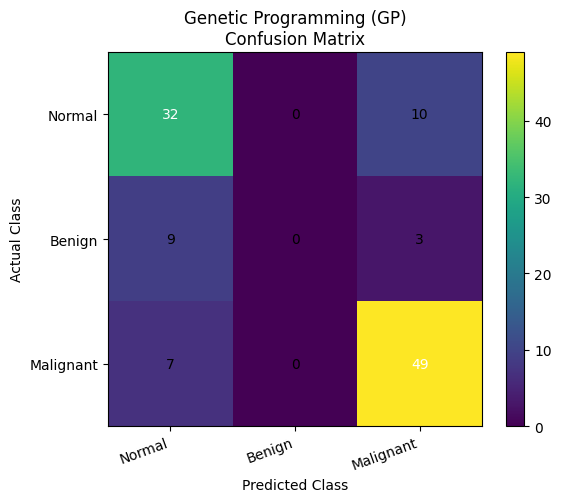


XGBOOST

Confusion Matrix:


,Predicted Normal,Predicted Benign,Predicted Malignant
Actual Normal,35,0,7
Actual Benign,6,4,2
Actual Malignant,3,0,53



Classification Report:
              precision    recall  f1-score   support

      Normal     0.7955    0.8333    0.8140        42
      Benign     1.0000    0.3333    0.5000        12
   Malignant     0.8548    0.9464    0.8983        56

    accuracy                         0.8364       110
   macro avg     0.8834    0.7044    0.7374       110
weighted avg     0.8480    0.8364    0.8226       110



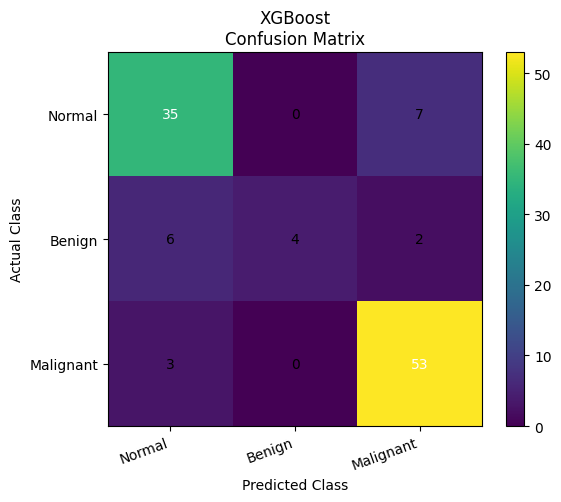


XGBOOST (FINE-TUNED)

Confusion Matrix:


,Predicted Normal,Predicted Benign,Predicted Malignant
Actual Normal,35,1,6
Actual Benign,6,5,1
Actual Malignant,2,0,54



Classification Report:
              precision    recall  f1-score   support

      Normal     0.8140    0.8333    0.8235        42
      Benign     0.8333    0.4167    0.5556        12
   Malignant     0.8852    0.9643    0.9231        56

    accuracy                         0.8545       110
   macro avg     0.8442    0.7381    0.7674       110
weighted avg     0.8524    0.8545    0.8450       110



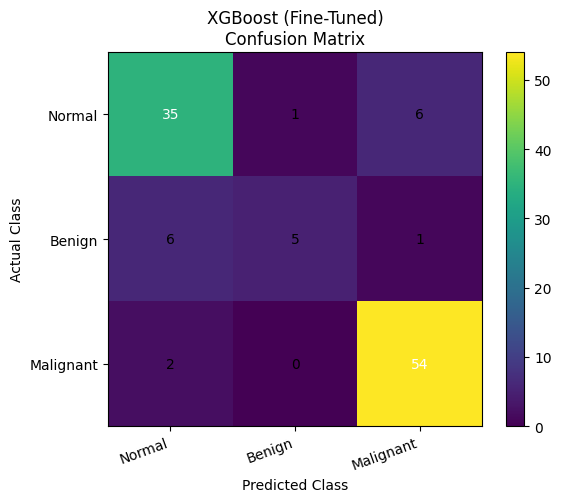


HYBRID CLASSIFIER (BASELINE)

Confusion Matrix:


,Predicted Normal,Predicted Benign,Predicted Malignant
Actual Normal,34,4,4
Actual Benign,3,9,0
Actual Malignant,2,1,53



Classification Report:
              precision    recall  f1-score   support

      Normal     0.8718    0.8095    0.8395        42
      Benign     0.6429    0.7500    0.6923        12
   Malignant     0.9298    0.9464    0.9381        56

    accuracy                         0.8727       110
   macro avg     0.8148    0.8353    0.8233       110
weighted avg     0.8764    0.8727    0.8736       110



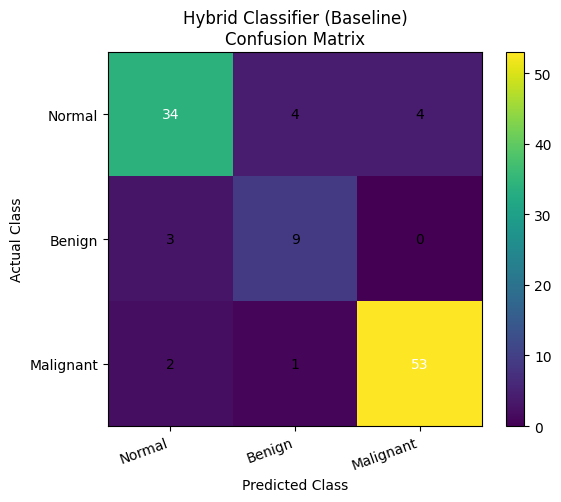


HYBRID CLASSIFIER (FINE-TUNED)

Confusion Matrix:


,Predicted Normal,Predicted Benign,Predicted Malignant
Actual Normal,39,0,3
Actual Benign,1,10,1
Actual Malignant,0,0,56



Classification Report:
              precision    recall  f1-score   support

      Normal     0.9750    0.9286    0.9512        42
      Benign     1.0000    0.8333    0.9091        12
   Malignant     0.9333    1.0000    0.9655        56

    accuracy                         0.9545       110
   macro avg     0.9694    0.9206    0.9419       110
weighted avg     0.9565    0.9545    0.9539       110



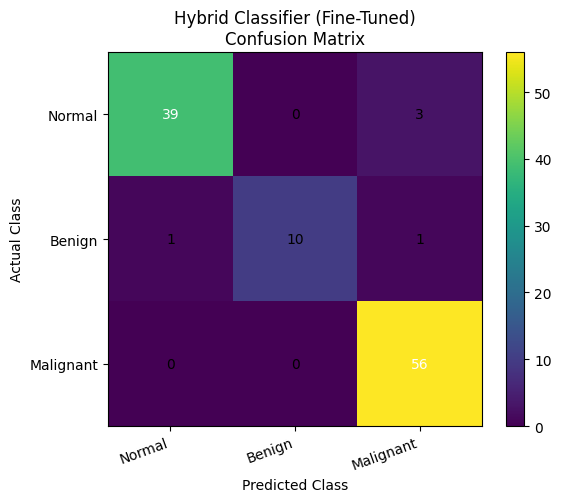


HYBRID CLASSIFIER (FINAL TUNED)

Confusion Matrix:


,Predicted Normal,Predicted Benign,Predicted Malignant
Actual Normal,37,0,5
Actual Benign,1,11,0
Actual Malignant,0,1,55



Classification Report:
              precision    recall  f1-score   support

      Normal     0.9737    0.8810    0.9250        42
      Benign     0.9167    0.9167    0.9167        12
   Malignant     0.9167    0.9821    0.9483        56

    accuracy                         0.9364       110
   macro avg     0.9357    0.9266    0.9300       110
weighted avg     0.9384    0.9364    0.9359       110



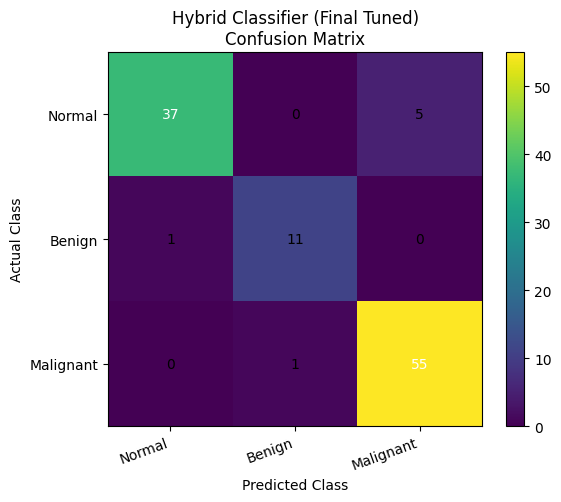


ALL AVAILABLE TEST MODEL RESULTS


,Model,Test Samples,Accuracy (%),Balanced Accuracy (%),Macro Precision (%),Macro Recall (%),Macro F1 (%),Weighted F1 (%)
0,Genetic Programming (GP),110,73.64,54.56,48.57,54.56,51.39,69.43
1,XGBoost,110,83.64,70.44,88.34,70.44,73.74,82.26
2,XGBoost (Fine-Tuned),110,85.45,73.81,84.42,73.81,76.74,84.50
3,Hybrid Classifier (Baseline),110,87.27,83.53,81.48,83.53,82.33,87.36
4,Hybrid Classifier (Fine-Tuned),110,95.45,92.06,96.94,92.06,94.19,95.39
5,Hybrid Classifier (Final Tuned),110,93.64,92.66,93.57,92.66,93.00,93.59



Saved results folder: /content/lung_ct_validation_results
Contains individual confusion-matrix PNG/CSV files,
all-model metrics, and a combined confusion-matrix CSV.

ConvNeXt-Tiny note:
Your notebook uses ConvNeXt-Tiny as a deep feature extractor. Its features feed the hybrid classifier, so the hybrid confusion matrix evaluates the final hybrid predictions—not a standalone ConvNeXt-Tiny classifier.


In [ ]:

# ============================================================
# FINAL VALIDATION: ALL AVAILABLE MODEL CONFUSION MATRICES
# GP | XGBoost | Hybrid Baseline | Fine-Tuned | Final Hybrid
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
from IPython.display import display

CLASS_NAMES = ["Normal", "Benign", "Malignant"]
CLASS_IDS = [0, 1, 2]

# ------------------------------------------------------------
# 1. STORE AVAILABLE TEST PREDICTIONS
# ------------------------------------------------------------

models_to_evaluate = {}

def register_test_model(name, y_true, y_pred):
    if y_true is None or y_pred is None:
        return

    actual = np.asarray(y_true).reshape(-1)
    predicted = np.asarray(y_pred).reshape(-1)

    if len(actual) != len(predicted):
        print(f"SKIPPED {name}: label/prediction count mismatch.")
        return

    if len(actual) == 0:
        print(f"SKIPPED {name}: no test samples.")
        return

    if not np.isin(actual, CLASS_IDS).all():
        print(f"SKIPPED {name}: unexpected actual label encoding.")
        return

    if not np.isin(predicted, CLASS_IDS).all():
        print(f"SKIPPED {name}: unexpected prediction label encoding.")
        return

    models_to_evaluate[name] = (actual, predicted)


# GP
if "gp_test_pred" in globals() and "y_test" in globals():
    register_test_model(
        "Genetic Programming (GP)",
        y_test,
        gp_test_pred
    )

# Original XGBoost
if "xgb_test_pred" in globals() and "y_test" in globals():
    register_test_model(
        "XGBoost",
        y_test,
        xgb_test_pred
    )

# Fine-tuned XGBoost
if "xgb_best_test_pred" in globals() and "y_test" in globals():
    register_test_model(
        "XGBoost (Fine-Tuned)",
        y_test,
        xgb_best_test_pred
    )

# Baseline hybrid classifier
if "y_test_actual" in globals() and "y_test_pred" in globals():
    register_test_model(
        "Hybrid Classifier (Baseline)",
        y_test_actual,
        y_test_pred
    )

# Fine-tuned hybrid classifier
if "y_test_ft" in globals() and "y_pred_ft" in globals():
    register_test_model(
        "Hybrid Classifier (Fine-Tuned)",
        y_test_ft,
        y_pred_ft
    )

# Final tuned hybrid classifier
if "y_test_final" in globals() and "y_pred_final" in globals():
    register_test_model(
        "Hybrid Classifier (Final Tuned)",
        y_test_final,
        y_pred_final
    )

# Original and candidate models, if the earlier HITL evaluation ran
if (
    "original_results" in globals()
    and "y_test_array" in globals()
):
    register_test_model(
        "Hybrid Classifier (Original)",
        y_test_array,
        original_results["predictions"]
    )

if (
    "candidate_results" in globals()
    and "y_test_array" in globals()
):
    register_test_model(
        "Hybrid Classifier (Candidate)",
        y_test_array,
        candidate_results["predictions"]
    )

if not models_to_evaluate:
    raise RuntimeError(
        "No evaluated test predictions found. Run the model "
        "training and evaluation cells first."
    )

# ------------------------------------------------------------
# 2. CREATE OUTPUT FOLDER
# ------------------------------------------------------------

RESULTS_DIR = "/content/lung_ct_validation_results"
os.makedirs(RESULTS_DIR, exist_ok=True)

metrics_rows = []
confusion_matrices = {}

# ------------------------------------------------------------
# 3. GENERATE EVERY AVAILABLE CONFUSION MATRIX + REPORT
# ------------------------------------------------------------

for model_name, (actual, predicted) in models_to_evaluate.items():

    cm = confusion_matrix(
        actual,
        predicted,
        labels=CLASS_IDS
    )
    confusion_matrices[model_name] = cm

    print("\n" + "=" * 75)
    print(model_name.upper())
    print("=" * 75)

    cm_df = pd.DataFrame(
        cm,
        index=[f"Actual {c}" for c in CLASS_NAMES],
        columns=[f"Predicted {c}" for c in CLASS_NAMES]
    )

    print("\nConfusion Matrix:")
    display(cm_df)

    print("\nClassification Report:")
    print(
        classification_report(
            actual,
            predicted,
            labels=CLASS_IDS,
            target_names=CLASS_NAMES,
            zero_division=0,
            digits=4
        )
    )

    accuracy = accuracy_score(actual, predicted)
    balanced = balanced_accuracy_score(actual, predicted)
    macro_precision = precision_score(
        actual, predicted,
        labels=CLASS_IDS,
        average="macro",
        zero_division=0
    )
    macro_recall = recall_score(
        actual, predicted,
        labels=CLASS_IDS,
        average="macro",
        zero_division=0
    )
    macro_f1 = f1_score(
        actual, predicted,
        labels=CLASS_IDS,
        average="macro",
        zero_division=0
    )
    weighted_f1 = f1_score(
        actual, predicted,
        labels=CLASS_IDS,
        average="weighted",
        zero_division=0
    )

    metrics_rows.append({
        "Model": model_name,
        "Test Samples": len(actual),
        "Accuracy (%)": accuracy * 100,
        "Balanced Accuracy (%)": balanced * 100,
        "Macro Precision (%)": macro_precision * 100,
        "Macro Recall (%)": macro_recall * 100,
        "Macro F1 (%)": macro_f1 * 100,
        "Weighted F1 (%)": weighted_f1 * 100
    })

    # Save each matrix
    safe_name = (
        model_name.lower()
        .replace(" ", "_")
        .replace("(", "")
        .replace(")", "")
        .replace("-", "_")
    )

    cm_df.to_csv(
        os.path.join(RESULTS_DIR, f"{safe_name}_confusion_matrix.csv")
    )

    # Plot each matrix
    fig, ax = plt.subplots(figsize=(6, 5))
    image = ax.imshow(cm, interpolation="nearest")
    ax.set_title(f"{model_name}\nConfusion Matrix")
    fig.colorbar(image, ax=ax)

    ax.set(
        xticks=np.arange(3),
        yticks=np.arange(3),
        xticklabels=CLASS_NAMES,
        yticklabels=CLASS_NAMES,
        xlabel="Predicted Class",
        ylabel="Actual Class"
    )

    plt.setp(ax.get_xticklabels(), rotation=20, ha="right")

    threshold = cm.max() / 2 if cm.max() > 0 else 0
    for row in range(3):
        for col in range(3):
            ax.text(
                col, row, str(cm[row, col]),
                ha="center", va="center",
                color="white" if cm[row, col] > threshold else "black"
            )

    fig.tight_layout()
    fig.savefig(
        os.path.join(RESULTS_DIR, f"{safe_name}_confusion_matrix.png"),
        dpi=200,
        bbox_inches="tight"
    )
    plt.show()
    plt.close(fig)

# ------------------------------------------------------------
# 4. COMBINED METRICS COMPARISON
# ------------------------------------------------------------

metrics_df = pd.DataFrame(metrics_rows)

print("\n" + "=" * 100)
print("ALL AVAILABLE TEST MODEL RESULTS")
print("=" * 100)

display(
    metrics_df.style.format({
        col: "{:.2f}"
        for col in metrics_df.columns
        if col.endswith("(%)")
    })
)

metrics_df.to_csv(
    os.path.join(RESULTS_DIR, "all_model_metrics.csv"),
    index=False
)

metrics_df.to_json(
    os.path.join(RESULTS_DIR, "all_model_metrics.json"),
    orient="records",
    indent=2
)

# ------------------------------------------------------------
# 5. SAVE CONFUSION MATRICES TO ONE SUMMARY CSV
# ------------------------------------------------------------

matrix_rows = []

for model_name, cm in confusion_matrices.items():
    for i, actual_class in enumerate(CLASS_NAMES):
        for j, predicted_class in enumerate(CLASS_NAMES):
            matrix_rows.append({
                "Model": model_name,
                "Actual Class": actual_class,
                "Predicted Class": predicted_class,
                "Count": int(cm[i, j])
            })

pd.DataFrame(matrix_rows).to_csv(
    os.path.join(RESULTS_DIR, "all_confusion_matrices_long.csv"),
    index=False
)

print("\nSaved results folder:", RESULTS_DIR)
print("Contains individual confusion-matrix PNG/CSV files,")
print("all-model metrics, and a combined confusion-matrix CSV.")

print("\nConvNeXt-Tiny note:")
print(
    "Your notebook uses ConvNeXt-Tiny as a deep feature extractor. "
    "Its features feed the hybrid classifier, so the hybrid confusion "
    "matrix evaluates the final hybrid predictions—not a standalone "
    "ConvNeXt-Tiny classifier."
)
